# From Forecasts to Decisions: Cannibalization and Shared Capacity

This notebook is a continuation of the first post ["From Forecasts to Decisions: Inventory Planning with Probabilistic Programming"](https://juanitorduz.github.io/forecast_to_decision/). In that first post we worked out a simple inventory planning problem with a single product in a single store, that is, just one independent time series. We treated this problem beyond a simple forecasting problem. We worked out the decision problem and the loss function to effectively optimize for revenue by weighting the holding cost of leftover units and the lost margin of unmet demand. 

In this notebook we extend the problem to multiple related products in multiple stores, and we add a new constraint: the capacity of the stores. Let's describe the business setting in more detail. Suppose that a retail chain sells $20$ products in $10$ stores, which gives $200$ store-product series. We are interested in solving the same problem as in the first post: planning the orders of the products for the next $15$ days. To work out a problem close to realily, we further add the following assumptions:

- **Cannibalization.** The products are related by substitution groups. The products in a group are close substitutes for each other, and they compete for the same customers. The loss of demand of the substitutes is called **cannibalization**.

- **Capacity.** Every store can receive a limited number of units per day, its capacity. The stores differ in size, so each store has its own capacity, and the orders of its products compete for it.

- **Promotion.** The chain plans a promotion week in which three products get a $30\%$ price cut. 

In the [first post](https://juanitorduz.github.io/forecast_to_decision/) we planned the orders of one product. We turned the posterior predictive draws of a demand model into demand scenarios, ran an inventory simulator on them, and minimized a loss with two prices: a holding cost per unit left over and a lost margin per unit short. We saw that a plan built on a point forecast is the most expensive one on every metric, and that plans built on the same scenarios under different decision rules differ by tens of percent in cost. Here we apply the same steps to many series that share a promotion calendar and, within a store, a capacity. Moreover, we want to answer the following additional questions:

1. How much more does a plan cost when its forecast ignores cannibalization?
2. Which products and which days are behind that extra cost?
3. Does the shared capacity change the answer?

To answer them we fit two forecasting models to the same data. The **independent model** has no link between the products of a group. The **cross model** adds a cross-price term that moves demand between the products of a substitution group.

We build the same plans on the scenarios of each model and score them on draws from the true demand process, which we know because the data are synthetic. We keep the rest of the problem fixed, so that the forecasting model is the only difference between the plans that we compare.

- **The promotion is given.** The chain has already chosen the promoted products, the week and the discount. We do not optimize them here.

- **The same costs for every product.** Every product has the same holding cost per unit left over and the same lost margin per unit short.

- **No lead time.** An order for a day arrives at the start of that day.

- **One plan, no updates.** We fix the orders of all $15$ days today. We do not update the forecast and the plan as the days pass, which is what a **rolling horizon** would do.

- **Continuous orders.** An order can be any non-negative real number, as in the first post, so a plan can contain fractions of a unit. In the *Integer Orders* section we round the plans to whole units and check what the rounding costs.

The inventory setting with its shortage and holding costs follows the VN2 challenge described by [Szabłowski (2026)](https://arxiv.org/abs/2601.18919). We build the forecasting models with [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/).

We assume that you have read the first post. We do not derive the loss and the decision rules again, and we reuse the simulator and the solver with the few changes the new problem needs.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The loss over many series and the capacity constraint of every store.
3. **Generate Data.** The panel and the roles of the products, the promotion calendar, the demand model with cross-price effects, the priors elicited with PreliZ, the graph of every model component, one draw of the history and the realized future, and the evaluation scenarios.
4. **Forecasting Model.** The independent model and the cross model.
5. **Prior Predictive Checks.** Draws from the priors of the cross model against the data.
6. **Model Fitting.** SVI in the cosine basis of the random walk, with a full-rank guide on the price effects, and the fits of both models.
7. **Parameter Recovery.** The posterior against the true parameters and the true level of every series.
8. **Posterior Predictive Checks.** The fit on the history and the calibration of the forecast.
9. **Demand Scenarios.** The optimization scenarios of each model, the capacity of every store, and where the forecasts start.
10. **Capacity Projection.** The projection that keeps a plan within the capacities of the stores, with its code and its checks.
11. **Inventory Simulator.** The simulation over many series and the mean forecast plans.
12. **Decision Plans.** The expected cost plans of each model and what they order.
13. **Out of Sample Evaluation.** Scores on the evaluation scenarios, and the products and days behind the cost of ignoring cannibalization.
14. **Capacity Sensitivity.** The gap between the plans as the capacity tightens.
15. **Integer Orders.** The plans rounded to whole units.
16. **Conclusion.** What we learned.
17. **Next Steps.** Extensions.

## Prepare Notebook

In [1]:
import math
import warnings
from collections.abc import Callable
from enum import StrEnum
from functools import partial
from typing import NamedTuple

import arviz as az
import graphviz as gr
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import seaborn as sns
import xarray as xr
from jax import random
from jaxtyping import Array, Bool, Float, Int, PRNGKeyArray, ScalarLike, Shaped
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from numpyro import handlers
from numpyro.handlers import do
from numpyro.infer import SVI, Predictive, Trace_ELBO
from numpyro.infer.autoguide import AutoGuideList, AutoMultivariateNormal, AutoNormal
from numpyro.infer.initialization import init_to_median
from numpyro.infer.reparam import LocScaleReparam
from numpyro.infer.svi import SVIRunResult
from numpyro_forecast import (
    Horizon,
    draw_posterior,
    forecast,
    innovations,
    predict,
    predict_in_sample,
    time_reparam,
)
from numpyro_forecast.evaluate import eval_coverage
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import ForecastModel

# PreliZ warns that PyMC is not installed, which we do not need here
warnings.filterwarnings("ignore", category=UserWarning, module="preliz")

seed: int = 42
rng_key: PRNGKeyArray = random.PRNGKey(seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
pl.Config(float_precision=3, tbl_rows=20, tbl_width_chars=160, fmt_str_lengths=80)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

First, we write the loss over many series and the capacities of the stores, which link the series of a store.

We index the stores by $s = 1, \dots, S$ and the products by $j = 1, \dots, P$. Every product belongs to one **substitution group** $g(j)$ of $K$ products, and there are $G$ groups.

A **series** is a store and product pair $i = (s, j)$, and there are $M = S P$ of them. Let $H$ be the **number of days in the planning horizon** and let $D_{t,i}$ be the **demand of series** $i$ **on day** $t$.

Recall from the first post that at the start of a day we receive the units ordered in advance, that customers buy what is there and go elsewhere for the rest, and that a leftover unit stays on the shelf. Let $a_{t,i} \geq 0$ be the **order** of series $i$ on day $t$, $I_{t,i}$ the **stock on hand** at the end of the day, and $U_{t,i}$ the **lost sales**, the unmet demand of the day.

These quantities follow the same dynamics as before, series by series. The whole plan is the array $a = (a_{t,i})$ of $H \times M$ orders.

Two unit costs define the loss. Let $h$ be the **holding cost** of one unit that sits on the shelf at the end of a day, and let $p$ be the **lost margin** of one unit of demand that we cannot serve. The **loss** of the plan $a$ against the demand paths $D = (D_{t,i})$ adds up over the series:

$$
L(a, D) = \sum_{t=1}^{H} \sum_{i=1}^{M} \left[ h \, I_{t,i} + p \, U_{t,i} \right].
$$

Note that the loss is additive over the series. Without a constraint between the series (like the capacity), the plan that minimizes the expected loss would split into $M$ copies of the single-series problem, and the only thing a joint forecast would change is the scenarios of each series.

We store the costs of the loss in the `InventoryConfig` tuple.

In [2]:
class InventoryConfig(NamedTuple):
    """Costs of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float


config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0)

### Capacity Constraint

The constraint between the series comes from the **capacity**. Let $C_s > 0$ be the number of units that store $s$ can receive per day over all its products. The stores are not all the same, so the capacity is a vector $C = (C_1, \dots, C_S)$ with one entry per store.

On every day the orders of a store have to fit within its capacity,

$$
\sum_{j=1}^{P} a_{t,(s,j)} \leq C_s \quad \text{for every day } t \text{ and store } s.
$$

A plan is **feasible** when its orders are non-negative and fit the capacity of every store on every day. As in the first post, we find the plans with a gradient-based solver, and a gradient step does not know about these two conditions. So after every step we repair the plan with a **projection**: we replace the proposed plan by the feasible plan closest to it.

In the first post this repair was the clip at zero, and here it also has to respect the capacities. We use the same projection to build the mean forecast plans. We leave the details for the *Capacity Projection* section, right before we build the plans.

## Generate Data

We generate the data from a known demand process, so that we can score the plans against the truth.

### Panel and Calendar

The panel has the following structure:

- **Products.** There are $P = 20$ products in $G = 5$ substitution groups of $K = 4$ products. We call two products of the same group **siblings**.
- **Stores.** There are $S = 10$ stores, which gives $M = S P = 200$ series.
- **Time.** The history is one year ($364$ days) of daily demand, and the horizon is $15$ days.
- **Cannibalization.** The groups differ in how strong it is. The true cross elasticity, which we define in the *Demand Model* section, is
  - $0.6$ in group $1$, a strong cannibalization,
  - $0.3$ in groups $2$ and $4$, a moderate one,
  - zero in groups $3$ and $5$, which have none.

The promotion calendar is chain-wide. A product is on promotion in all stores at once, at a $30\%$ discount, for a whole calendar week.

- **History.** In every week a product is on promotion with probability $0.1$, independently of the other products.
- **Horizon.** The chain plans one promotion, in the second week of the horizon (days $8$ to $14$), for the first product of groups $1$, $2$ and $3$.

To read the results we give every product a **role**. The role says what happens to the product and to its group in the horizon:

- `promoted`: the three products on promotion in the horizon, that is, products $0$, $4$ and $8$.
- `sibling`: the other nine products of groups $1$, $2$ and $3$.
  - A sibling of each of them is on promotion in the horizon.
  - In groups $1$ and $2$ their demand dips in the promotion week. In group $3$ it does not, because the group has no cannibalization.
- `control (cross)`: the four products of group $4$.
  - No product of the group is on promotion in the horizon.
  - The group has cannibalization, so the sibling promotions of the history moved its demand.
- `control (no cross)`: the four products of group $5$, with no promotion in the horizon and no cannibalization.

Each role answers its own question:

- `promoted` and `sibling`: what does the planned promotion do to the promoted product and to its substitutes, and does each model see it?
- `control (cross)`: what do the sibling promotions of the history alone do to a model that cannot explain them?
- `control (no cross)`: nothing in its demand depends on cannibalization, so the two models should forecast it the same way. Its orders can still differ between the two plans, because it shares the capacity of the store with the other groups.

Group $3$ is the check inside the promoted groups. It has a promoted product and three siblings but no cannibalization, so the cross model must learn not to move demand there. Its products count as `promoted` and `sibling`, so we also split the results by group.

In the code, the `Setup` tuple holds the sizes of the panel and the true cross elasticity of every group. The number of groups is the length of `group_cross`. The `Promotion` tuple holds the design of the calendar, and the `Panel` tuple the index arrays of the panel:

- The series are store-major, that is, series $i = s P + j$ with the store and the product indexed from zero.
- The `pair_rows` and `pair_cols` arrays list the within-group pairs of distinct products, the pairs of siblings.

Each role is a mask over the products, built from three simple questions about a product: is it in a promoted group, is it the first product of its group, and does its group have cannibalization?

In the code and in the figures the products are numbered from zero, and the groups and the stores from one.

In [3]:
class Setup(NamedTuple):
    """Sizes of the panel and the true cross elasticity of every group."""

    group_cross: tuple[float, ...] = (0.6, 0.3, 0.0, 0.3, 0.0)
    n_per_group: int = 4  # products per group
    n_stores: int = 10
    t_obs: int = 364  # days of history
    horizon: int = 15  # days to plan

    @property
    def n_groups(self) -> int:
        return len(self.group_cross)

    @property
    def n_products(self) -> int:
        return self.n_groups * self.n_per_group

    @property
    def n_series(self) -> int:
        return self.n_stores * self.n_products

    @property
    def duration(self) -> int:
        return self.t_obs + self.horizon


class Promotion(NamedTuple):
    """Design of the promotion calendar."""

    discount: float = 0.3  # price cut in a promotion week
    weekly_prob: float = 0.1  # chance that a product is on promotion in a past week
    n_promoted_groups: int = 3  # the first product of these groups is promoted
    start: int = 7  # first day of the planned promotion, counted from zero
    end: int = 14  # the day after the last day of the planned promotion


class Panel(NamedTuple):
    """Index arrays of the panel. Series are store-major: series = store * P + j."""

    series_to_product: Int[Array, " n_series"]
    series_to_store: Int[Array, " n_series"]
    product_to_group: Int[Array, " n_products"]
    pair_rows: Int[Array, " n_pairs"]
    pair_cols: Int[Array, " n_pairs"]


def sibling_matrix(
    product_to_group: Int[Array, " n_products"],
) -> Bool[Array, "n_products n_products"]:
    """Entry (k, j) is true when products k and j are distinct and in the same group."""
    same_group = product_to_group[:, None] == product_to_group[None, :]
    return same_group & ~jnp.eye(product_to_group.size, dtype=bool)


def make_panel(setup: Setup) -> Panel:
    """Build the index arrays and the pairs of siblings."""
    product_to_group = jnp.repeat(jnp.arange(setup.n_groups), setup.n_per_group)
    pair_rows, pair_cols = jnp.nonzero(sibling_matrix(product_to_group))
    return Panel(
        series_to_product=jnp.tile(jnp.arange(setup.n_products), setup.n_stores),
        series_to_store=jnp.repeat(jnp.arange(setup.n_stores), setup.n_products),
        product_to_group=product_to_group,
        pair_rows=pair_rows,
        pair_cols=pair_cols,
    )


class Role(StrEnum):
    """Role of a product in the horizon."""

    PROMOTED = "promoted"
    SIBLING = "sibling"
    CONTROL_CROSS = "control (cross)"
    CONTROL_NO_CROSS = "control (no cross)"


def in_promoted_group(panel: Panel, promotion: Promotion) -> Bool[Array, " n_products"]:
    """Products of the groups with a promotion in the horizon."""
    return panel.product_to_group < promotion.n_promoted_groups


def is_first_of_group(setup: Setup) -> Bool[Array, " n_products"]:
    """The first product of every group."""
    return jnp.arange(setup.n_products) % setup.n_per_group == 0


def has_cannibalization(setup: Setup, panel: Panel) -> Bool[Array, " n_products"]:
    """Products of the groups with a positive true cross elasticity."""
    return jnp.asarray(setup.group_cross)[panel.product_to_group] > 0


def role_masks(
    setup: Setup, panel: Panel, promotion: Promotion
) -> dict[Role, Bool[Array, " n_products"]]:
    """One mask over the products per role."""
    promoted_group = in_promoted_group(panel, promotion)
    first = is_first_of_group(setup)
    cross = has_cannibalization(setup, panel)
    return {
        Role.PROMOTED: promoted_group & first,
        Role.SIBLING: promoted_group & ~first,
        Role.CONTROL_CROSS: ~promoted_group & cross,
        Role.CONTROL_NO_CROSS: ~promoted_group & ~cross,
    }


setup = Setup()
promotion = Promotion()
panel = make_panel(setup)
assert (setup.n_products, setup.n_series, panel.pair_rows.size) == (20, 200, 60)

role_mask = role_masks(setup, panel, promotion)
# every product has exactly one role
assert bool((sum(mask.astype(int) for mask in role_mask.values()) == 1).all())
product_role = [
    next(role for role, mask in role_mask.items() if mask[product])
    for product in range(setup.n_products)
]
promoted_products = jnp.flatnonzero(role_mask[Role.PROMOTED])

days = jnp.arange(setup.duration)
days_future = days[setup.t_obs :]
# three harmonics of the weekly cycle
fourier = fourier_features(setup.duration, period=7.0, num_terms=3)
# the planned promotion of the horizon
promo_future = (
    jnp.zeros((setup.horizon, setup.n_products))
    .at[promotion.start : promotion.end, promoted_products]
    .set(1.0)
)

products = pl.DataFrame(
    {
        "product": range(setup.n_products),
        "group": (panel.product_to_group + 1).tolist(),
        "role": [role.value for role in product_role],
    }
)
products.head()

product,group,role
i64,i64,str
0,1,"""promoted"""
1,1,"""sibling"""
2,1,"""sibling"""
3,1,"""sibling"""
4,2,"""promoted"""


The first five products are group $1$ and the first product of group $2$. The number of products of each role:

In [4]:
products.group_by("role").len().sort("role")

role,len
str,u32
"""control (cross)""",4
"""control (no cross)""",4
"""promoted""",3
"""sibling""",9


The four roles cover the $20$ products.

Besides the true parameters and the demand, the calendar is the only random input. We draw it from a small generative model, one Bernoulli per product and week, and append the planned horizon. The deterministic `log_price` site is the log of the price relative to the list price, $\log(1 - 0.3)$ in a promotion week and zero otherwise.

In [5]:
def calendar_generator(
    setup: Setup, promotion: Promotion, promo_future: Float[Array, "horizon n_products"]
) -> None:
    """Chain-wide promotion weeks of the history, followed by the planned horizon."""
    with (
        numpyro.plate("product", setup.n_products, dim=-1),
        numpyro.plate("week", setup.t_obs // 7, dim=-2),
    ):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(promotion.weekly_prob))

    promo_history = jnp.repeat(promo_week, 7, axis=0)
    promo = jnp.concatenate([promo_history, promo_future], axis=0)
    numpyro.deterministic("promo", promo)
    numpyro.deterministic("log_price", promo * jnp.log(1.0 - promotion.discount))


rng_key, key_calendar = random.split(rng_key)
calendar = Predictive(calendar_generator, num_samples=1)(
    key_calendar, setup, promotion, promo_future
)
log_price = calendar["log_price"][0]  # (duration, n_products)
promo_week_true = calendar["promo_week"][0]  # (n_weeks, n_products)
promo_full = calendar["promo"][0]  # (duration, n_products)

# one array of covariates: the Fourier columns, then one log price column per product
covariates = jnp.concatenate([fourier, log_price], axis=1)
covariates_train = covariates[: setup.t_obs]
assert covariates.shape == (setup.duration, fourier.shape[1] + setup.n_products)

The following figure shows the calendar as a heatmap, one row per product and one column per day, next to the number of promotion weeks of every product and of its siblings. The helper `sibling_on_promotion` marks, for every product and every week (or day), whether at least one of its siblings is on promotion.

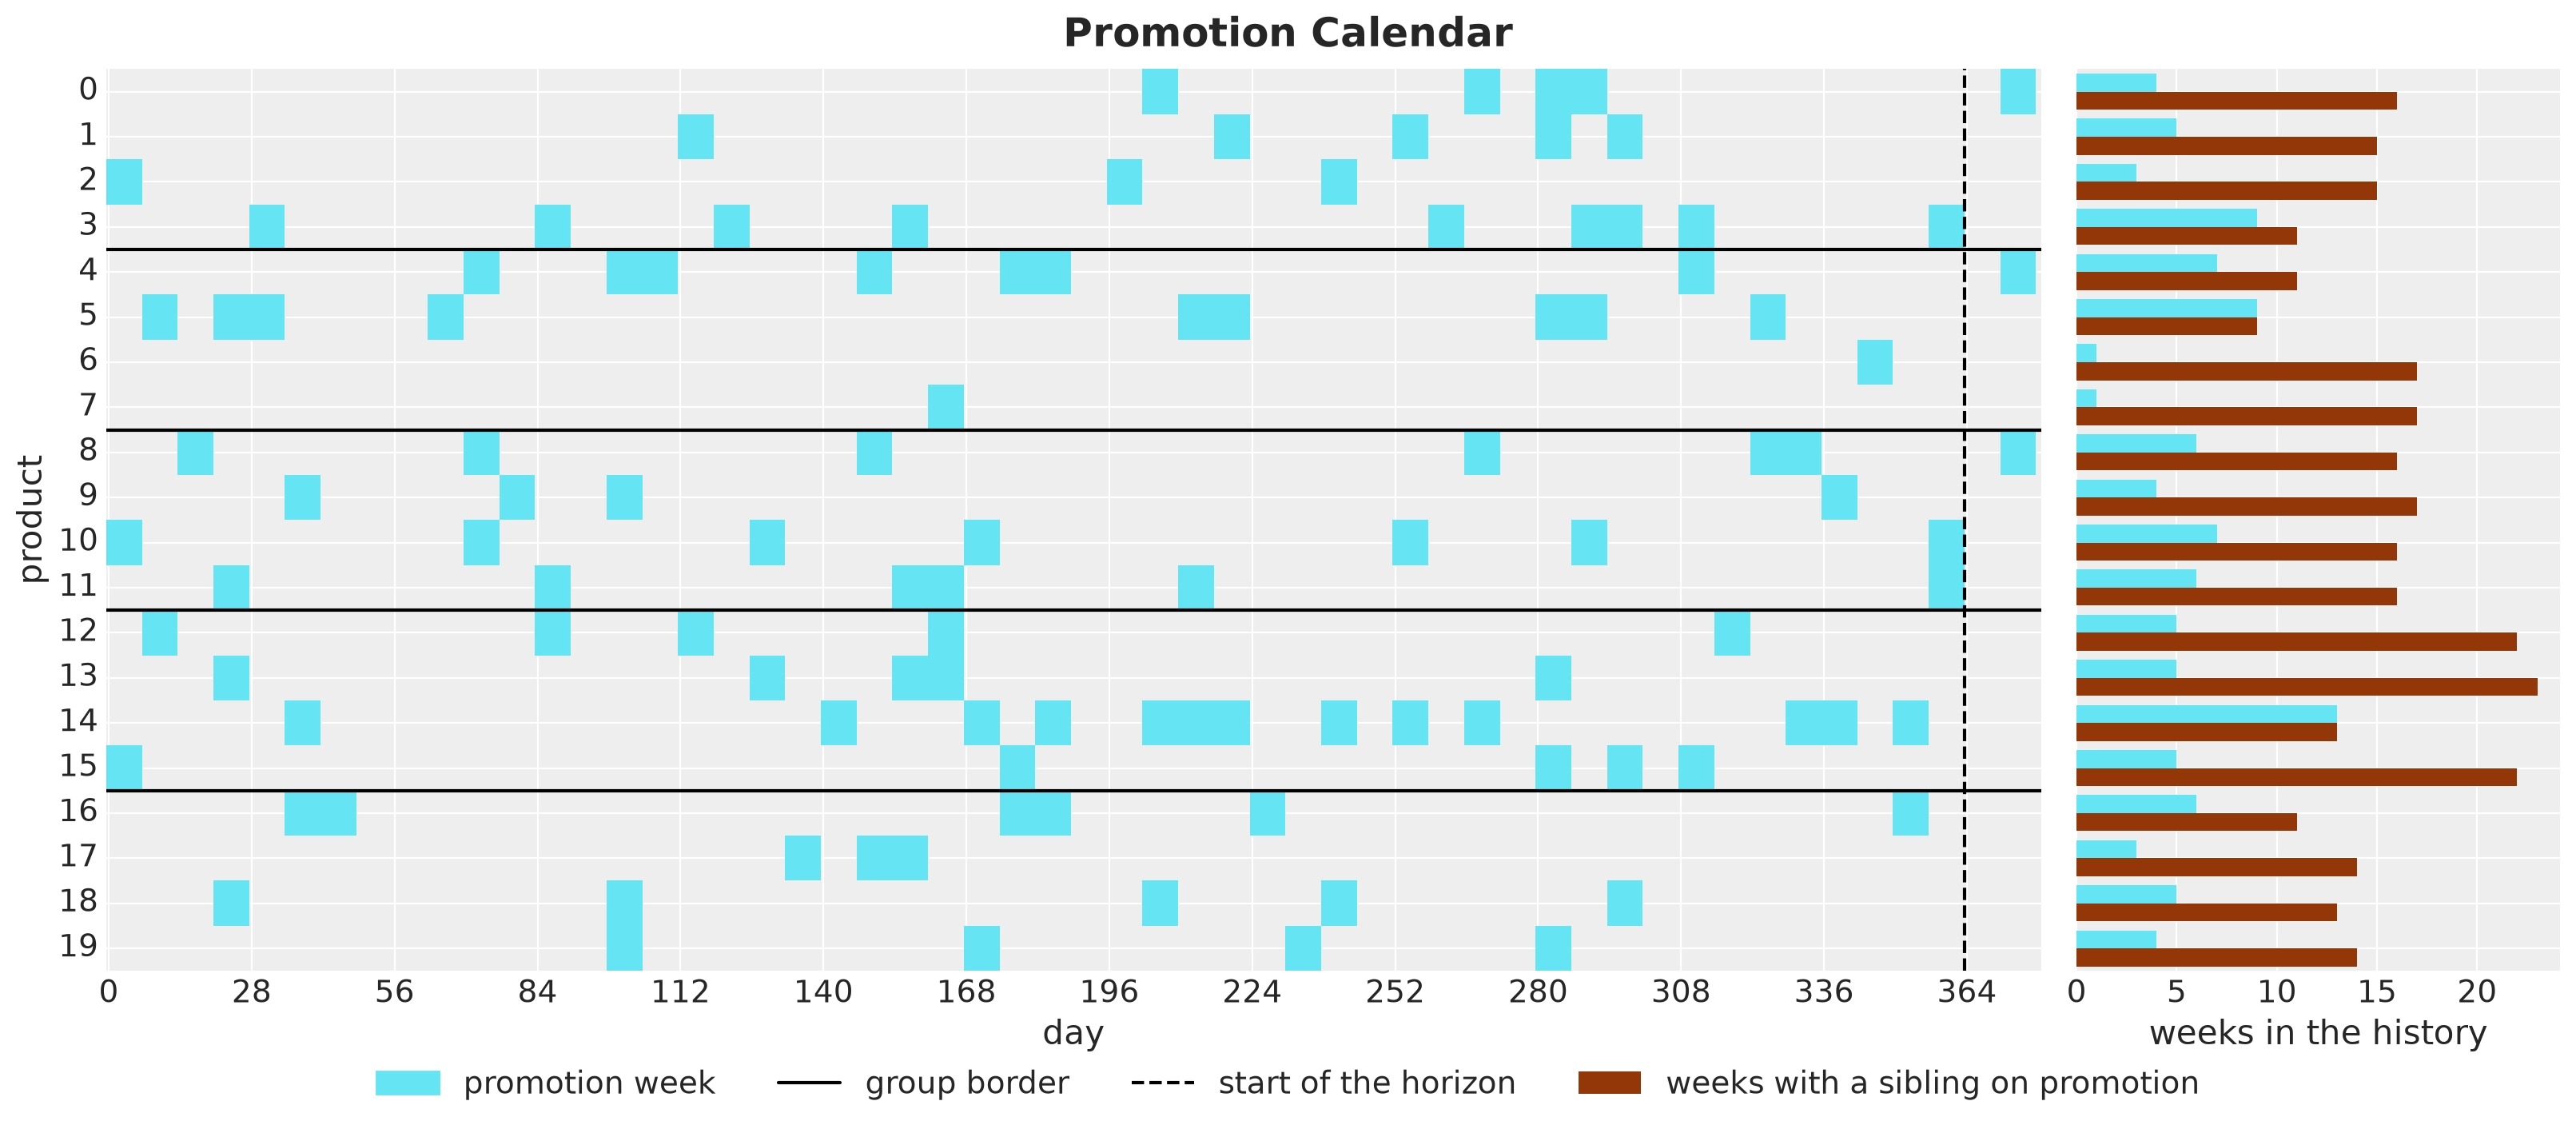

In [6]:
is_sibling = sibling_matrix(panel.product_to_group)


def sibling_on_promotion(
    promo: Shaped[Array, "time n_products"],
) -> Bool[Array, "time n_products"]:
    """Entry (t, j) is true when at least one sibling of product j is on promotion."""
    return (promo @ is_sibling.astype(promo.dtype)) > 0


own_promo_weeks = promo_week_true.sum(axis=0)
sibling_promo_weeks = sibling_on_promotion(promo_week_true).sum(axis=0)

fig, axes = plt.subplots(
    ncols=2, figsize=(16, 7), sharey=True, width_ratios=[4, 1], layout="constrained"
)
ax = axes[0]
# seaborn does not draw NaN cells, so the days without a promotion show the gray
# background of the axes
sns.heatmap(
    jnp.where(promo_full.T > 0, 1.0, jnp.nan),
    cmap=["C5"],
    cbar=False,
    xticklabels=28,
    yticklabels=1,
    ax=ax,
)
ax.tick_params(axis="y", rotation=0)

for group in range(1, setup.n_groups):
    ax.axhline(
        group * setup.n_per_group,
        color="black",
        label="group border" if group == 1 else None,
    )

ax.axvline(setup.t_obs, color="black", linestyle="--", label="start of the horizon")
ax.set(xlabel="day", ylabel="product")
ax = axes[1]
# the rows of the heatmap are centered at product + 0.5
product_rows = jnp.arange(setup.n_products) + 0.5
ax.barh(product_rows - 0.2, own_promo_weeks, height=0.4, color="C5")
ax.barh(
    product_rows + 0.2,
    sibling_promo_weeks,
    height=0.4,
    color="C4",
    label="weeks with a sibling on promotion",
)
ax.set(xlabel="weeks in the history")
# the heatmap has no legend entry of its own, so we add one for its colored cells
handles = [
    Patch(color="C5", label="promotion week"),
    *axes[0].get_legend_handles_labels()[0],
    *axes[1].get_legend_handles_labels()[0],
]
fig.legend(handles=handles, loc="outside lower center", ncol=4)
fig.suptitle("Promotion Calendar", fontsize=18, fontweight="bold");

The products have between $1$ and $13$ own promotion weeks in the history. Products $6$ and $7$ have a single one, so the data say little about the response of their siblings to their price. Every product sees a sibling on promotion in $9$ to $23$ of the $52$ weeks, and those weeks are where the data say how much a product loses to its siblings.

Three details of the last weeks of the history matter later.

- **Group $1$.** Product $3$ is on promotion in the last week, which is a sibling promotion week for products $0$, $1$ and $2$.
- **Group $3$.** Products $10$ and $11$ are on promotion in the same week. This group has no cannibalization.
- **Group $4$.** Product $14$ is on promotion in two of the last four weeks, which are sibling promotion weeks for the rest of the group.

### Demand Model

Let $\mu_{t,i}$ be the **expected demand** of series $i = (s, j)$ on day $t$. Let $\ell_{t,i}$ be its **latent level**, a random walk with **initial level** $\ell_{0,i}$ and **daily increments** $\delta_{t,i}$ whose scale $\sigma_i$ we call the **drift scale**.

Let $f_t$ be the **vector of Fourier features** of the weekly cycle and $\beta_j$ the **Fourier coefficients** of product $j$, shared by its stores. Let $x_{t,k} = \log r_{t,k} \leq 0$ be the **log relative price** of product $k$ on day $t$, where $r_{t,k}$ is the price relative to the list price. The log of the expected demand is

$$
\log \mu_{t,i} = \ell_{t,i} + f_t^\top \beta_j + \sum_{k \in g(j)} \gamma_{kj} \, x_{t,k},
\qquad
\ell_{t,i} = \ell_{0,i} + \sum_{u \leq t} \delta_{u,i},
\qquad
\delta_{u,i} \sim \text{Normal}(0, \sigma_i).
$$

The sum runs over the products $k$ of the group of $j$, including $j$ itself. The coefficient $\gamma_{kj}$ is the response of the demand of product $j$ to the price of product $k$, and the matrix $\Gamma = (\gamma_{kj})$ is the **elasticity matrix** of the group.

Its diagonal entry $\gamma_{jj}$ is the **own elasticity** of product $j$, the response of its demand to its own price. We expect it to be negative. An off-diagonal entry $\gamma_{kj}$ with $k \neq j$ is a **cross elasticity**.

A promotion of a sibling $k$ makes $x_{t,k}$ negative, so a positive $\gamma_{kj}$ lowers the demand of $j$. In other words, positive cross elasticities are cannibalization. Taking exponentials, a $30\%$ cut on product $k$ multiplies the demand of a sibling $j$ by $0.7^{\gamma_{kj}}$, so a cross elasticity of $0.6$ is a loss of $1 - 0.7^{0.6} \approx 19\%$.

How do we read a negative cross elasticity? It works the other way, so a promotion of $k$ raises the demand of $j$. This happens when the two products are **complements** rather than substitutes, or when the promotion brings customers to the shelf who also buy $j$, which is often called a **halo effect**. The prior of the next section allows both signs, and in our panel the true cross elasticities are zero or positive.

The likelihood is a negative binomial with a **concentration** $\phi_j$ per product:

$$
D_{t,i} \sim \text{NegativeBinomial}(\mu_{t,i}, \phi_j).
$$

### Prior Elicitation

Next, we elicit the priors of the global parameters. The model has six families of them. For four of them we state what we believe on the scale of the data and use [PreliZ](https://preliz.readthedocs.io/) to turn the statement into a distribution.

The function `pz.maxent` returns the member of a family that puts a given mass between two bounds (the one with maximum entropy, so it adds nothing beyond our constraints). Here is the reasoning for each of them.

- **`intercept`**: $\exp(\ell_{0,i})$ is the demand per day of series $i$ at the start of the history at the list price, with the weekly pattern averaged out on the log scale (the Fourier terms sum to zero over a week). We believe it lies between $10$ and $300$ units for every series of the chain, a wide range for products that sell tens of units per day. So we ask for a Normal on $\ell_{0,i}$ with $94\%$ of its mass between $\log 10$ and $\log 300$.

- **`drift_scale`**: the level of a series is a random walk, so after $T$ days the standard deviation of the log level is $\sigma_i \sqrt{T}$, and $\exp(\sigma_i \sqrt{T})$ is the typical factor by which the level has moved. Over the $364$ days of history we believe that factor lies between $1.04$ and $2$, that is, from a $4\%$ move to a doubling. So we ask for a LogNormal on $\sigma_i$ with $94\%$ of its mass between $\log(1.04) / \sqrt{T}$ and $\log(2) / \sqrt{T}$.

- **`concentration`**: the negative binomial adds $\mu_{t,i}^2 / \phi_j$ to the Poisson variance, so the extra day-to-day noise is a fraction $1 / \sqrt{\phi_j}$ of the level. We believe that fraction lies between $0.1$ and $0.5$, which is $\phi_j$ between $4$ and $100$. So we ask for a Gamma with $94\%$ of its mass in that range.

- **`cross_scale`**: the cross elasticities share the prior $\gamma_{kj} \sim \text{Normal}(0, \sigma_\gamma)$ for $k \neq j$, centered at zero and shrunk by the common scale $\sigma_\gamma$, so the data can also say that a group has no cannibalization. Consider a sibling whose cross elasticity is one prior standard deviation, $\gamma_{kj} = \sigma_\gamma$. Under a $30\%$ cut on product $k$, this sibling loses a share $1 - 0.7^{\sigma_\gamma}$ of its demand. We believe that this typical loss lies below $15\%$, which is a cross elasticity of $\log(0.85) / \log(0.7) \approx 0.46$. So we ask for a HalfNormal on $\sigma_\gamma$ with $94\%$ of its mass between $0$ and $0.46$.

The other two priors we state directly.

- **`beta`**: each Fourier coefficient gets a $\text{Normal}(0, 0.3)$, so two standard deviations multiply the demand by $e^{\pm 0.6}$, between $0.55$ and $1.8$.

- **`elasticity`**: the own elasticity of every product gets a $\text{Normal}(-1, 1)$. A higher price should lower the demand, so we center the prior on a negative value, and the standard deviation of $1$ leaves a positive value possible if the data ask for it.

We run the four elicitations and store the results in the `Priors` tuple that the model functions of the next section read.

In [7]:
class Priors(NamedTuple):
    """Prior hyperparameters of the demand model."""

    intercept_mu: float
    intercept_sigma: float
    drift_mu: float
    drift_sigma: float
    concentration_alpha: float
    concentration_beta: float
    cross_scale_sigma: float
    seasonal_sigma: float = 0.3
    elasticity_mu: float = -1.0
    elasticity_sigma: float = 1.0


intercept_bounds = (math.log(10), math.log(300))
drift_bounds = (
    math.log(1.04) / math.sqrt(setup.t_obs),
    math.log(2) / math.sqrt(setup.t_obs),
)
concentration_bounds = (4.0, 100.0)
cross_bounds = (0.0, math.log(0.85) / math.log(1 - promotion.discount))


def elicit(
    family: pz.distributions.distributions.Continuous,
    bounds: tuple[float, float],
    mass: float = 0.94,
) -> pz.distributions.distributions.Continuous:
    """Maximum entropy member of `family` with `mass` between the bounds."""
    return pz.maxent(family, *bounds, mass=mass, plot=False)


intercept_prior = elicit(pz.Normal(), intercept_bounds)
drift_prior = elicit(pz.LogNormal(), drift_bounds)
concentration_prior = elicit(pz.Gamma(), concentration_bounds)
cross_prior = elicit(pz.HalfNormal(), cross_bounds)

priors = Priors(
    intercept_mu=intercept_prior.mu,
    intercept_sigma=intercept_prior.sigma,
    drift_mu=drift_prior.mu,
    drift_sigma=drift_prior.sigma,
    concentration_alpha=concentration_prior.alpha,
    concentration_beta=concentration_prior.beta,
    cross_scale_sigma=cross_prior.sigma,
)
pl.DataFrame({"hyperparameter": priors._fields, "value": list(priors)})

hyperparameter,value
str,f64
"""intercept_mu""",4.003
"""intercept_sigma""",0.904
"""drift_mu""",-4.256
"""drift_sigma""",0.603
"""concentration_alpha""",2.770
"""concentration_beta""",0.058
"""cross_scale_sigma""",0.242
"""seasonal_sigma""",0.300
"""elasticity_mu""",-1.000


Next, we plot the four elicited densities in two rows. The top row shows each prior on the parameter scale, with the two bounds that we asked for. The bottom row shows the same prior on the **data scale**, the scale of the quantity that we reasoned about in the bullets above.

To move a density from one scale to the other we use the change of variables formula. Let $\eta$ be a parameter with prior density $q$, and let $\psi = u(\eta)$ be the quantity on the data scale, where $u$ is a monotone transform with inverse $u^{-1}$. Then the density of $\psi$ is

$$
q_\psi(\psi) = q\left(u^{-1}(\psi)\right) \left| \frac{d u^{-1}}{d \psi}(\psi) \right|.
$$

The first factor is the prior density at the parameter value that maps to $\psi$. The second factor corrects for how much the transform stretches or compresses the axis around that value, so that the new density still integrates to one.

Here are the four transforms, one per elicited prior:

- **`intercept`**: $\psi = \exp(\ell_0)$ is the demand per day, so $u^{-1}(\psi) = \log \psi$.
- **`drift_scale`**: $\psi = \exp(\sigma \sqrt{T})$ is the level multiplier after one year, so $u^{-1}(\psi) = \log(\psi) / \sqrt{T}$.
- **`concentration`**: $\psi = 1 / \sqrt{\phi}$ is the extra noise as a fraction of the level, so $u^{-1}(\psi) = 1 / \psi^2$.
- **`cross_scale`**: $\psi = 1 - 0.7^{\sigma_\gamma}$ is the sibling loss at one prior standard deviation, so $u^{-1}(\psi) = \log(1 - \psi) / \log(0.7)$.

In the code, the `data_scale` dictionary stores, for every parameter, the label of the quantity on the data scale, the transform $u$ and its inverse $u^{-1}$. We use them in two places:

- $u$ maps the two elicited bounds to the data scale, where we draw them as dashed lines.
- $u^{-1}$ enters the formula. The function `density_on_data_scale` evaluates the formula on a grid of values of $\psi$, and `jax.grad` computes the derivative of $u^{-1}$, so we do not differentiate by hand.

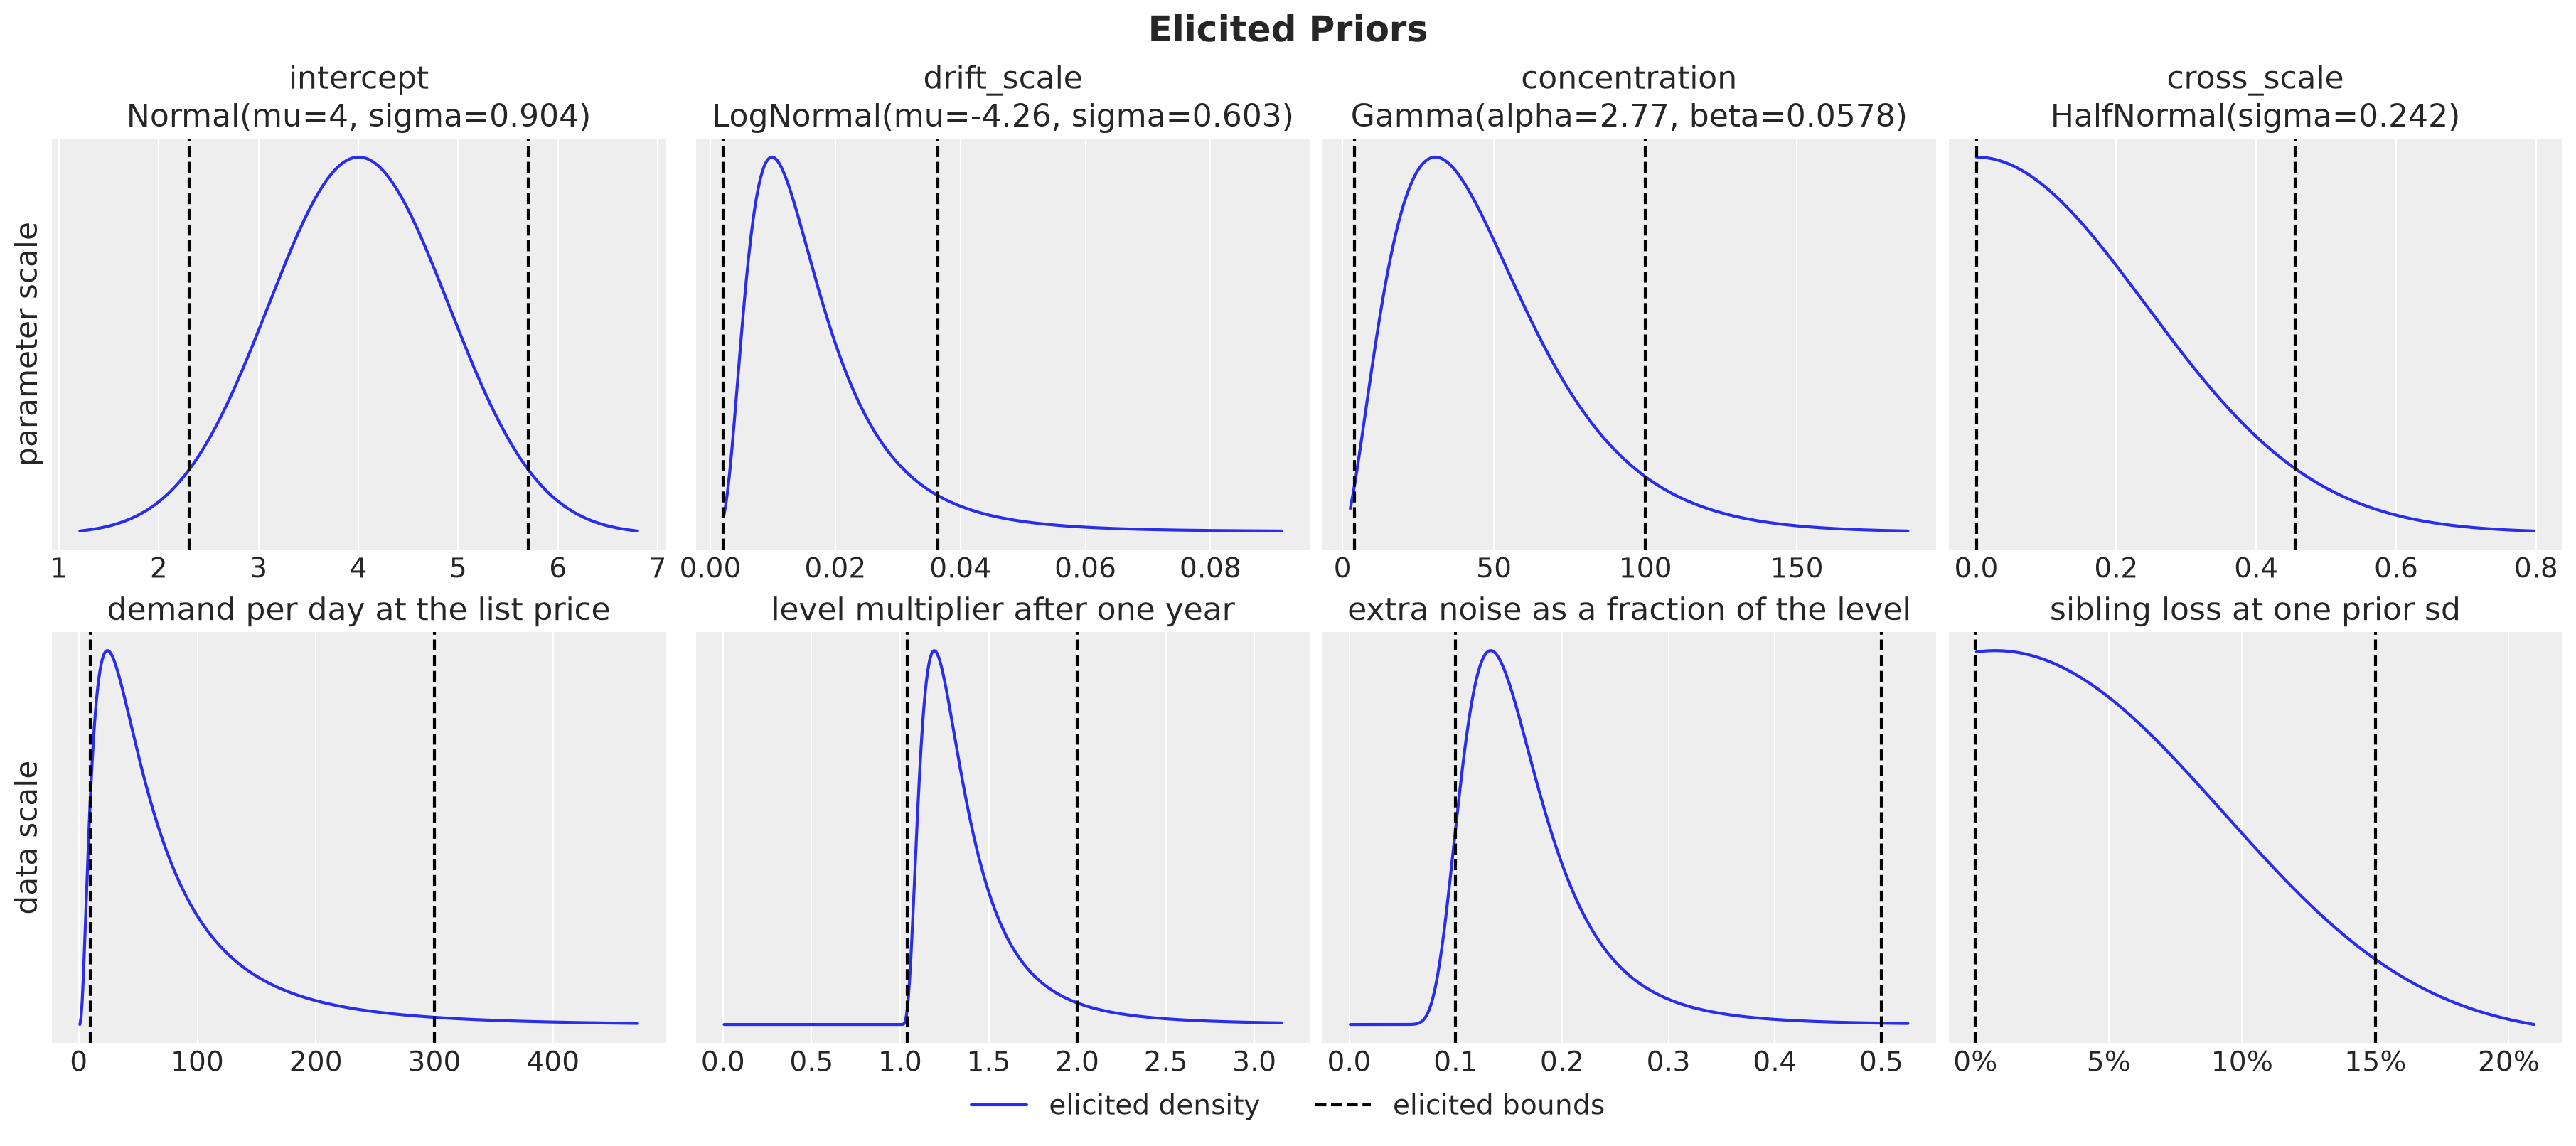

In [8]:
priors_elicited = {
    "intercept": (intercept_prior, intercept_bounds),
    "drift_scale": (drift_prior, drift_bounds),
    "concentration": (concentration_prior, concentration_bounds),
    "cross_scale": (cross_prior, cross_bounds),
}
# for every parameter: the label of the quantity on the data scale, u and its inverse
log_discount = math.log(1 - promotion.discount)
data_scale = {
    "intercept": ("demand per day at the list price", jnp.exp, jnp.log),
    "drift_scale": (
        "level multiplier after one year",
        lambda x: jnp.exp(x * math.sqrt(setup.t_obs)),
        lambda y: jnp.log(y) / math.sqrt(setup.t_obs),
    ),
    "concentration": (
        "extra noise as a fraction of the level",
        lambda x: 1 / jnp.sqrt(x),
        lambda y: 1 / y**2,
    ),
    "cross_scale": (
        "sibling loss at one prior sd",
        lambda x: 1 - jnp.exp(x * log_discount),
        lambda y: jnp.log(1 - y) / log_discount,
    ),
}


def density_on_data_scale(
    prior: pz.distributions.distributions.Continuous,
    inverse: Callable[[Float[Array, " grid"]], Float[Array, " grid"]],
    grid: Float[Array, " grid"],
) -> Float[Array, " grid"]:
    """Density of a monotone transform of the prior, by change of variables."""
    jacobian = jnp.abs(jax.vmap(jax.grad(inverse))(grid))
    return prior.pdf(inverse(grid)) * jacobian


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8), layout="constrained")

for j, (name, (prior, bounds)) in enumerate(priors_elicited.items()):
    label, transform, inverse = data_scale[name]
    # parameter scale: the elicited density and the bounds
    ax = axes[0, j]
    x = jnp.linspace(*prior.ppf([0.001, 0.999]), 500)
    ax.plot(x, prior.pdf(x), color="C0", label="elicited density")
    ax.axvline(bounds[0], color="black", linestyle="--", label="elicited bounds")
    ax.axvline(bounds[1], color="black", linestyle="--")
    ax.set(title=f"{name}\n{prior}", yticks=[])
    # data scale: the same density after the transform, from near zero to the
    # larger of the 99th percentile and the upper bound
    ax = axes[1, j]
    bounds_data = transform(jnp.asarray(bounds))
    upper = 1.05 * max(
        float(transform(jnp.asarray(prior.ppf([0.01, 0.99]))).max()),
        float(bounds_data.max()),
    )
    grid = jnp.linspace(upper / 500, upper, 500)
    ax.plot(grid, density_on_data_scale(prior, inverse, grid), color="C0")

    for bound in bounds_data:
        ax.axvline(bound, color="black", linestyle="--")

    ax.set(title=label, yticks=[])

axes[1, 3].xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[0, 0].set(ylabel="parameter scale")
axes[1, 0].set(ylabel="data scale")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors", fontsize=18, fontweight="bold");

The elicited priors are a $\text{Normal}(4.0, 0.9)$ for the `intercept`, a $\text{LogNormal}(-4.3, 0.6)$ for the drift scale, a $\text{Gamma}$ with shape $2.8$ and rate $0.06$ for the concentration, and a $\text{HalfNormal}(0.24)$ for the scale of the cross elasticities.

The bottom row shows what these priors say on the data scale.

- **Demand per day.** The mass spreads between a few units and a few hundred, most of it below $100$ units.
- **Level multiplier.** After one year the level lies between no move and a doubling, with a tail beyond.
- **Noise fraction.** Most of the mass lies between $0.1$ and $0.3$.
- **Sibling loss.** Most of the mass lies below $10\%$, so the prior favors small cross effects and leaves room for large ones.

Note that `pz.maxent` fixes the total mass between the bounds and not the two tails. The Gamma puts almost all of its remaining $6\%$ above $100$, which is the tail below $0.1$ in the noise panel. The HalfNormal starts at zero, so all of its remaining $6\%$ lies above a loss of $15\%$.

### Model Components

We write each term of the log mean as a function that samples its own sites and returns its contribution with shape `(duration, n_series)`:

- `local_level`: the random walk level $\ell_{t,i}$.
- `weekly_seasonality`: the Fourier term $f_t^\top \beta_j$.
- `price_effects`: the own and cross-price term $\sum_k \gamma_{kj} x_{t,k}$.
- `dispersion`: the concentration $\phi_j$ of the likelihood.

The function `make_demand_model` adds the terms and builds the generator of the data (with the true parameters fixed through `do`) and the two fitted models from the same code, so the true parameters are in the support of the cross model. Two flags control the variants:

- `cross` adds or removes the cross-price term.
- `reparam` switches on the non-centered parameterization of the level increments and of the cross elasticities, which only the fit needs.

The prices are chain-wide, so the cross-price term of a series depends on its product only. We compute it as the matrix product of the log prices with the elasticity matrix $\Gamma$. The own elasticities form the diagonal of $\Gamma$, and the `cross_elasticity` site over the within-group pairs fills the off-diagonal cells, shrunk toward zero by the common scale `cross_scale`.

In [9]:
def local_level(
    h: Horizon, setup: Setup, priors: Priors, *, reparam: bool
) -> Float[Array, "duration n_series"]:
    """Random-walk level per series: the initial level plus the summed increments."""
    with numpyro.plate("series", setup.n_series):
        intercept = numpyro.sample(
            "intercept", dist.Normal(priors.intercept_mu, priors.intercept_sigma)
        )
        drift_scale = numpyro.sample(
            "drift_scale", dist.LogNormal(priors.drift_mu, priors.drift_sigma)
        )
        drift = innovations(
            h,
            "drift",
            dist.Normal(0.0, drift_scale),
            reparam=LocScaleReparam(0) if reparam else None,
        )

    return intercept + jnp.cumsum(drift, axis=-2)


def weekly_seasonality(
    fourier: Float[Array, "duration n_fourier"],
    setup: Setup,
    panel: Panel,
    priors: Priors,
) -> Float[Array, "duration n_series"]:
    """Weekly Fourier seasonality with one coefficient vector per product."""
    with (
        numpyro.plate("fourier", fourier.shape[1], dim=-2),
        numpyro.plate("product", setup.n_products, dim=-1),
    ):
        beta = numpyro.sample("beta", dist.Normal(0.0, priors.seasonal_sigma))

    return (fourier @ beta)[:, panel.series_to_product]


def price_effects(
    log_price: Float[Array, "duration n_products"],
    setup: Setup,
    panel: Panel,
    priors: Priors,
    *,
    cross: bool,
    reparam: bool,
) -> Float[Array, "duration n_series"]:
    """Own price elasticities, plus the cross elasticities of the within-group pairs."""
    with numpyro.plate("product", setup.n_products):
        elasticity = numpyro.sample(
            "elasticity", dist.Normal(priors.elasticity_mu, priors.elasticity_sigma)
        )

    matrix = jnp.diag(elasticity)

    if cross:
        cross_scale = numpyro.sample(
            "cross_scale", dist.HalfNormal(priors.cross_scale_sigma)
        )
        # non-centered: the guide sees standardized cross elasticities
        reparam_config = {"cross_elasticity": LocScaleReparam(0)} if reparam else {}

        with (
            numpyro.plate("pair", panel.pair_rows.size),
            handlers.reparam(config=reparam_config),
        ):
            cross_elasticity = numpyro.sample(
                "cross_elasticity", dist.Normal(0.0, cross_scale)
            )

        matrix = matrix.at[panel.pair_rows, panel.pair_cols].set(cross_elasticity)

    # effect[t, i] = sum_k matrix[k, j(i)] * log_price[t, k]
    return (log_price @ matrix)[:, panel.series_to_product]


def dispersion(setup: Setup, panel: Panel, priors: Priors) -> Float[Array, " n_series"]:
    """Negative binomial concentration per product, gathered to the series axis."""
    with numpyro.plate("product", setup.n_products):
        concentration = numpyro.sample(
            "concentration",
            dist.Gamma(priors.concentration_alpha, priors.concentration_beta),
        )

    return concentration[panel.series_to_product]


def make_demand_model(
    setup: Setup, panel: Panel, priors: Priors, *, cross: bool, reparam: bool = True
) -> ForecastModel:
    """Build the demand model as a plain `(covariates, data=None)` function."""

    def demand_model(
        covariates: Float[Array, "duration inputs"],
        data: Int[Array, "t_obs n_series"] | None = None,
    ) -> None:
        h = Horizon.from_data(covariates, data)
        # the Fourier columns come first and the log prices of the products last
        fourier = covariates[:, : -setup.n_products]
        log_price = covariates[:, -setup.n_products :]

        log_rate = (
            local_level(h, setup, priors, reparam=reparam)
            + weekly_seasonality(fourier, setup, panel, priors)
            + price_effects(
                log_price, setup, panel, priors, cross=cross, reparam=reparam
            )
        )
        concentration = dispersion(setup, panel, priors)
        predict(
            h, lambda eta: dist.NegativeBinomial2(jnp.exp(eta), concentration), log_rate
        )

    return demand_model

Next, let's look at the graph of each component with `numpyro.render_model`. A graph shows the sample sites of a component as nodes, with their distributions, and the plates that repeat them as boxes. We render the plain parameterization (`reparam=False`) on the history. First, the level:

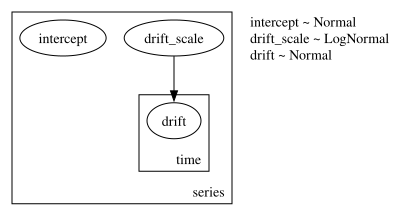

In [10]:
h_history = Horizon.from_data(covariates_train, None)


def render_component(component: Callable[[], Array]) -> gr.Digraph:
    """Graph of the sample sites of one component of the demand model."""
    return numpyro.render_model(component, render_distributions=True)


render_component(partial(local_level, h_history, setup, priors, reparam=False))

The `series` plate repeats the initial level `intercept` and the `drift_scale` for the $200$ series. Inside it, the `time` plate repeats the daily increments `drift` over the $364$ days of the history, with the drift scale of their series as the standard deviation.

Next, the weekly seasonality:

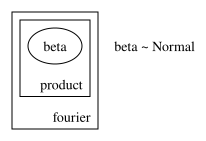

In [11]:
render_component(
    partial(
        weekly_seasonality,
        covariates_train[:, : -setup.n_products],
        setup,
        panel,
        priors,
    )
)

The Fourier coefficients `beta` sit in two plates, one over the $6$ Fourier features and one over the $20$ products, so the stores of a product share its weekly pattern.

Now the price effects of the cross model:

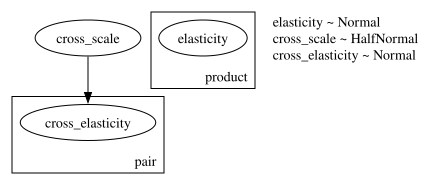

In [12]:
render_component(
    partial(
        price_effects,
        covariates_train[:, -setup.n_products :],
        setup,
        panel,
        priors,
        cross=True,
        reparam=False,
    )
)

The own `elasticity` has one value per product. The `cross_scale` sits outside every plate, since one scale is shared by all groups, and it is the standard deviation of the $60$ values of `cross_elasticity` in the `pair` plate. The independent model has the `elasticity` site only.

Finally, the concentration of the likelihood:

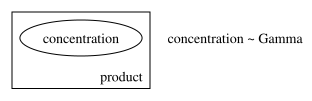

In [13]:
render_component(partial(dispersion, setup, panel, priors))

The model has one concentration per product.

Here is the whole model. We render the cross model in the plain parameterization, the one that generates the data in the next section, on the history:

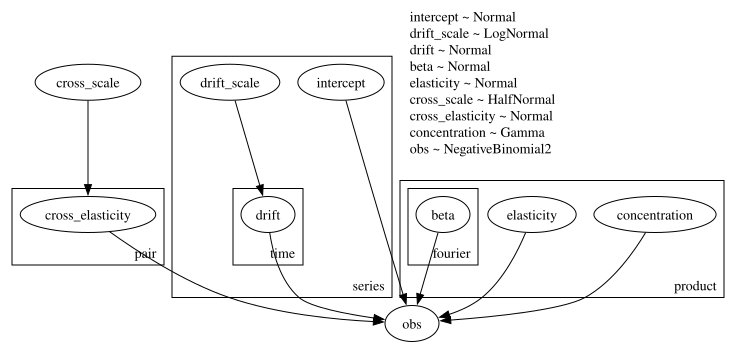

In [14]:
generator = make_demand_model(setup, panel, priors, cross=True, reparam=False)
numpyro.render_model(
    generator, model_args=(covariates_train,), render_distributions=True
)

The four components come together in `obs`, the demand of every series and day. Every sample site of the components points to `obs`, since each one enters the log mean or the likelihood. The `drift_scale` sets the size of the increments `drift`, and the `cross_scale` sets the size of the `cross_elasticity` values.

### True Parameters and Data

We set the cross elasticities by hand and draw the other true values from a small generative model, as we did for the calendar.

- **Initial levels.** The product baselines are $\text{LogUniform}(20, 150)$ units per day and the store multipliers $\text{Uniform}(0.6, 1.5)$. The initial level of a series is the log of their product, between $\log 12$ and $\log 225$.
- **Own elasticities, concentrations and drift scales.** They are uniform between $-2$ and $-1$, between $20$ and $40$, and between $0.005$ and $0.02$.
- **Seasonality.** The Fourier coefficients are $\text{Normal}(0, 0.05)$, a mild weekly pattern.
- **Cross elasticities.** They are constant within a group, at the values of the *Panel and Calendar* section. Their root mean square over the $60$ pairs is $0.33$.

All of these values lie inside the elicited priors.

In [15]:
def true_parameter_generator(setup: Setup, panel: Panel, n_fourier: int) -> None:
    """True parameters of the demand model, apart from the cross elasticities."""
    with numpyro.plate("product", setup.n_products):
        base_product = numpyro.sample("base_product", dist.LogUniform(20.0, 150.0))
        numpyro.sample("elasticity", dist.Uniform(-2.0, -1.0))
        numpyro.sample("concentration", dist.Uniform(20.0, 40.0))

    with numpyro.plate("store", setup.n_stores):
        store_multiplier = numpyro.sample("store_multiplier", dist.Uniform(0.6, 1.5))

    with numpyro.plate("series", setup.n_series):
        numpyro.sample("drift_scale", dist.Uniform(0.005, 0.02))

    with (
        numpyro.plate("fourier", n_fourier, dim=-2),
        numpyro.plate("product", setup.n_products, dim=-1),
    ):
        numpyro.sample("beta", dist.Normal(0.0, 0.05))

    numpyro.deterministic(
        "intercept",
        jnp.log(
            base_product[panel.series_to_product]
            * store_multiplier[panel.series_to_store]
        ),
    )


rng_key, key_truth = random.split(rng_key)
truth = Predictive(true_parameter_generator, num_samples=1)(
    key_truth, setup, panel, fourier.shape[1]
)
group_cross = jnp.asarray(setup.group_cross)

true_params: dict[str, Array] = {
    **{
        name: truth[name][0]
        for name in ["intercept", "drift_scale", "beta", "elasticity", "concentration"]
    },
    # fixed for completeness: the pairs below are fixed too, so it has no effect
    "cross_scale": jnp.asarray(0.3),
    "cross_elasticity": group_cross[panel.product_to_group[panel.pair_rows]],
}

products = products.with_columns(
    baseline=pl.Series(truth["base_product"][0].tolist()),
    elasticity=pl.Series(true_params["elasticity"].tolist()),
    concentration=pl.Series(true_params["concentration"].tolist()),
    cross_elasticity=pl.Series(
        [setup.group_cross[group] for group in panel.product_to_group.tolist()]
    ),
)
products

product,group,role,baseline,elasticity,concentration,cross_elasticity
i64,i64,str,f64,f64,f64,f64
0,1,"""promoted""",44.727,-1.858,39.259,0.600
1,1,"""sibling""",22.641,-1.780,31.772,0.600
2,1,"""sibling""",38.889,-1.313,20.753,0.600
3,1,"""sibling""",108.511,-1.919,34.508,0.600
4,2,"""promoted""",103.298,-1.656,22.604,0.300
5,2,"""sibling""",76.234,-1.331,30.069,0.300
6,2,"""sibling""",60.300,-1.958,29.356,0.300
7,2,"""sibling""",148.866,-1.929,30.910,0.300
8,3,"""promoted""",35.381,-1.844,25.697,0.000


We draw the demand of the whole duration once, from the generator with the true parameters fixed. We keep the realized level increments of the history, because the distribution of the true future conditions on them. The observed data are the first $364$ days and the **realized future** the last $15$.

In [16]:
rng_key, key_data = random.split(rng_key)
draw = Predictive(
    do(generator, data=true_params), num_samples=1, return_sites=["obs", "drift"]
)(key_data, covariates)
demand_full = draw["obs"][0]  # (duration, n_series)
drift_true = draw["drift"][0][: setup.t_obs]  # (t_obs, n_series)
data = demand_full[: setup.t_obs].astype(jnp.int32)
demand_future_true = demand_full[setup.t_obs :].astype(jnp.float32)
assert data.shape == (setup.t_obs, setup.n_series)
assert demand_future_true.shape == (setup.horizon, setup.n_series)

The next figure shows the four products of group $1$ in store $1$ over the last eight weeks of the history and the horizon. The strips at the bottom of each panel mark the promotion days of the product and of its siblings.

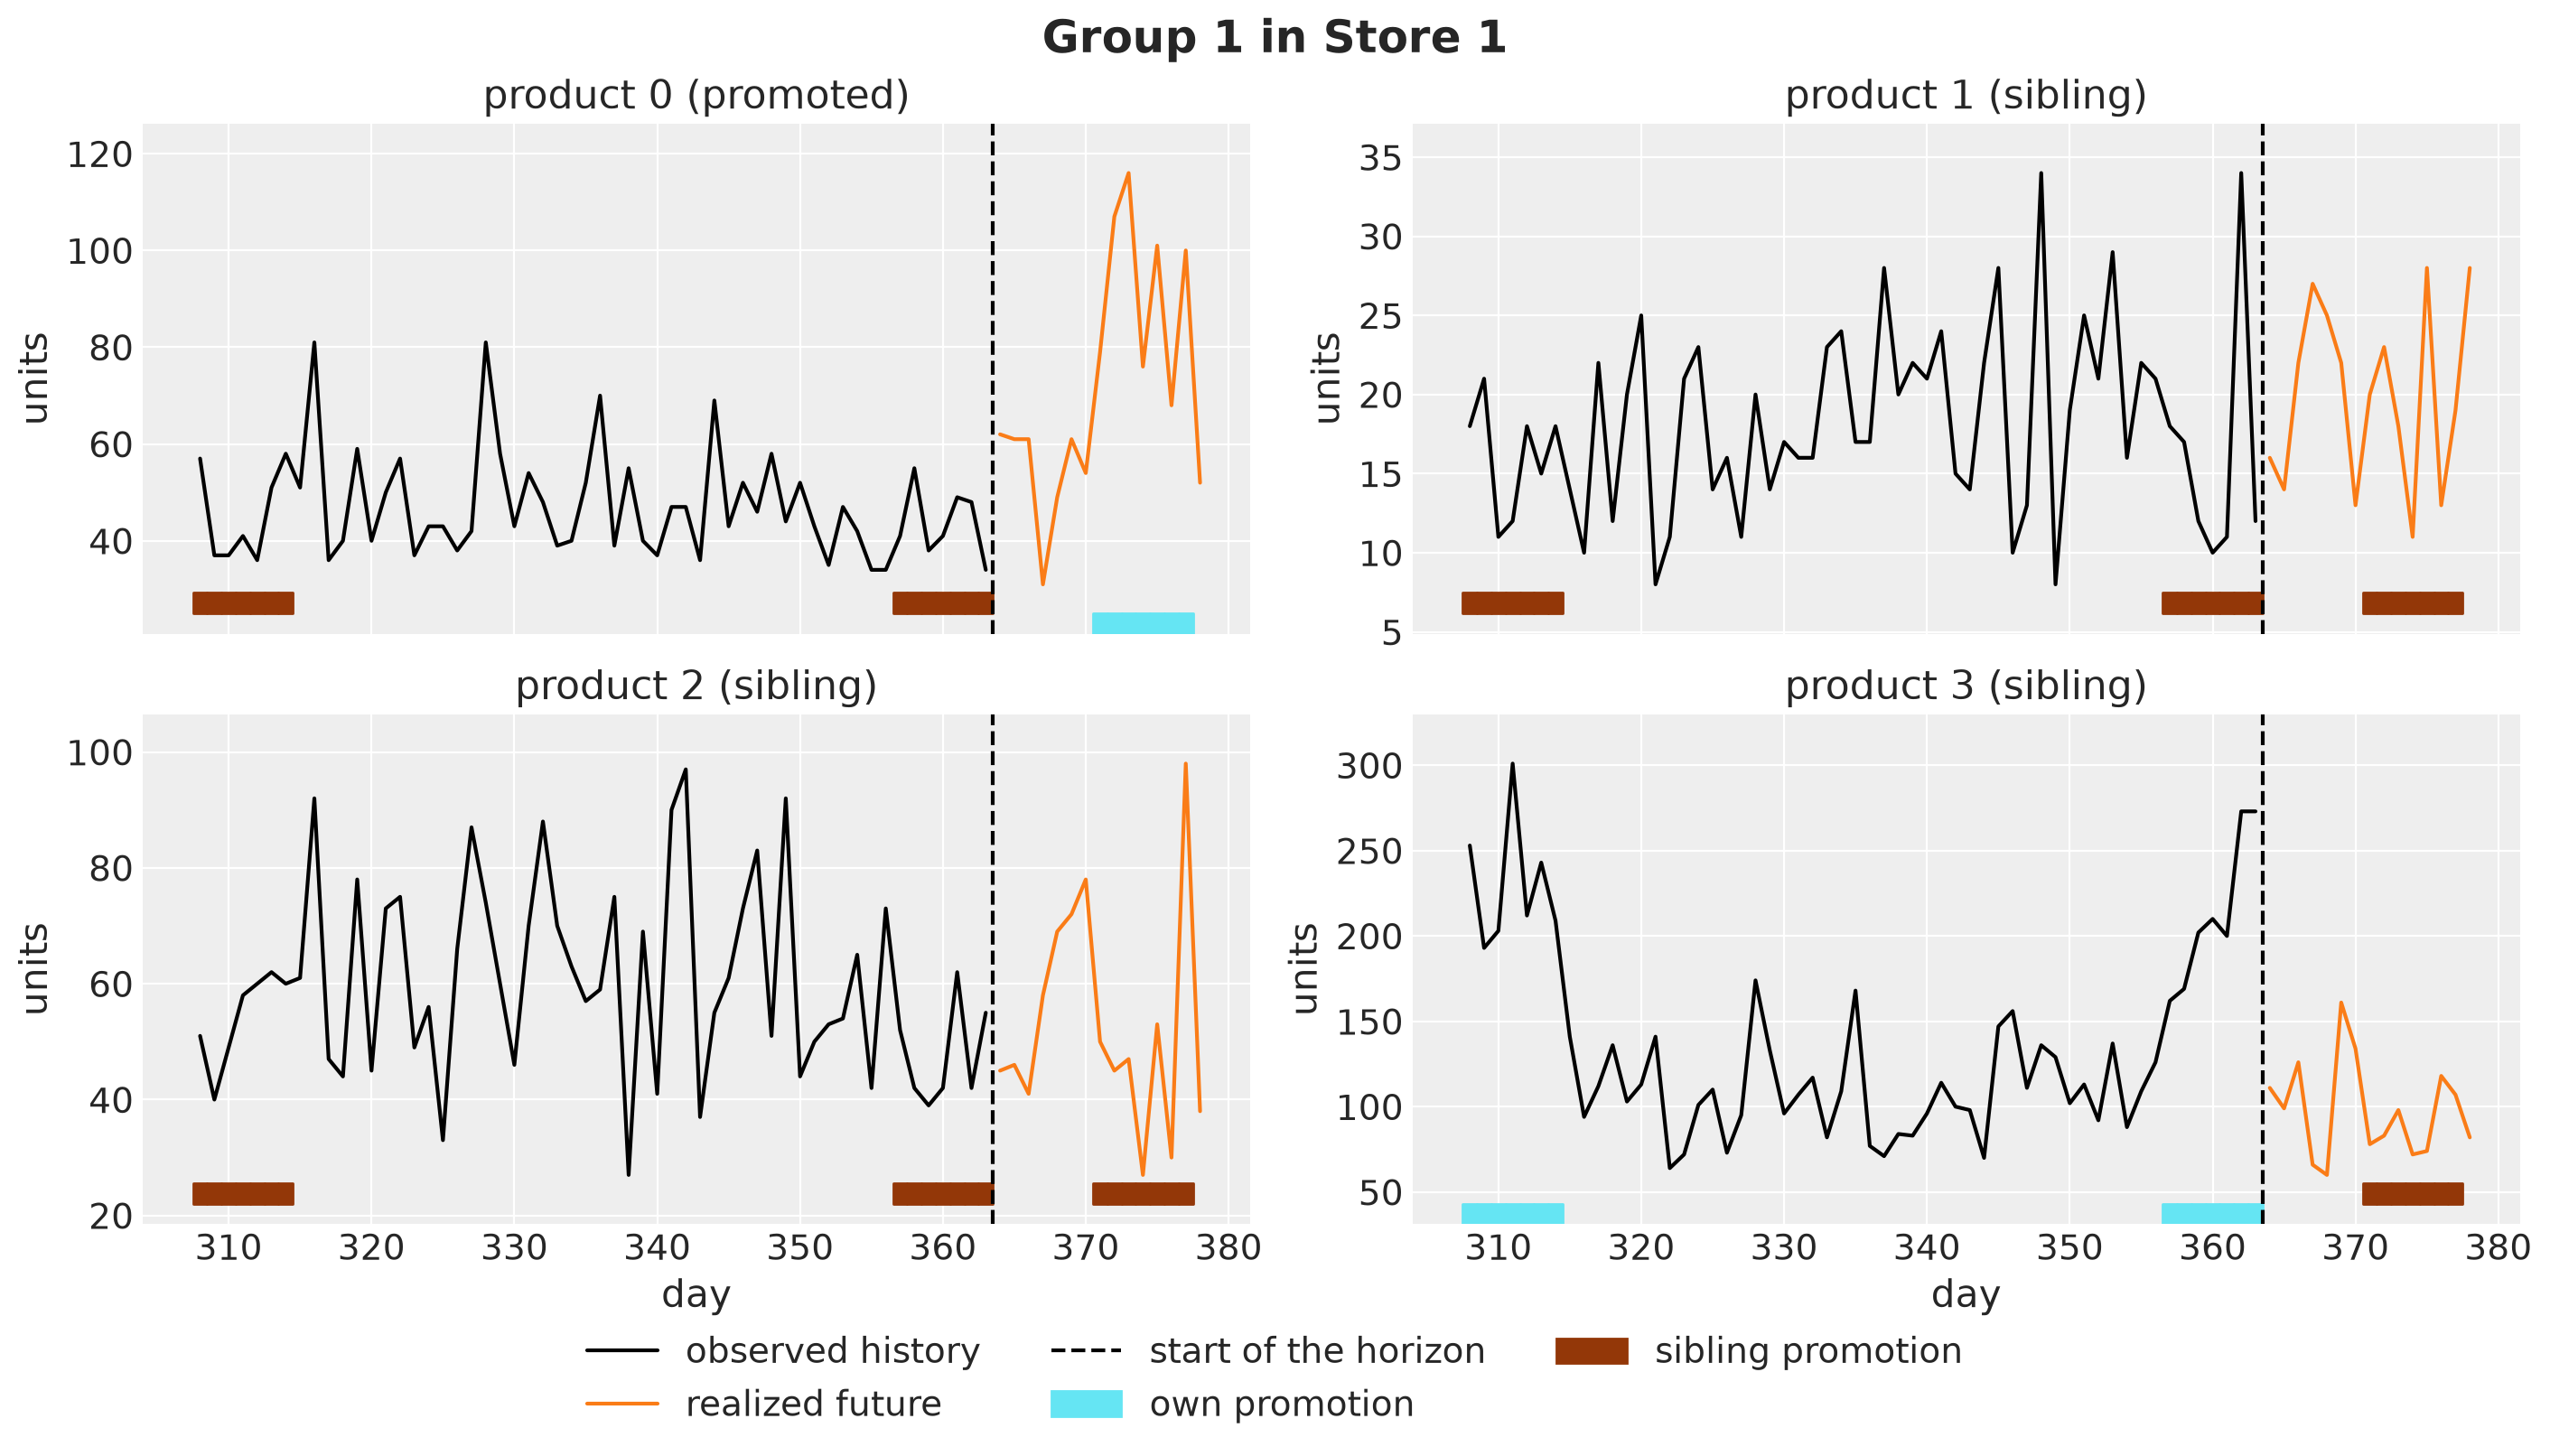

In [17]:
def mark_promotions(ax: plt.Axes, product: int, start: int) -> None:
    """Mark the own and the sibling promotion days of a product from `start` on."""
    own = promo_full[start:, product] > 0
    sibling = sibling_on_promotion(promo_full[start:])[:, product]
    # two strips along the bottom of the axes, in axes coordinates, clear of the data
    for mask, color, bottom, label in [
        (own, "C5", 0.0, "own promotion"),
        (sibling, "C4", 0.04, "sibling promotion"),
    ]:
        ax.broken_barh(
            [(start + day - 0.5, 1.0) for day in jnp.flatnonzero(mask).tolist()],
            (bottom, 0.04),
            transform=ax.get_xaxis_transform(),
            color=color,
            label=label,
        )

    ax.margins(y=0.12)


def plot_demand(ax: plt.Axes, series: int, start: int) -> None:
    """History from `start`, realized future and promotion days of one series."""
    ax.plot(
        days[start : setup.t_obs],
        demand_full[start : setup.t_obs, series],
        color="black",
        label="observed history",
    )
    ax.plot(
        days_future, demand_future_true[:, series], color="C1", label="realized future"
    )
    ax.axvline(
        setup.t_obs - 0.5, color="black", linestyle="--", label="start of the horizon"
    )
    mark_promotions(ax, int(panel.series_to_product[series]), start)


fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 8), sharex=True, layout="constrained"
)

# the four products of group 1 in store 1 are the first four series
for series, ax in enumerate(axes.flat):
    plot_demand(ax, series, start=setup.t_obs - 56)
    ax.set(title=f"product {series} ({product_role[series]})", ylabel="units")

for ax in axes[-1]:
    ax.set(xlabel="day")

fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Group 1 in Store 1", fontsize=18, fontweight="bold");

The promoted product about doubles in the second week of the horizon, and the three siblings dip in the same week, which is the cannibalization.

The history shows the same pattern. Product $3$ was on promotion in the last week of the history, so that week is a sibling promotion week for products $0$, $1$ and $2$, and their demand was lower in that week. Keep this in mind, because the forecast of these three products starts right after a dip.

### Evaluation Scenarios

In the first post we scored the plans on held-out draws of the posterior that built them, which cannot tell us what happens when the forecast is wrong.

Here we know the true process, so we can do better. We draw $1{,}000$ scenarios from the generator with the true parameters and the realized level increments of the history fixed. Only the future increments and the observation noise are fresh, so these scenarios are draws from the distribution of the true future given the history.

We call them the **evaluation scenarios** and score every plan on them. This tests every plan against the misspecification of its model.

Later, every model gives $1{,}000$ forecast draws as well. We use the same number on both sides, so that the comparisons between the forecasts and the evaluation scenarios, for example of their standard deviations, rest on the same number of draws.

In [18]:
# the number of evaluation scenarios and of forecast draws of every model
N_SCENARIOS = 1_000

rng_key, key_eval = random.split(rng_key)
true_future_generator = do(generator, data={**true_params, "drift": drift_true})
demand_eval = Predictive(
    true_future_generator, num_samples=N_SCENARIOS, return_sites=["forecast"]
)(key_eval, covariates, data)["forecast"].astype(jnp.float32)
assert demand_eval.shape == (N_SCENARIOS, setup.horizon, setup.n_series)

## Forecasting Model

We fit two models to the same history. The **cross model** is the demand model of the previous section.

The **independent model** is the same model without the cross-price term, so it has no link between the products of a group.

The following graph shows the two paths from a promotion to the demand of a group of two products. The price of product A moves its own demand through the own elasticity and the demand of product B through the cross elasticity. The red arrows are what the independent model drops.

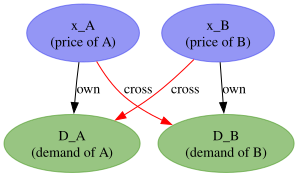

In [19]:
dag = gr.Digraph()
dag.node("xA", label="x_A\n(price of A)", color="#2a2eec80", style="filled")
dag.node("xB", label="x_B\n(price of B)", color="#2a2eec80", style="filled")
dag.node("DA", label="D_A\n(demand of A)", color="#328c0680", style="filled")
dag.node("DB", label="D_B\n(demand of B)", color="#328c0680", style="filled")
dag.edge("xA", "DA", label="own")
dag.edge("xB", "DB", label="own")
dag.edge("xA", "DB", label="cross", color="red")
dag.edge("xB", "DA", label="cross", color="red")
dag

Here is an important observation: the independent model is misspecified on the history as well as on the horizon. In the history, the demand of a product with cannibalization dips by $10\%$ to $19\%$ in every week in which a sibling is on promotion.

The independent model has no term for these dips, so it has to explain them with the two things it has, the level of the series and the noise of the likelihood. We check in the *Parameter Recovery* section what this does to its estimates.

Both models take the same covariates and data. The cross model has the graph of the *Model Components* section, and the independent model drops its `cross_scale` and `cross_elasticity` sites. We build both in the non-centered parameterization that the fit uses.

In [20]:
model_independent = make_demand_model(setup, panel, priors, cross=False)
model_cross = make_demand_model(setup, panel, priors, cross=True)

## Prior Predictive Checks

Before we fit the models, we draw demand paths from the priors of the cross model and compare them with the history. We plot the $50\%$ and $94\%$ equal-tailed intervals (ETI) of $300$ draws for the first product of groups $1$ to $4$ in store $1$.

The axis is logarithmic because the log link gives the prior a long upper tail. Every band of this notebook is an equal-tailed interval, which runs between two percentiles.

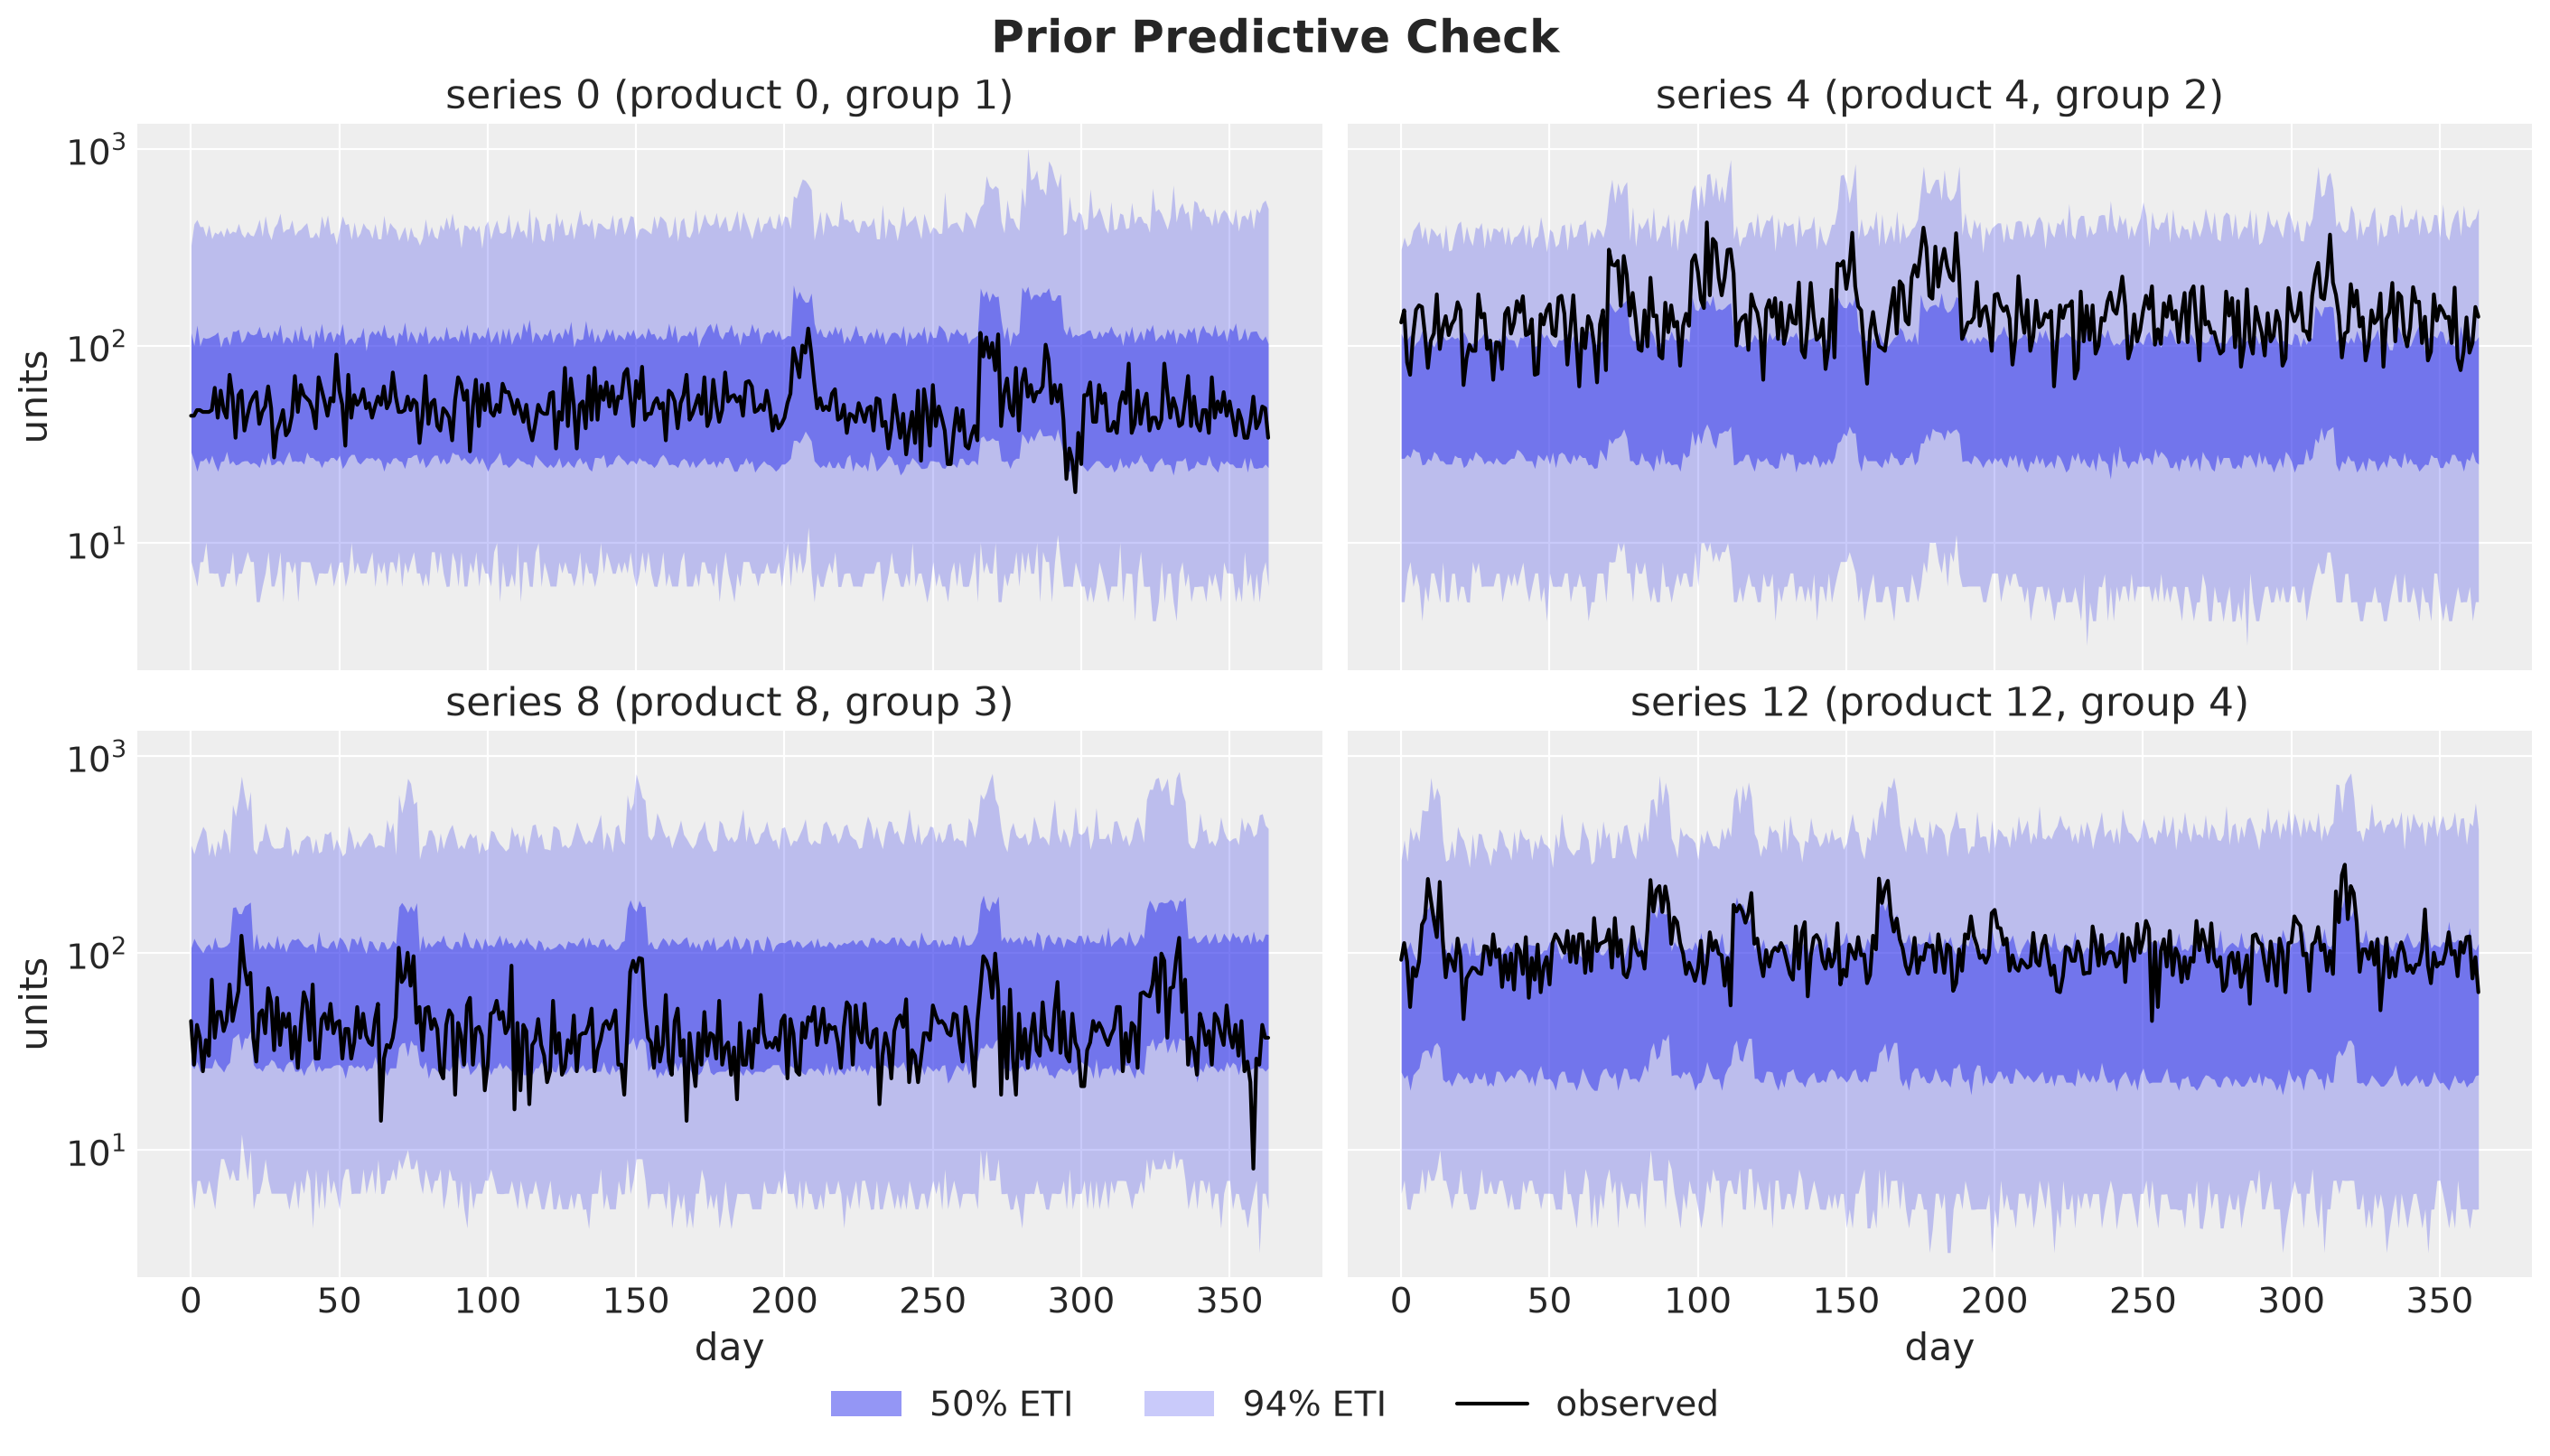

In [21]:
def lighten_bands(
    pc: az.PlotCollection,
    x: str,
    prob_alpha: tuple[tuple[float, float], ...] = ((0.5, 0.5), (CI_PROB, 0.25)),
) -> None:
    """Set the alpha of the credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in prob_alpha:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


check_series = jnp.arange(4) * setup.n_per_group  # the first product of groups 1 to 4
check_labels = [
    f"series {i} (product {i}, group {g + 1})"
    for g, i in enumerate(check_series.tolist())
]


def plot_predictive_check(
    obs_draws: Shaped[Array, "sample t_obs n_check"], title: str, yscale: str = "linear"
) -> None:
    """Bands of predictive draws of the check series against the history."""
    tree = az.from_dict(
        {
            # the group name is the one `plot_lm` reads by default
            "posterior_predictive": {"obs": obs_draws[None].transpose(0, 1, 3, 2)},
            "observed_data": {"obs": data[:, check_series].T},
            # `plot_lm` sorts this array in place, and JAX arrays are immutable, so
            # we pass a writable numpy copy
            "constant_data": {
                "day": np.array(jnp.tile(days[: setup.t_obs].astype(float), (4, 1)))
            },
        },
        coords={"series": check_labels, "time": days[: setup.t_obs]},
        dims={"obs": ["series", "time"], "day": ["series", "time"]},
    )
    pc = az.plot_lm(
        tree,
        x="day",
        y="obs",
        y_obs="obs",
        plot_dim="time",
        smooth=False,
        ci_prob=(0.5, CI_PROB),
        visuals={
            "ci_band": {"color": "C0"},
            "observed_scatter": False,
            "pe_line": False,
            "xlabel": False,
            "ylabel": False,
        },
        col_wrap=2,
        figure_kwargs={"figsize": (14, 8), "sharex": True, "sharey": True},
    )
    lighten_bands(pc, "day")

    for k, label in enumerate(check_labels):
        ax = pc.get_target("day", {"series": label})
        bands = pc.viz["ci_band"]["day"].sel(series=label)
        bands.sel(prob=0.5).item().set_label("50% ETI")
        bands.sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
        ax.plot(
            days[: setup.t_obs],
            data[:, check_series[k]],
            color="black",
            label="observed",
        )
        ax.set(
            title=label,
            yscale=yscale,
            xlabel="day" if k >= 2 else "",
            ylabel="units" if k % 2 == 0 else "",
        )

    fig = pc.viz["figure"].item()
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3)
    fig.suptitle(title, fontsize=18, fontweight="bold")


rng_key, key_prior = random.split(rng_key)
prior_obs = Predictive(model_cross, num_samples=300, return_sites=["obs"])(
    key_prior, covariates_train
)["obs"]
plot_predictive_check(
    prior_obs[..., check_series], "Prior Predictive Check", yscale="log"
);

The priors put the demand on the right order of magnitude. The $50\%$ band runs from about $25$ to about $110$ units on a typical day, and the $94\%$ band from about $6$ to about $400$ units. The four observed series stay inside the wide band on every day.

The bumps of the bands are the own promotion weeks of each product. Nothing here is implausible for products that sell tens of units per day, so we move on to the fit.

## Model Fitting

### Variational Inference

Each model has about $73K$ latent variables, $72{,}800$ of them the level increments of the $200$ series. That puts NUTS out of reach for a notebook, so we use stochastic variational inference (SVI), which also makes it cheap to fit two models.

SVI approximates the posterior with a **guide**, a family of simple distributions whose parameters we fit by maximizing the evidence lower bound (ELBO). The simplest guide is the mean-field Normal guide `AutoNormal`, which gives every latent variable its own Normal and ignores the posterior correlations. A guide of this form tends to underestimate the posterior variance, see [Blei, Kucukelbir and McAuliffe (2017)](https://doi.org/10.1080/01621459.2017.1285773).

We know in advance where the strongest posterior correlations are, so we make two choices before the fit.

- **The cosine basis for the random walk.** The data pin down the level of a series, that is, the partial sums of its increments, and leave the split of a change between consecutive increments loose. So the increments of a random walk are strongly correlated a posteriori. The `time_reparam` wrapper of `numpyro_forecast`, a port of the `time_reparam` option of Pyro's [forecasting module](https://docs.pyro.ai/en/stable/contrib.forecast.html), samples the discrete cosine transform (DCT) of the increments instead of the increments themselves. The transform is orthonormal, so the model is the same. The cosine coefficients are much less correlated a posteriori, so a mean-field guide over them loses less.
- **A full-rank guide on the price effects.** Within a substitution group, the own elasticity of a product and the cross elasticities to and from its siblings explain the same promotion weeks, so their posteriors are correlated. In the non-centered parameterization, `cross_scale` and the standardized cross elasticities are correlated as well. With [`AutoGuideList`](https://num.pyro.ai/en/stable/autoguide.html#numpyro.infer.autoguide.AutoGuideList) we combine two guides. An `AutoMultivariateNormal`, a Normal with a full covariance matrix, covers the price-effect sites, and an `AutoNormal` covers the rest.

Note that a guide list splits the model by sites, not by entries of a site. So the full-rank block covers the price effects of all groups at once, and its covariance contains the correlations within every group.

Instead of the convergence diagnostics of NUTS we run four checks. The second and the fourth need the known truth, which the synthetic data give us.

1. **The loss trace.** The negative ELBO has to settle.
2. **Parameter recovery.** The posterior has to cover the true parameters, including the level at the end of the history that the forecast starts from.
3. **Posterior predictive check.** The predictive distribution has to follow the history.
4. **Forecast width.** We compare the width of the predictive distribution with the width of the evaluation scenarios.

The function `make_guide` builds the guide list. Each part sees the model through `handlers.block`, which hides the sites of the other part and the deterministic sites. The function `fit_svi` runs Adam on the negative ELBO for a fixed number of steps. The step size follows a cosine decay from $0.01$ to $0.0005$, so that the noise of the gradient moves the last iterates less. We initialize every part at the median of a few prior draws. The `FitConfig` tuple holds these settings.

In [22]:
class FitConfig(NamedTuple):
    """Settings of the variational fit."""

    n_svi_steps: int = 10_000
    step_size: float = 0.01  # initial step size of Adam
    step_size_final_ratio: float = 0.05  # final step size over the initial one


# the sample sites of the price effects, the full-rank part of the guide
PRICE_SITES = ("elasticity", "cross_scale", "cross_elasticity_decentered")


def make_guide(model: ForecastModel) -> AutoGuideList:
    """Full-rank Normal guide on the price effects, mean-field on the rest."""
    init_loc_fn = init_to_median(num_samples=15)
    seeded = handlers.seed(model, rng_seed=0)
    guide = AutoGuideList(model, init_loc_fn=init_loc_fn)
    guide.append(
        AutoMultivariateNormal(
            handlers.block(
                seeded,
                hide_fn=lambda site: (
                    site["type"] != "plate" and site["name"] not in PRICE_SITES
                ),
            ),
            init_loc_fn=init_loc_fn,
        )
    )
    guide.append(
        AutoNormal(
            handlers.block(
                seeded,
                hide_fn=lambda site: (
                    site["type"] == "deterministic" or site["name"] in PRICE_SITES
                ),
            ),
            init_loc_fn=init_loc_fn,
        )
    )
    return guide


def fit_svi(
    model: ForecastModel, rng_key: PRNGKeyArray, fit: FitConfig
) -> tuple[AutoGuideList, SVIRunResult]:
    """Fit the guide of `make_guide` to `model` on the history."""
    guide = make_guide(model)
    schedule = optax.cosine_decay_schedule(
        fit.step_size, fit.n_svi_steps, alpha=fit.step_size_final_ratio
    )
    svi = SVI(model, guide, optax.adam(schedule), Trace_ELBO())
    result = svi.run(
        rng_key, fit.n_svi_steps, covariates_train, data, progress_bar=False
    )
    return guide, result


fit_config = FitConfig()

### Model Fits

We fit both models in the cosine basis, with the same key and the same settings.

In [23]:
%%time


class Model(StrEnum):
    """The two forecasting models."""

    INDEPENDENT = "independent"
    CROSS = "cross"


models = {
    Model.INDEPENDENT: time_reparam(model_independent, "dct"),
    Model.CROSS: time_reparam(model_cross, "dct"),
}

rng_key, key_svi = random.split(rng_key)
guides, svi_results = {}, {}

for model in models:
    guides[model], svi_results[model] = fit_svi(models[model], key_svi, fit_config)

CPU times: user 3min 30s, sys: 1min 12s, total: 4min 42s
Wall time: 59.3 s


The following figure shows the loss of the two fits, the negative ELBO at every step, in the style of the [introduction to SVI](https://juanitorduz.github.io/intro_svi/). The left panel shows all steps on a log scale, and the right panel zooms into the last $2{,}000$ steps.

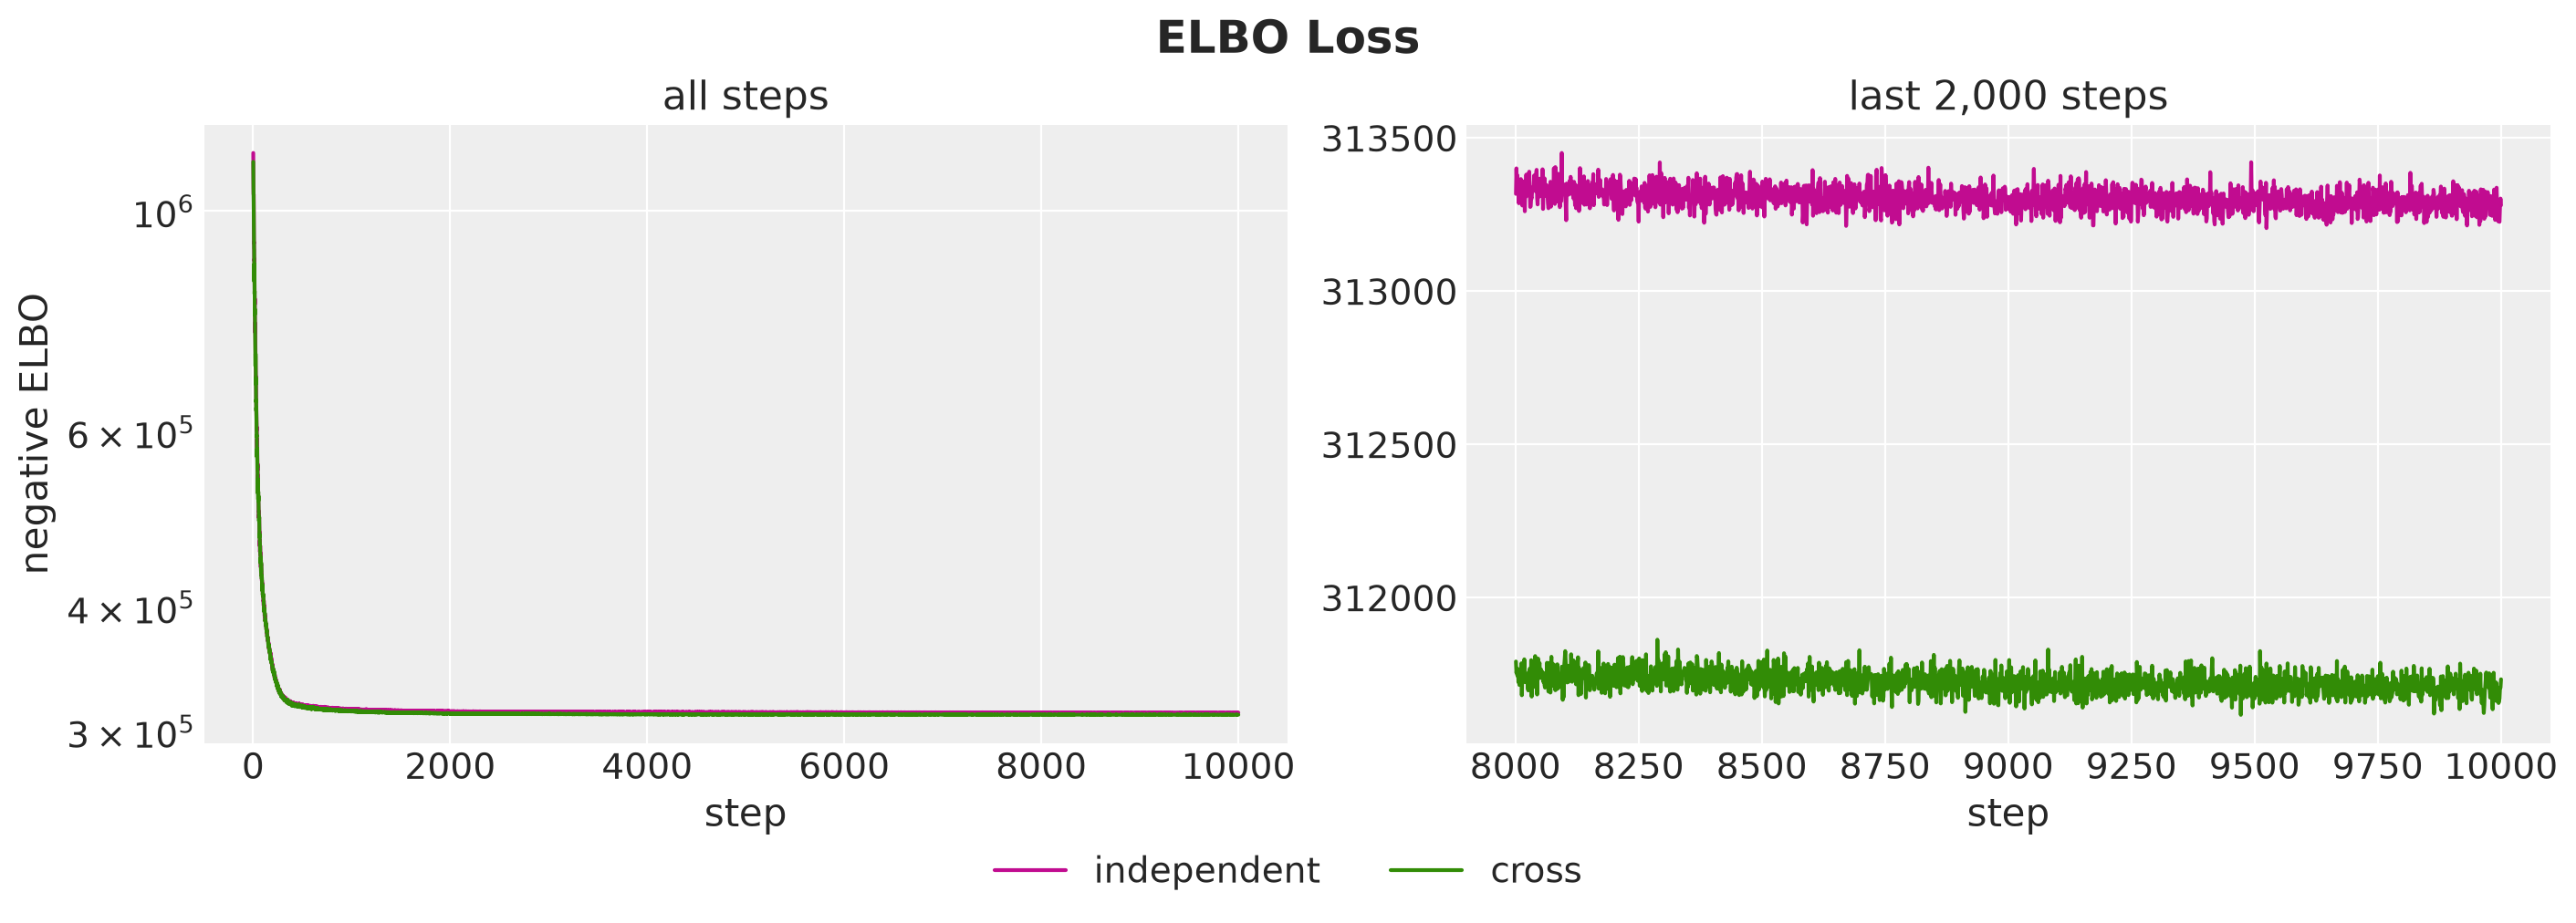

In [24]:
MODEL_COLORS = {Model.INDEPENDENT: "C3", Model.CROSS: "C2"}
LAST_STEPS = 2_000

fig, axes = plt.subplots(ncols=2, figsize=(14, 5), layout="constrained")

for model in models:
    losses = svi_results[model].losses
    steps = jnp.arange(1, losses.size + 1)
    axes[0].plot(steps, losses, color=MODEL_COLORS[model], label=model)
    axes[1].plot(steps[-LAST_STEPS:], losses[-LAST_STEPS:], color=MODEL_COLORS[model])

axes[0].set(title="all steps", xlabel="step", ylabel="negative ELBO", yscale="log")
axes[1].set(title=f"last {LAST_STEPS:,} steps", xlabel="step")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("ELBO Loss", fontsize=18, fontweight="bold");

Both losses fall by a factor of more than three in the first few hundred steps and then decrease slowly. Over the last $2{,}000$ steps they are close to flat, with a step-to-step noise of about $30$. Part of this is the decay of the step size, so a flat trace alone does not show convergence, and we rely on the checks of the next sections.

The cross model ends about $1{,}600$ lower than the independent model, at $311{,}710$ against $313{,}289$ over the last $500$ steps. This is what the cross-price term adds on the same data.

For each fit we draw $1{,}000$ posterior samples of the latent sites with `draw_posterior` and forecast the horizon with `forecast`. The guide samples the latent sites only, so we get the deterministic sites, the level increments in the time domain and the cross elasticities, from the model with `Predictive`. We keep the parameters, the level of every series at the end of the history and the forecast scenarios of each fit in a `FitDraws` tuple.

In [25]:
class FitDraws(NamedTuple):
    """Posterior draws of one fit."""

    parameters: dict[str, Array]  # the parameter sites, on their natural scale
    level_end: Float[Array, "sample n_series"]  # level at the end of the history
    scenarios: Float[Array, "sample horizon n_series"]  # forecast of the horizon


PARAMETER_SITES = (
    "intercept",
    "drift_scale",
    "beta",
    "elasticity",
    "concentration",
    "cross_scale",
    "cross_elasticity",
)


def draw_fit(
    rng_key: PRNGKeyArray,
    model: ForecastModel,
    guide: AutoGuideList,
    result: SVIRunResult,
    num_samples: int,
) -> FitDraws:
    """Parameters, level at the end of the history and forecast of one fit."""
    key_latent, key_deterministic, key_forecast = random.split(rng_key, 3)
    latent = draw_posterior(key_latent, guide, result.params, num_samples)
    deterministic = Predictive(
        model, posterior_samples=latent, return_sites=["drift", "cross_elasticity"]
    )(key_deterministic, covariates_train, data)
    draws = latent | deterministic
    scenarios = forecast(
        key_forecast, model, latent, data, covariates, batch_size=250
    ).astype(jnp.float32)
    return FitDraws(
        parameters={name: draws[name] for name in PARAMETER_SITES if name in draws},
        level_end=draws["intercept"] + draws["drift"].sum(axis=1),
        scenarios=scenarios,
    )


rng_key, key_fit = random.split(rng_key)
draws = {
    model: draw_fit(
        key_fit, models[model], guides[model], svi_results[model], N_SCENARIOS
    )
    for model in models
}

for model in models:
    assert draws[model].scenarios.shape == (N_SCENARIOS, setup.horizon, setup.n_series)

Next, let's look at the posterior of `cross_scale`, the common scale of the cross elasticities. A scale estimated from the $60$ true cross elasticities would be close to their root mean square, $0.33$, which we draw as a reference line.

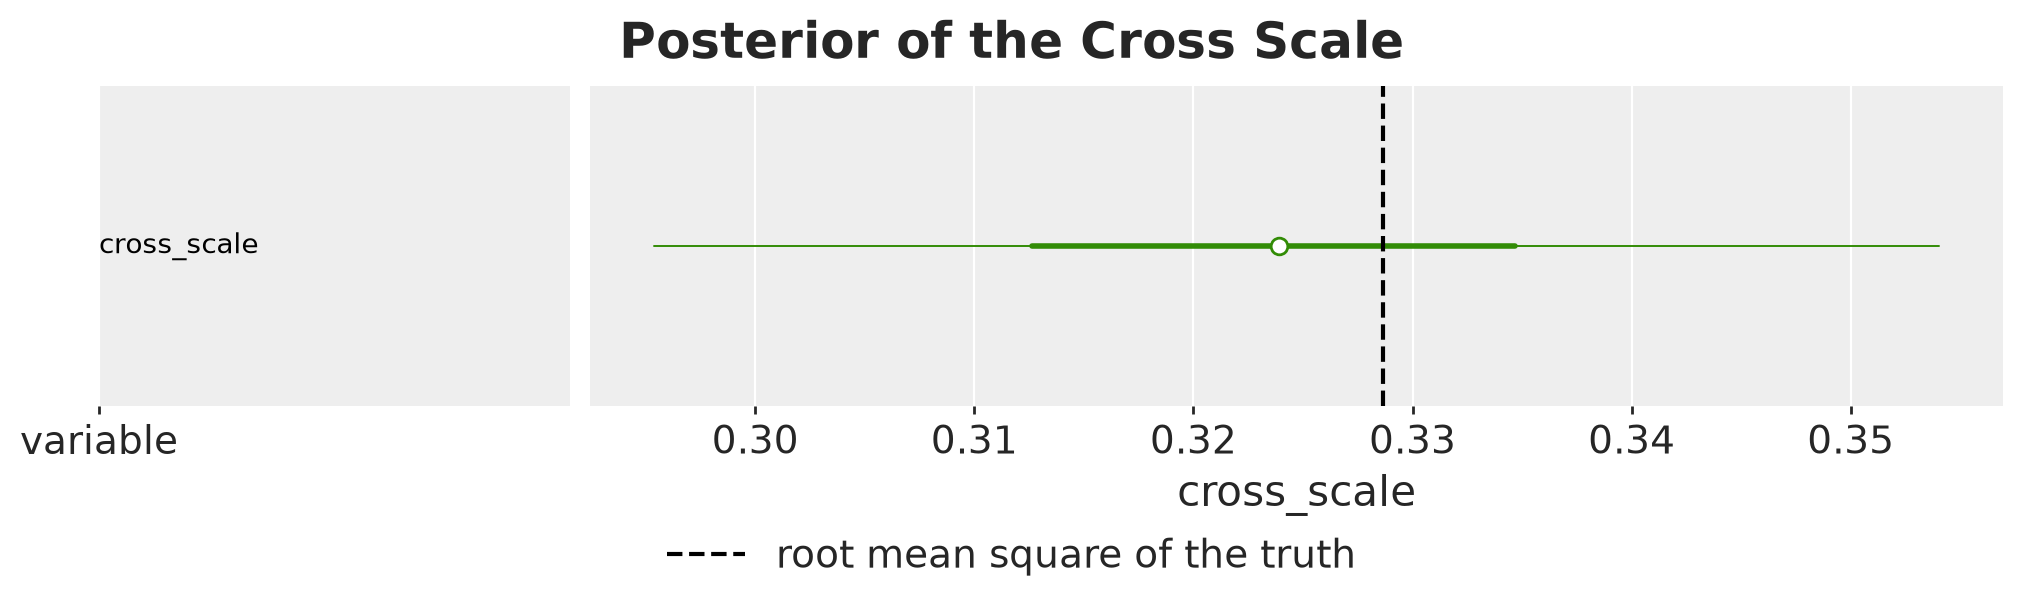

In [26]:
cross_rms = float(jnp.sqrt((true_params["cross_elasticity"] ** 2).mean()))

pc = az.plot_forest(
    {
        Model.CROSS: xr.Dataset(
            {"cross_scale": (("sample",), draws[Model.CROSS].parameters["cross_scale"])}
        )
    },
    sample_dims=["sample"],
    color=[MODEL_COLORS[Model.CROSS]],
    figure_kwargs={"figsize": (10, 3)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(
    cross_rms, color="black", linestyle="--", label="root mean square of the truth"
)
ax.set(xlabel="cross_scale")
pc.viz["figure"].item().legend(loc="outside lower center")
pc.viz["figure"].item().suptitle(
    "Posterior of the Cross Scale", fontsize=18, fontweight="bold"
);

The posterior mean of `cross_scale` is $0.32$, and its $94\%$ interval runs from $0.30$ to $0.35$. The interval covers the root mean square of the true cross elasticities, $0.33$, which is good!

## Parameter Recovery

We compare the posterior of each model with the true parameters and with the true level of every series at the end of the history.

### Elasticities

First, we look at the own elasticities. We plot the posterior of `elasticity` minus its true value for every product and both models, so that a well-recovered parameter has an interval that covers zero.

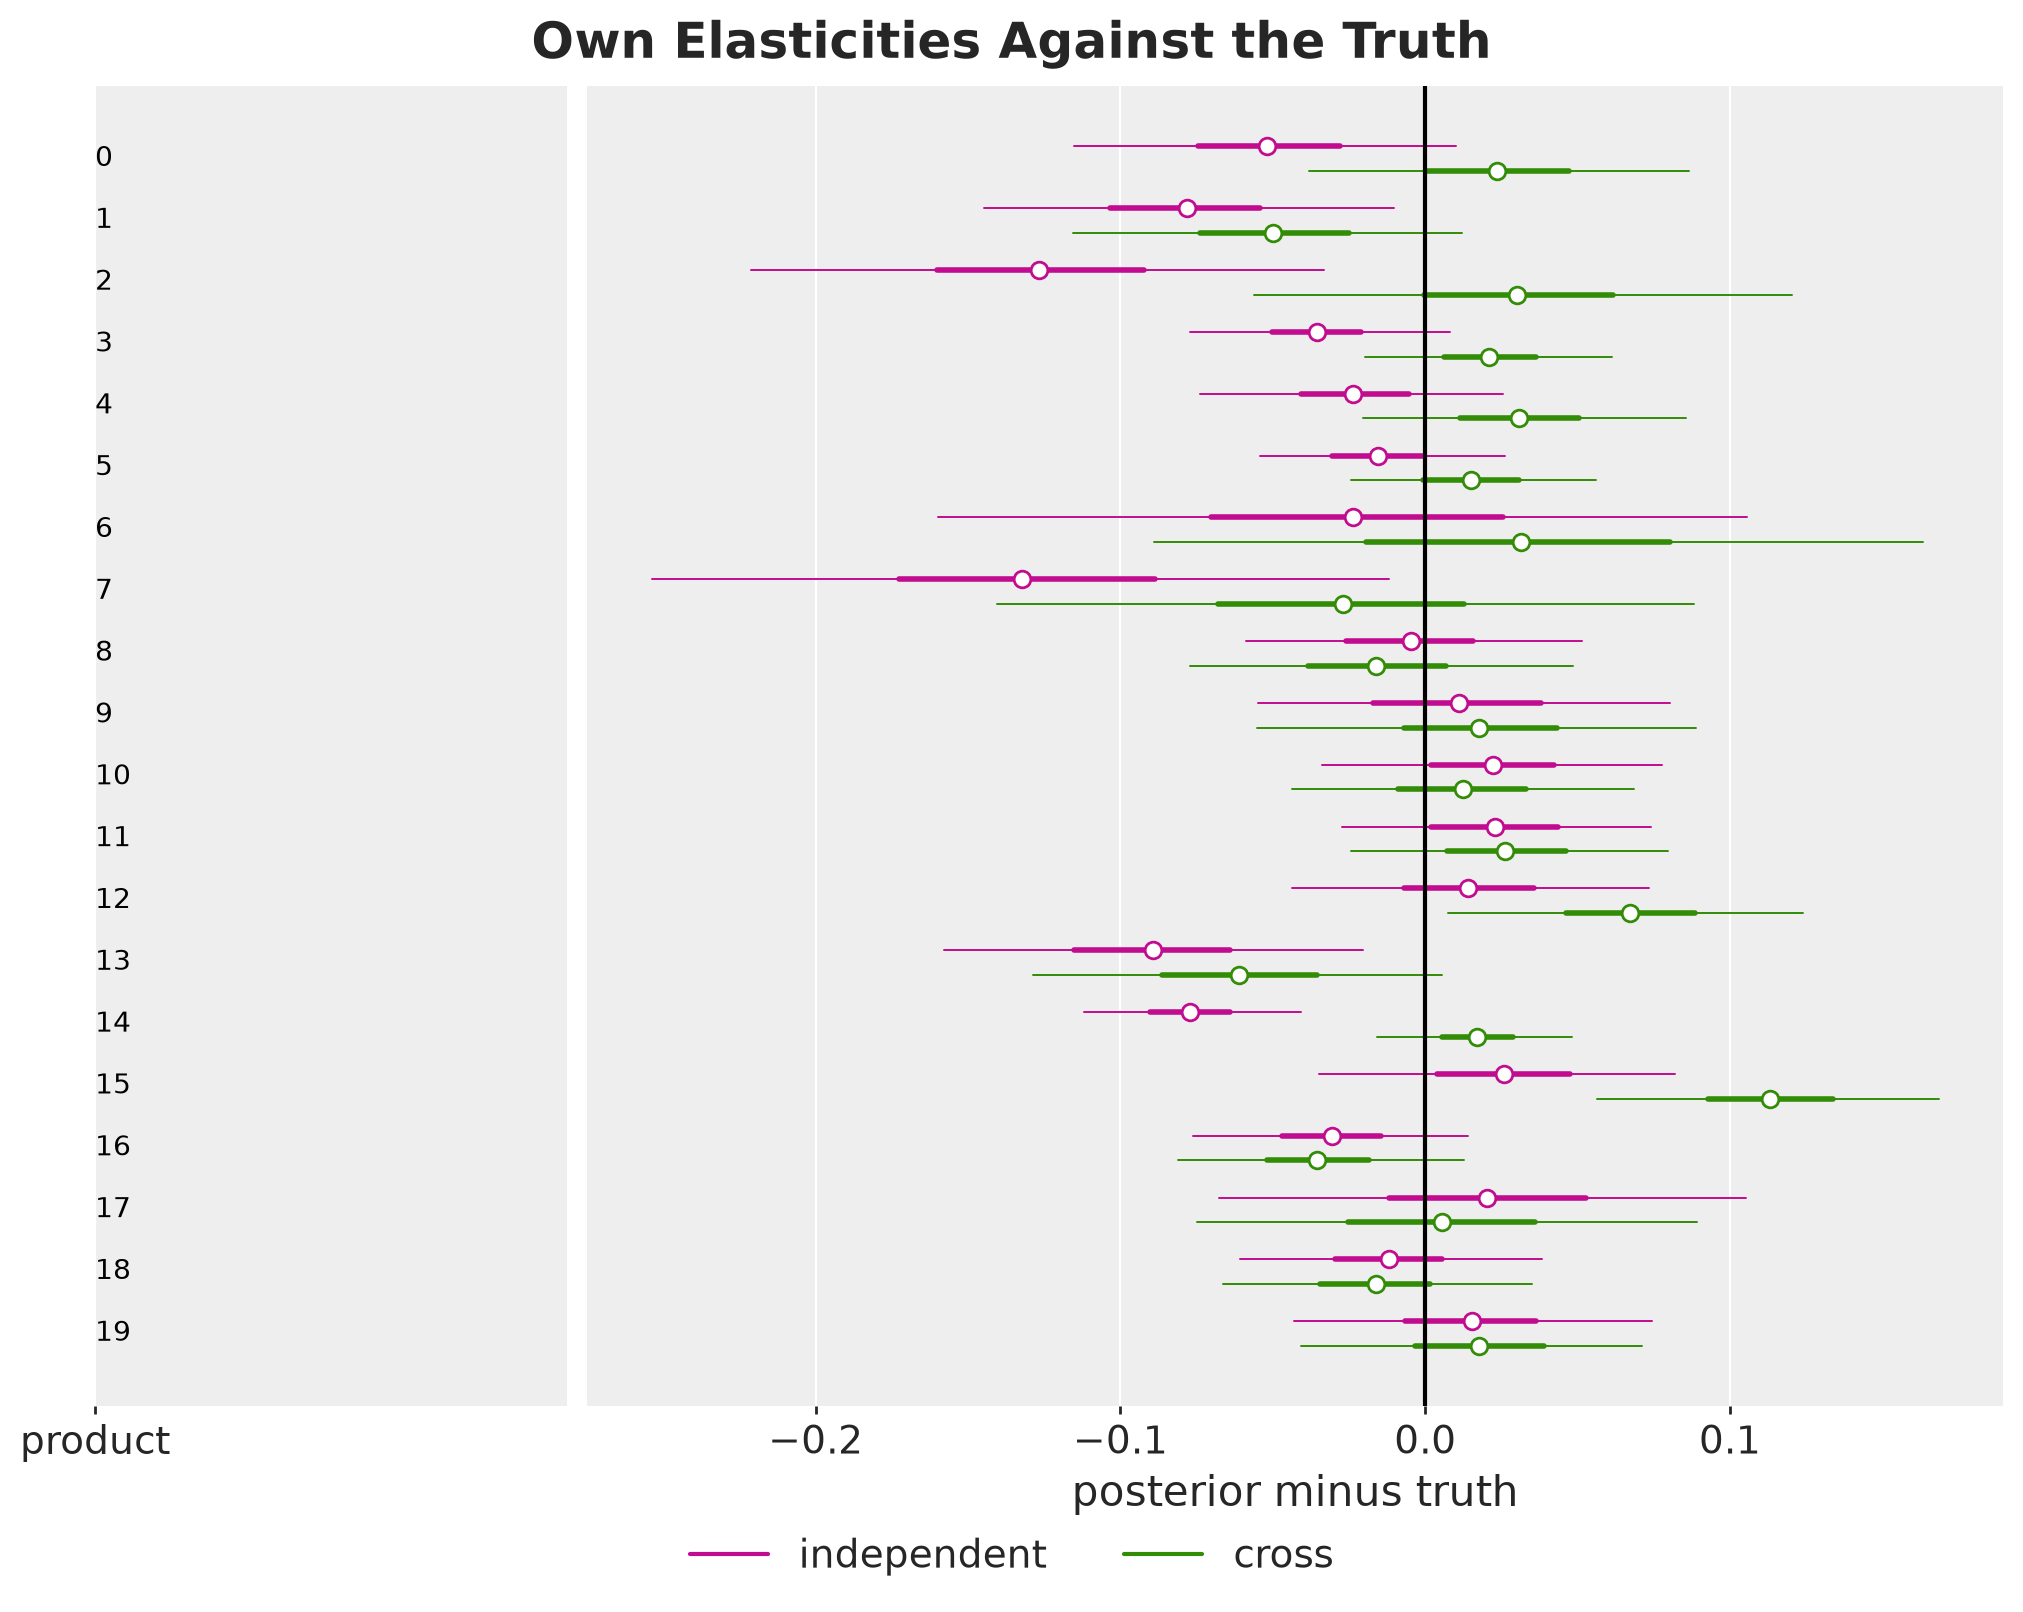

In [27]:
def minus_truth(model: Model, site: str, dim: str, labels: list[str]) -> xr.Dataset:
    """Posterior draws of `site` under `model` minus the true value."""
    error = draws[model].parameters[site] - true_params[site]
    return xr.Dataset({site: (("sample", dim), error)}, coords={dim: labels})


product_labels = [str(product) for product in range(setup.n_products)]
pc = az.plot_forest(
    {
        model: minus_truth(model, "elasticity", "product", product_labels)
        for model in models
    },
    sample_dims=["sample"],
    labels=["product"],
    color=[MODEL_COLORS[model] for model in models],
    figure_kwargs={"figsize": (10, 8)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black")
ax.set(xlabel="posterior minus truth")
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Own Elasticities Against the Truth", fontsize=18, fontweight="bold"
);

The dots are the posterior means and the thick and thin bars the $50\%$ and $94\%$ intervals. The following table averages the posterior mean minus the truth over the four products of each group, for both models.

In [28]:
def by_group(values: Float[Array, " n"], groups: Int[Array, " n"]) -> dict[str, float]:
    """Mean of the entries of each group, given the group index of every entry."""
    return {
        f"group {group + 1}": float(values[groups == group].mean())
        for group in range(setup.n_groups)
    }


pl.DataFrame(
    [
        {
            "model": model.value,
            **by_group(
                (
                    draws[model].parameters["elasticity"] - true_params["elasticity"]
                ).mean(axis=0),
                panel.product_to_group,
            ),
        }
        for model in models
    ]
)

model,group 1,group 2,group 3,group 4,group 5
str,f64,f64,f64,f64,f64
"""independent""",-0.073,-0.049,0.013,-0.032,-0.002
"""cross""",0.006,0.013,0.010,0.034,-0.007


The two models differ in the groups with cannibalization.

- **Cross model.** The intervals cover zero for $18$ of the $20$ products. On average over a group, the posterior means lie within $0.01$ of the truth in groups $1$, $2$, $3$ and $5$, and $0.03$ above it in group $4$.
- **Independent model.** The intervals cover zero for $15$ products. The own elasticities of groups $1$ and $2$ are $0.07$ and $0.06$ too negative on average, and those of group $4$ are $0.03$ too negative. Those of groups $3$ and $5$, the groups without cannibalization, are within $0.02$ of the truth.

This bias is consistent with a level that follows the sibling dips down. Measured against a level that is too low, the lift of an own promotion week looks larger than it is.

The widest intervals belong to products $6$ and $7$ under both models. These are the two products with a single promotion week in the history.

Next, we plot the cross elasticities of the cross model in the same form.

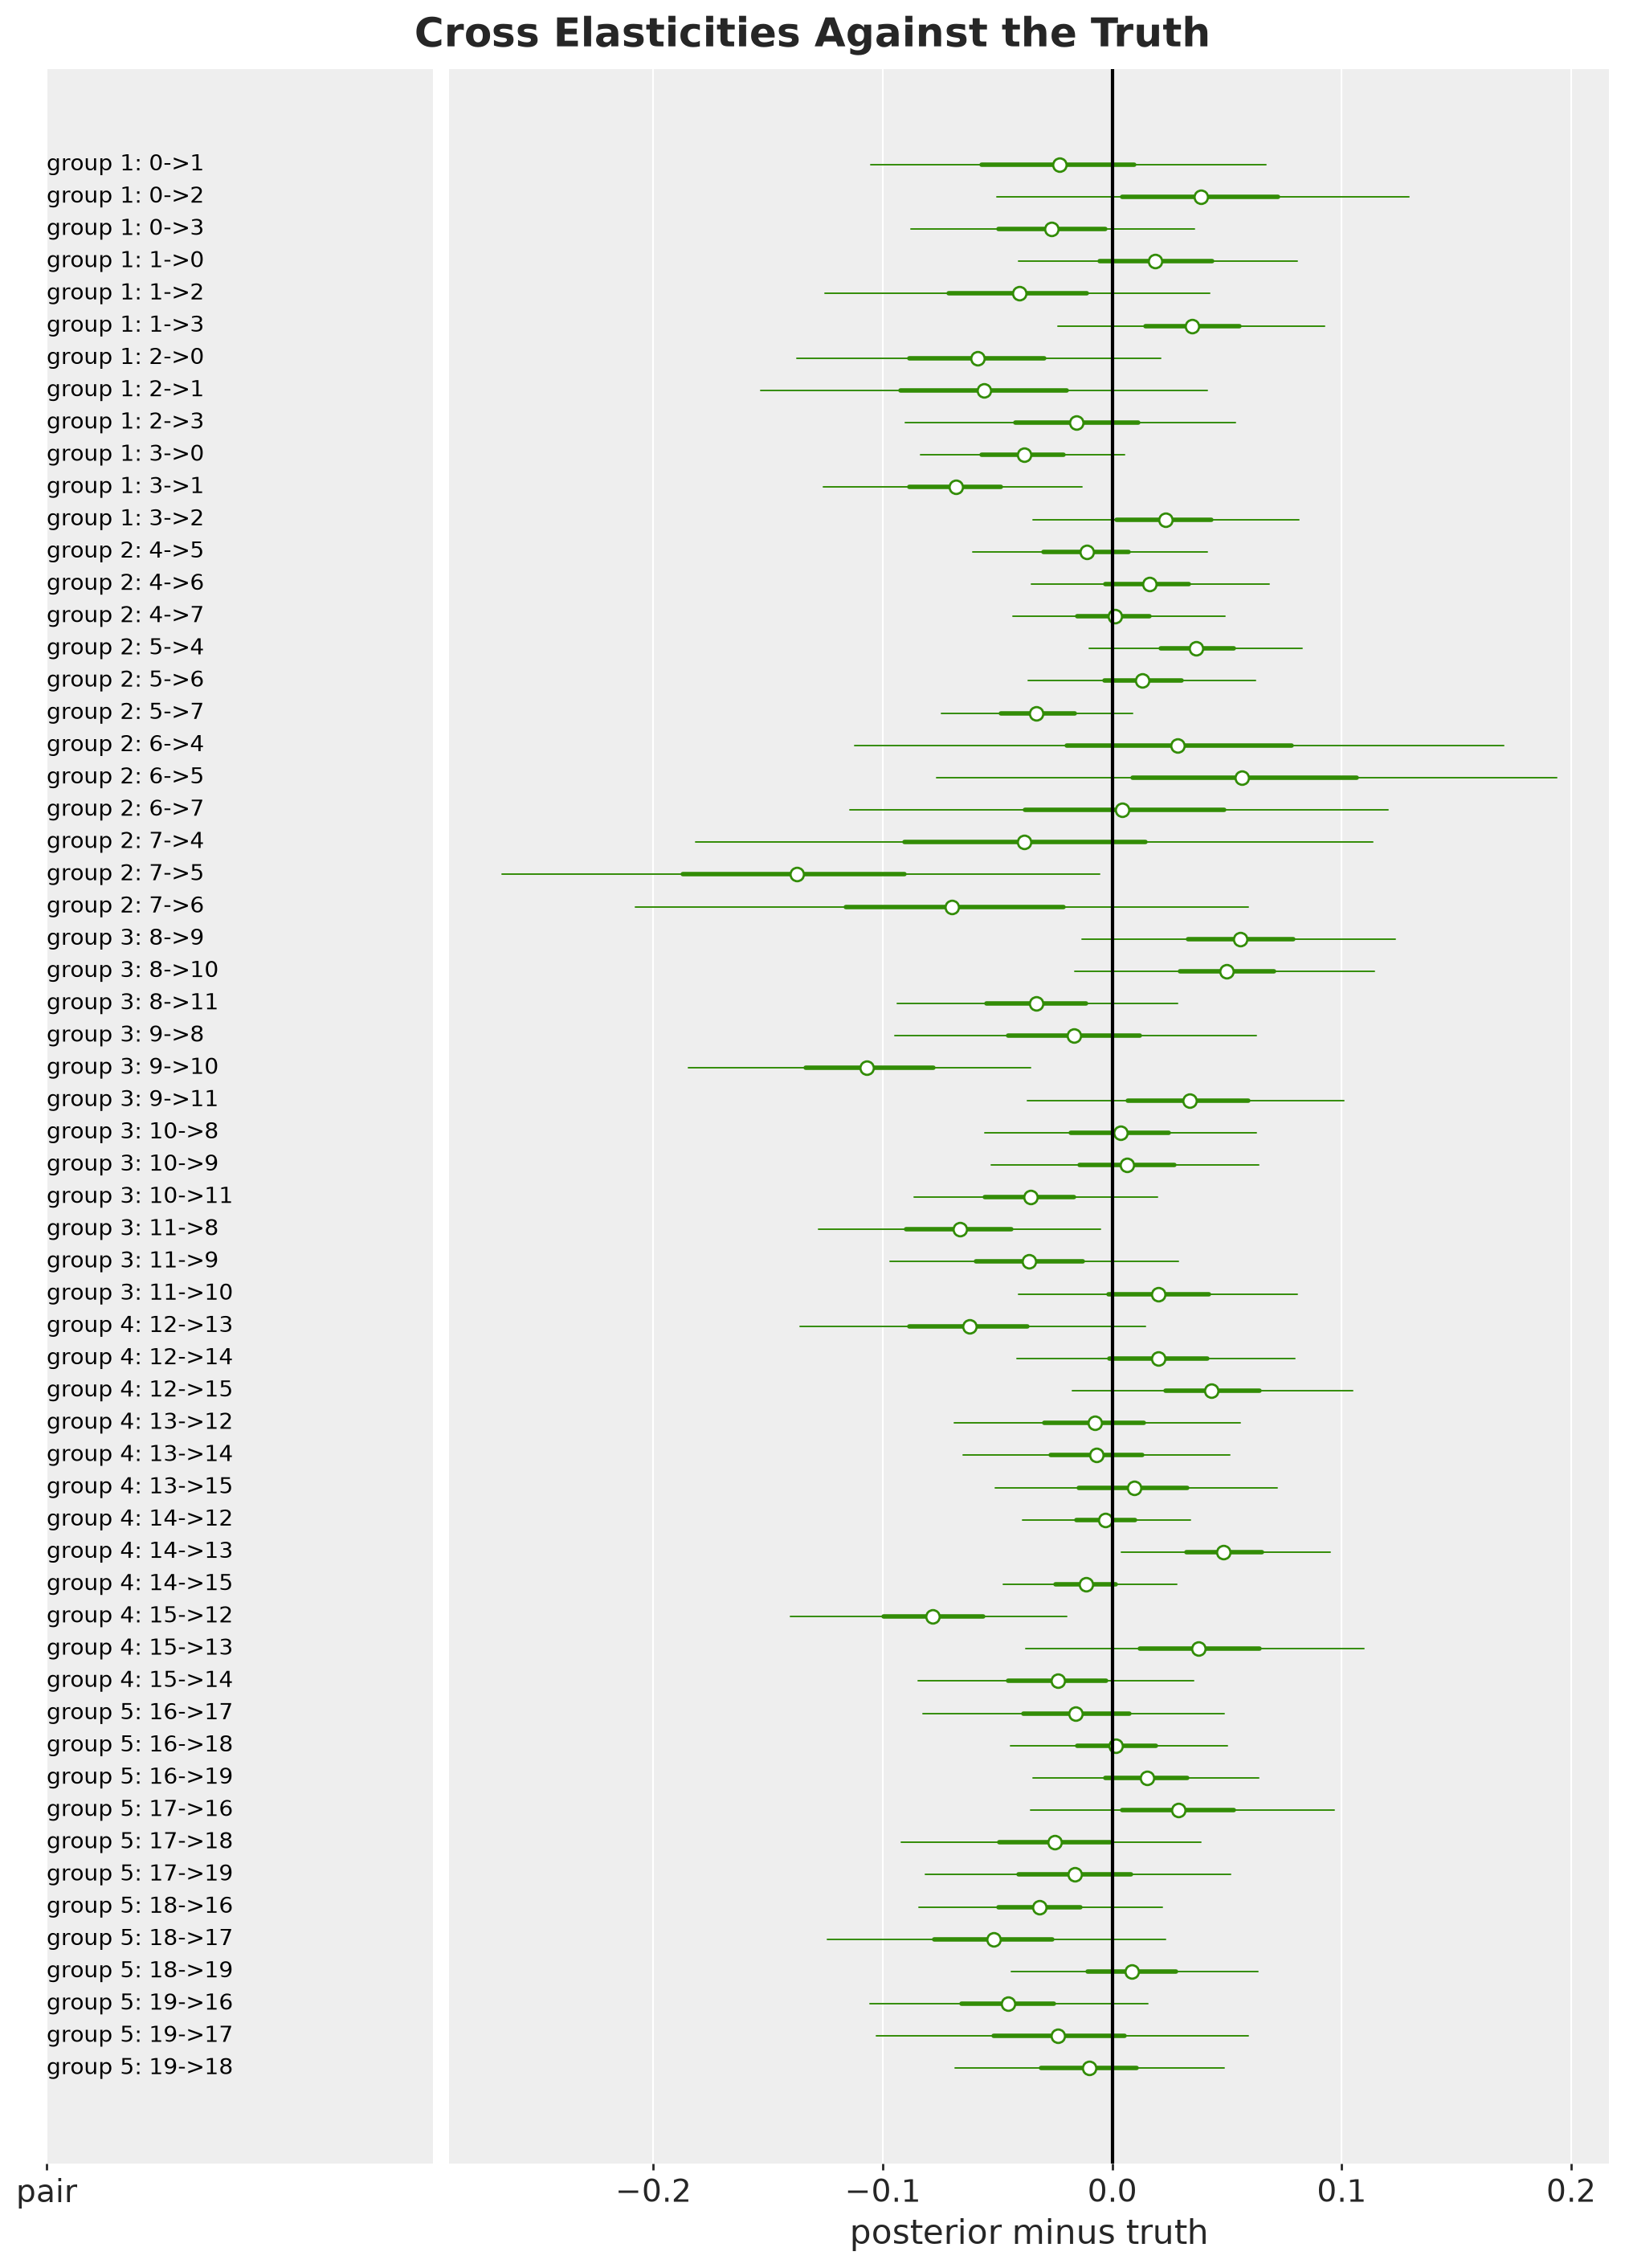

In [29]:
pair_group = panel.product_to_group[panel.pair_rows]
pair_labels = [
    f"group {group + 1}: {source}->{target}"
    for group, source, target in zip(
        pair_group.tolist(),
        panel.pair_rows.tolist(),
        panel.pair_cols.tolist(),
        strict=True,
    )
]

pc = az.plot_forest(
    {Model.CROSS: minus_truth(Model.CROSS, "cross_elasticity", "pair", pair_labels)},
    sample_dims=["sample"],
    labels=["pair"],
    color=[MODEL_COLORS[Model.CROSS]],
    figure_kwargs={"figsize": (10, 14)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black")
ax.set(xlabel="posterior minus truth")
pc.viz["figure"].item().suptitle(
    "Cross Elasticities Against the Truth", fontsize=18, fontweight="bold"
);

A label `k->j` is the response of the demand of product `j` to the price of product `k`. The intervals cover the truth for $54$ of the $60$ pairs, or $90\%$, a little below the $94\%$ of a calibrated interval.

The six widest intervals belong to pairs that start at product $6$ or $7$. These are again the two products with a single promotion week.

Next, we compare each group with its true cross elasticity. For every posterior draw we average the $12$ cross elasticities of a group, which gives one posterior distribution per group. The dashed lines are the true values.

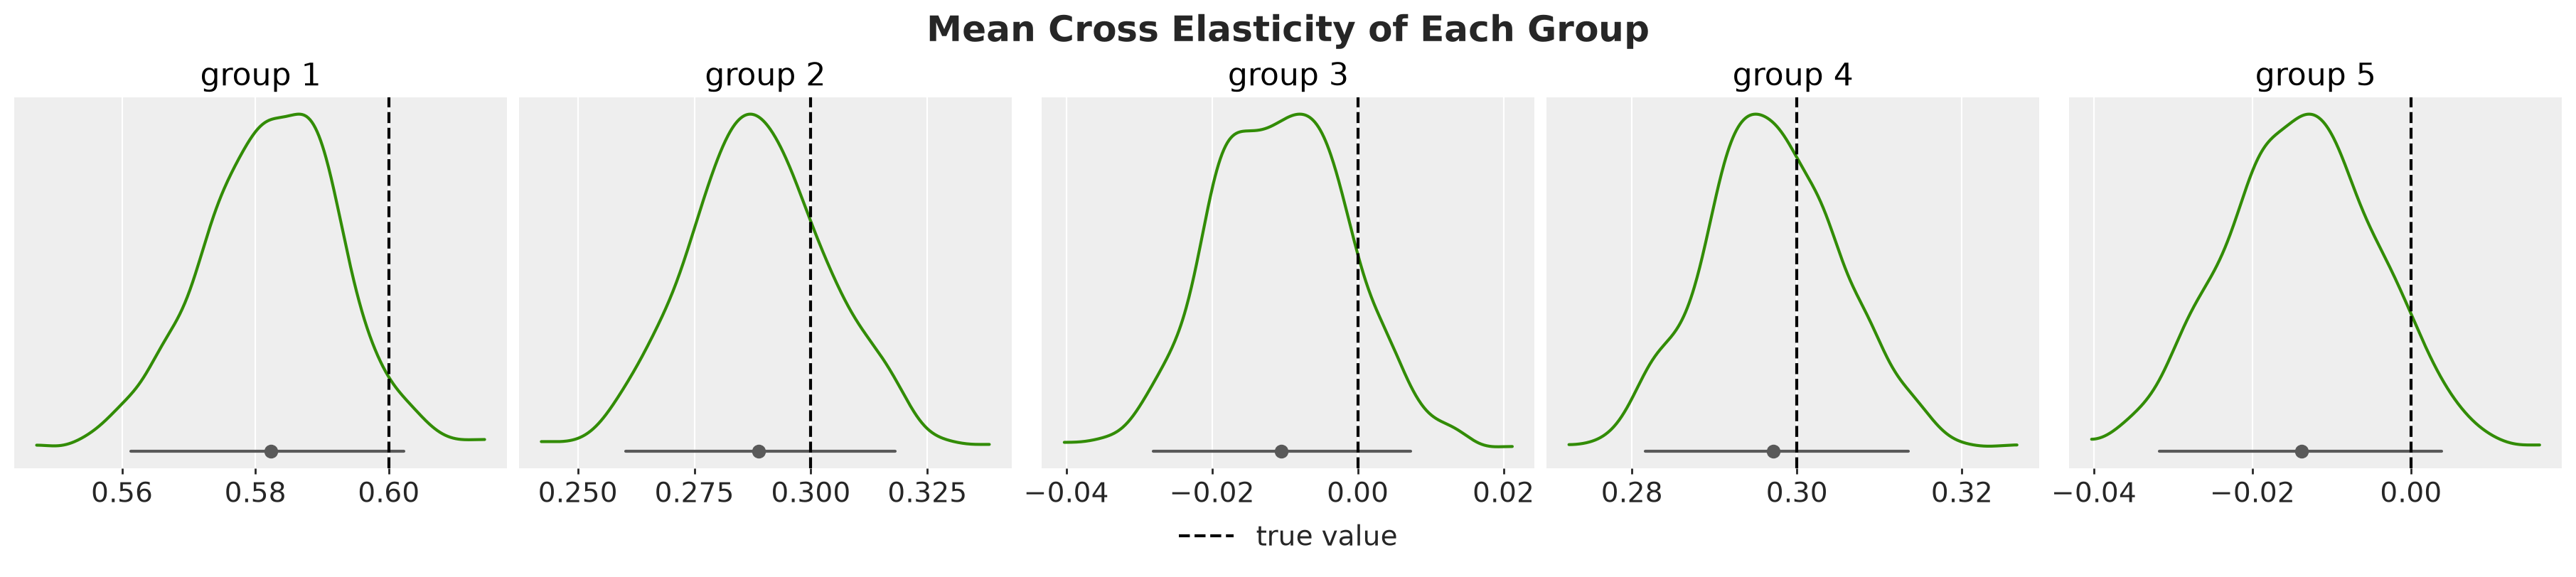

In [30]:
group_labels = [f"group {group + 1}" for group in range(setup.n_groups)]
# (sample, group): the mean of the 12 cross elasticities of each group in every draw
cross_by_group = jnp.stack(
    [
        draws[Model.CROSS]
        .parameters["cross_elasticity"][:, pair_group == group]
        .mean(1)
        for group in range(setup.n_groups)
    ],
    axis=-1,
)

pc = az.plot_dist(
    xr.Dataset(
        {"cross elasticity": (("sample", "group"), cross_by_group)},
        coords={"group": group_labels},
    ),
    sample_dims=["sample"],
    kind="kde",
    col_wrap=setup.n_groups,
    visuals={
        "dist": {"color": MODEL_COLORS[Model.CROSS]},
        "point_estimate_text": False,
    },
    figure_kwargs={"figsize": (18, 4), "sharey": False},
)

for group, label in enumerate(group_labels):
    ax = pc.get_target("cross elasticity", {"group": label})
    ax.axvline(
        setup.group_cross[group], color="black", linestyle="--", label="true value"
    )
    ax.set(title=label)

pc.viz["figure"].item().legend(
    *ax.get_legend_handles_labels(), loc="outside lower center"
)
pc.viz["figure"].item().suptitle(
    "Mean Cross Elasticity of Each Group", fontsize=18, fontweight="bold"
);

The posterior means of the groups are $0.58$, $0.29$, $-0.01$, $0.30$ and $-0.01$, and every $94\%$ interval contains the true value. The model finds the cannibalization of groups $1$, $2$ and $4$, a little below the truth in groups $1$ and $2$ as we expect from the shrinkage toward zero, and finds none in groups $3$ and $5$.

### Level and Concentration

Next, we look at the families of parameters. For each family and each model, the next figure shows two quantities:

- **Coverage of the truth.** The share of true values inside the $94\%$ interval. A calibrated posterior covers about $94\%$ of them.
- **Posterior mean over the truth.** The median ratio of the posterior mean to the true value, over the entries whose true value is not zero. An unbiased posterior mean gives a ratio of about one.

The dashed lines mark these two reference values. The function `plot_metric_bars` draws one bar panel per quantity, with one color per model, and we use it for the next figures too.

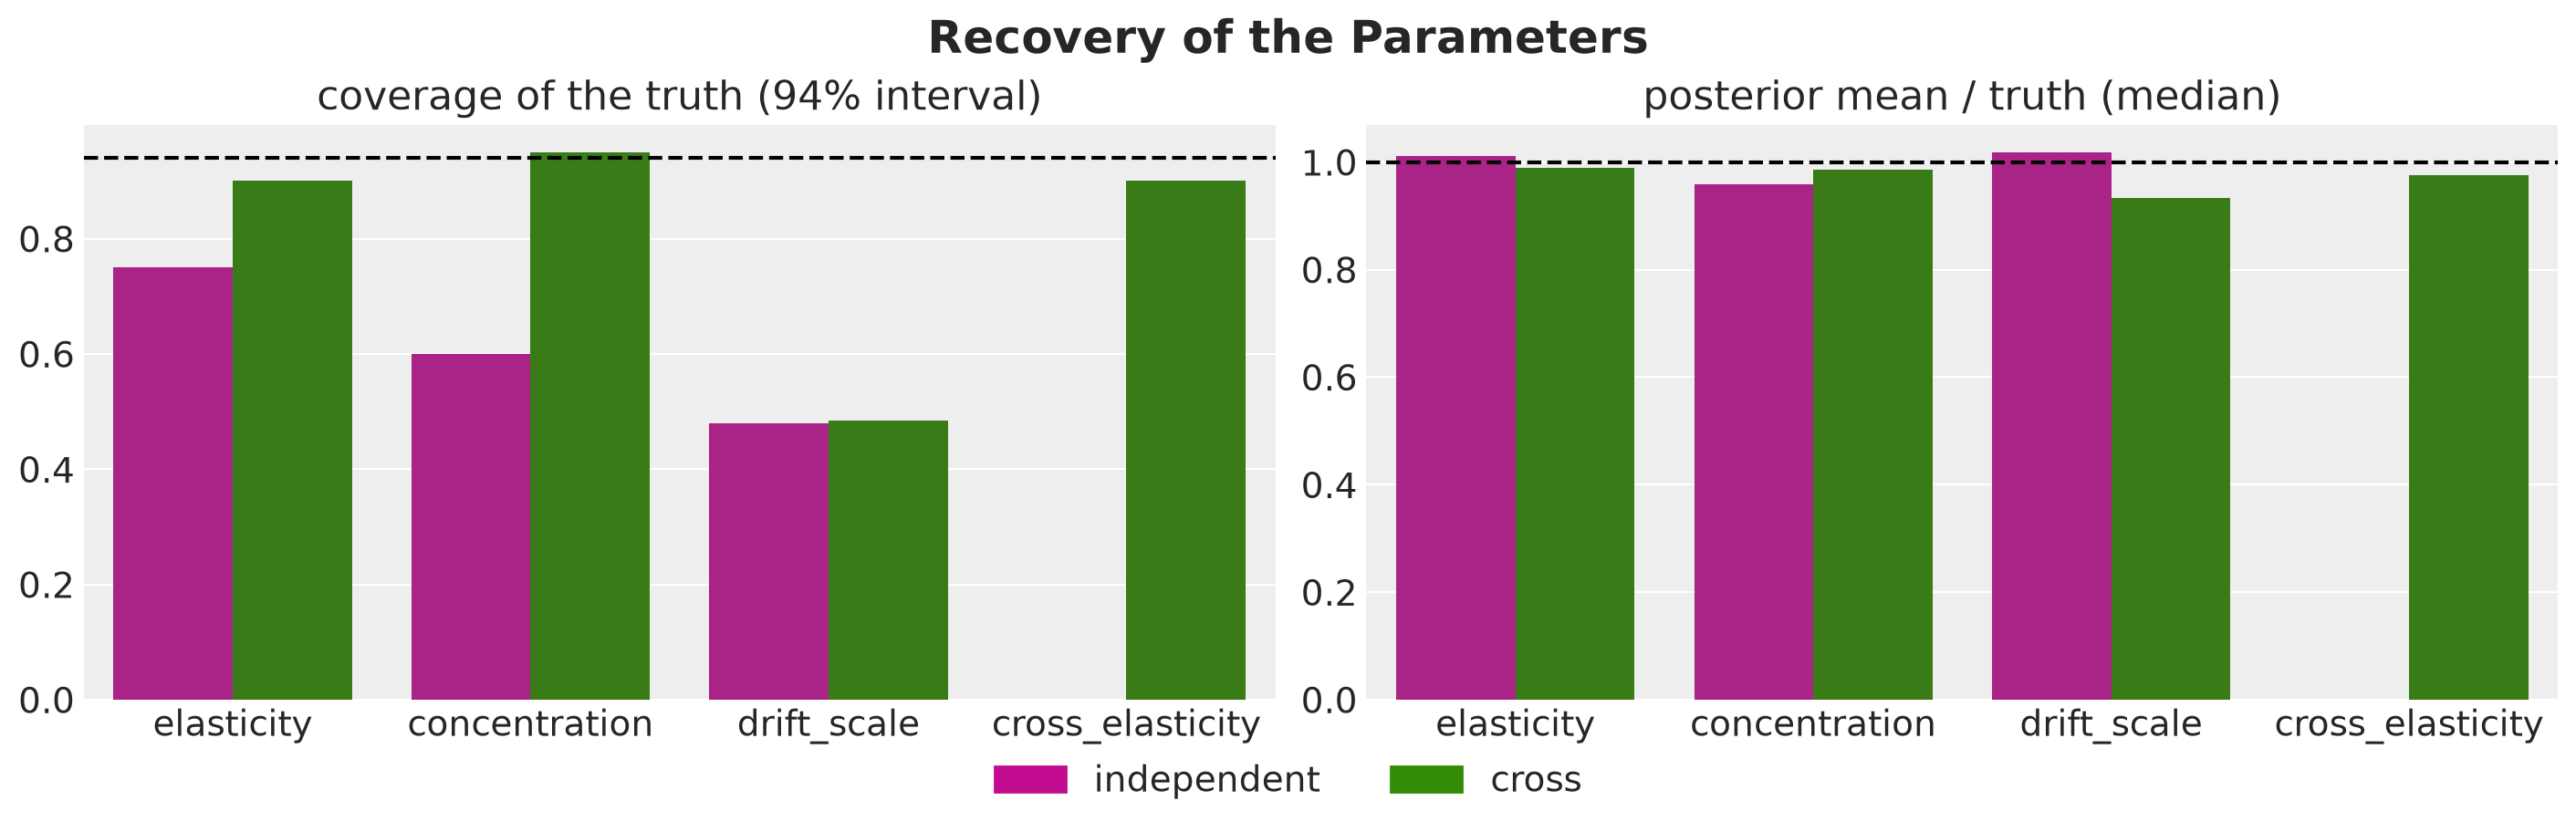

In [31]:
def coverage_of_truth(
    draws: Float[Array, " sample *shape"], truth: Float[Array, " *shape"]
) -> float:
    """Share of the entries whose true value lies inside the central interval."""
    tail = (1 - CI_PROB) / 2
    lower, upper = jnp.quantile(draws, jnp.array([tail, 1 - tail]), axis=0)
    return float(((truth >= lower) & (truth <= upper)).mean())


def recovery_ratio(
    draws: Float[Array, " sample *shape"], truth: Float[Array, " *shape"]
) -> float:
    """Median over the entries of the posterior mean divided by the truth."""
    nonzero = truth != 0
    return float(jnp.median(draws.mean(axis=0)[nonzero] / truth[nonzero]))


def plot_metric_bars(
    frame: pl.DataFrame,
    references: dict[str, float | None],
    x: str,
    title: str,
    ncols: int = 2,
) -> None:
    """One bar panel per column of `references`, with one color per model."""
    nrows = math.ceil(len(references) / ncols)
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(7 * ncols, 4.5 * nrows),
        squeeze=False,
        layout="constrained",
    )

    for ax, (metric, reference) in zip(axes.flat, references.items(), strict=True):
        sns.barplot(
            data=frame,
            x=x,
            y=metric,
            hue="model",
            hue_order=[model.value for model in models],
            palette=MODEL_COLORS,
            legend=False,
            ax=ax,
        )

        if reference is not None:
            ax.axhline(reference, color="black", linestyle="--")

        ax.set(title=metric, xlabel="", ylabel="")

    handles = [Patch(color=MODEL_COLORS[model], label=model) for model in models]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(models))
    fig.suptitle(title, fontsize=18, fontweight="bold")


COVERAGE = f"coverage of the truth ({CI_PROB:.0%} interval)"
RATIO = "posterior mean / truth (median)"
recovery = pl.DataFrame(
    [
        {
            "model": model.value,
            "parameter": site,
            COVERAGE: coverage_of_truth(
                draws[model].parameters[site], true_params[site]
            ),
            RATIO: recovery_ratio(draws[model].parameters[site], true_params[site]),
        }
        for model in models
        for site in ["elasticity", "concentration", "drift_scale", "cross_elasticity"]
        if site in draws[model].parameters
    ]
)
plot_metric_bars(
    recovery,
    {COVERAGE: CI_PROB, RATIO: 1.0},
    x="parameter",
    title="Recovery of the Parameters",
);

For the parameters we see the following.

- **Cross model.** The own and the cross elasticities are covered at $90\%$ and the concentration at $95\%$, and their posterior means are within $3\%$ of the truth. The drift scale is $7\%$ low, and its intervals cover the truth for only about half of the series. These intervals are too narrow, with the mean-field part of the guide as the likely cause.
- **Independent model.** The own elasticities are covered at $75\%$ and the concentration at $60\%$, and the concentration is $4\%$ low. The drift scale has the same coverage problem as under the cross model.

Next, we look at the level of every series at the end of the history, the quantity the forecast starts from. The next figure shows the coverage of the true level by the $94\%$ interval and the mean error of the posterior mean of the level on the log scale, the bias.

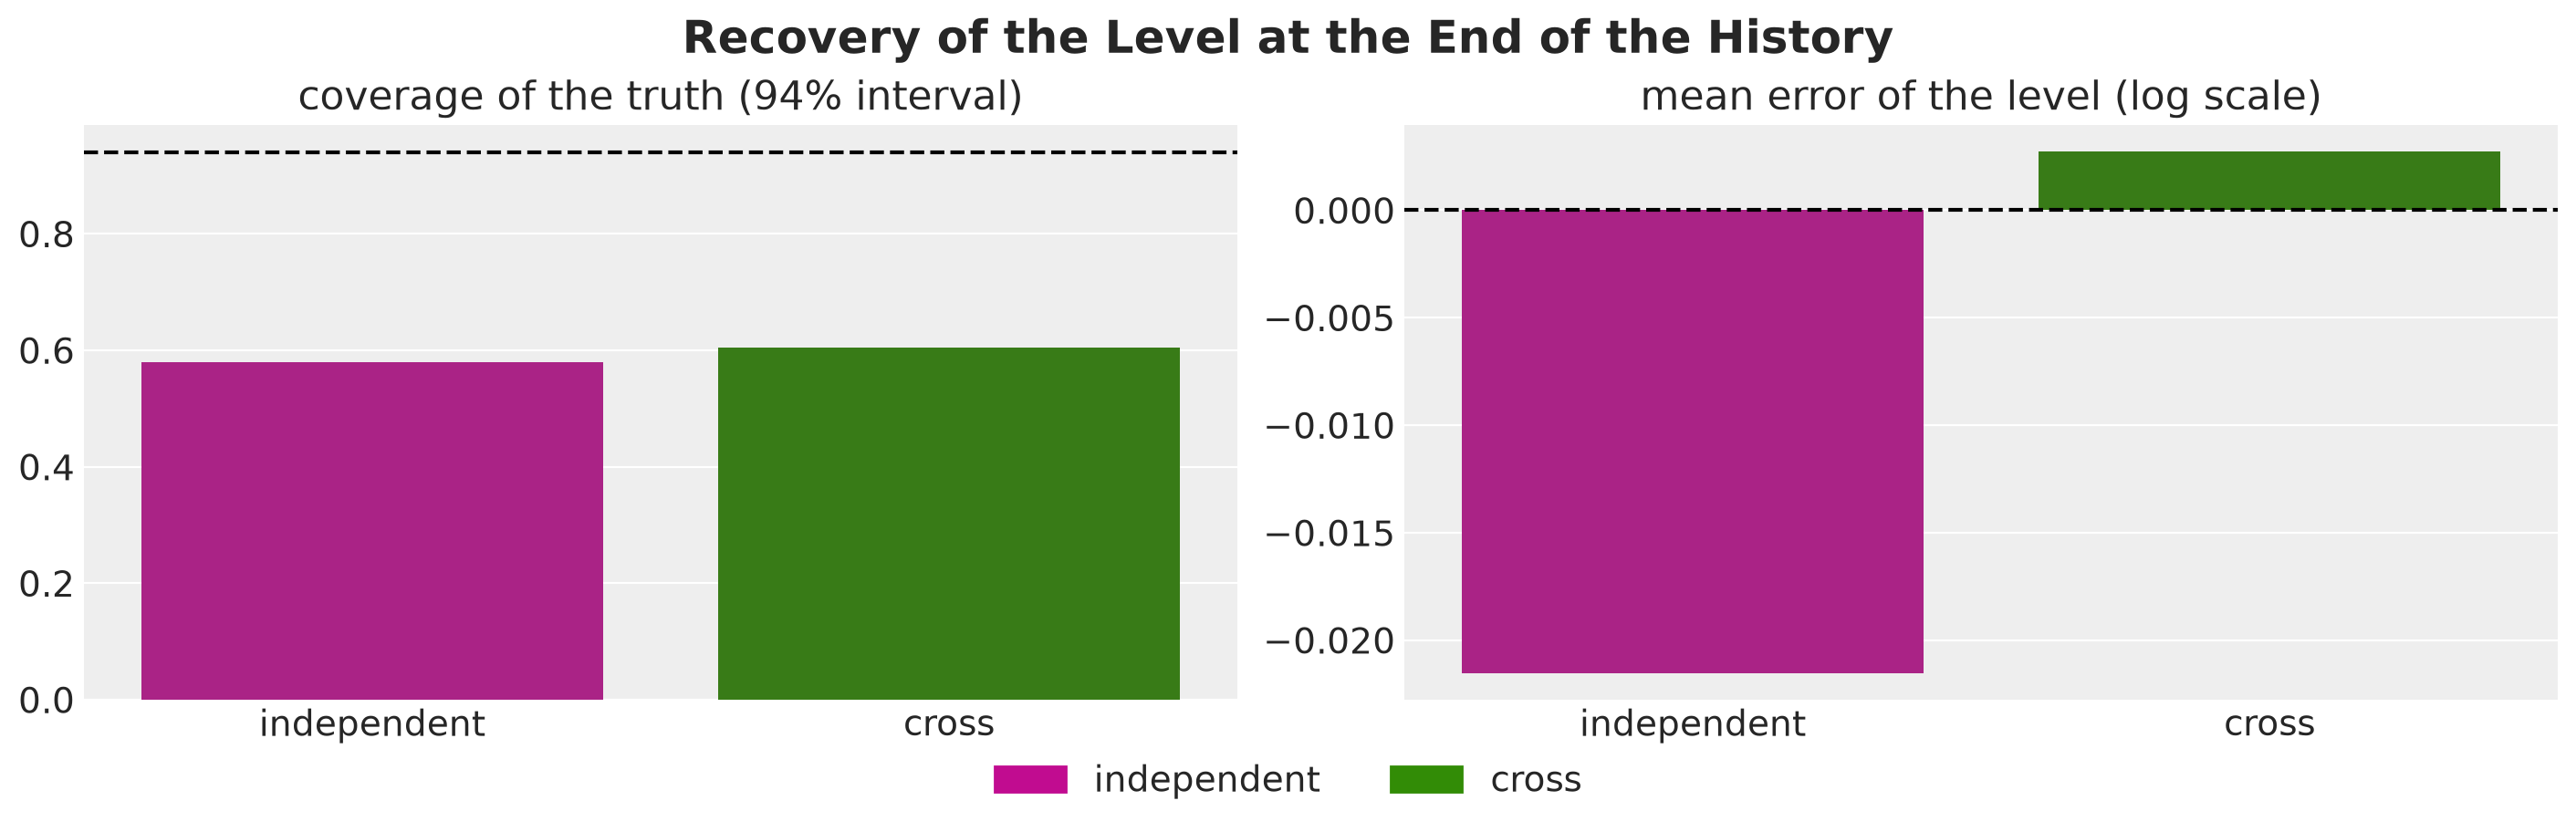

In [32]:
level_end_true = true_params["intercept"] + drift_true.sum(axis=0)
level_error = {
    model: draws[model].level_end.mean(axis=0) - level_end_true for model in models
}
MEAN_ERROR = "mean error of the level (log scale)"

plot_metric_bars(
    pl.DataFrame(
        [
            {
                "model": model.value,
                COVERAGE: coverage_of_truth(draws[model].level_end, level_end_true),
                MEAN_ERROR: float(level_error[model].mean()),
            }
            for model in models
        ]
    ),
    {COVERAGE: CI_PROB, MEAN_ERROR: 0.0},
    x="model",
    title="Recovery of the Level at the End of the History",
);

The $94\%$ intervals of the level cover the truth for only $58\%$ of the series under the independent model and $61\%$ under the cross model. The guide is overconfident about the level of every series, which is what we expect from its mean-field part.

The mean error of the cross model is $0.003$ on the log scale, close to zero. The independent model is $0.022$ low on average, that is, about $2\%$ of the level.

Finally, we split two quantities by group, since the groups differ in how much cannibalization their history holds. The quantities are the ratio of the posterior mean of the concentration to the truth and the mean error of the level.

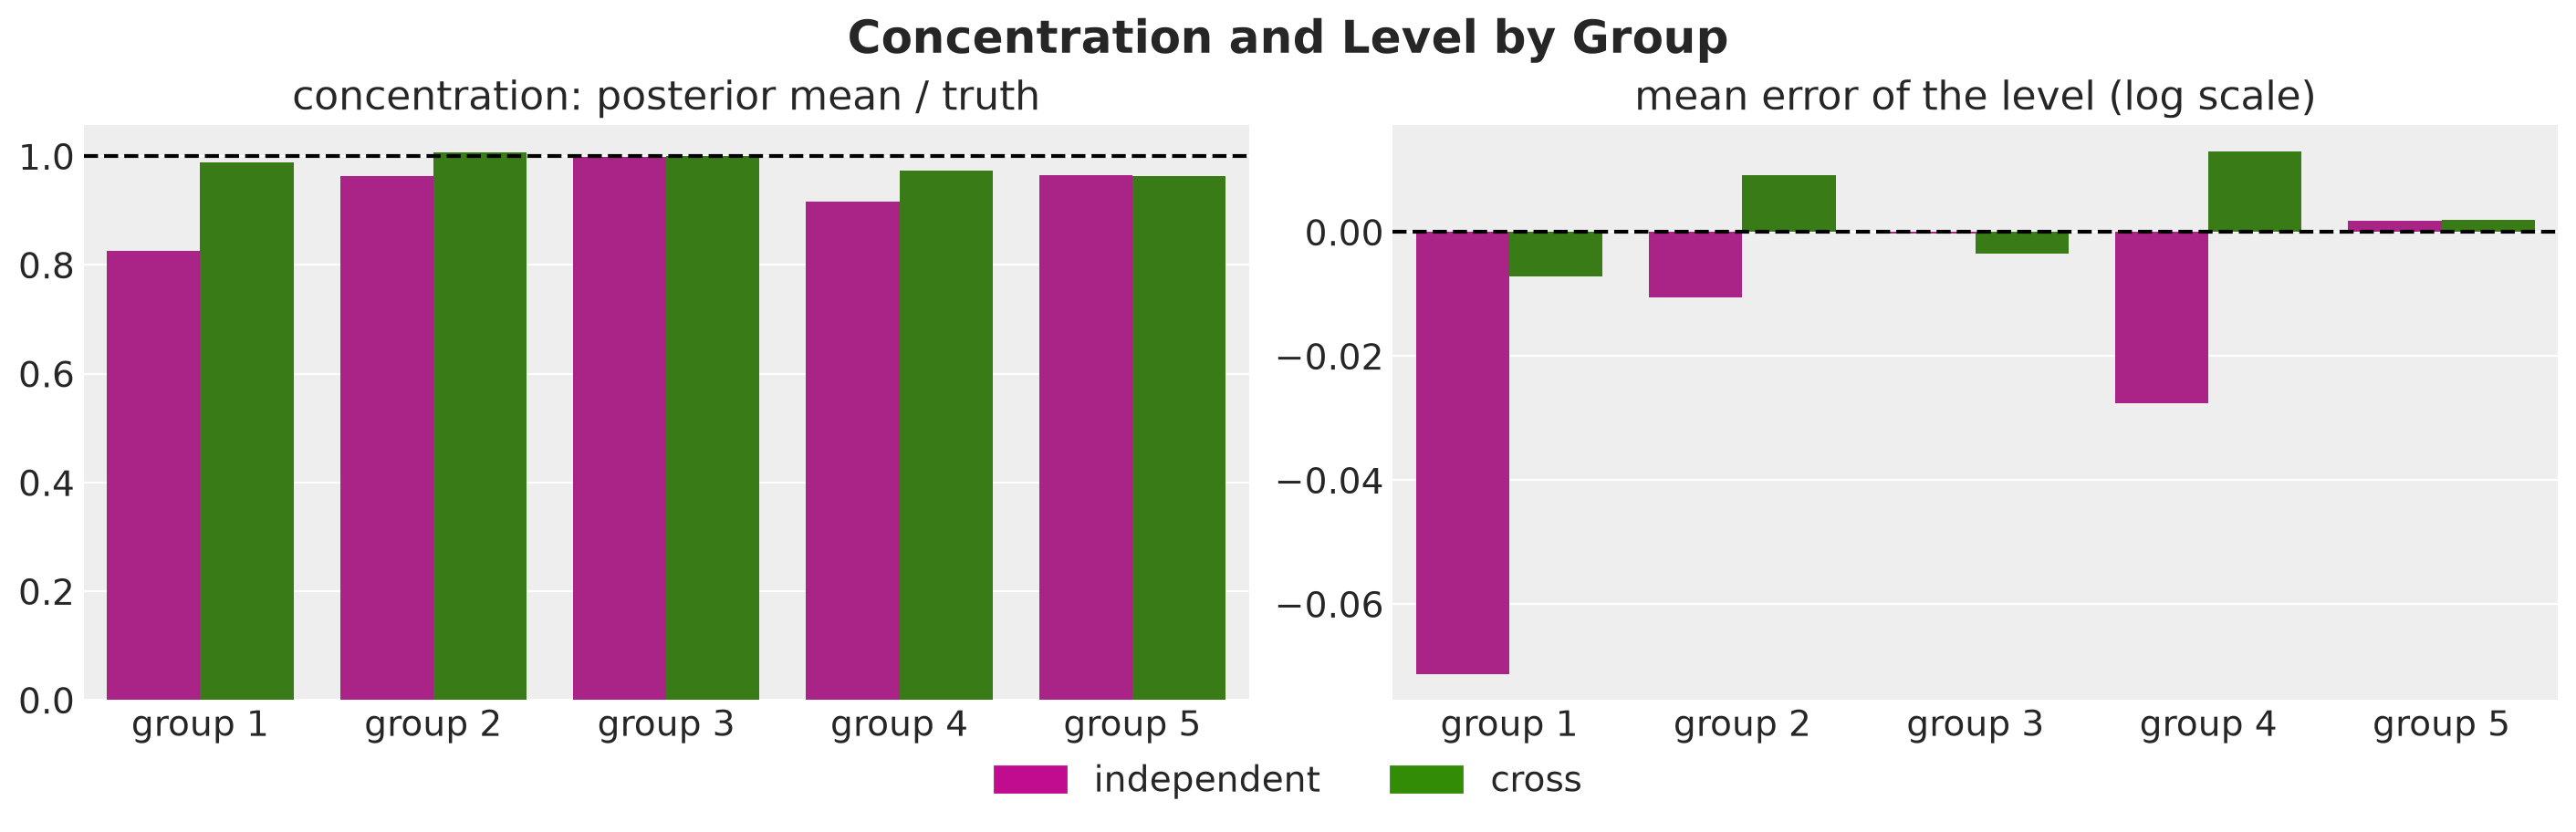

In [33]:
series_group = panel.product_to_group[panel.series_to_product]
CONCENTRATION_RATIO = "concentration: posterior mean / truth"

plot_metric_bars(
    pl.DataFrame(
        [
            {
                "model": model.value,
                "group": label,
                CONCENTRATION_RATIO: concentration_ratio,
                MEAN_ERROR: level_bias,
            }
            for model in models
            for label, concentration_ratio, level_bias in zip(
                group_labels,
                by_group(
                    draws[model].parameters["concentration"].mean(axis=0)
                    / true_params["concentration"],
                    panel.product_to_group,
                ).values(),
                by_group(level_error[model], series_group).values(),
                strict=True,
            )
        ]
    ),
    {CONCENTRATION_RATIO: 1.0, MEAN_ERROR: 0.0},
    x="group",
    title="Concentration and Level by Group",
);

The split by group shows where the independent model goes wrong.

- **Concentration.** Under the independent model it is $17\%$ low in group $1$, where the sibling dips are the largest, and $8\%$ low in group $4$. In groups $3$ and $5$, which have no cannibalization, it is within $4\%$ of the truth, as under the cross model. This is consistent with a model that treats the unexplained dips as noise.
- **Level.** The independent model is $0.07$ low in group $1$ and $0.03$ low in group $4$, and within $0.01$ of the truth in the other three groups. The cross model is within $0.015$ of the truth in every group.

We come back to the overconfidence about the level in the *Out of Sample Evaluation* section, where it shows up as a cost. We look at the bias of the independent model in the *Demand Scenarios* section.

## Posterior Predictive Checks

Before we look at the forecast, we check the fit on the history. We draw $300$ predictive paths of each model over the history and compute their CRPS over all days and all $200$ series. We plot the paths of the cross model for the four series of the prior predictive check.

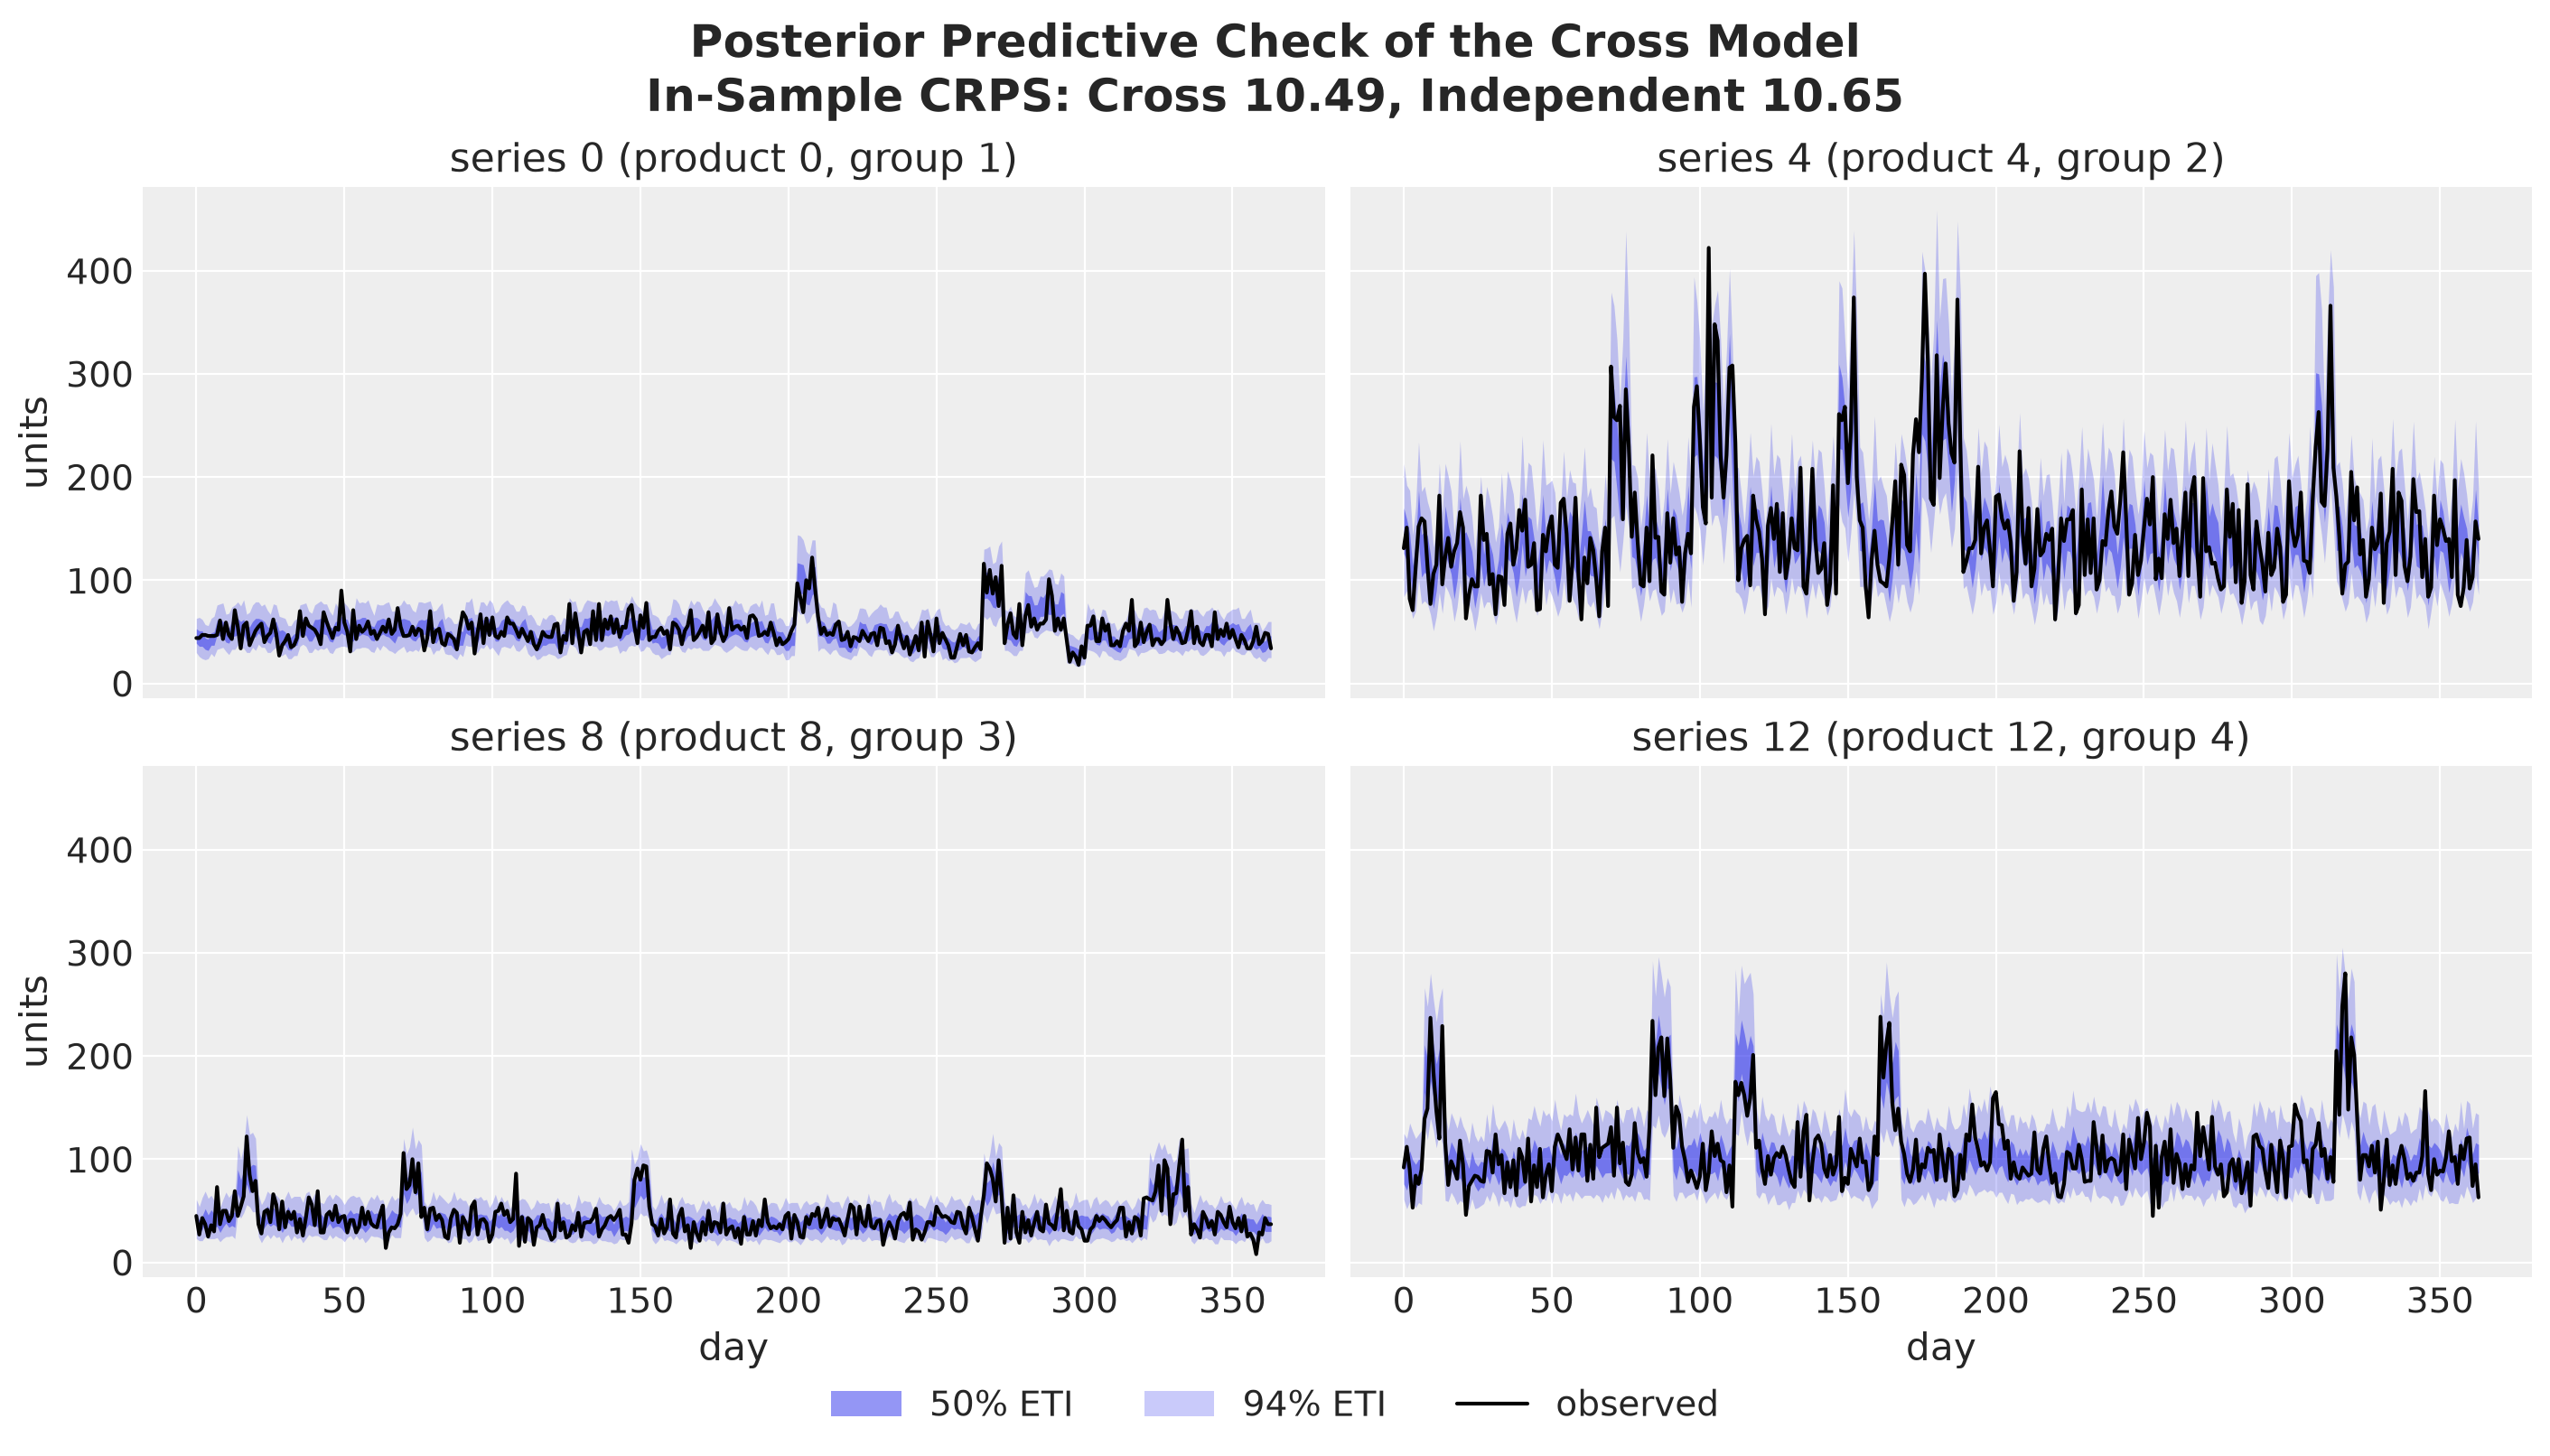

In [34]:
data_float = data.astype(jnp.float32)
ppc_obs, crps_in_sample = {}, {}

for model in models:
    rng_key, key_latent, key_ppc = random.split(rng_key, 3)
    latent = draw_posterior(
        key_latent, guides[model], svi_results[model].params, num_samples=300
    )
    ppc_obs[model] = predict_in_sample(
        key_ppc, models[model], latent, covariates_train, batch_size=100
    ).astype(jnp.float32)
    crps_in_sample[model] = float(crps_empirical(ppc_obs[model], data_float).mean())
    # a predictive that ignores the fitted increments would fail this check
    assert 0.90 < float(eval_coverage(ppc_obs[model], data_float, alpha=CI_PROB)) < 0.98

plot_predictive_check(
    ppc_obs[Model.CROSS][..., check_series],
    "Posterior Predictive Check of the Cross Model\n"
    f"In-Sample CRPS: Cross {crps_in_sample[Model.CROSS]:.2f}, "
    f"Independent {crps_in_sample[Model.INDEPENDENT]:.2f}",
);

The bands follow the level of every series and show the bumps of the own promotion weeks. The $94\%$ band contains $95\%$ of the observations under both models, and the in-sample CRPS is $10.49$ for the cross model and $10.65$ for the independent model.

### Forecast Calibration

The last check compares the width of the forecast of each model with the width of the evaluation scenarios. For every series and day we divide the standard deviation of the model's scenarios by the standard deviation of the evaluation scenarios. A ratio of one means that the forecast is as wide as the evaluation scenarios on a single day.

We compute the same ratio for the total demand of a series over the $15$ days, which also depends on how the days of a path move together. We also score the one realized future with the coverage of the $94\%$ interval and the CRPS. The next figure shows six quantities:

- **The standard deviation ratio**, as the median over all series-days, over the siblings in the promotion week, and over the horizon totals of the series. The dashed line is one.
- **The coverage** of the realized future by the $94\%$ interval. The dashed line is $94\%$.
- **The CRPS** on the realized future.
- **The share of series-days** with a standard deviation ratio above $1.2$.

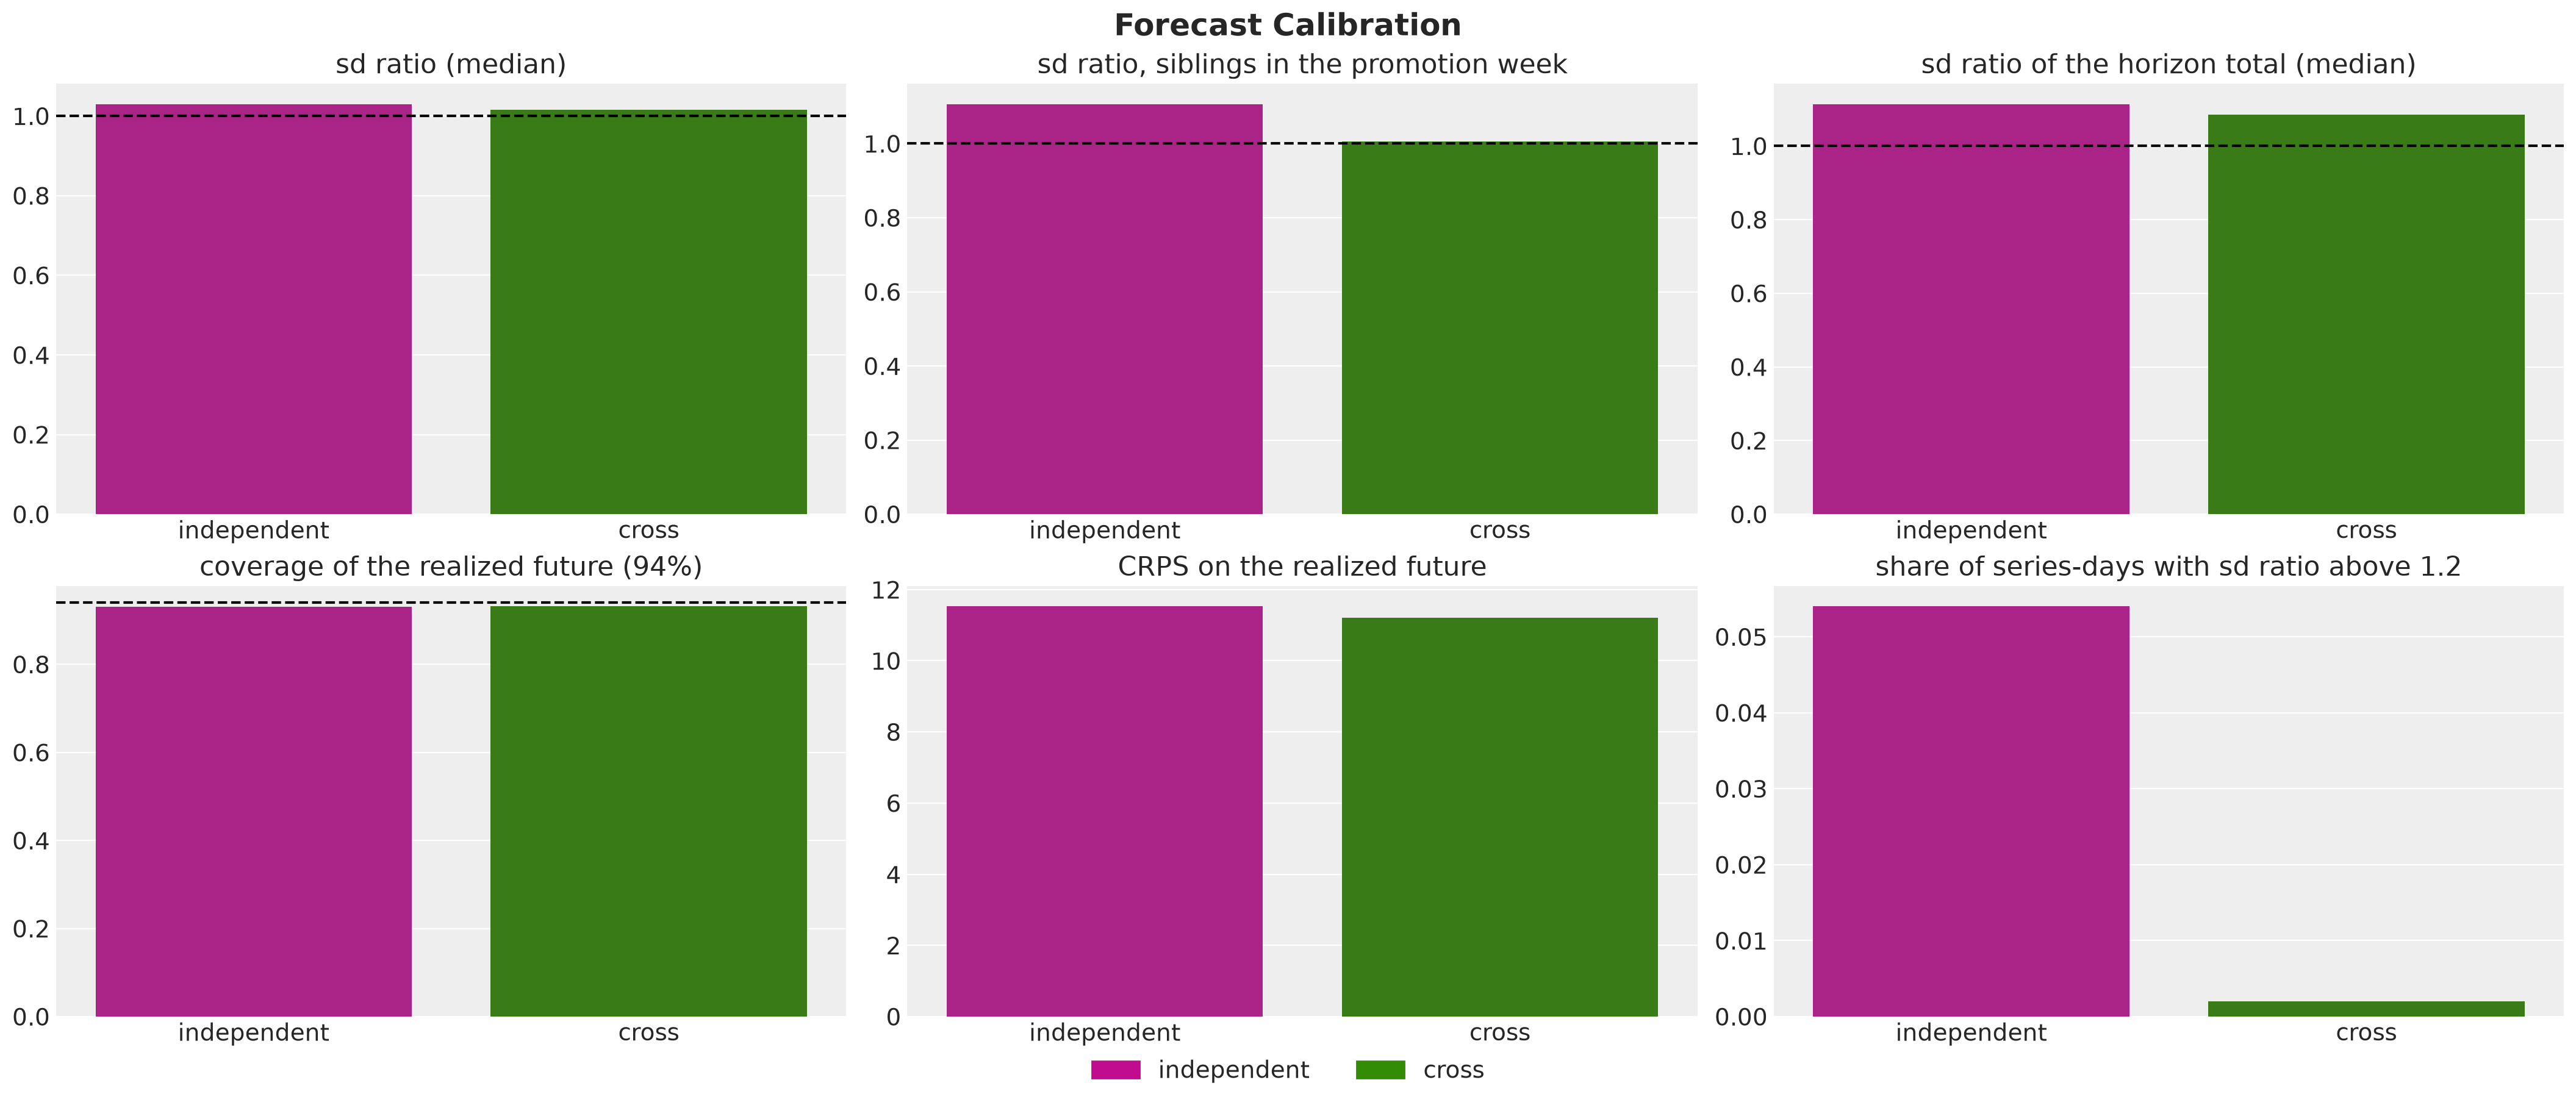

In [35]:
sd_true = demand_eval.std(axis=0)
sd_total_true = demand_eval.sum(axis=1).std(axis=0)
width_ratio = {model: draws[model].scenarios.std(axis=0) / sd_true for model in models}
total_ratio = {
    model: draws[model].scenarios.sum(axis=1).std(axis=0) / sd_total_true
    for model in models
}
is_promo_day = promo_future.sum(axis=1) > 0
is_sibling_series = role_mask[Role.SIBLING][panel.series_to_product]

SD_RATIO = "sd ratio (median)"
SD_RATIO_SIBLINGS = "sd ratio, siblings in the promotion week"
SD_RATIO_TOTAL = "sd ratio of the horizon total (median)"
COVERAGE_REALIZED = f"coverage of the realized future ({CI_PROB:.0%})"
CRPS = "CRPS on the realized future"
SHARE_WIDE = "share of series-days with sd ratio above 1.2"

calibration = pl.DataFrame(
    [
        {
            "model": model.value,
            SD_RATIO: float(jnp.median(width_ratio[model])),
            SD_RATIO_SIBLINGS: float(
                jnp.median(width_ratio[model][is_promo_day][:, is_sibling_series])
            ),
            SD_RATIO_TOTAL: float(jnp.median(total_ratio[model])),
            COVERAGE_REALIZED: float(
                eval_coverage(draws[model].scenarios, demand_future_true, alpha=CI_PROB)
            ),
            CRPS: float(
                crps_empirical(draws[model].scenarios, demand_future_true).mean()
            ),
            SHARE_WIDE: float((width_ratio[model] > 1.2).mean()),
        }
        for model in models
    ]
)
plot_metric_bars(
    calibration,
    {
        SD_RATIO: 1.0,
        SD_RATIO_SIBLINGS: 1.0,
        SD_RATIO_TOTAL: 1.0,
        COVERAGE_REALIZED: CI_PROB,
        CRPS: None,
        SHARE_WIDE: None,
    },
    x="model",
    title="Forecast Calibration",
    ncols=3,
);

The next figure shows the distribution of the single-day ratio over the $3{,}000$ series-days ($15$ days times $200$ series) of each model.

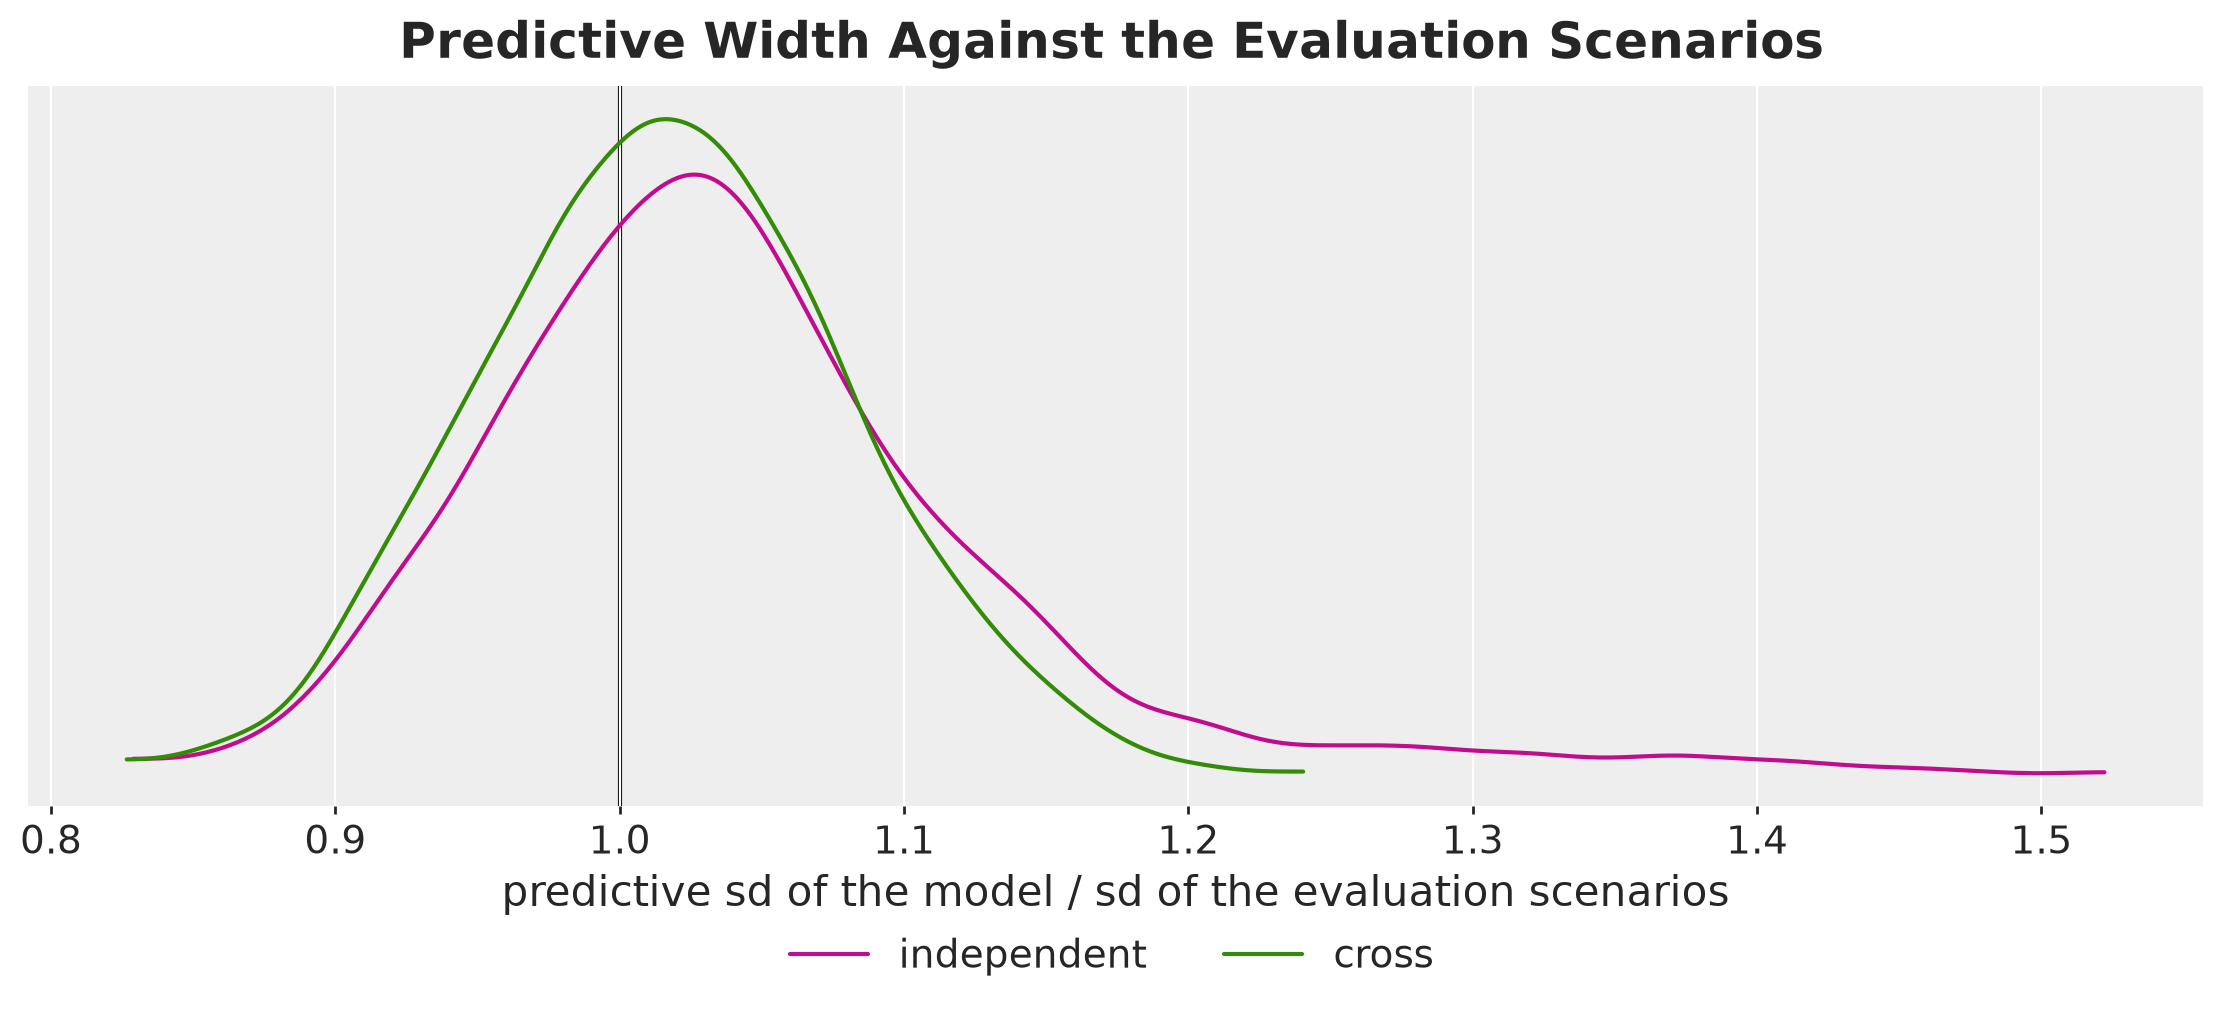

In [36]:
pc = az.plot_dist(
    {
        model: xr.Dataset({"sd ratio": (("sample",), width_ratio[model].ravel())})
        for model in models
    },
    sample_dims=["sample"],
    kind="kde",
    color=[MODEL_COLORS[model] for model in models],
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    figure_kwargs={"figsize": (11, 5)},
)
az.add_lines(
    pc,
    values={"sd ratio": 1.0},
    aes_by_visuals={"ref_line": []},
    visuals={"ref_line": {"color": "black", "linestyle": "-"}},
)
ax = pc.viz["plot"]["sd ratio"].item()
ax.set(xlabel="predictive sd of the model / sd of the evaluation scenarios", title="")
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Predictive Width Against the Evaluation Scenarios", fontsize=18, fontweight="bold"
);

Both forecasts are about as wide as the evaluation scenarios on a single day, with a median ratio of $1.02$ for the cross model and $1.03$ for the independent model. Both cover the realized future at $93\%$, and their CRPS are $11.20$ and $11.53$ units, $3\%$ apart.

On the total demand of a series over the horizon both forecasts are wider than the evaluation scenarios, at about $1.09$ and $1.11$. The evaluation scenarios condition on the true level of every series, which a model has to estimate, so a ratio above one is expected.

The independent model stands out on the siblings in the promotion week. Its forecast is $11\%$ wider than the evaluation scenarios there, against $0.5\%$ for the cross model, and $5.4\%$ of its series-days have a ratio above $1.2$, against $0.2\%$. This is consistent with its higher mean forecast for these series and its lower concentration, since both widen a negative binomial.

Next, we turn the forecasts into scenarios and plans.

## Demand Scenarios

We now have three sets of demand paths, each of shape `(scenarios, days, series)`.

- **Independent model.** Its $1{,}000$ forecast draws are the **optimization scenarios** of the plans built on it.
- **Cross model.** Its $1{,}000$ forecast draws are the optimization scenarios of the plans built on it.
- **True process.** Its $1{,}000$ draws are the evaluation scenarios, on which we score every plan.

Next, we set the capacity vector $C = (C_1, \dots, C_S)$. Let $R_s$ be the **regular throughput** of store $s$, which we take as the median of its total daily demand over the last eight weeks of the history. The chain knows this number, and one promotion week does not move it much.

The stores differ in size, so we give each store a capacity that is a multiple $\kappa$ of its regular throughput,

$$
C_s = \kappa \, R_s.
$$

The **capacity multiple** $\kappa$ is the same for all stores. A larger store has a larger capacity, and every store has the same room relative to its regular throughput. We start with $\kappa = 1.05$ and sweep it in the *Capacity Sensitivity* section.

The initial stock of every series is its mean daily demand over the last four weeks of the history. The `Planning` tuple holds these three settings.

To see how tight these capacities are, we compute the mean demand of the evaluation scenarios of a store as a share of its capacity, the **load**, for each period of the horizon. We split the horizon into three **periods**, the first week, the promotion week and the last day. The next figure shows the capacity of every store and its load in each period.

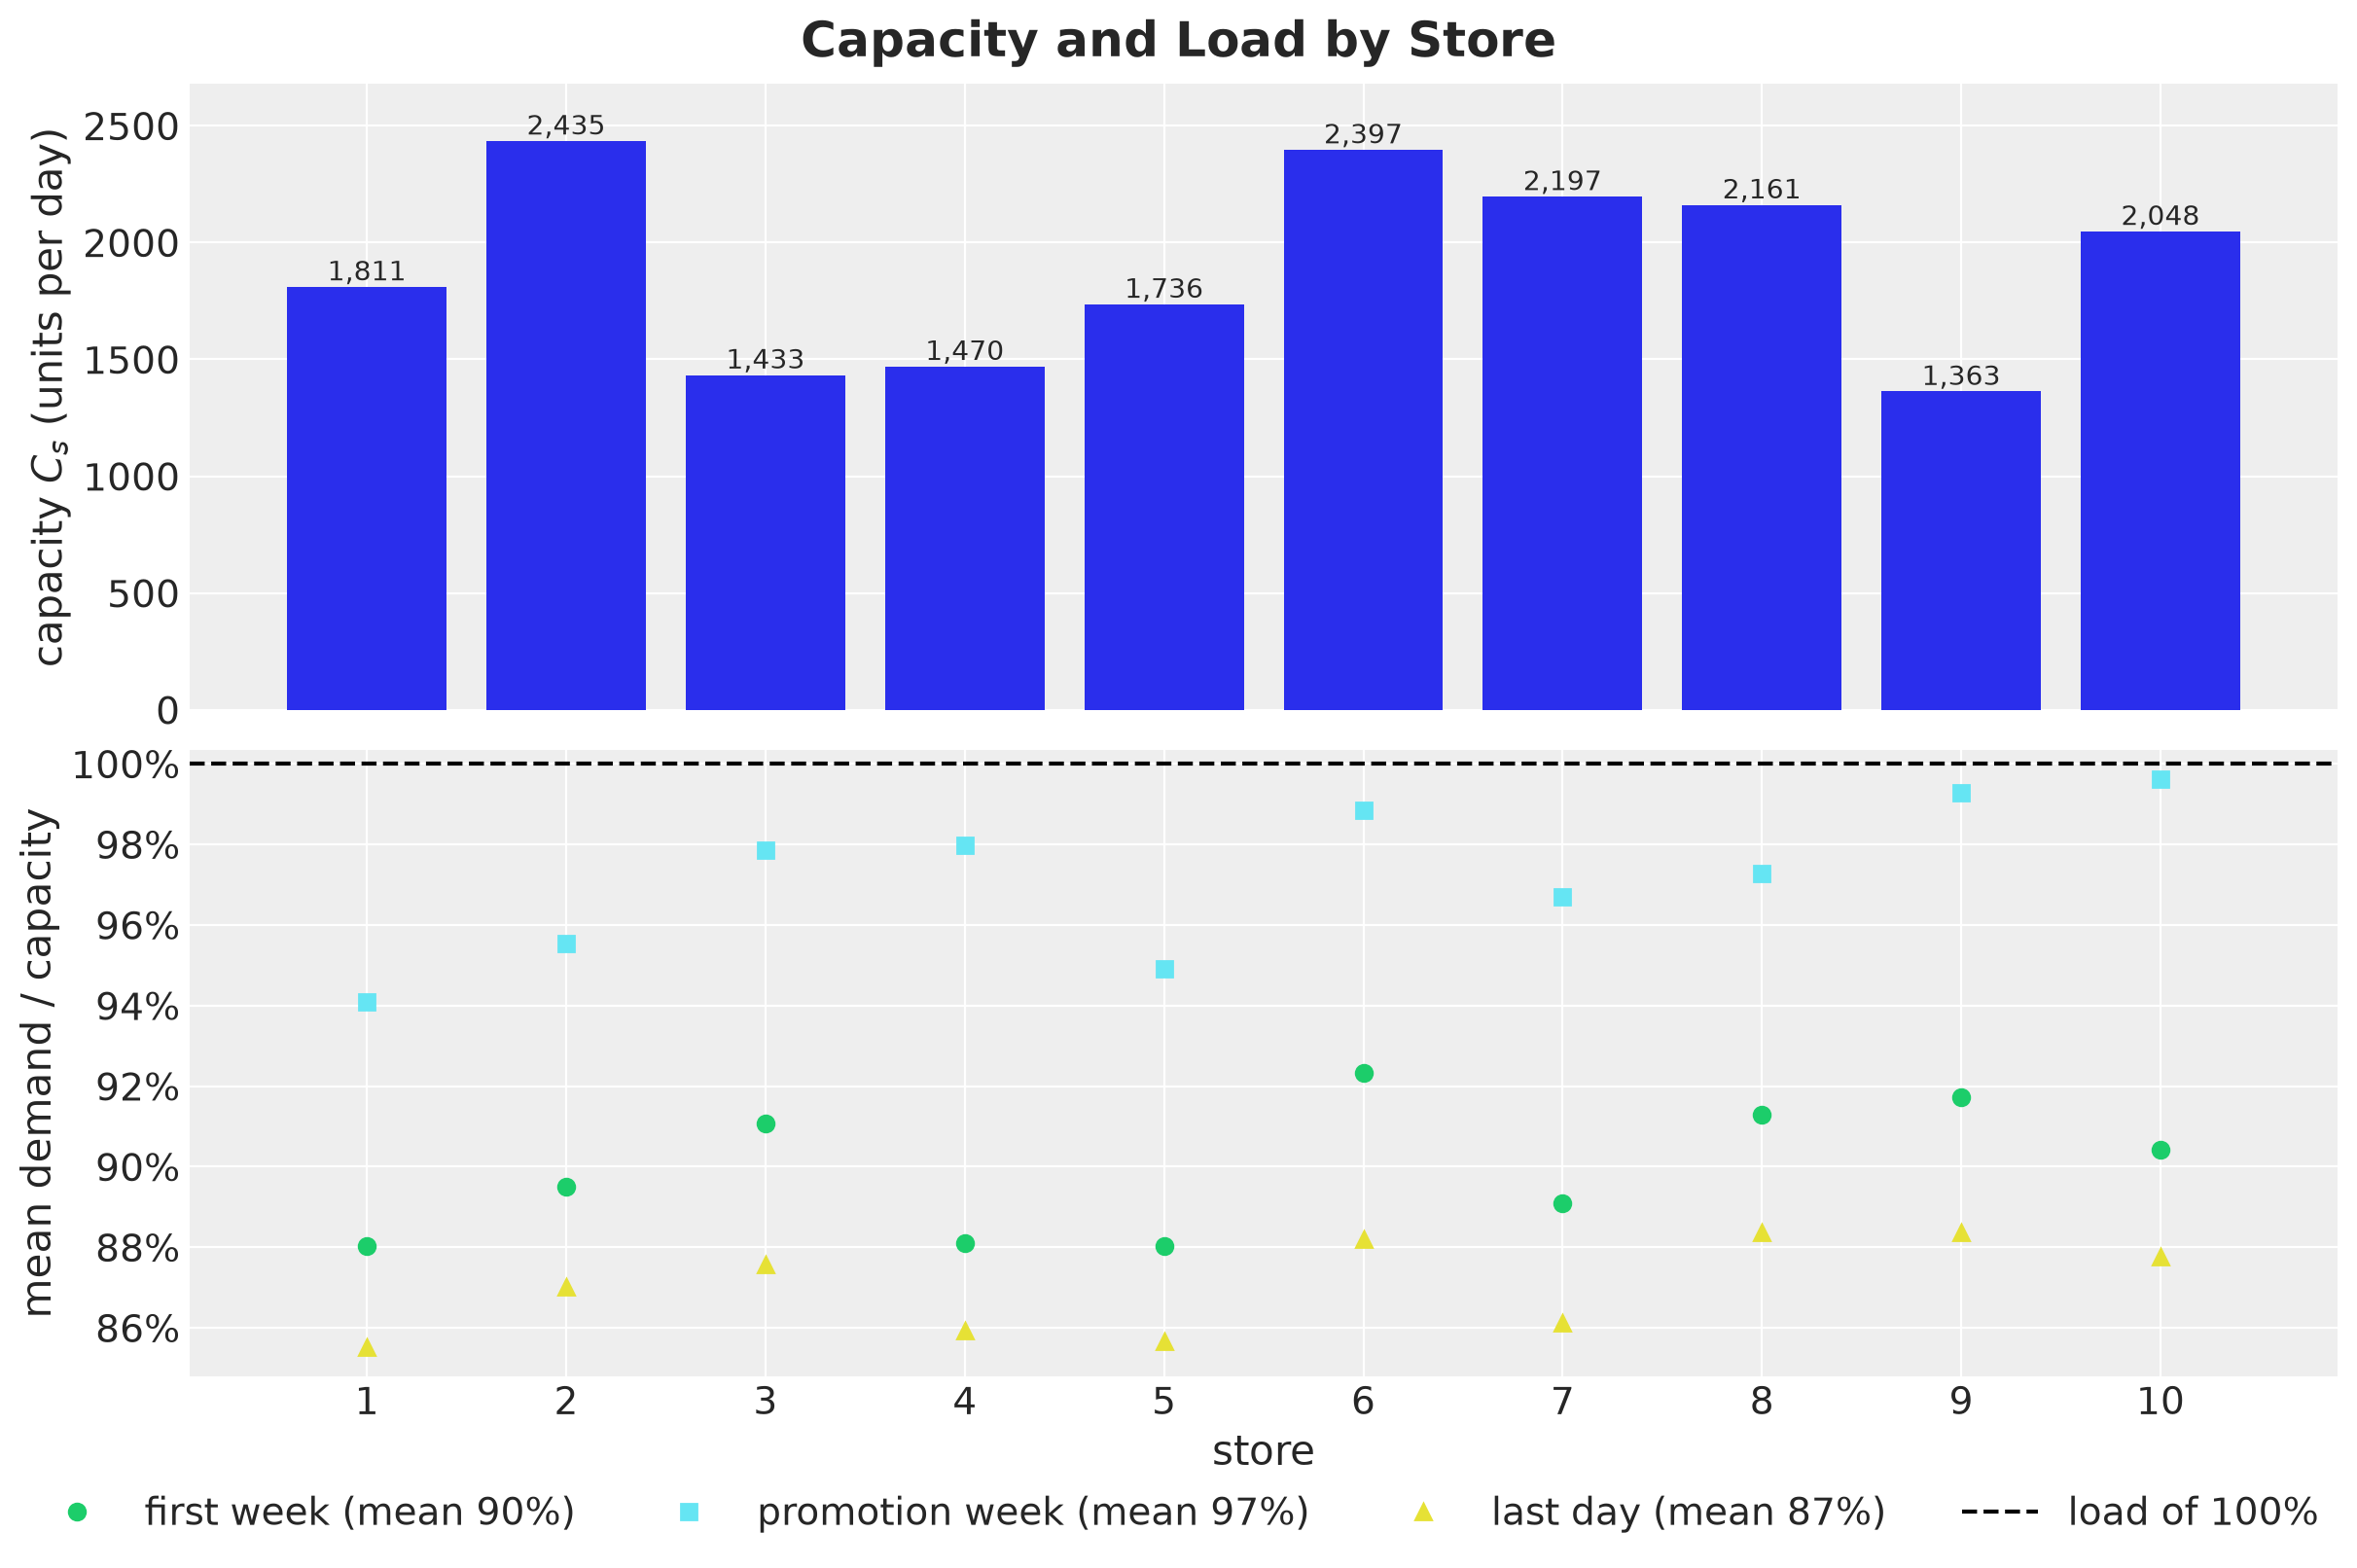

In [37]:
class Planning(NamedTuple):
    """How the capacities and the initial stock follow from the history."""

    capacity_multiple: float = 1.05  # capacity over the regular throughput of a store
    throughput_window: int = 56  # days of history behind the regular throughput
    stock_window: int = 28  # days of history behind the initial stock


class Period(StrEnum):
    """Parts of the horizon."""

    FIRST_WEEK = "first week"
    PROMOTION_WEEK = "promotion week"
    LAST_DAY = "last day"


PERIODS = {
    Period.FIRST_WEEK: slice(0, promotion.start),
    Period.PROMOTION_WEEK: slice(promotion.start, promotion.end),
    Period.LAST_DAY: slice(promotion.end, setup.horizon),
}


def flat(
    orders: Float[Array, "horizon n_stores n_products"],
) -> Float[Array, "horizon n_series"]:
    """Reshape a plan from (day, store, product) to (day, series)."""
    return orders.reshape(setup.horizon, setup.n_series)


def unflat(
    orders: Float[Array, "horizon n_series"],
) -> Float[Array, "horizon n_stores n_products"]:
    """Reshape a plan from (day, series) to (day, store, product)."""
    return orders.reshape(setup.horizon, setup.n_stores, setup.n_products)


planning = Planning()
data_by_store = data.astype(jnp.float32).reshape(
    setup.t_obs, setup.n_stores, setup.n_products
)
regular_throughput = jnp.median(
    data_by_store[-planning.throughput_window :].sum(axis=-1), axis=0
)
capacity = planning.capacity_multiple * regular_throughput
initial_inventory = data[-planning.stock_window :].astype(jnp.float32).mean(axis=0)
mean_demand = {model: draws[model].scenarios.mean(axis=0) for model in models}

# mean demand of the true process over the capacity: (horizon, n_stores)
capacity_load = unflat(demand_eval.mean(axis=0)).sum(axis=-1) / capacity
stores = jnp.arange(1, setup.n_stores + 1)
PERIOD_STYLES = {
    Period.FIRST_WEEK: ("C7", "o"),
    Period.PROMOTION_WEEK: ("C5", "s"),
    Period.LAST_DAY: ("C6", "^"),
}

fig, axes = plt.subplots(nrows=2, figsize=(12, 8), sharex=True, layout="constrained")
ax = axes[0]
bars = ax.bar(stores, capacity, color="C0")
ax.bar_label(bars, fmt="{:,.0f}")
ax.margins(y=0.1)
ax.set(ylabel="capacity $C_s$ (units per day)")
ax = axes[1]

for period, days_slice in PERIODS.items():
    color, marker = PERIOD_STYLES[period]
    load_by_store = capacity_load[days_slice].mean(axis=0)
    ax.plot(
        stores,
        load_by_store,
        marker,
        color=color,
        label=f"{period} (mean {float(load_by_store.mean()):.0%})",
    )

ax.axhline(1.0, color="black", linestyle="--", label="load of 100%")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="store", ylabel="mean demand / capacity", xticks=stores)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Capacity and Load by Store", fontsize=18, fontweight="bold");

The capacities run from $1{,}363$ units per day in store $9$ to $2{,}435$ in store $2$.

The loads differ much less than the capacities, because every store has the same multiple $\kappa$. In the first week the mean demand takes $90\%$ of the capacity on average over the stores. In the promotion week it takes $97\%$ on average, and it is the highest in stores $9$ and $10$, close to $100\%$.

The plans order more than the mean demand, because they hold a buffer against lost sales. With that buffer, a load of $90\%$ leaves room and a load of $97\%$ does not.

Note that this share depends on which products are promoted, so the same $\kappa$ can be tighter or looser on another panel.

The next figure shows the forecasts of both models for the four products of group $1$ in store $1$, next to the last four weeks of history and the realized future.

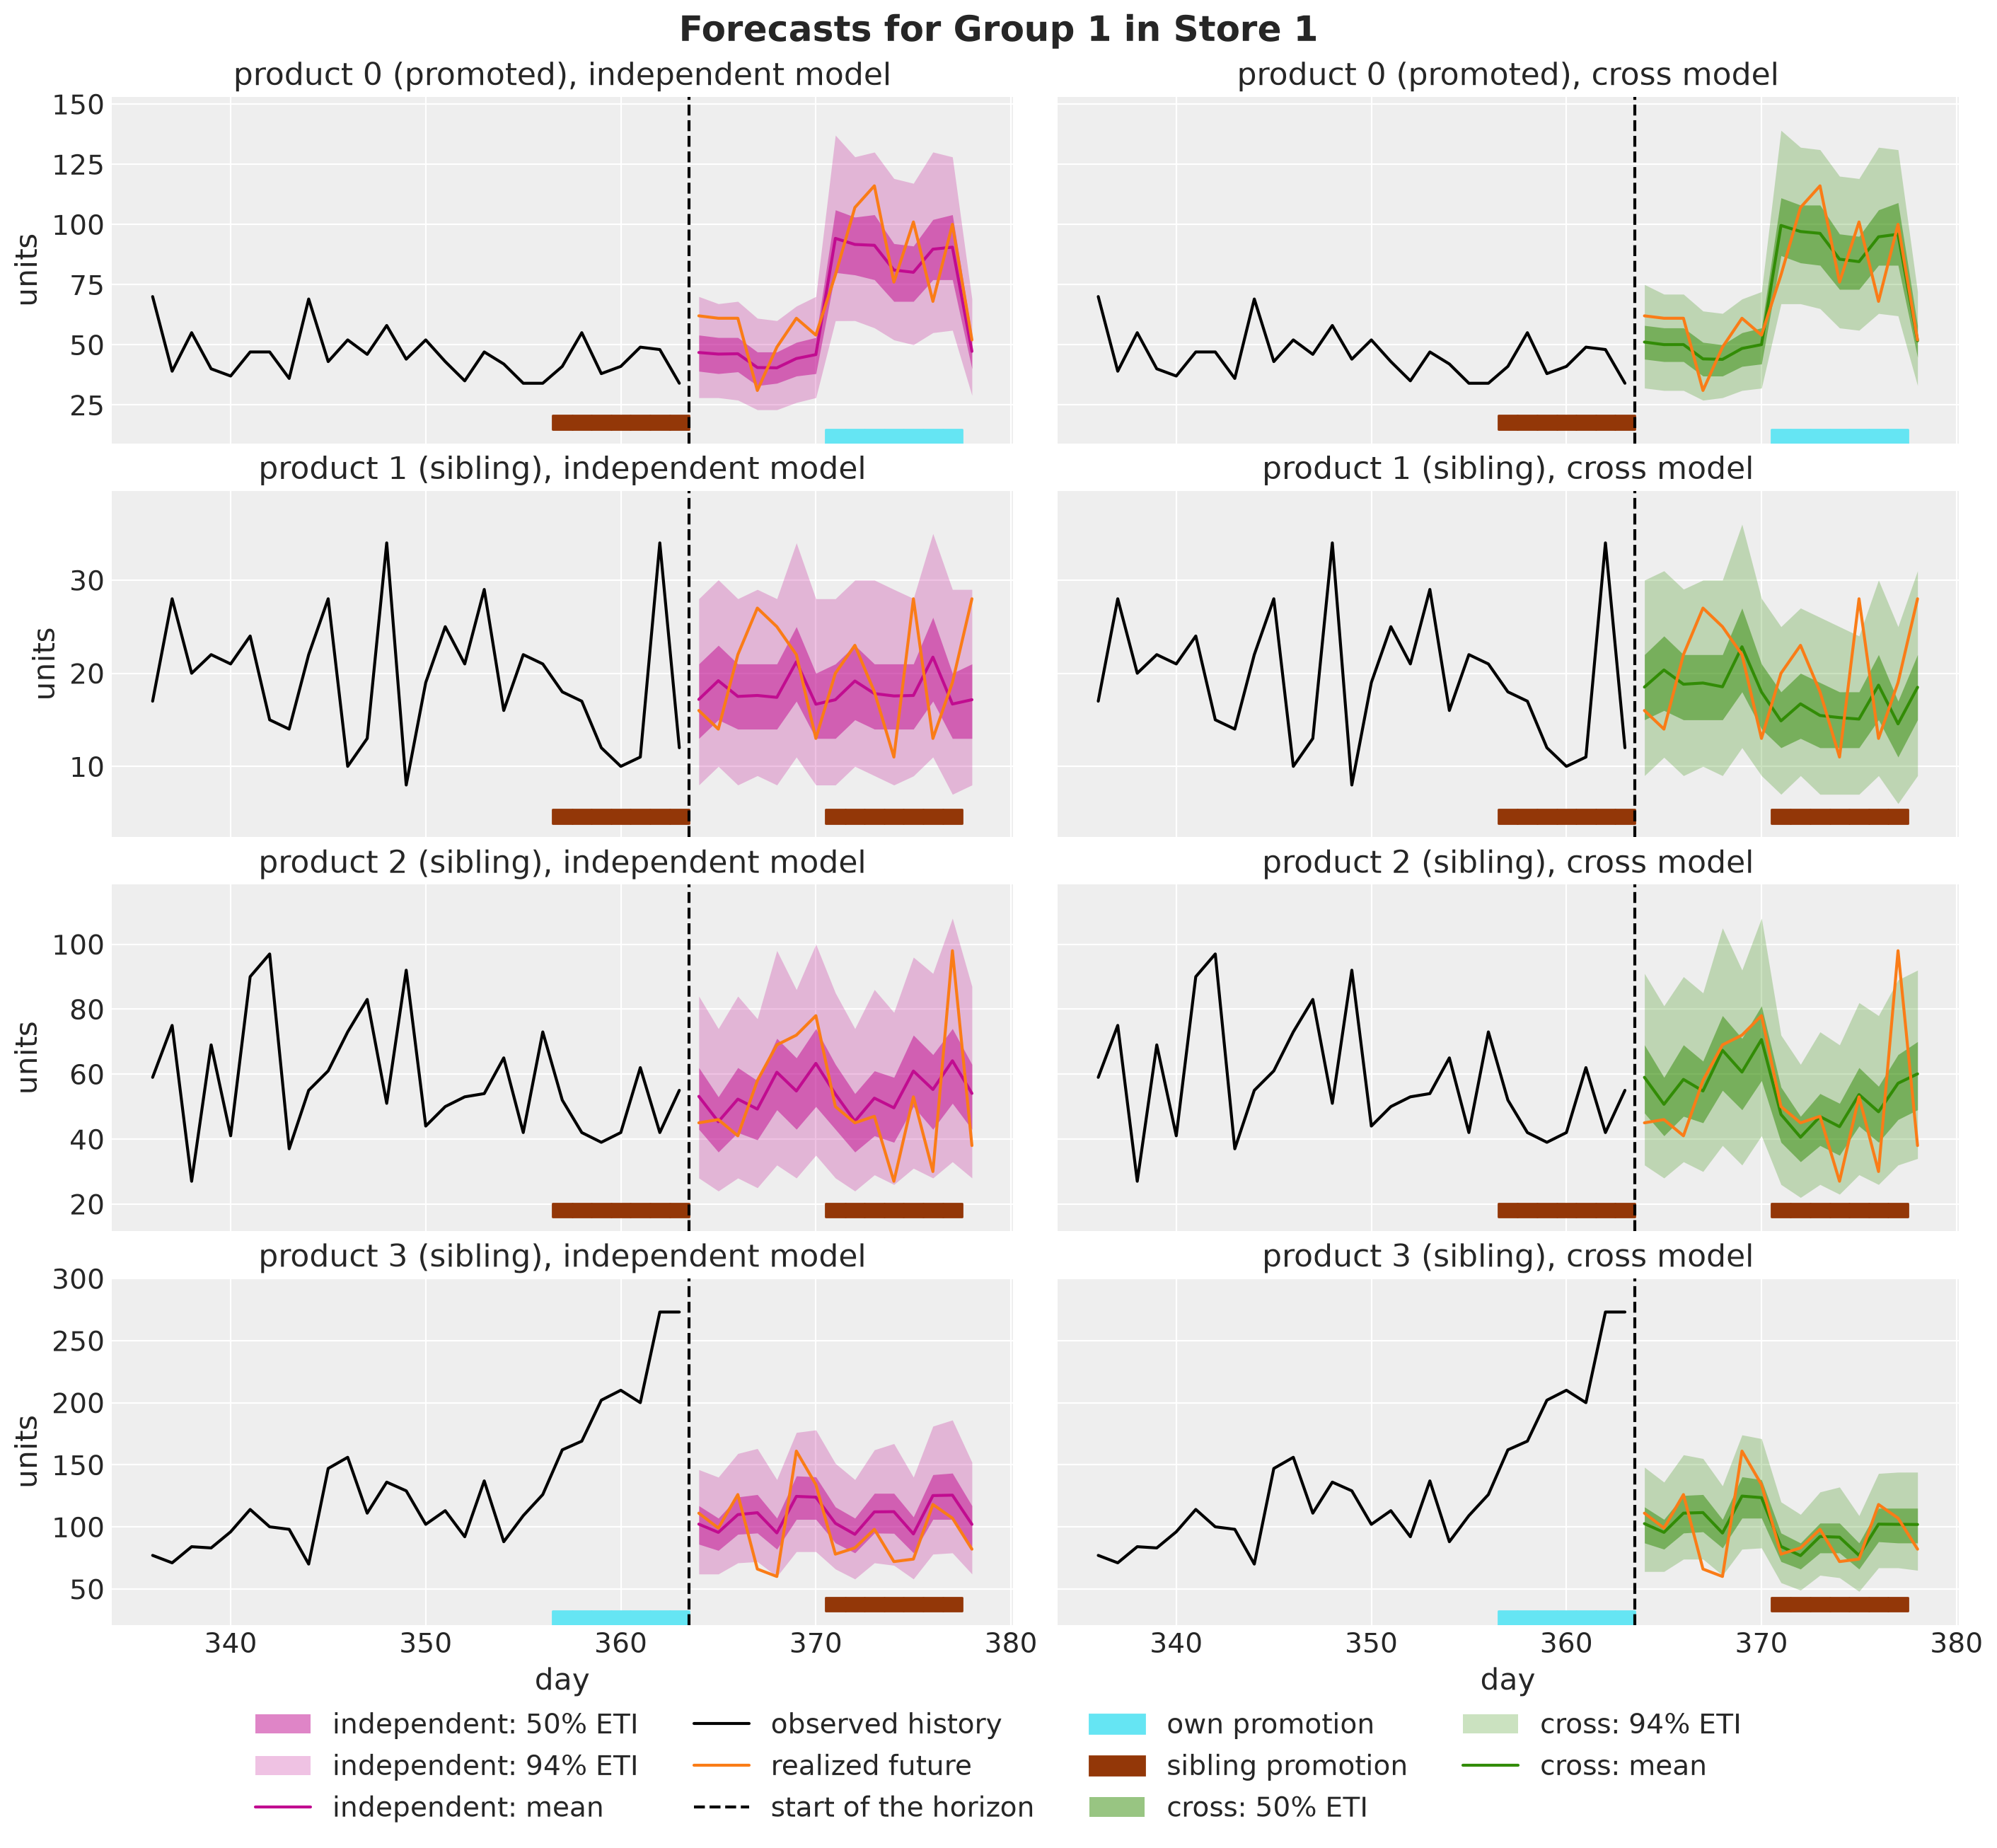

In [38]:
def plot_group_forecast(store: int, group: int, start: int = setup.t_obs - 28) -> None:
    """Forecasts of both models for the four products of a group in a store."""
    group_products = jnp.flatnonzero(panel.product_to_group == group)
    series = store * setup.n_products + group_products
    labels = [f"product {j} ({product_role[j]})" for j in group_products.tolist()]
    shape = (len(series), len(models), setup.horizon)
    tree = az.from_dict(
        {
            # dims after chain and draw: (series, model, time)
            "posterior_predictive": {
                "obs": jnp.stack(
                    [draws[model].scenarios[..., series] for model in models], axis=-1
                )[None].transpose(0, 1, 3, 4, 2)
            },
            # `plot_lm` sorts these two in place, and JAX arrays are immutable, so
            # we pass writable numpy copies
            "observed_data": {
                "obs": np.array(
                    jnp.broadcast_to(demand_future_true[:, series].T[:, None, :], shape)
                )
            },
            "constant_data": {
                "day": np.array(jnp.broadcast_to(days_future.astype(float), shape))
            },
        },
        coords={
            "series": labels,
            "model": [model.value for model in models],
            "time": days_future,
        },
        dims={"obs": ["series", "model", "time"], "day": ["series", "model", "time"]},
    )
    pc = az.plot_lm(
        tree,
        x="day",
        y="obs",
        y_obs="obs",
        plot_dim="time",
        smooth=False,
        ci_prob=(0.5, CI_PROB),
        point_estimate="mean",
        visuals={
            "pe_line": {"alpha": 1.0},
            "observed_scatter": False,
            "xlabel": False,
            "ylabel": False,
        },
        cols=["series", "model"],
        col_wrap=len(models),
        aes={"color": ["model"]},
        aes_by_visuals={"pe_line": ["color"]},
        color=[MODEL_COLORS[model] for model in models],
        figure_kwargs={"figsize": (14, 13), "sharex": True, "sharey": "row"},
    )
    lighten_bands(pc, "day", prob_alpha=((0.5, 0.5), (CI_PROB, 0.25)))
    legend = {}

    for row, (label, i) in enumerate(zip(labels, series.tolist(), strict=True)):
        for col, model in enumerate(models):
            where = {"series": label, "model": model.value}
            bands = pc.viz["ci_band"]["day"].sel(where)
            bands.sel(prob=0.5).item().set_label(f"{model}: 50% ETI")
            bands.sel(prob=CI_PROB).item().set_label(f"{model}: {CI_PROB:.0%} ETI")
            pc.viz["pe_line"]["day"].sel(where).item().set_label(f"{model}: mean")
            ax = pc.get_target("day", where)
            plot_demand(ax, i, start)
            ax.set(
                title=f"{label}, {model} model",
                xlabel="day" if row == len(labels) - 1 else "",
                ylabel="units" if col == 0 else "",
            )
            handles, names = ax.get_legend_handles_labels()
            legend |= dict(zip(names, handles, strict=True))

    fig = pc.viz["figure"].item()
    fig.legend(legend.values(), legend.keys(), loc="outside lower center", ncol=4)
    fig.suptitle(
        f"Forecasts for Group {group + 1} in Store {store + 1}",
        fontsize=18,
        fontweight="bold",
    )


plot_group_forecast(store=0, group=0);

On the promoted product both forecasts jump in the promotion week, and the independent model is lower in the first week. On the three siblings the two models part in the promotion week, where the cross model dips and the independent model stays close to flat. The realized future, one noisy path, dips with the cross model.

The models also part in the first week, where no promotion happens. On products $0$, $1$ and $2$ the cross model starts above the independent model. The last week of the history was a sibling promotion week for these three products, so their demand dipped there.

The cross model attributes the dip to the price of product $3$ and expects the recovery. The independent model has no such term, and its lower start is consistent with a level that followed the dip down. We check this below.

Product $3$ shows the other case. It was on promotion itself in that week and no sibling was, and the two forecasts start at about the same level.

Next, we draw the same figure for group $3$, which is promoted but has no cannibalization.

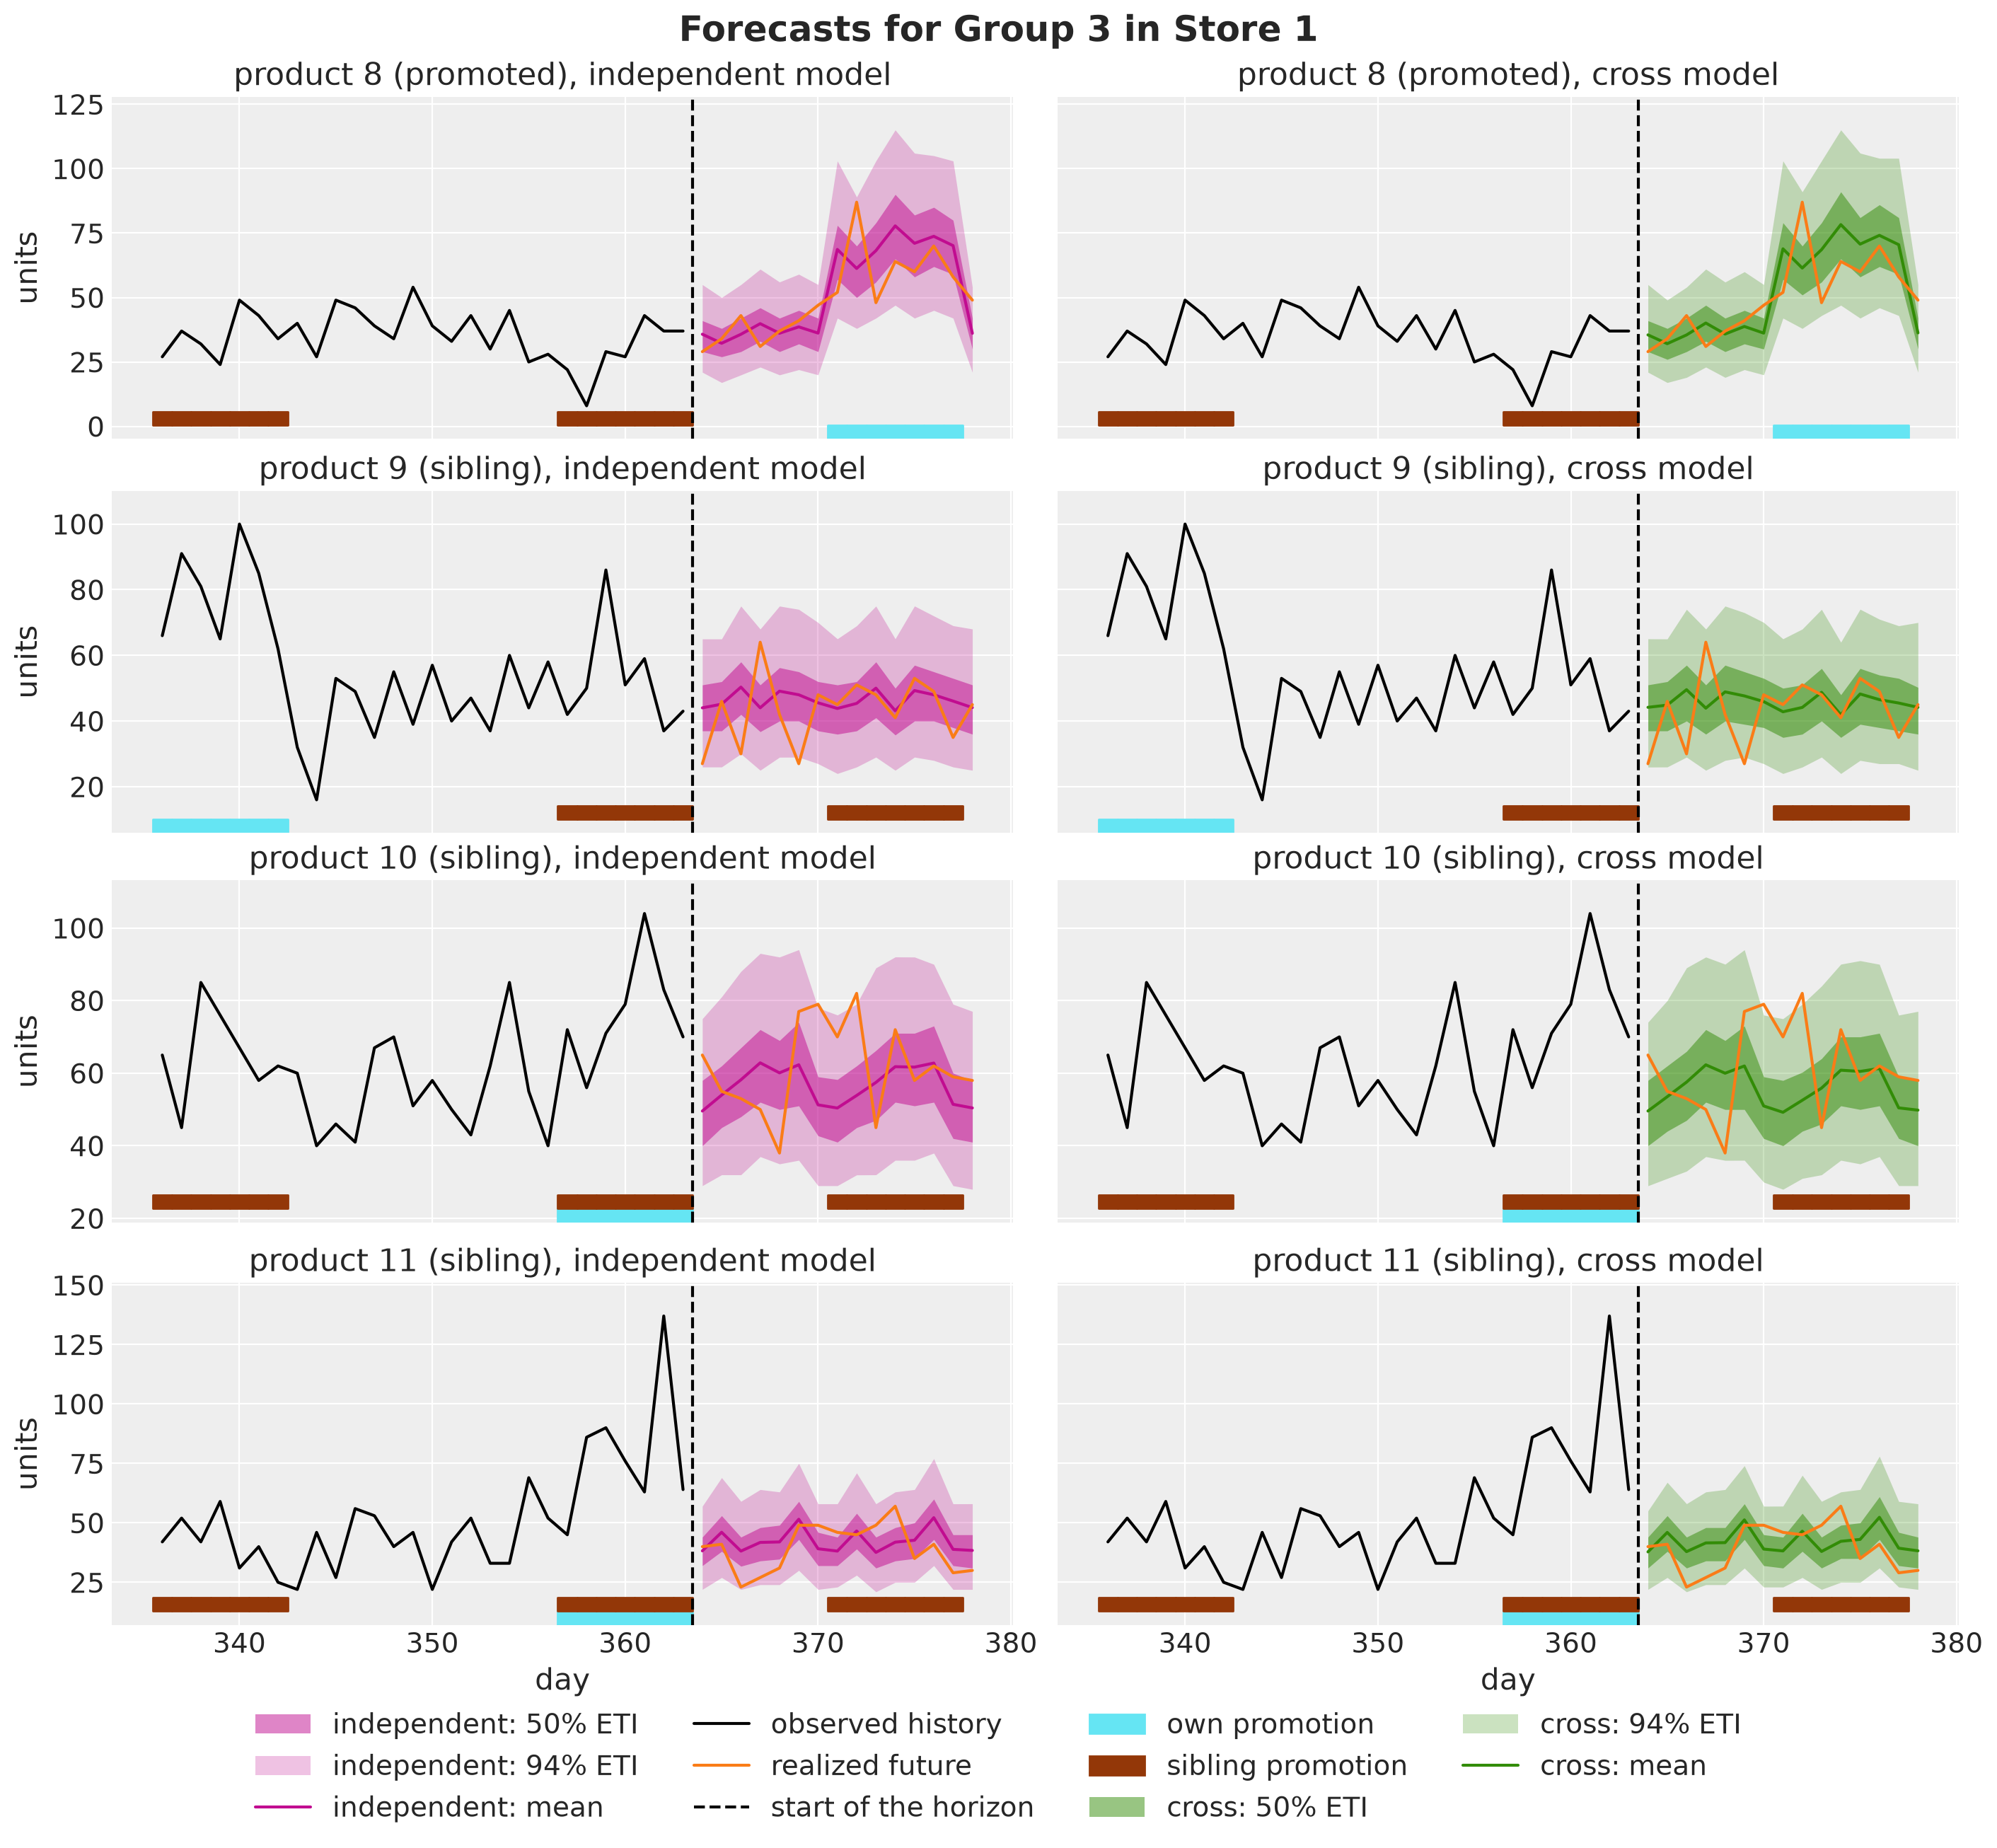

In [39]:
plot_group_forecast(store=0, group=2);

The two forecasts agree on every product, including the three siblings in the promotion week. The cross model does not invent a dip where the data show none, which is good!

Observe that the first week of the horizon has no promotion, so any difference between the two models in that week comes from the history. To see it for every series, we divide the mean forecast over the first week by the mean of the evaluation scenarios over the same week. A ratio of one means that the forecast starts at the level of the evaluation scenarios.

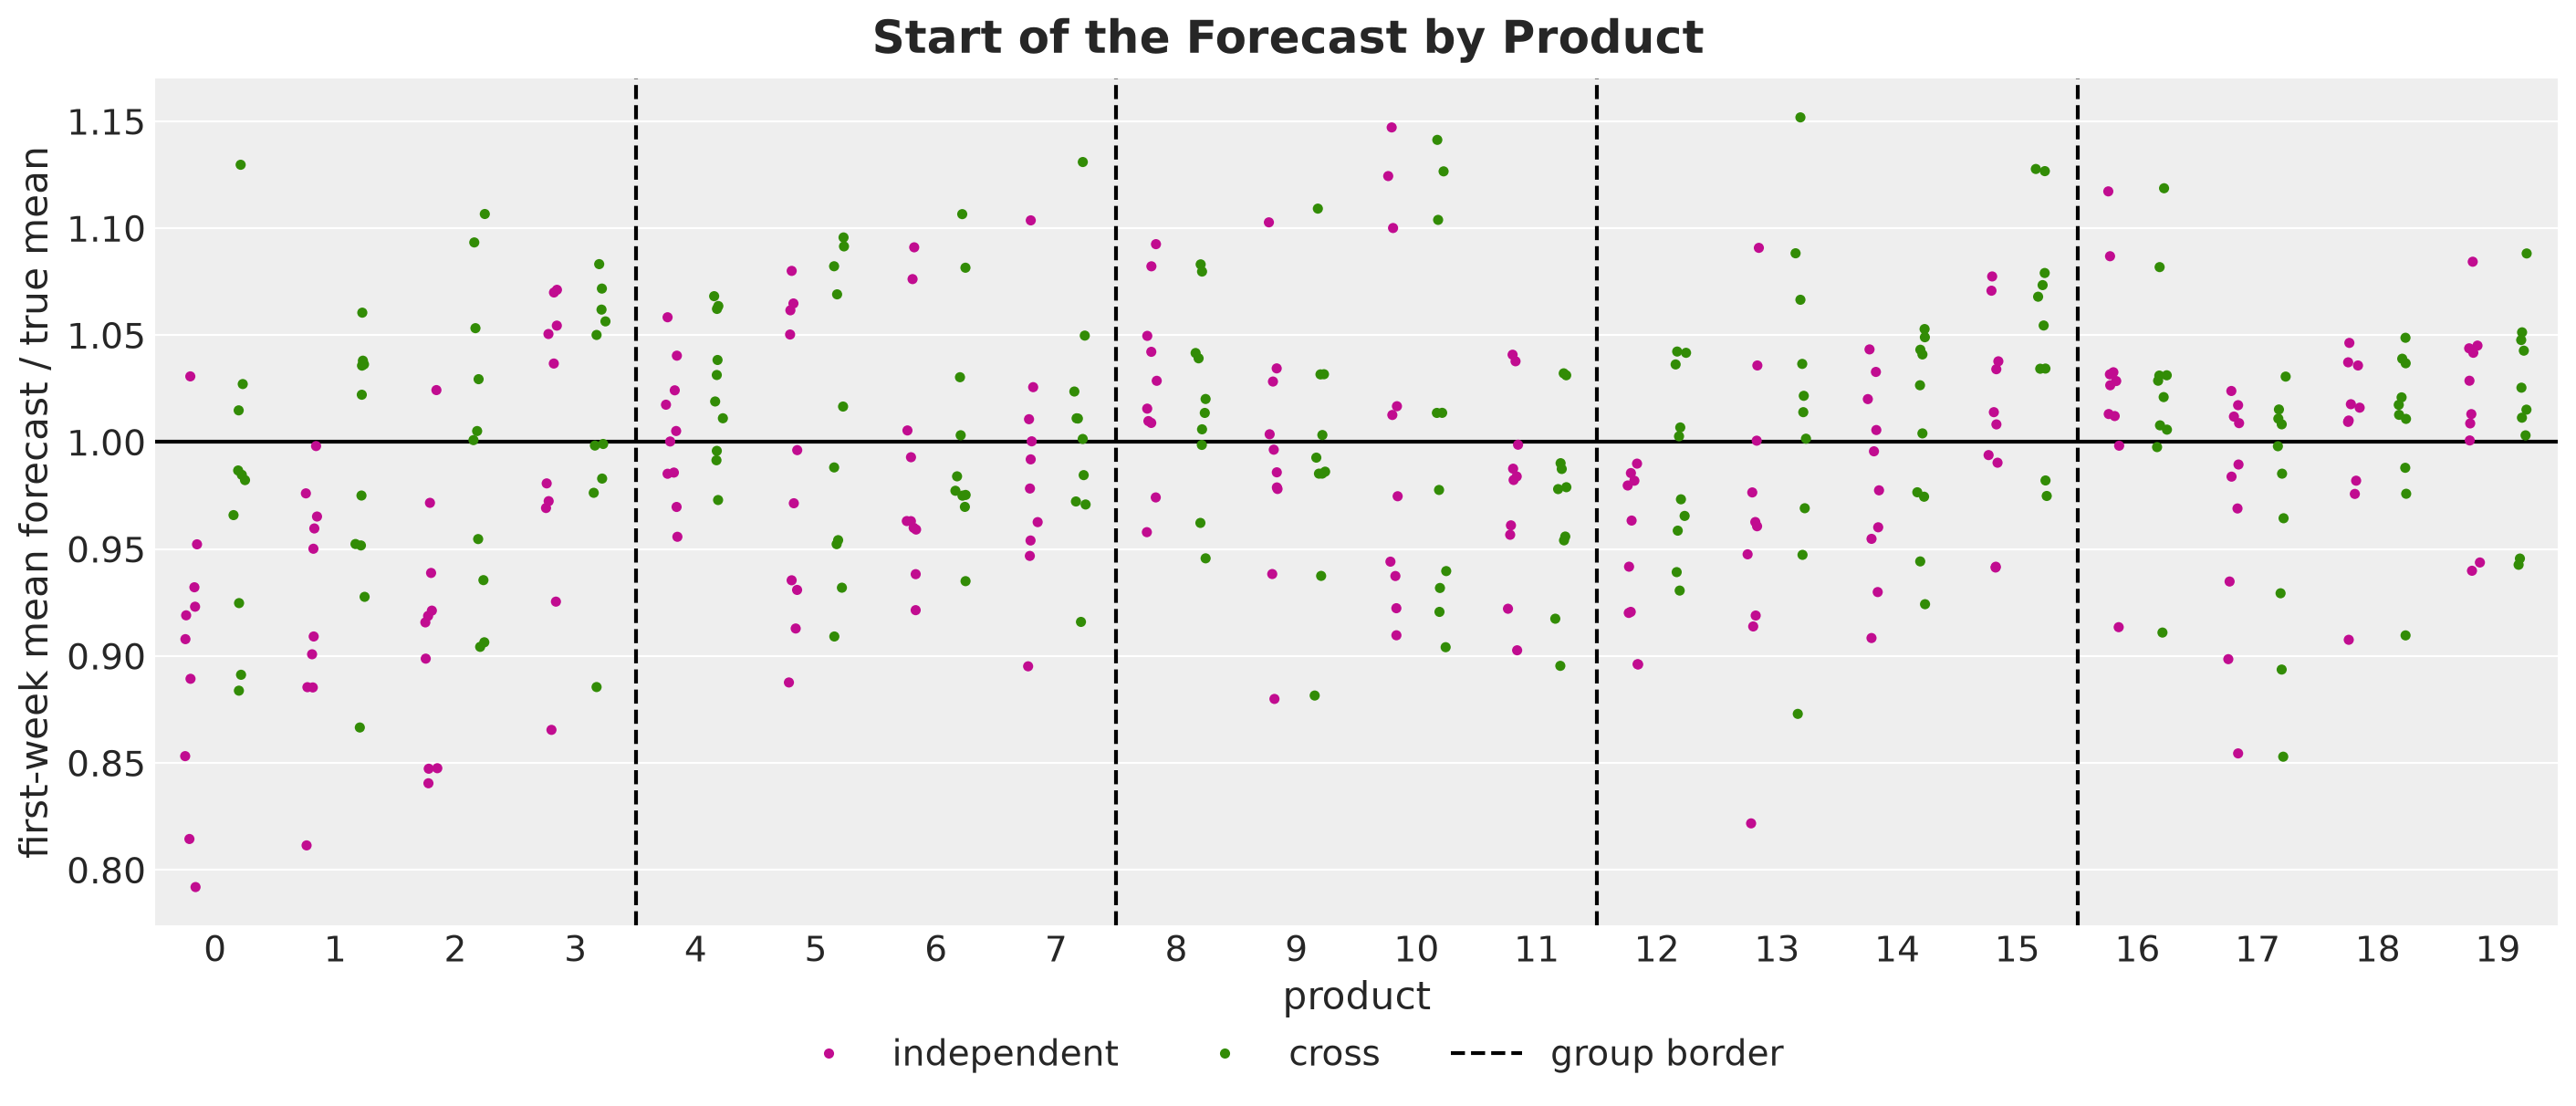

In [40]:
first_week = PERIODS[Period.FIRST_WEEK]
truth_start = demand_eval[:, first_week].mean(axis=(0, 1))
start_ratio = pl.DataFrame(
    {
        "product": jnp.tile(panel.series_to_product, len(models)).tolist(),
        "model": [model.value for model in models for _ in range(setup.n_series)],
        "ratio": jnp.concatenate(
            [
                draws[model].scenarios[:, first_week].mean(axis=(0, 1)) / truth_start
                for model in models
            ]
        ).tolist(),
    }
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.stripplot(
    data=start_ratio,
    x="product",
    y="ratio",
    hue="model",
    hue_order=[model.value for model in models],
    palette=MODEL_COLORS,
    dodge=True,
    size=4,
    ax=ax,
)
ax.axhline(1.0, color="black")

for group in range(1, setup.n_groups):
    ax.axvline(
        group * setup.n_per_group - 0.5,
        color="black",
        linestyle="--",
        label="group border" if group == 1 else None,
    )

ax.get_legend().remove()
ax.set(xlabel="product", ylabel="first-week mean forecast / true mean")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Start of the Forecast by Product", fontsize=18, fontweight="bold");

Each point is one series, that is, one store of the product on the horizontal axis.

- **Group $1$.** Under the independent model, products $0$, $1$ and $2$ start below the truth in $9$ or $10$ of the $10$ stores, with a median ratio of $0.91$ to $0.93$. Under the cross model they start around the truth. Product $3$ starts at about the same place under both models.
- **Groups $2$ and $4$.** The independent model starts lower than the cross model on every product, by $0.02$ to $0.06$ in the median ratio. The largest differences, about $0.05$, are on products $13$ and $15$ of group $4$.
- **Groups $3$ and $5$.** The two models agree on every product, within $0.01$ in the median ratio.

The spread across the stores of a product is similar under both models. It is consistent with the error of the level that we saw in the *Parameter Recovery* section.

Here is the mechanism we propose. A random walk level follows the recent demand. When a sibling was on promotion in the last weeks of the history, the demand of a product was lower in those weeks, and a model without a cross-price term reads that as a lower level.

To check this, let $\tau$ be a **time constant** in days and let $w_t \propto \exp(-(T - t) / \tau)$ be weights over the days $t = 1, \dots, T$ of the history that sum to one and favor the last days. We define the **recent sibling exposure** of product $j$ as the weighted mean of the log price cuts of its siblings,

$$
e_j = \sum_{t=1}^{T} w_t \sum_{k \in g(j), \, k \neq j} (-x_{t,k}).
$$

The cross elasticity is constant within a group. Let $c_j$ be the cross elasticity of the group of product $j$. So on a weighted average the sibling promotions took $c_j \, e_j$ from the log demand of product $j$.

We compare this quantity with the **level gap** of the product, the posterior mean of the level at the end of the history under the independent model minus the same quantity under the cross model, averaged over the stores. If the level of the independent model absorbs the recent dips, the level gap is close to $-c_j \, e_j$.

The time constant stands for the memory of the level, which we do not estimate. The following table tries three values. For each one it gives the correlation between the level gap and $c_j \, e_j$ and the slope of the least squares line, over the $12$ products with a positive cross elasticity.

In [41]:
def recent_sibling_exposure(time_constant: float) -> Float[Array, " n_products"]:
    """Log price cuts of the siblings of each product, weighted toward the last days."""
    sibling_cut = -(log_price[: setup.t_obs] @ is_sibling.astype(log_price.dtype))
    weights = jnp.exp(-jnp.arange(setup.t_obs)[::-1] / time_constant)
    return (weights / weights.sum()) @ sibling_cut


product_cross = group_cross[panel.product_to_group]
has_cross = has_cannibalization(setup, panel)
level_gap = (
    (draws[Model.INDEPENDENT].level_end - draws[Model.CROSS].level_end)
    .mean(axis=0)
    .reshape(setup.n_stores, setup.n_products)
    .mean(axis=0)
)


def exposure_fit(time_constant: int) -> dict[str, int | float]:
    """Correlation and slope of the level gap against the expected sibling dip."""
    expected_dip = product_cross * recent_sibling_exposure(float(time_constant))
    return {
        "time constant (days)": time_constant,
        "correlation": float(
            jnp.corrcoef(expected_dip[has_cross], level_gap[has_cross])[0, 1]
        ),
        "slope": float(
            jnp.polyfit(expected_dip[has_cross], level_gap[has_cross], 1)[0]
        ),
    }


exposure_fits = pl.DataFrame(
    [exposure_fit(time_constant) for time_constant in (10, 20, 30)]
)
exposure_fits

time constant (days),correlation,slope
i64,f64,f64
10,-0.952,-0.580
20,-0.966,-0.910
30,-0.975,-1.006


The correlation is below $-0.95$ for the three values, so on this panel the level gap is strongly correlated with the recent sibling promotions. The slope depends on the time constant and runs from $-0.58$ to $-1.01$.

We use the value of the three whose slope is closest to $-1$, here $\tau = 30$ days. The following table lists, for the $20$ products, the exposure, the expected level gap $-c_j \, e_j$ and the level gap.

In [42]:
# the time constant whose slope is closest to -1
time_constant = exposure_fits.sort((pl.col("slope") + 1).abs()).item(
    0, "time constant (days)"
)
exposure = recent_sibling_exposure(float(time_constant))
origin = pl.DataFrame(
    {
        "product": range(setup.n_products),
        "cross elasticity": [
            setup.group_cross[group] for group in panel.product_to_group.tolist()
        ],
        "recent sibling exposure": exposure.tolist(),
        "expected level gap": (0.0 - product_cross * exposure).tolist(),
        "level gap": level_gap.tolist(),
    }
)
origin

product,cross elasticity,recent sibling exposure,expected level gap,level gap
i64,f64,f64,f64,f64
0,0.600,0.127,-0.076,-0.083
1,0.600,0.127,-0.076,-0.065
2,0.600,0.143,-0.086,-0.090
3,0.600,0.036,-0.022,-0.019
4,0.300,0.084,-0.025,-0.021
5,0.300,0.062,-0.018,-0.021
6,0.300,0.052,-0.016,-0.017
7,0.300,0.099,-0.030,-0.020
8,0.000,0.196,0.000,0.007


Next, we plot the level gap against the exposure. The three lines have slopes $-0.6$, $-0.3$ and $0$, which is where the points of each group lie if the level absorbs the recent dips.

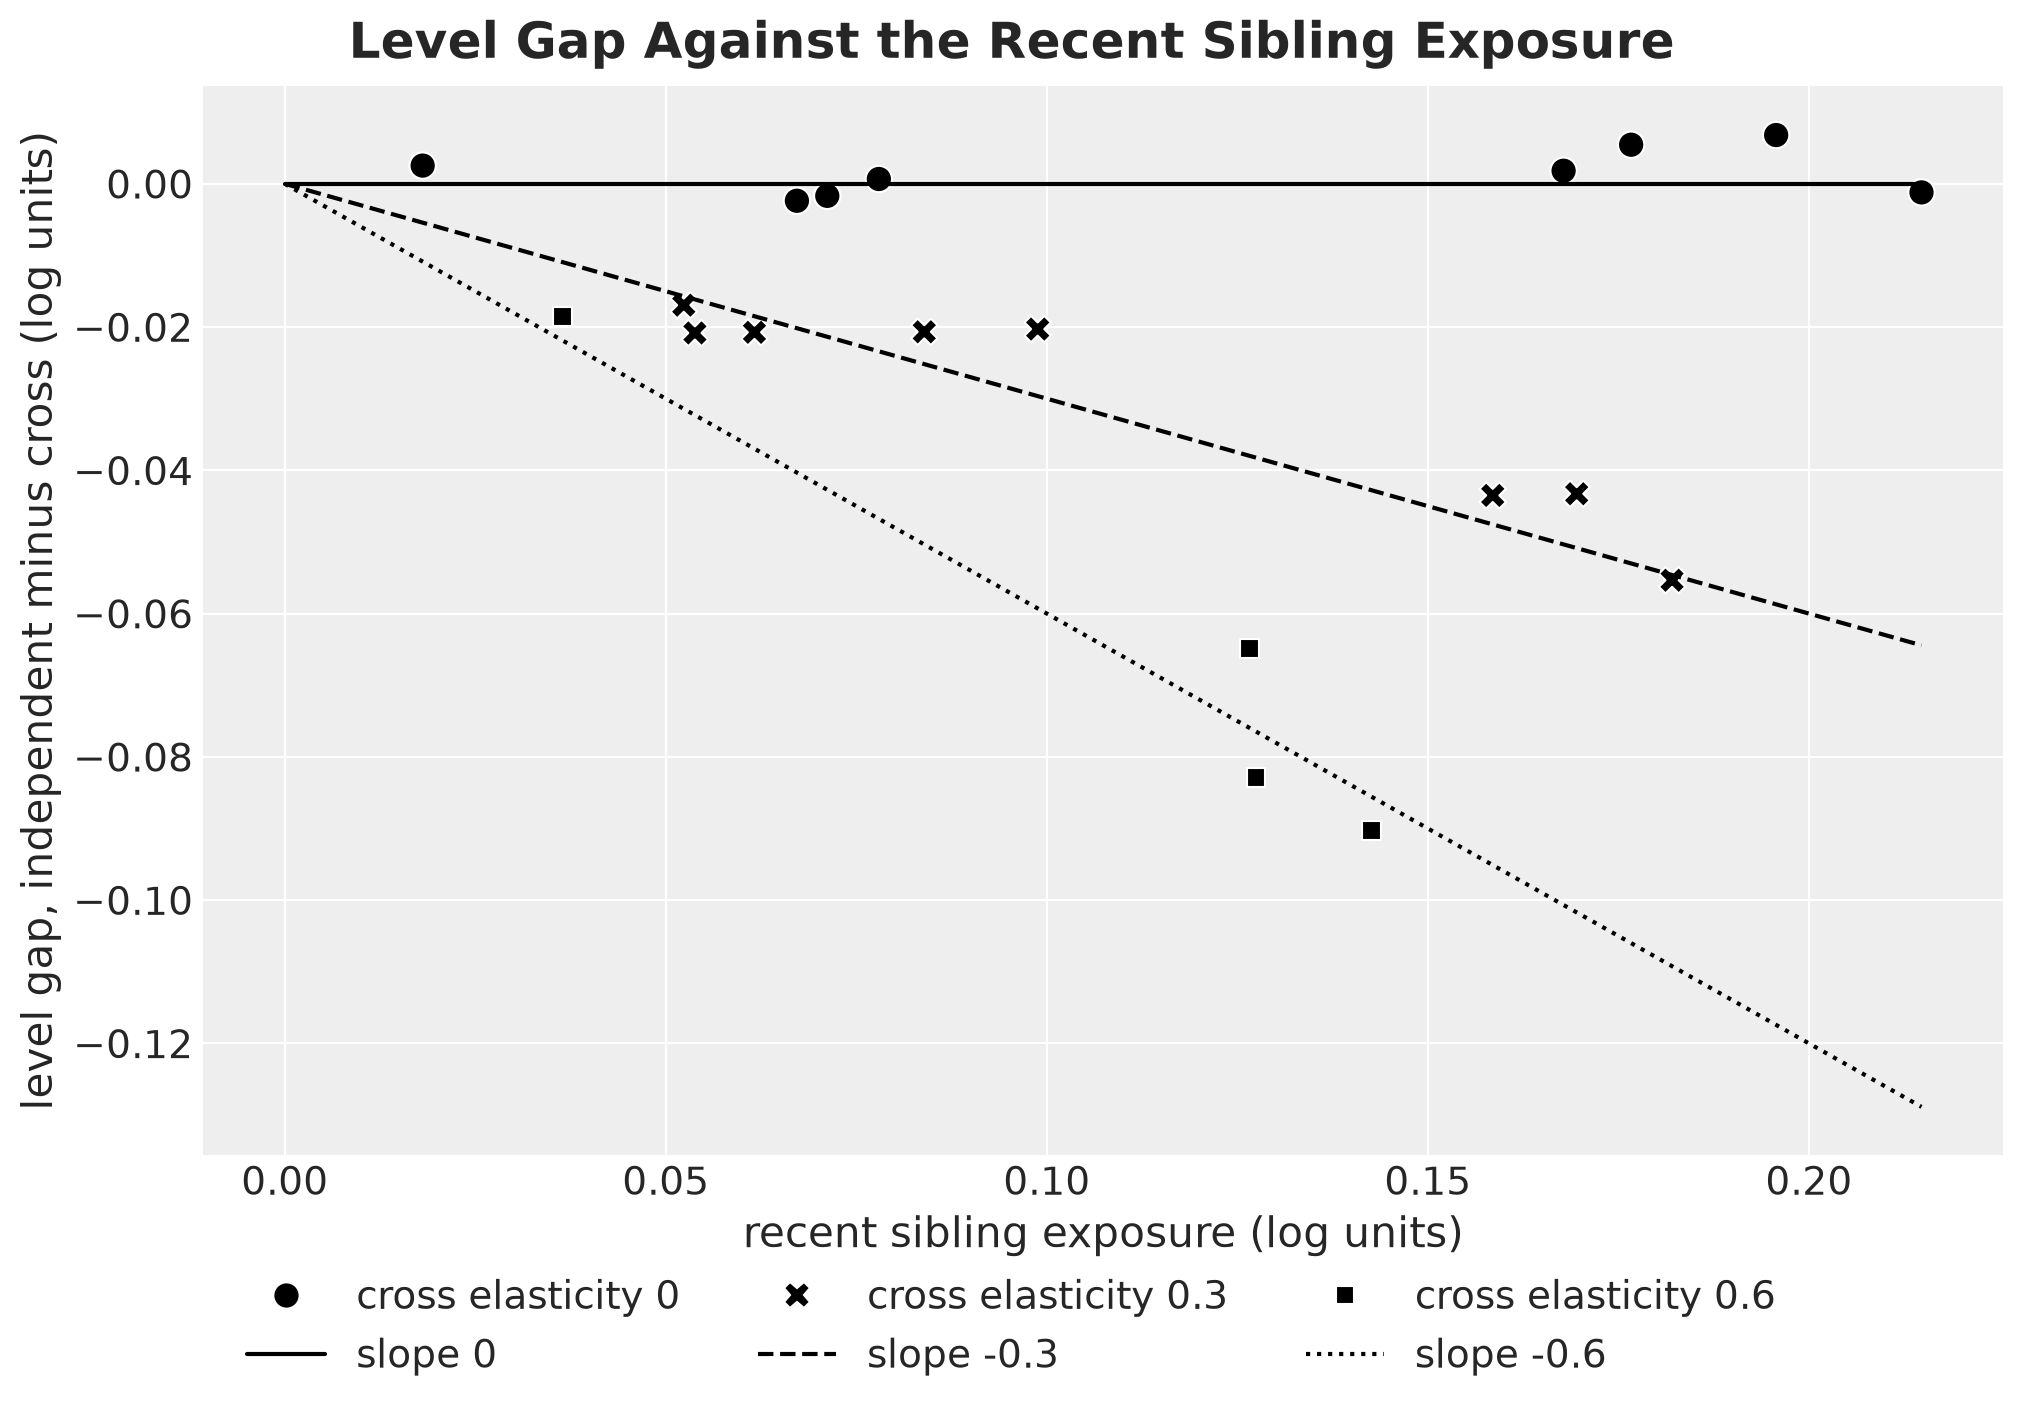

In [43]:
levels = sorted(set(setup.group_cross))

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=origin,
    x="recent sibling exposure",
    y="level gap",
    style="cross elasticity",
    style_order=levels,
    color="black",
    s=90,
    ax=ax,
)
markers, _ = ax.get_legend_handles_labels()
ax.get_legend().remove()

for marker, value in zip(markers, levels, strict=True):
    marker.set_label(f"cross elasticity {value:g}")

lines = [
    ax.plot(
        [0.0, float(exposure.max())],
        [0.0, -value * float(exposure.max())],
        color="black",
        linestyle=linestyle,
        label=f"slope {0.0 - value:g}",
    )[0]
    for value, linestyle in zip(levels, ["-", "--", ":"], strict=True)
]
ax.set(
    xlabel="recent sibling exposure (log units)",
    ylabel="level gap, independent minus cross (log units)",
)
# one column per cross elasticity: its marker above its reference line
fig.legend(
    handles=[handle for pair in zip(markers, lines, strict=True) for handle in pair],
    loc="outside lower center",
    ncol=len(levels),
)
fig.suptitle(
    "Level Gap Against the Recent Sibling Exposure", fontsize=18, fontweight="bold"
);

The points of each group lie on or near the line of their cross elasticity.

- **Cross elasticity of $0.6$.** Products $0$, $1$ and $2$ have an exposure of $0.13$ to $0.14$, because product $3$ was on promotion in the last week of the history. Their level gaps are between $-0.07$ and $-0.09$, against an expected $-0.08$ to $-0.09$. Product $3$ has the same cross elasticity and a small recent exposure, and its level gap is $-0.02$.
- **Cross elasticity of $0.3$.** Products $12$, $13$ and $15$ have the largest exposures of group $4$, because product $14$ was on promotion in two of the last four weeks. Their level gaps are $-0.04$ to $-0.06$. The other products of groups $2$ and $4$ have level gaps of about $-0.02$.
- **No cross elasticity.** The products of groups $3$ and $5$ have a level gap within $0.01$ of zero at every exposure. Products $8$ to $11$ have the largest exposures of the panel, $0.17$ to $0.22$, and the two models agree on them.

So on this panel the bias of the independent model follows the promotion calendar of the last weeks of the history and the size of the cross elasticity. With another calendar, other products would start low. In the *Out of Sample Evaluation* section we see what this costs under an asymmetric loss.

## Capacity Projection

Before we build the plans, we need the projection that keeps a plan within the capacities of the stores. Recall from *The Decision Problem* that on every day the orders of a store have to sum to at most its capacity $C_s$. In this section we work out the projection, write it in code and check it.

We use it twice in the next sections. The mean forecast plans project the orders of every day, and the solver projects the plan after every step.

### The Optimization Problem

Recall how the first post found the plan. The solver starts from an initial plan and improves it in many small steps. At every step it computes the gradient of the expected loss with respect to every order and moves the orders in the direction that lowers the loss. We use [Adam](https://arxiv.org/abs/1412.6980), a variant of gradient descent that adapts the step size of every order.

A gradient step does not know that an order cannot be negative. If a product is overstocked, the gradient tells the solver to order less of it, and when its order is already small the step can take it below zero. A negative order is not a plan that we can place.

So after every step the solver repairs the plan and replaces every negative order by zero. We call this repair the **clip at zero**. The clipped plan is the valid plan closest to the one that the step proposed, that is, the **Euclidean projection** of the proposed plan onto the set of non-negative orders. A gradient method with a projection after every step is called **projected gradient descent**.

With a capacity constraint we have to do (*repair*) more. Each constraint involves the orders of one store on one day. We call these $P$ orders a **block**, so the plan has $H \times S$ blocks.

We fix a store $s$ and a day $t$ and write $a \in \mathbb{R}^P$ for the block of that store and day, with entries $a_j = a_{t,(s,j)}$. The proposed orders of the block have to become non-negative and also sum to at most $C_s$. The blocks that satisfy both conditions form the **capacity set** of store $s$,

$$
A_s = \left\{ x \in \mathbb{R}^P : x \geq 0, \; \sum_{j=1}^{P} x_j \leq C_s \right\}.
$$

The capacity set depends on the store through its capacity, and it is the same on every day. In these terms, a plan is feasible when each of its blocks lies in the capacity set of its store.

We can encode the "distance between two plans" as the sum of the squared distance between them (i.e. the Euclidean distance). Since there is no constraint linking two blocks, the closest feasible plan is the one in which every block is the closest feasible block. Hence, we can repair (project) the blocks one by one.

### The Projection

The repair of a block is its Euclidean projection $\Pi_s(a)$ onto $A_s$. That is, it is the point of $A_s$ closest to the proposed orders $a$. The projection has two cases.

- **Slack capacity.** If the clipped vector $\max(a, 0)$ fits the capacity $C_s$, then there is no need to repair the block.
- **Full capacity.** If the clipped vector exceeds the capacity, the projection lies on the face of $A_s$ where the orders sum to $C_s$.

On that face the projection lowers every order of the block by the same amount $\theta_{t,s}$, the **threshold**, and sets the orders that fall below zero to zero:

$$
\Pi_s(a)_j = \max(a_j - \theta_{t,s}, 0).
$$

The common amount comes from the shape of the face. Its normal is the vector of ones, so the shortest way from a point to the face takes the same amount from every coordinate. The clip keeps the result non-negative.

We have to choose $\theta_{t,s}$ so that the result sums to $C_s$. For this we need to know which orders stay positive after the shift, since only those orders count in the sum.

Here the ranking of the proposed orders helps. The shift is the same for every product, so it does not change which product has the larger order. If the projection sets the order of a product to zero, it also sets to zero every product of the block with a smaller proposed order (Lemma $1$ of [Duchi et al. (2008)](https://doi.org/10.1145/1390156.1390191)). Hence the orders that stay positive are the largest proposed orders of the block, and the only unknown is how many there are.

So we sort the proposed orders of the block. Let $u_1 \geq u_2 \geq \dots \geq u_P$ be the entries of $a$ from the largest to the smallest, so that $u_1$ is the largest proposed order of the block and $u_P$ is the smallest. These are the orders **before** the projection, as the gradient step proposed them, and some of them can be negative.

Note that $u$ has the same numbers as $a$ and only their position changes. We use $u$ to find the threshold, and then we subtract the threshold from $a$ in the original order of the products.

Let $\rho_{t,s}$ be the number of orders of the block that stay positive after the projection. Suppose for a moment that we knew this number. Then the orders that stay positive are $u_1, \dots, u_{\rho_{t,s}}$, each of them lowered by $\theta_{t,s}$, and the other orders are zero. The result sums to $\sum_{r=1}^{\rho_{t,s}} u_r - \rho_{t,s} \, \theta_{t,s}$. We set this sum equal to $C_s$ and solve for the threshold:

$$
\theta_{t,s} = \frac{1}{\rho_{t,s}} \left( \sum_{r=1}^{\rho_{t,s}} u_r - C_s \right).
$$

In other words, the threshold is the excess of the $\rho_{t,s}$ largest proposed orders over the capacity, split evenly among them.

How do we find $\rho_{t,s}$? [Duchi et al. (2008)](https://doi.org/10.1145/1390156.1390191) give the answer in their Lemma $2$ and Figure $1$. They project a vector $v \in \mathbb{R}^n$ onto the set of non-negative vectors that sum to $z > 0$. Let $\mu$ be the vector $v$ sorted in descending order. The lemma states that the number of strictly positive entries of the projection is

$$
\rho(z, \mu) = \max \left\{ j \in \{1, \dots, n\} : \mu_j - \frac{1}{j} \left( \sum_{r=1}^{j} \mu_r - z \right) > 0 \right\}.
$$

In our notation the vector $v$ is the block of proposed orders $a$, the sorted vector $\mu$ is $u$, the total $z$ is the capacity $C_s$ and the dimension $n$ is the number of products $P$. The definition becomes

$$
\rho_{t,s} = \max \left\{ k \in \{1, \dots, P\} : u_k - \frac{1}{k} \left( \sum_{r=1}^{k} u_r - C_s \right) > 0 \right\}.
$$

Let's read this definition as a test on every candidate count $k = 1, \dots, P$. First, we assume that exactly the $k$ largest proposed orders stay positive. Under this assumption the threshold formula above gives the candidate threshold

$$
\theta^{(k)} = \frac{1}{k} \left( \sum_{r=1}^{k} u_r - C_s \right).
$$

Next, we check the assumption. The smallest of the $k$ largest orders is $u_k$, so all of them stay positive after the shift when $u_k - \theta^{(k)} > 0$. This is the condition inside the braces. If instead $u_k - \theta^{(k)} \leq 0$, the candidate threshold sets to zero an order that we assumed positive, so the count $k$ is too large.

The number $\rho_{t,s}$ is the largest count that passes the test, and the threshold is the candidate threshold of that count, $\theta_{t,s} = \theta^{(\rho_{t,s})}$.

Here are two important remarks about the test. The count $k = 1$ always passes, since $u_1 - \theta^{(1)} = C_s > 0$, so $\rho_{t,s}$ is at least one. Also, the test is the same as $\sum_{r=1}^{k} (u_r - u_k) < C_s$, and this sum does not decrease with $k$. Hence the counts that pass are exactly $1, \dots, \rho_{t,s}$.

Let's work out an example by hand. We take the block $a = (3, -1, 2)$ with a capacity of $C_s = 4$ units. The clipped orders sum to $5$ units, so we are in the full capacity case. The sorted vector is $u = (3, 2, -1)$, and we test the three counts:

- **One order.** The candidate threshold is $\theta^{(1)} = 3 - 4 = -1$ and $u_1 - \theta^{(1)} = 4 > 0$, so the count passes.
- **Two orders.** The candidate threshold is $\theta^{(2)} = (5 - 4) / 2 = 0.5$ and $u_2 - \theta^{(2)} = 1.5 > 0$, so the count passes.
- **Three orders.** The candidate threshold is $\theta^{(3)} = (4 - 4) / 3 = 0$ and $u_3 - \theta^{(3)} = -1 \leq 0$, so the count fails.

The largest count that passes is $\rho_{t,s} = 2$, with the threshold $\theta_{t,s} = 0.5$. We subtract it from $a$ and clip at zero, which gives the projection $\Pi_s(a) = (2.5, 0, 1.5)$. It sums to $4$ units, the capacity.

Next, let's look at the test on a larger block. We take the proposed orders of $8$ products, one of them negative, and a capacity of $C_s = 14$ units. The function `candidate_thresholds` sorts the proposed orders and returns the candidate threshold of every count, together with the largest count that passes the test.

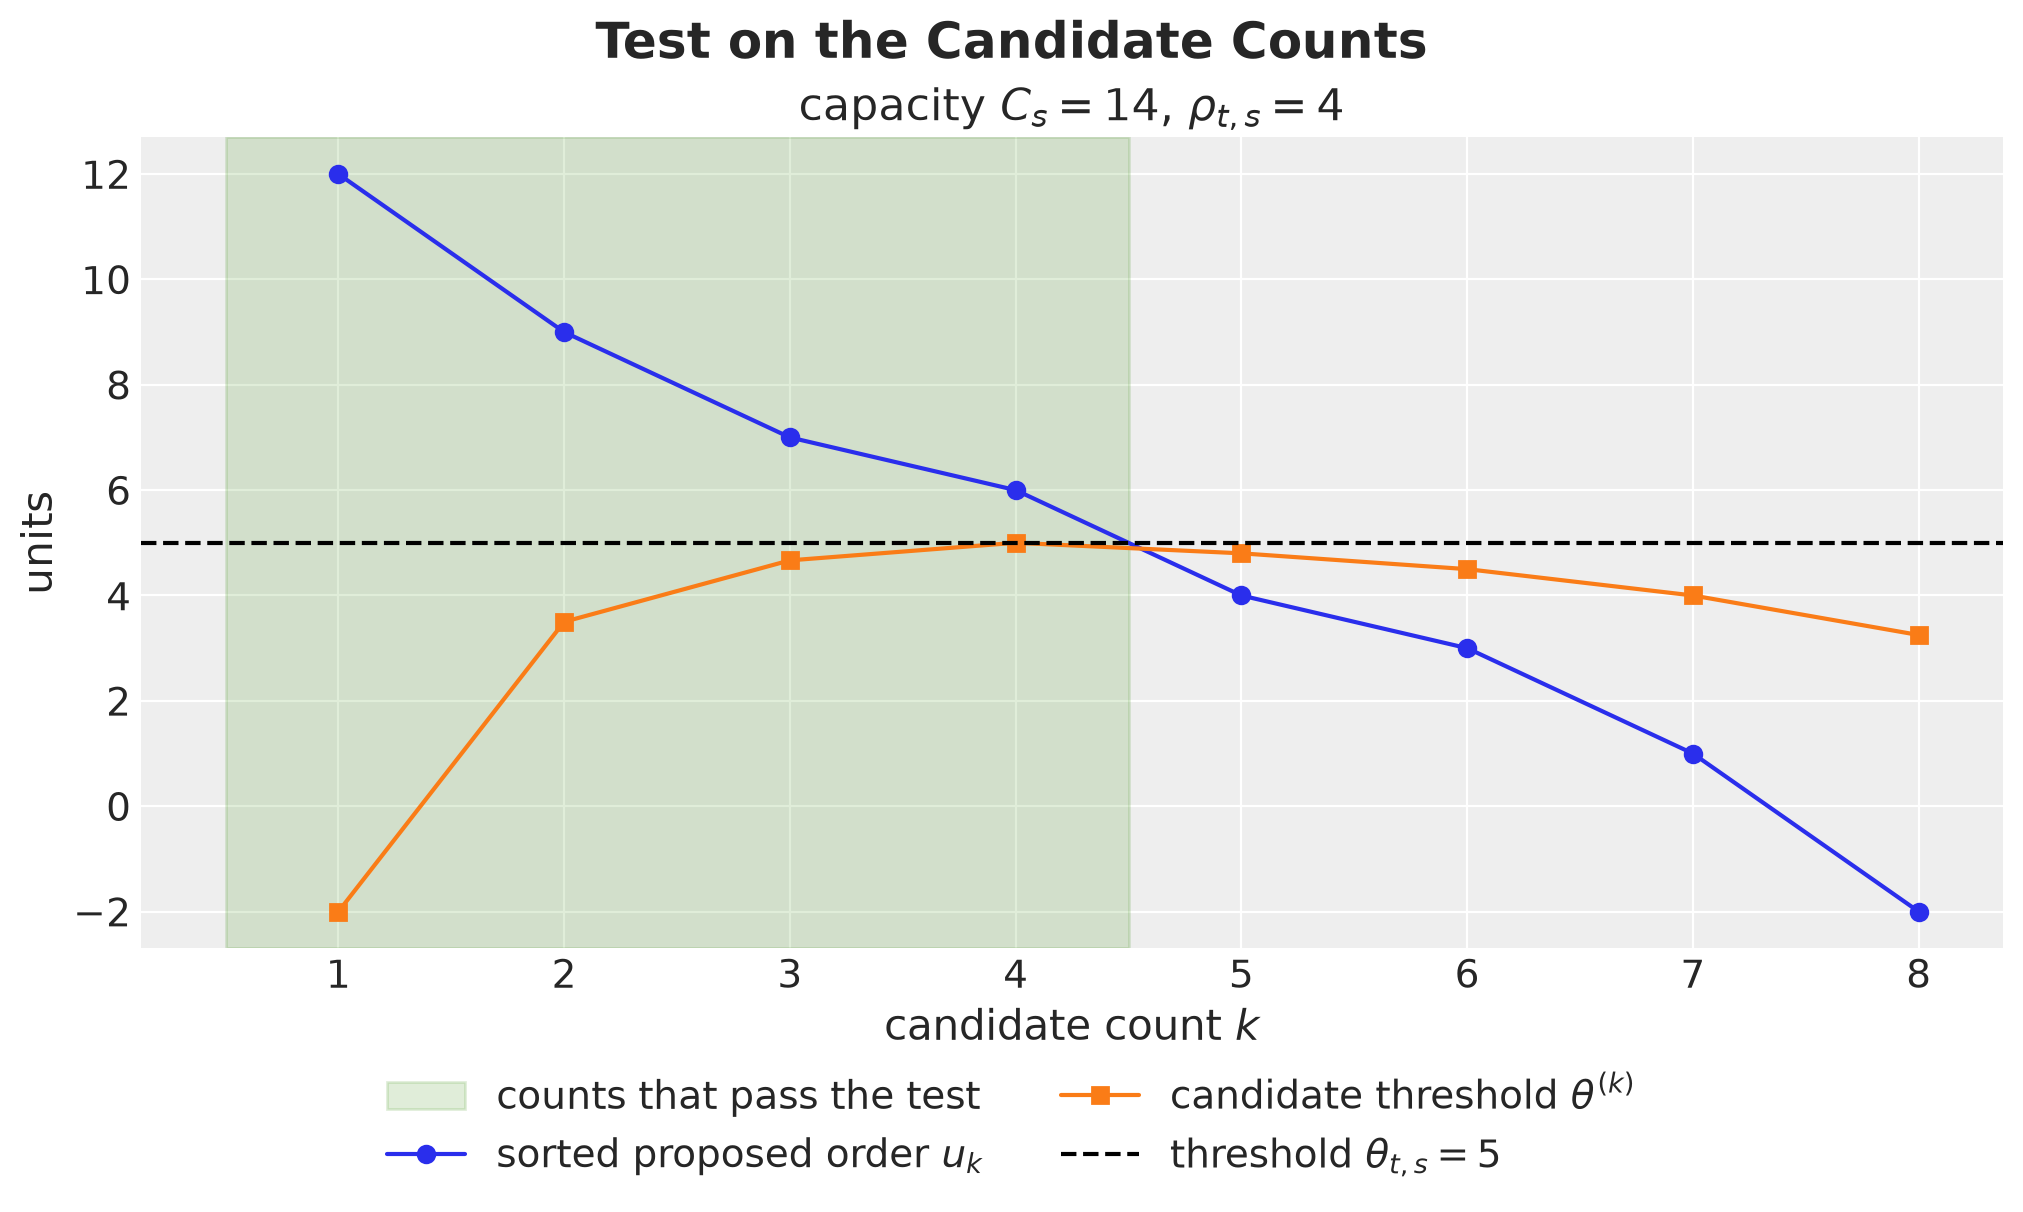

In [44]:
def candidate_thresholds(
    a: Float[Array, " n_products"], capacity: ScalarLike
) -> tuple[Float[Array, " n_products"], Float[Array, " n_products"], int]:
    """Sorted proposed orders, candidate threshold of every count, and rho."""
    u = jnp.sort(a)[::-1]
    k = jnp.arange(1, a.shape[0] + 1)
    theta_candidates = (jnp.cumsum(u) - capacity) / k
    rho = jnp.max(jnp.where(u - theta_candidates > 0.0, k, 0))
    return u, theta_candidates, int(rho)


# the proposed orders of a block of eight products, in the order of the products
block_example = jnp.array([7.0, 12.0, -2.0, 4.0, 9.0, 1.0, 6.0, 3.0])
# the capacities of two stores that get this block
block_capacities = [14.0, 29.0]
block_counts = np.arange(1, block_example.shape[0] + 1)

u_block, theta_candidates_block, rho_block = candidate_thresholds(
    block_example, block_capacities[0]
)
theta_block = float(theta_candidates_block[rho_block - 1])

fig, ax = plt.subplots(layout="constrained")
ax.axvspan(
    0.5, rho_block + 0.5, color="C2", alpha=0.15, label="counts that pass the test"
)
ax.plot(block_counts, u_block, "o-", color="C0", label="sorted proposed order $u_k$")
ax.plot(
    block_counts,
    theta_candidates_block,
    "s-",
    color="C1",
    label=r"candidate threshold $\theta^{(k)}$",
)
ax.axhline(
    theta_block,
    color="black",
    linestyle="--",
    label=rf"threshold $\theta_{{t,s}} = {theta_block:g}$",
)
ax.set(
    title=rf"capacity $C_s = {block_capacities[0]:g}$, $\rho_{{t,s}} = {rho_block}$",
    xlabel="candidate count $k$",
    ylabel="units",
    xticks=block_counts,
)
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Test on the Candidate Counts", fontsize=18, fontweight="bold");

The sorted proposed orders go down with the count, and the test compares each of them with the candidate threshold of its count. The first $4$ counts pass, since there the order is above the candidate threshold. From the fifth count on the order is below it. Hence $\rho_{t,s} = 4$, and the threshold is the candidate threshold of that count, $\theta_{t,s} = 5$ units.

Now we can see the threshold as a level. The next figure shows the same block in two stores, one with a capacity of $14$ units and one with a capacity of $29$ units. The dashed line is the threshold, and the dark part of a bar above it is the projected order.

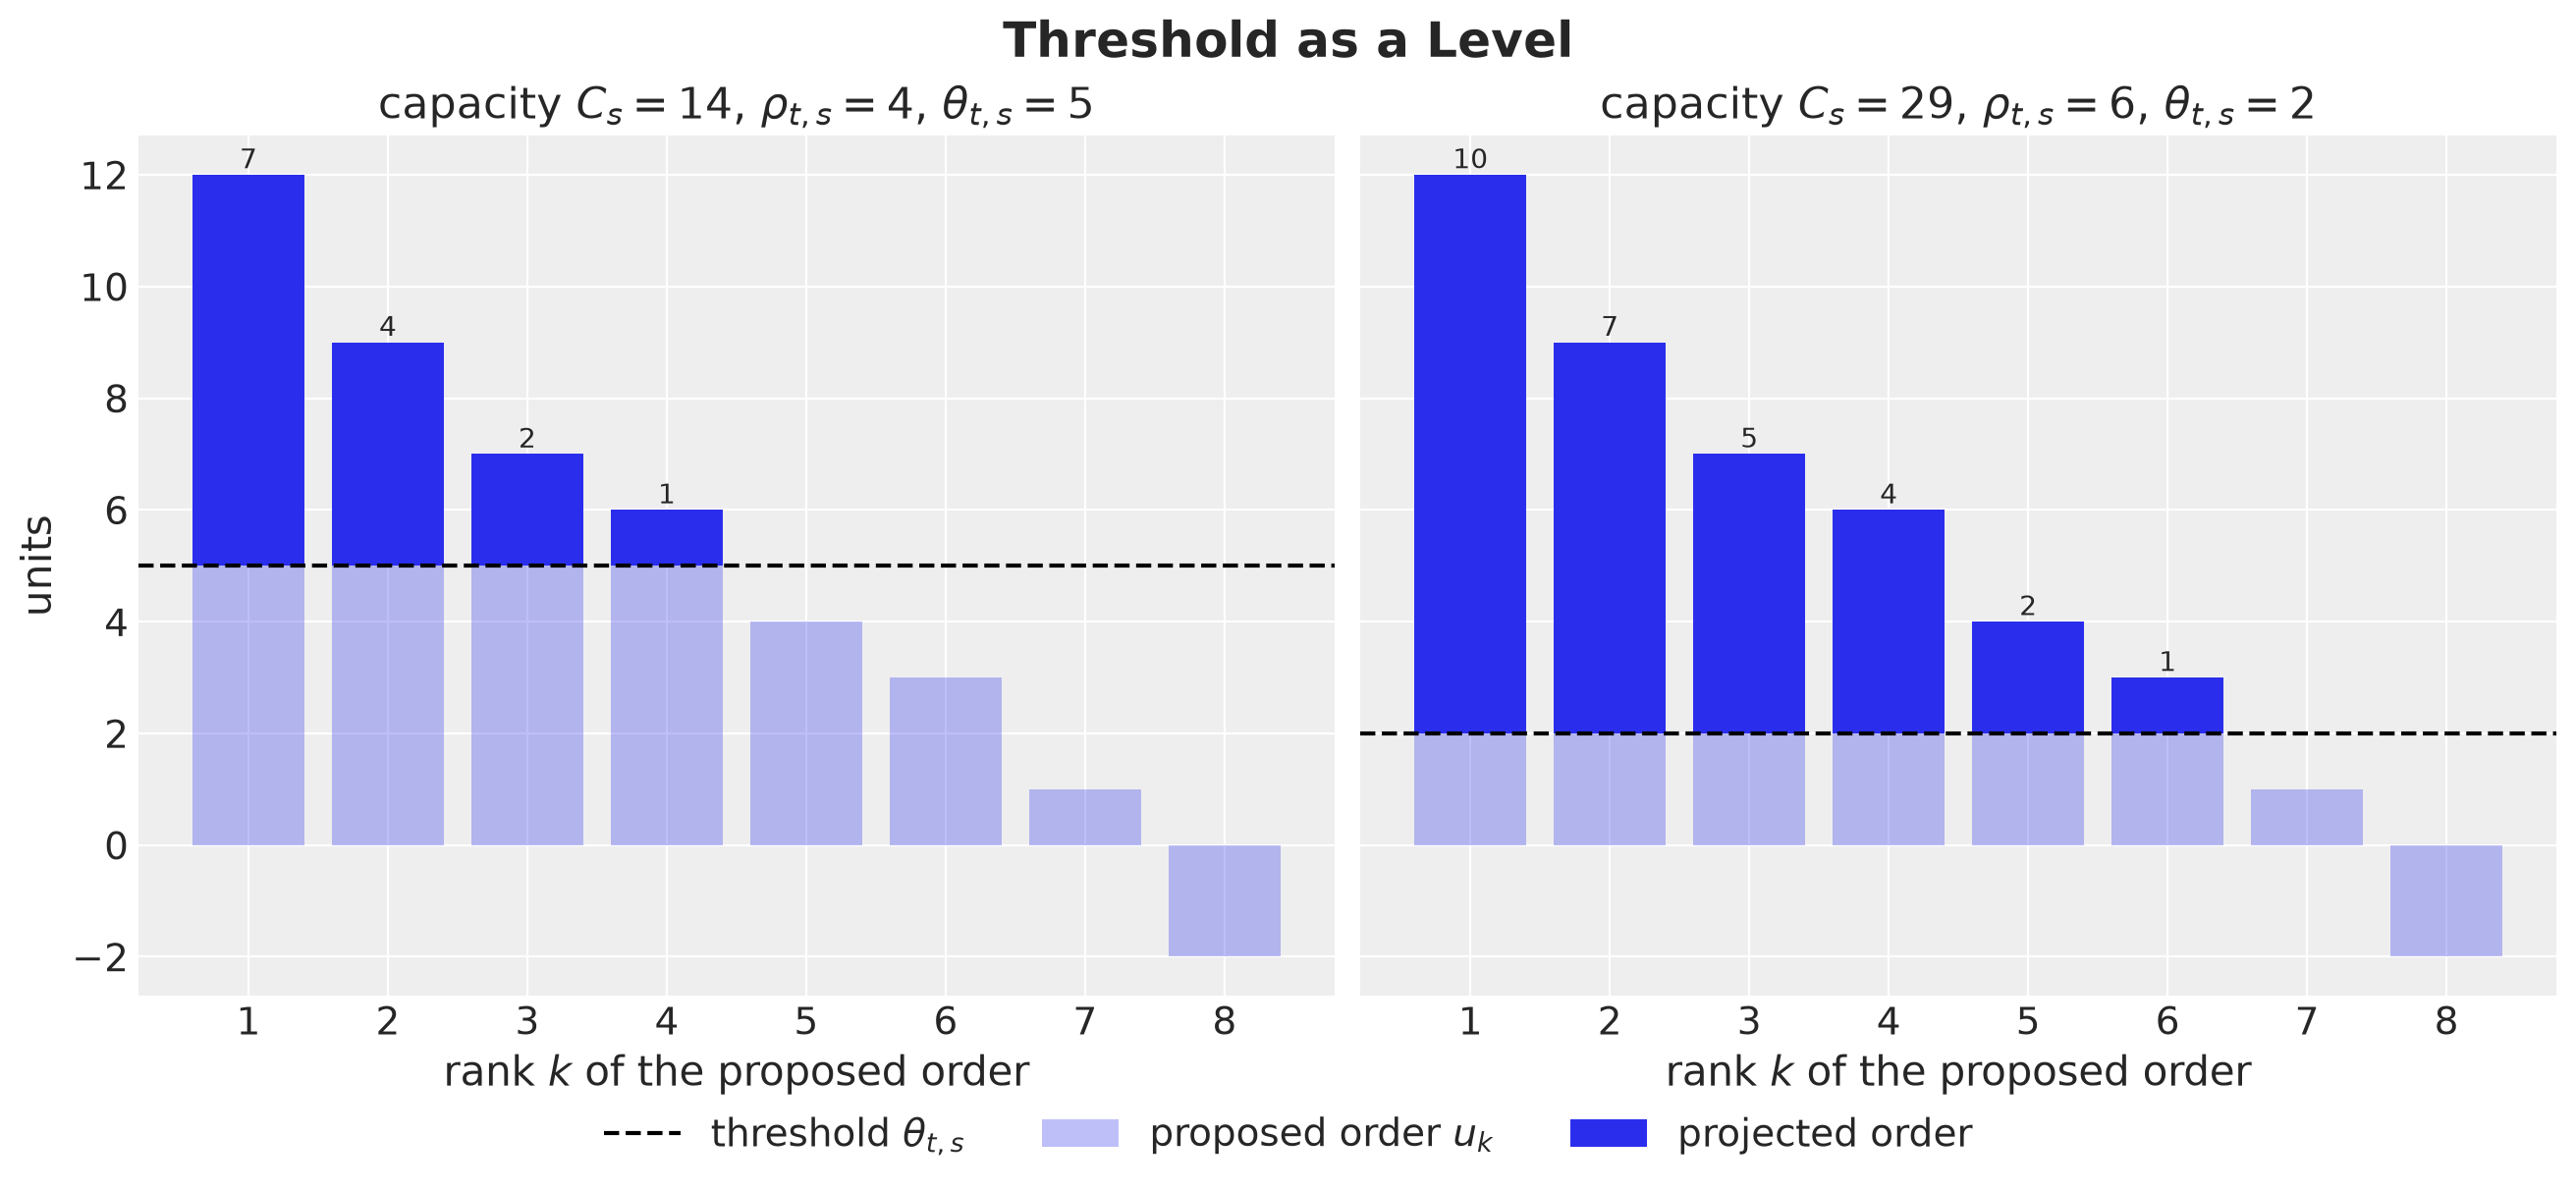

In [45]:
fig, axes = plt.subplots(
    ncols=2, figsize=(13, 6), sharex=True, sharey=True, layout="constrained"
)

for ax, capacity_block in zip(axes, block_capacities, strict=True):
    u_block, theta_candidates_block, rho_block = candidate_thresholds(
        block_example, capacity_block
    )
    theta_block = float(theta_candidates_block[rho_block - 1])
    projected_block = jnp.maximum(u_block - theta_block, 0.0)

    ax.bar(block_counts, u_block, color="C0", alpha=0.3, label="proposed order $u_k$")
    bars = ax.bar(
        block_counts,
        projected_block,
        bottom=theta_block,
        color="C0",
        label="projected order",
    )
    ax.bar_label(bars, labels=[f"{x:g}" if x > 0 else "" for x in projected_block])
    ax.axhline(
        theta_block, color="black", linestyle="--", label=r"threshold $\theta_{t,s}$"
    )
    ax.set(
        title=(
            rf"capacity $C_s = {capacity_block:g}$, $\rho_{{t,s}} = {rho_block}$, "
            rf"$\theta_{{t,s}} = {theta_block:g}$"
        ),
        xlabel="rank $k$ of the proposed order",
        xticks=block_counts,
    )

axes[0].set(ylabel="units")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Threshold as a Level", fontsize=18, fontweight="bold");

The projection keeps the part of every proposed order that is above the level, and the numbers on the bars are the projected orders. In both panels they sum to the capacity of the store. With a capacity of $14$ units the threshold is $5$ units and $4$ orders stay positive. With a capacity of $29$ units the threshold drops to $2$ units and $6$ orders stay positive. A larger capacity needs a smaller shift, so more products stay in the plan.

Note that the threshold depends on the store through the capacity $C_s$, and on both the store and the day through the proposed orders of the block. In the slack case the projection subtracts nothing, so we set $\theta_{t,s} = 0$ and the formula $\Pi_s(a)_j = \max(a_j - \theta_{t,s}, 0)$ covers both cases.

Here is an important observation: the threshold has no product index. All the products of a block share one threshold, so every order that stays positive gives up the same number of units. This comes from the Euclidean distance, which counts a unit of every product the same.

There is one threshold per block because there is one capacity constraint per block. Keep in mind that the common amount is what one projection removes after one step. The solver takes many steps, each followed by a projection, so over the whole solve the products of a block do not have to give up the same number of units.

The common threshold also fits our setting, where every product has the same holding cost $h$ and the same lost margin $p$, so the repair has no reason to prefer one product. If the products had different margins, we would put the margins in the loss and keep the projection as it is, because the capacity counts units. We leave this for the *Next Steps*.

When we put the blocks together, we get the projection $\Pi$ of the whole plan $a = (a_{t,i})$,

$$
\Pi(a)_{t,(s,j)} = \max\left( a_{t,(s,j)} - \theta_{t,s}, \, 0 \right),
$$

with one threshold per store and day, $H \times S$ in total. Where the clipped orders exceed the capacity the threshold is positive, since a threshold of zero would leave the clipped orders, which sum to more than $C_s$.

The code follows these steps for one block:

1. **Clip.** Set the negative orders to zero. If the result fits the capacity of the store, it is the projection.
2. **Sort.** Sort the proposed orders of the block from the largest and take their cumulative sums.
3. **Count.** Find $\rho_{t,s}$, the number of orders that stay positive.
4. **Threshold.** Compute $\theta_{t,s}$ from the $\rho_{t,s}$ largest orders.
5. **Shift.** Subtract $\theta_{t,s}$ from every order and clip at zero.

The function `project_simplex` does steps $2$ to $5$, and `project_capacity` chooses between the two cases. Both take one block and the capacity of its store.

The function `project_day` applies `project_capacity` to the $S$ blocks of a day, each with the capacity of its store. The function `project_orders` applies `project_day` to every day of the horizon.

In [46]:
def project_simplex(
    a: Float[Array, " n_products"], capacity: ScalarLike
) -> Float[Array, " n_products"]:
    """Euclidean projection onto {a >= 0, sum(a) = capacity} (Duchi et al., 2008)."""
    # step 2: the orders from the largest and their cumulative sums
    u = jnp.sort(a)[::-1]
    cumulative = jnp.cumsum(u)
    k = jnp.arange(1, a.shape[0] + 1)
    # step 3: rho, the largest k whose k-th largest order stays positive
    stays_positive = u - (cumulative - capacity) / k > 0.0
    rho = jnp.max(jnp.where(stays_positive, k, 0))
    # step 4: the threshold that makes the rho largest orders sum to the capacity
    theta = (cumulative[rho - 1] - capacity) / rho
    # step 5: the same shift for every order, then the clip
    return jnp.maximum(a - theta, 0.0)


def project_capacity(
    a: Float[Array, " n_products"], capacity: ScalarLike
) -> Float[Array, " n_products"]:
    """Euclidean projection of one block onto {a >= 0, sum(a) <= capacity}."""
    # step 1: the clip, which is the projection when it fits the capacity
    clipped = jnp.maximum(a, 0.0)
    fits = clipped.sum() <= capacity

    return jnp.where(fits, clipped, project_simplex(a, capacity))


# one day: the blocks of all stores, (n_stores, n_products), each with the capacity
# of its store, (n_stores,)
project_day = jax.vmap(project_capacity, in_axes=(0, 0))
# the whole horizon, (horizon, n_stores, n_products): the capacities are the same on
# every day
project_orders = jax.vmap(project_day, in_axes=(0, None))

Five checks follow the definition:

- **Feasible point.** It comes back unchanged.
- **Example by hand.** The vector $[3, -1, 2]$ with a capacity of $4$ projects to $[2.5, 0, 1.5]$. Here two orders stay positive and the threshold is $0.5$.
- **Random point.** The projection subtracts the same amount from every order that stays positive.
- **No capacity.** The projection is the clip at zero, which the *Capacity Sensitivity* section relies on.
- **One capacity per store.** We give the same proposed orders to three stores with capacities of $10$, $20$ and $60$ units, on each of two days. The first two stores use their whole capacity. In the third the clipped orders fit, so its projection is the clip at zero.

In [47]:
# the checks draw from a key of their own, so that they do not change the data
key_point, key_orders, key_capacity = random.split(random.PRNGKey(seed + 1), 3)

feasible = jnp.array([1.0, 2.0, 0.5])
assert jnp.allclose(project_capacity(feasible, 4.0), feasible)

assert jnp.allclose(
    project_capacity(jnp.array([3.0, -1.0, 2.0]), 4.0), jnp.array([2.5, 0.0, 1.5])
)

point = 5 * random.normal(key_point, (20,))
projection = project_capacity(point, 10.0)
assert jnp.allclose(projection.sum(), 10.0) and bool((projection >= 0).all())
shift = (point - projection)[projection > 0]
assert jnp.allclose(shift, shift[0], atol=1e-4)

assert jnp.allclose(project_capacity(point, jnp.inf), jnp.maximum(point, 0.0))

# the same proposed orders on two days in three stores that differ in capacity only
store_capacities = jnp.array([10.0, 20.0, 60.0])
projections = project_orders(jnp.tile(point, (2, 3, 1)), store_capacities)
assert jnp.allclose(projections[:, :2].sum(axis=-1), store_capacities[:2])
# the store with 10 units gets the projection of the single block above
assert jnp.allclose(projections[:, 0], projection)
assert jnp.allclose(projections[:, 2], jnp.maximum(point, 0.0))

A projection maps every point of its set to itself. The projected orders of a block are in the set $A_s$ of its store, so a second projection does not move them:

$$
\Pi_s(\Pi_s(a)) = \Pi_s(a).
$$

This property is called **idempotence**. Let's check it on $1{,}000$ random vectors of $20$ orders. Each vector has its own capacity, drawn between $1$ and $60$ units, so that the capacity binds for some vectors and not for others.

In [48]:
proposed = 5 * random.normal(key_orders, (1_000, 20))
capacities = random.uniform(key_capacity, (1_000,), minval=1.0, maxval=60.0)

project_batch = jax.vmap(project_capacity)
once = project_batch(proposed, capacities)
twice = project_batch(once, capacities)
assert jnp.allclose(twice, once, atol=1e-5)

pl.DataFrame(
    {
        "share of vectors at full capacity": [
            float((jnp.maximum(proposed, 0.0).sum(axis=1) > capacities).mean())
        ],
        # in scientific notation, since the tables show three decimals
        "largest change of the second projection": [
            f"{float(jnp.abs(twice - once).max()):.1e}"
        ],
    }
)

share of vectors at full capacity,largest change of the second projection
f64,str
0.632,"""1.2e-06"""


The capacity binds for $63\%$ of the vectors. The second projection moves no order by more than $1.2 \times 10^{-6}$ units, which is floating point error, so the projection is idempotent on all $1{,}000$ vectors.

The next figure shows the projection in two dimensions, for two products and two stores. The first store has a capacity of $10$ units and the second a capacity of $14$ units, and both get the same three proposed orders. The open circles are orders as a gradient step proposes them, before the repair, so a coordinate can be negative.

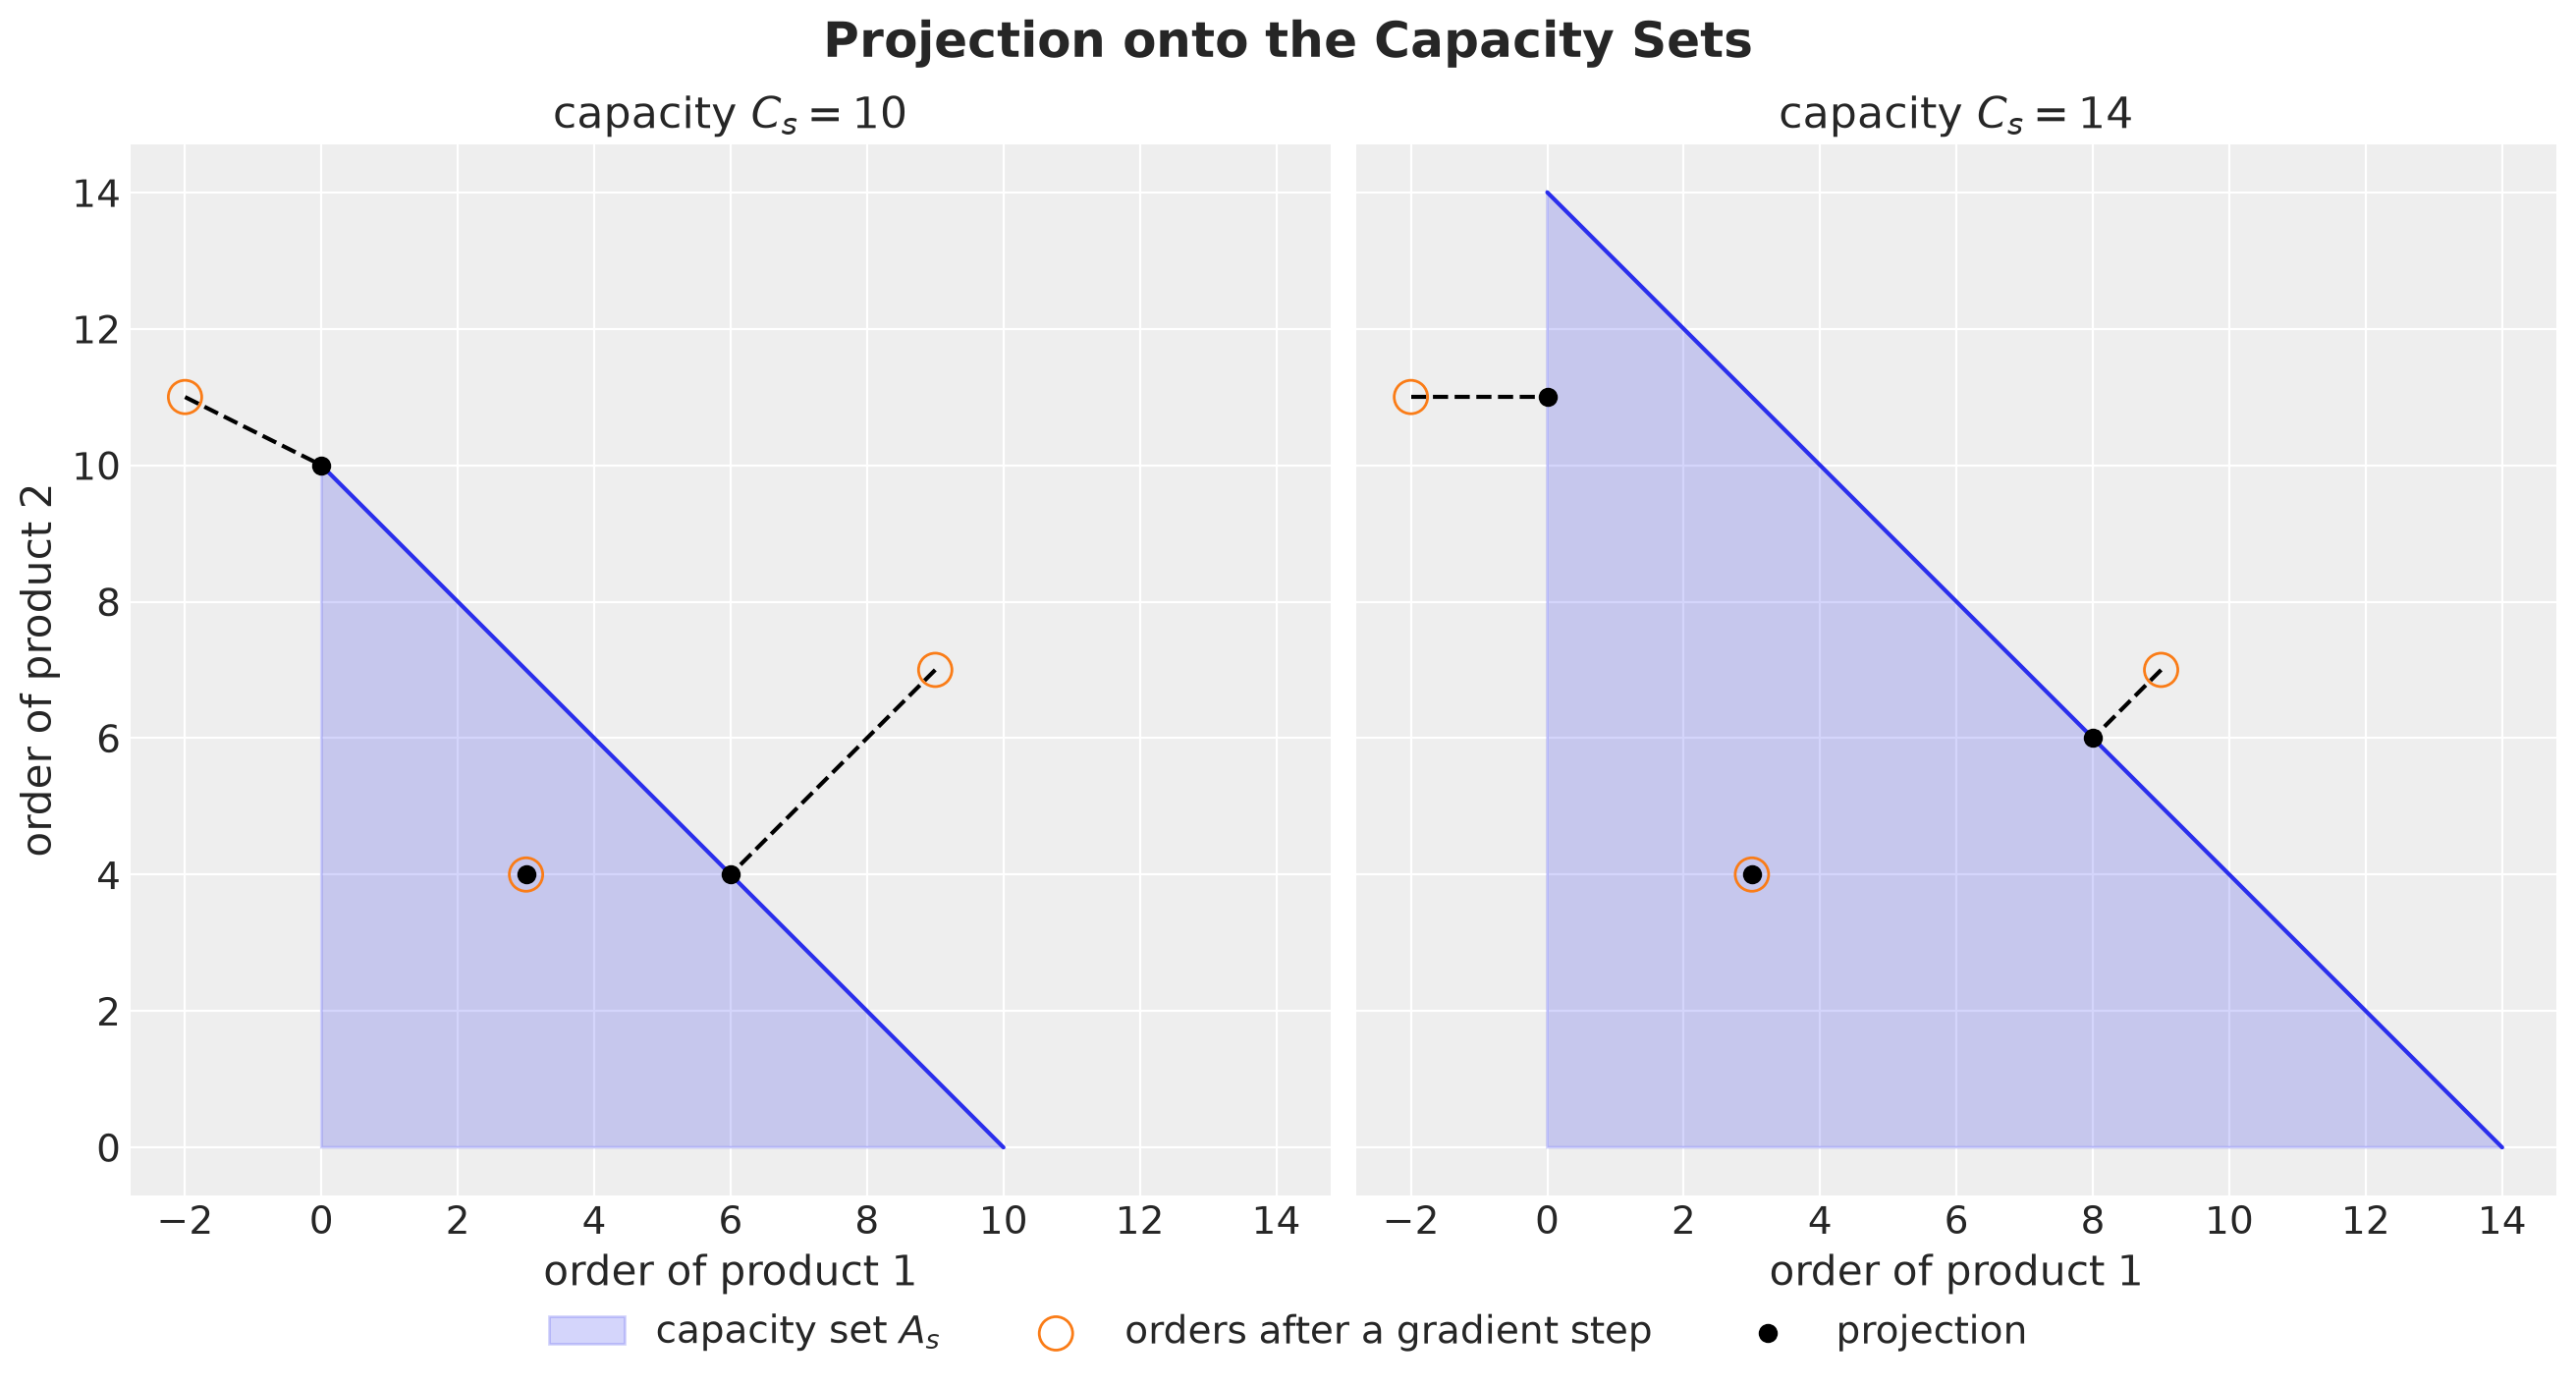

In [49]:
capacity_examples = jnp.array([10.0, 14.0])
proposed_example = jnp.array([[3.0, 4.0], [-2.0, 11.0], [9.0, 7.0]])
# the same proposed orders in both stores: (n_stores, n_points, n_products)
projected_examples = jax.vmap(
    jax.vmap(project_capacity, in_axes=(0, None)), in_axes=(None, 0)
)(proposed_example, capacity_examples)

fig, axes = plt.subplots(
    ncols=2, figsize=(13, 7), sharex=True, sharey=True, layout="constrained"
)

for store, ax in enumerate(axes):
    capacity_store = float(capacity_examples[store])
    projected = projected_examples[store]
    ax.fill(
        [0, capacity_store, 0],
        [0, 0, capacity_store],
        color="C0",
        alpha=0.2,
        label="capacity set $A_s$",
    )
    ax.plot([0, capacity_store], [capacity_store, 0], color="C0")

    for (x, y), (px, py) in zip(proposed_example, projected, strict=True):
        ax.plot([x, px], [y, py], "--", color="black")

    ax.scatter(
        proposed_example[:, 0],
        proposed_example[:, 1],
        s=150,
        facecolors="none",
        edgecolors="C1",
        zorder=3,
        label="orders after a gradient step",
    )
    ax.scatter(
        projected[:, 0], projected[:, 1], color="black", zorder=4, label="projection"
    )
    ax.set(
        title=f"capacity $C_s = {capacity_store:g}$",
        xlabel="order of product 1",
        aspect="equal",
    )

axes[0].set(ylabel="order of product 2")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Projection onto the Capacity Sets", fontsize=18, fontweight="bold");

The same proposed orders end at different points in the two stores.

- **Inside both triangles.** The proposed orders $(3, 4)$ fit both capacities, so they stay where they are in both stores, and the projection sits inside the circle.
- **Above both diagonals.** The proposed orders $(9, 7)$ exceed both capacities, and each projection takes the same amount from both products. With a capacity of $10$ the threshold is $3$ units and the projection ends at $(6, 4)$. With a capacity of $14$ the threshold is $1$ unit and it ends at $(8, 6)$.
- **Negative order.** The step proposed $-2$ units of product $1$ and $11$ units of product $2$, and both projections set the order of product $1$ to zero. With a capacity of $10$ the remaining $11$ units do not fit, so the projection lowers the order of product $2$ to $10$ units, the corner where the whole capacity goes to product $2$. With a capacity of $14$ they fit, so the projection is the clip at zero and the threshold is zero.

## Inventory Simulator

We reuse the simulator of the first post, with the initial stock as an argument because it differs across series. The loss of a scenario is the sum over the series, and we keep the stock and lost sales paths per series to split the loss by product later.

In [50]:
class Simulation(NamedTuple):
    """Loss, stock path and lost sales path of a plan against demand paths."""

    loss: Float[Array, "*batch"]
    inventory: Float[Array, "*batch horizon"]
    lost_sales: Float[Array, "*batch horizon"]


def simulate(
    orders: Float[Array, " horizon"],
    demand: Float[Array, " horizon"],
    initial_inventory: ScalarLike,
    config: InventoryConfig,
) -> Simulation:
    """Run the inventory dynamics of one plan against one demand path."""

    def step(
        inventory: ScalarLike, inputs: tuple[ScalarLike, ScalarLike]
    ) -> tuple[ScalarLike, tuple[ScalarLike, ScalarLike, ScalarLike]]:
        order_t, demand_t = inputs
        available = inventory + order_t  # y_t
        sales_t = jnp.minimum(available, demand_t)
        lost_t = demand_t - sales_t
        inventory = available - sales_t
        cost_t = config.holding_cost * inventory + config.lost_sales_cost * lost_t
        return inventory, (inventory, lost_t, cost_t)

    _, (inventory_path, lost_path, cost_path) = jax.lax.scan(
        step, jnp.asarray(initial_inventory, dtype=orders.dtype), (orders, demand)
    )
    return Simulation(cost_path.sum(), inventory_path, lost_path)


# one plan (horizon, n_series) against one demand path (horizon, n_series): the
# results of every series, with the paths of shape (n_series, horizon)
simulate_series = jax.vmap(simulate, in_axes=(1, 1, 0, None))
# one plan against a batch of demand paths (scenarios, horizon, n_series)
simulate_scenarios = jax.jit(
    jax.vmap(simulate_series, in_axes=(None, 0, None, None)), static_argnames="config"
)

The **mean forecast plan** of a model orders, day by day, the mean demand that the stock on hand does not cover. We project the orders of every day onto the capacity set of the store before we carry the stock forward. We build one such plan per model.

In [51]:
def forward_pass_capacity(
    demand_path: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    initial_inventory: Float[Array, "n_stores n_products"],
) -> Float[Array, "horizon n_stores n_products"]:
    """Orders that follow one demand path: the projected shortfall of every day."""

    def step(
        inventory: Float[Array, "n_stores n_products"],
        demand_t: Float[Array, "n_stores n_products"],
    ) -> tuple[
        Float[Array, "n_stores n_products"], Float[Array, "n_stores n_products"]
    ]:
        shortfall = demand_t - inventory
        order_t = project_day(shortfall, capacity)
        inventory = jnp.maximum(inventory + order_t - demand_t, 0.0)
        return inventory, order_t

    _, orders = jax.lax.scan(step, initial_inventory, demand_path)
    return orders


initial_inventory_by_store = initial_inventory.reshape(setup.n_stores, setup.n_products)
orders_mean = {
    model: forward_pass_capacity(
        unflat(mean_demand[model]), capacity, initial_inventory_by_store
    )
    for model in models
}

## Decision Plans

We minimize the objective of the first post, the expected loss plus a **tail weight** $\lambda$ times its conditional value at risk (CVaR), the mean of the worst $5\%$ of the scenario losses. We sum the loss over the series before we take the mean and the tail.

Recall that with $N$ scenarios we approximate the expected loss by the sample average $\frac{1}{N} \sum_{n=1}^{N} L(a, D^{(n)})$, where $D^{(n)}$ is the $n$-th scenario. This is the sample average approximation of [Shapiro, Dentcheva and Ruszczyński (2021)](https://doi.org/10.1137/1.9781611976595).

The solver is projected Adam, written with [Optax](https://optax.readthedocs.io/), with `project_orders` in place of the clip at zero after every step. The iterates stay in the capacity set of every store and day. The `SolverConfig` tuple holds the settings of the solver, the tail probability of the CVaR and a numerical tolerance.

We solve the **expected cost plan** ($\lambda = 0$) on the scenarios of each model, starting from the mean forecast plan of that model.

We leave out the chance-constrained plan and the cross check against a linear program. The simulator and the solver are the ones checked in the first post, with the projection in place of the clip.

In [52]:
class SolverConfig(NamedTuple):
    """Settings of the projected Adam solver and of the scores."""

    n_steps: int = 1_500
    learning_rate: float = 1.0
    alpha: float = 0.05  # tail probability of the CVaR
    # numerical zero: lost sales (units) and capacity slack (relative) below it
    tol: float = 1e-3


def cvar(losses: Float[Array, " scenarios"], alpha: float) -> ScalarLike:
    """Mean of the worst share `alpha` of the losses."""
    # top_k needs a Python integer, so the tail size is static
    worst, _ = jax.lax.top_k(losses, max(1, round(alpha * losses.shape[0])))
    return worst.mean()


def objective(
    orders: Float[Array, "horizon n_stores n_products"],
    demand: Float[Array, "scenarios horizon n_series"],
    lam: ScalarLike,
    initial_inventory: Float[Array, " n_series"],
    config: InventoryConfig,
    alpha: float,
) -> ScalarLike:
    """Expected loss plus lam times the CVaR of the total loss over the scenarios."""
    losses = simulate_scenarios(flat(orders), demand, initial_inventory, config).loss
    losses = losses.sum(axis=-1)
    return losses.mean() + lam * cvar(losses, alpha)


def solve(
    demand: Float[Array, "scenarios horizon n_series"],
    lam: ScalarLike,
    orders_init: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    initial_inventory: Float[Array, " n_series"],
    config: InventoryConfig,
    solver: SolverConfig,
) -> tuple[Float[Array, "horizon n_stores n_products"], Float[Array, " n_steps"]]:
    """Projected Adam on the expected cost plus lam times CVaR, as a lax.scan."""
    schedule = optax.cosine_decay_schedule(
        init_value=solver.learning_rate, decay_steps=solver.n_steps
    )
    optimizer = optax.adam(learning_rate=schedule)
    value_and_grad = jax.value_and_grad(objective)

    def step(
        carry: tuple[Float[Array, "horizon n_stores n_products"], optax.OptState],
        _: None,
    ) -> tuple[
        tuple[Float[Array, "horizon n_stores n_products"], optax.OptState], ScalarLike
    ]:
        orders, opt_state = carry
        value, grads = value_and_grad(
            orders, demand, lam, initial_inventory, config, solver.alpha
        )
        updates, opt_state = optimizer.update(grads, opt_state, orders)
        orders = project_orders(orders + updates, capacity)  # block-wise projection
        return (orders, opt_state), value

    (orders, _), values = jax.lax.scan(
        step, (orders_init, optimizer.init(orders_init)), None, length=solver.n_steps
    )
    return orders, values


solver = SolverConfig()
solve_jit = jax.jit(solve, static_argnames=("config", "solver"))

In [53]:
%%time

solves = {
    model: solve_jit(
        draws[model].scenarios,
        0.0,
        orders_mean[model],
        capacity,
        initial_inventory,
        config,
        solver,
    )
    for model in models
}
orders_expected = {model: orders for model, (orders, _) in solves.items()}

CPU times: user 411 ms, sys: 20.4 ms, total: 432 ms
Wall time: 120 ms


We now have the four plans, two per model. A `Plan` tuple holds the decision rule, the model whose scenarios built the plan, and the orders. From here on, the independent plan and the cross plan are the two expected cost plans.

In [54]:
class Rule(StrEnum):
    """The decision rules."""

    MEAN_FORECAST = "Mean forecast"
    EXPECTED_COST = "Expected cost"
    CVAR = "CVaR"


class Plan(NamedTuple):
    """One order plan with the rule and the model that built it."""

    rule: Rule
    model: Model
    orders: Float[Array, "horizon n_stores n_products"]

    @property
    def name(self) -> str:
        return f"{self.rule} ({self.model})"


plans = {
    (rule, model): Plan(rule, model, orders[model])
    for rule, orders in [
        (Rule.MEAN_FORECAST, orders_mean),
        (Rule.EXPECTED_COST, orders_expected),
    ]
    for model in models
}

Here are the traces of the two solves.

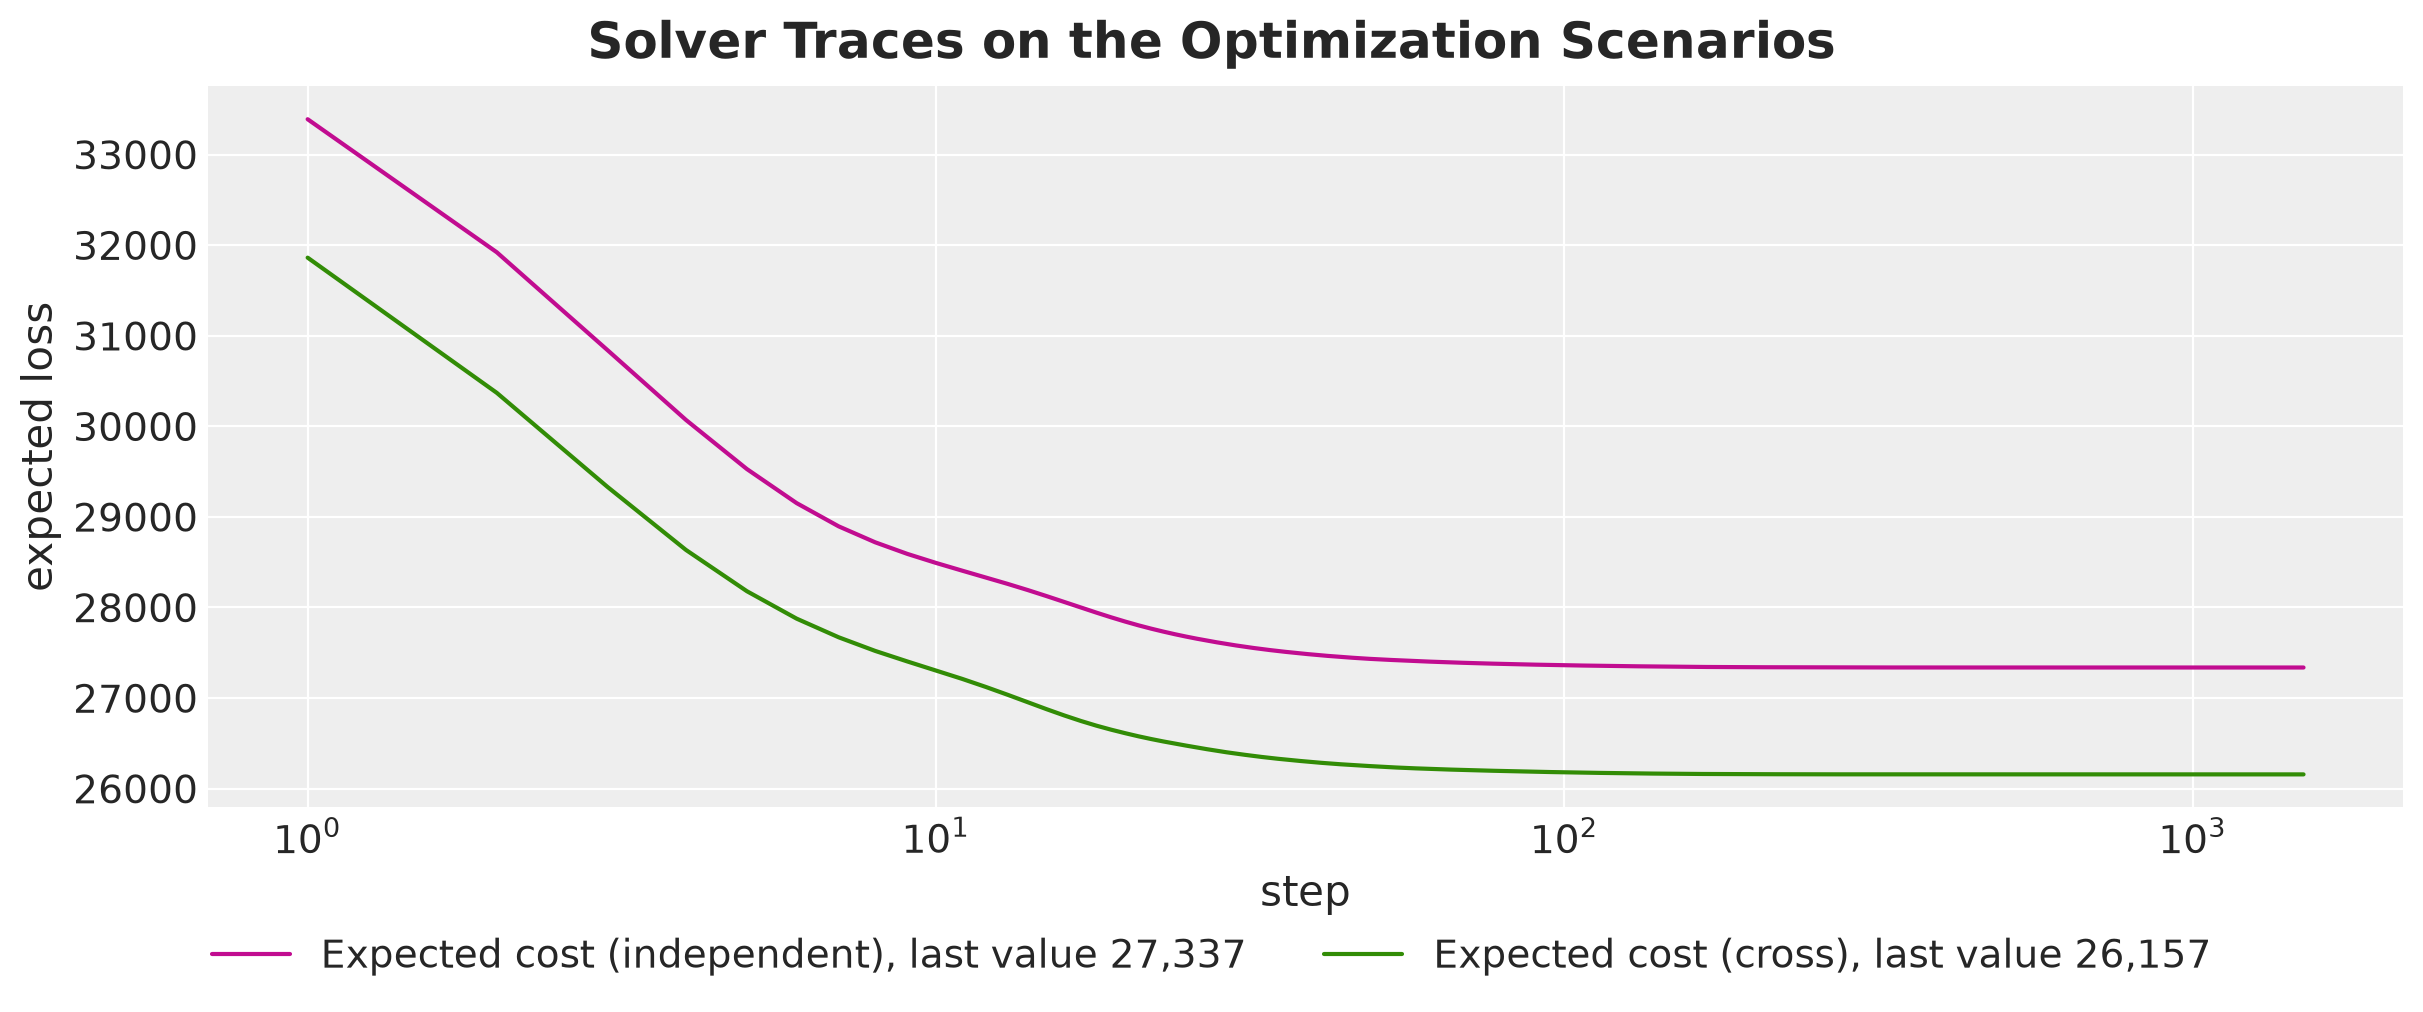

In [55]:
fig, ax = plt.subplots(figsize=(12, 5))

for model, (_, trace) in solves.items():
    ax.plot(
        jnp.arange(1, trace.size + 1),
        trace,
        color=MODEL_COLORS[model],
        label=f"{plans[Rule.EXPECTED_COST, model].name}, last value {trace[-1]:,.0f}",
    )

ax.set(xlabel="step", ylabel="expected loss", xscale="log")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    "Solver Traces on the Optimization Scenarios", fontsize=18, fontweight="bold"
);

Both objectives drop within the first $50$ steps and are flat after about $300$. The values on the optimization scenarios are $27{,}337$ for the independent plan and $26{,}157$ for the cross plan, and we compare them with the losses on the evaluation scenarios below.

Next, let's look at how much of the capacity the plans use. The following figure shows, for every day of the horizon, the share of the $10$ stores whose orders of that day are at capacity under each plan.

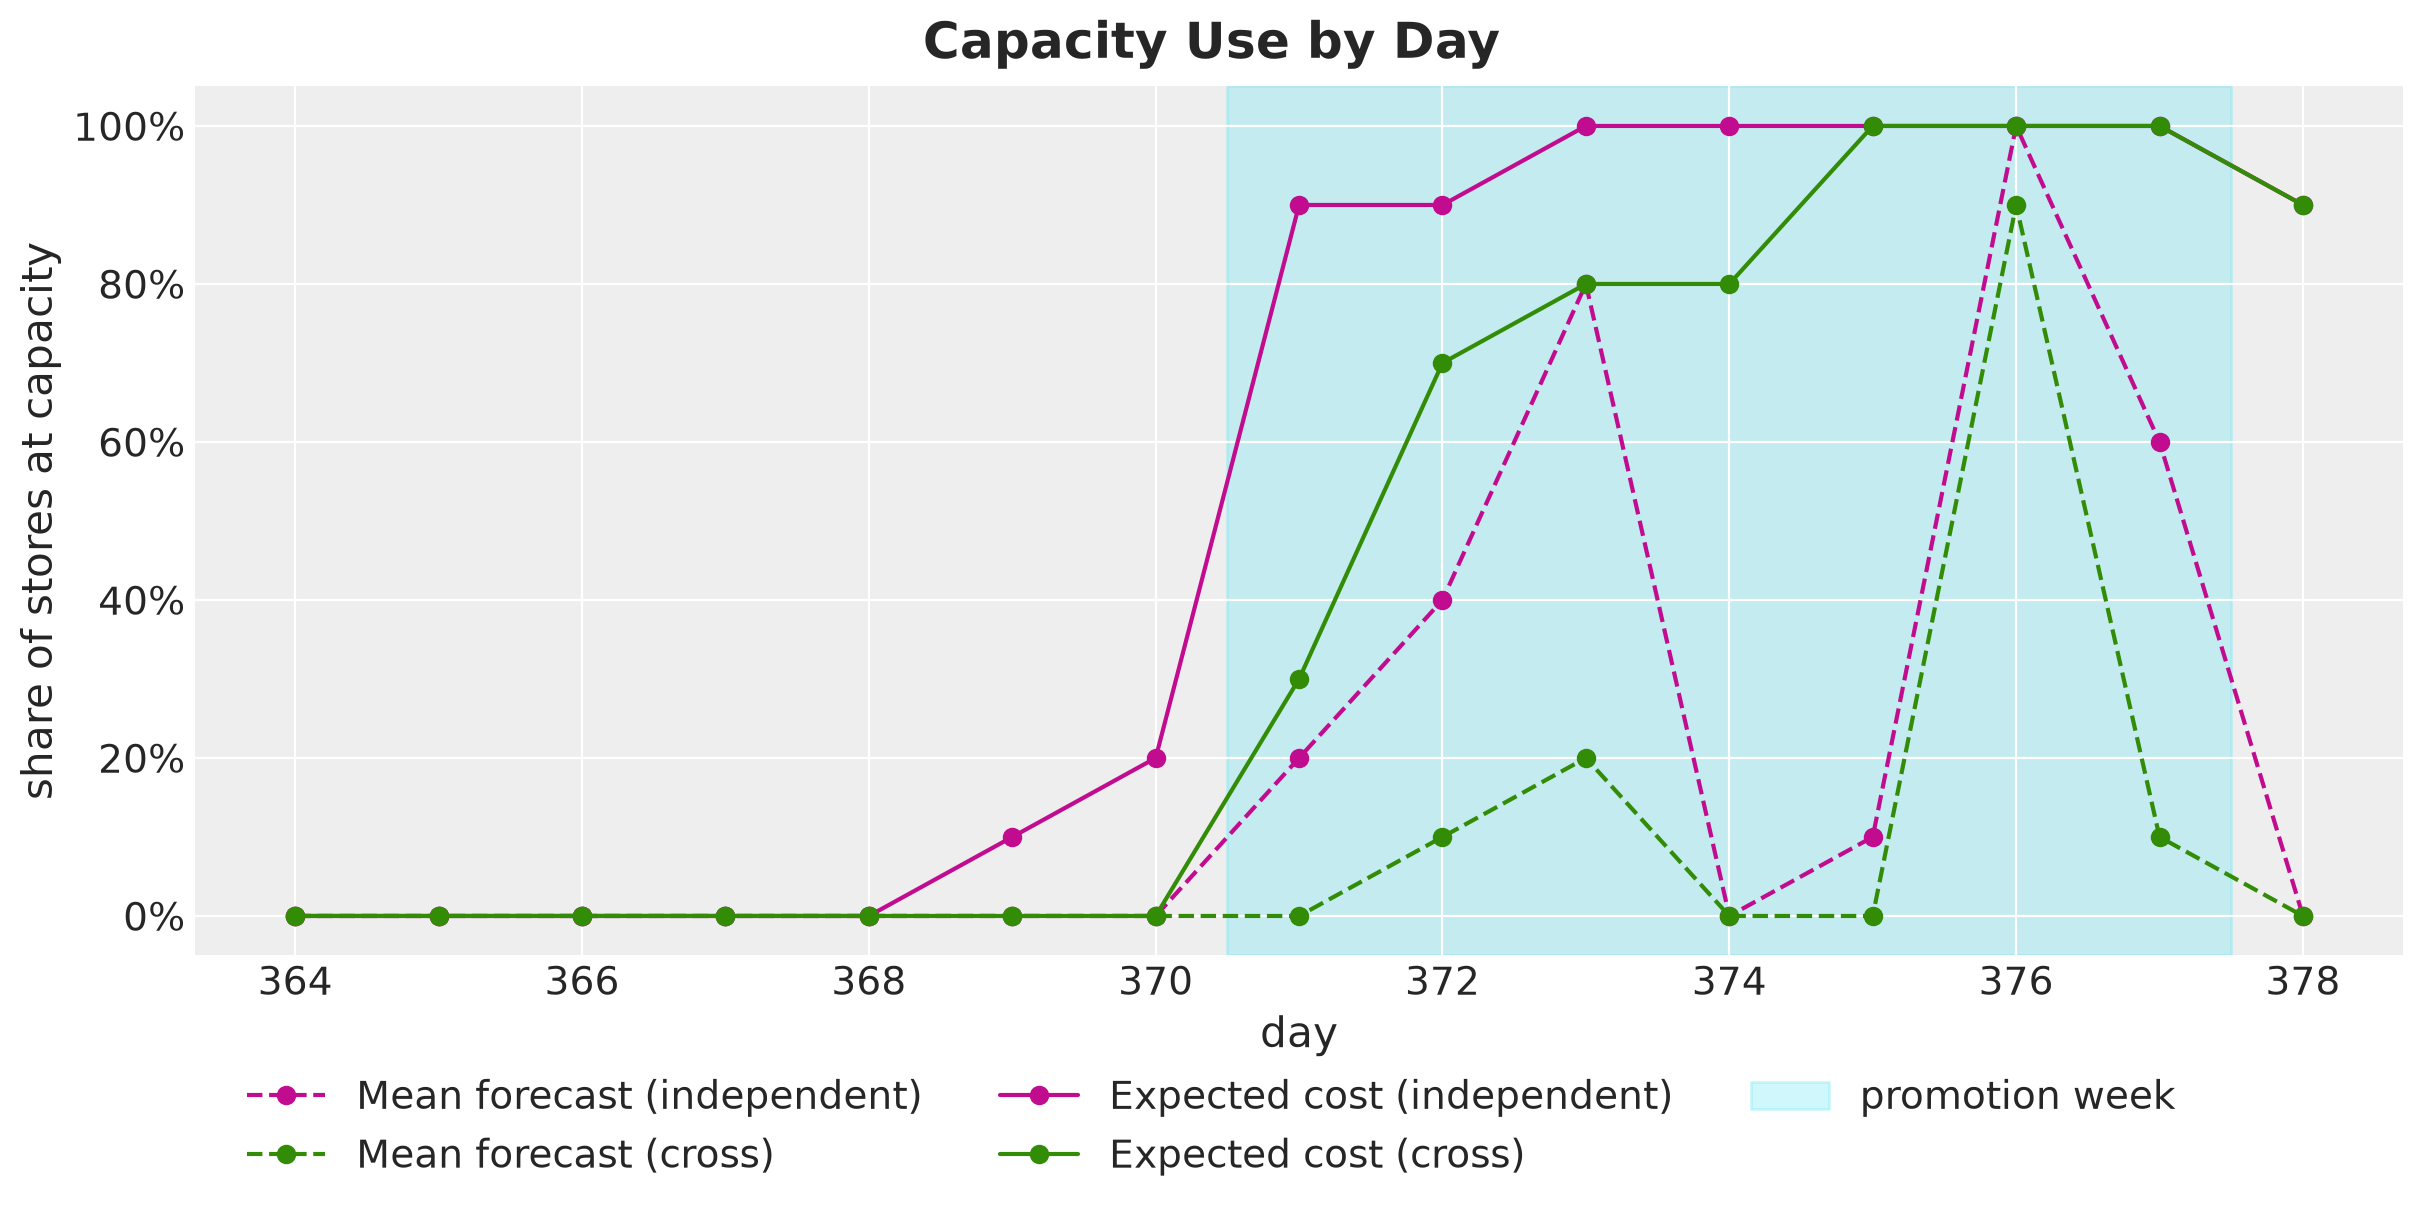

In [56]:
def at_capacity(
    orders: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    rtol: float,
) -> Float[Array, " horizon"]:
    """Share of the stores at capacity on every day of the horizon."""
    return (orders.sum(axis=-1) >= capacity * (1 - rtol)).mean(axis=-1)


def shade_promotion_week(ax: plt.Axes) -> None:
    """Shade the promotion week of the horizon, behind the data."""
    promo_days_future = days_future[PERIODS[Period.PROMOTION_WEEK]]
    ax.axvspan(
        promo_days_future[0] - 0.5,
        promo_days_future[-1] + 0.5,
        color="C5",
        alpha=0.3,
        zorder=0,
        label="promotion week",
    )


fig, ax = plt.subplots(figsize=(12, 6))

for plan in plans.values():
    ax.plot(
        days_future,
        at_capacity(plan.orders, capacity, solver.tol),
        marker="o",
        color=MODEL_COLORS[plan.model],
        linestyle="--" if plan.rule is Rule.MEAN_FORECAST else "-",
        label=plan.name,
    )

shade_promotion_week(ax)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="day", ylabel="share of stores at capacity")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Capacity Use by Day", fontsize=18, fontweight="bold");

We read the figure by period.

- **First week.** No store is at capacity under the mean forecast plans or under the cross plan. The independent plan reaches it in $1$ and $2$ stores on the last two days of the week.
- **Promotion week.** The independent plan is at capacity in $9$ or $10$ stores on every day. The cross plan is at capacity in $3$ stores on the first day and in $7$ to $10$ stores on the other days. Depending on the day, the mean forecast plans reach the capacity in none of the stores or in up to $10$.
- **Last day.** Both expected cost plans are at capacity in $9$ of the $10$ stores, and no mean forecast plan is. There is no later day to carry stock into, so a leftover costs $h$ once and a lost sale costs $p$, and the optimal order goes up to the $p / (p + h) = 0.95$ quantile of the demand of every product. In a rolling horizon the last order is never placed, so we do not read anything into day $15$.

Next, we compare the two expected cost plans across the whole chain. We take the orders of the independent plan minus the orders of the cross plan, per product and day, and average them over the products and stores of each role.

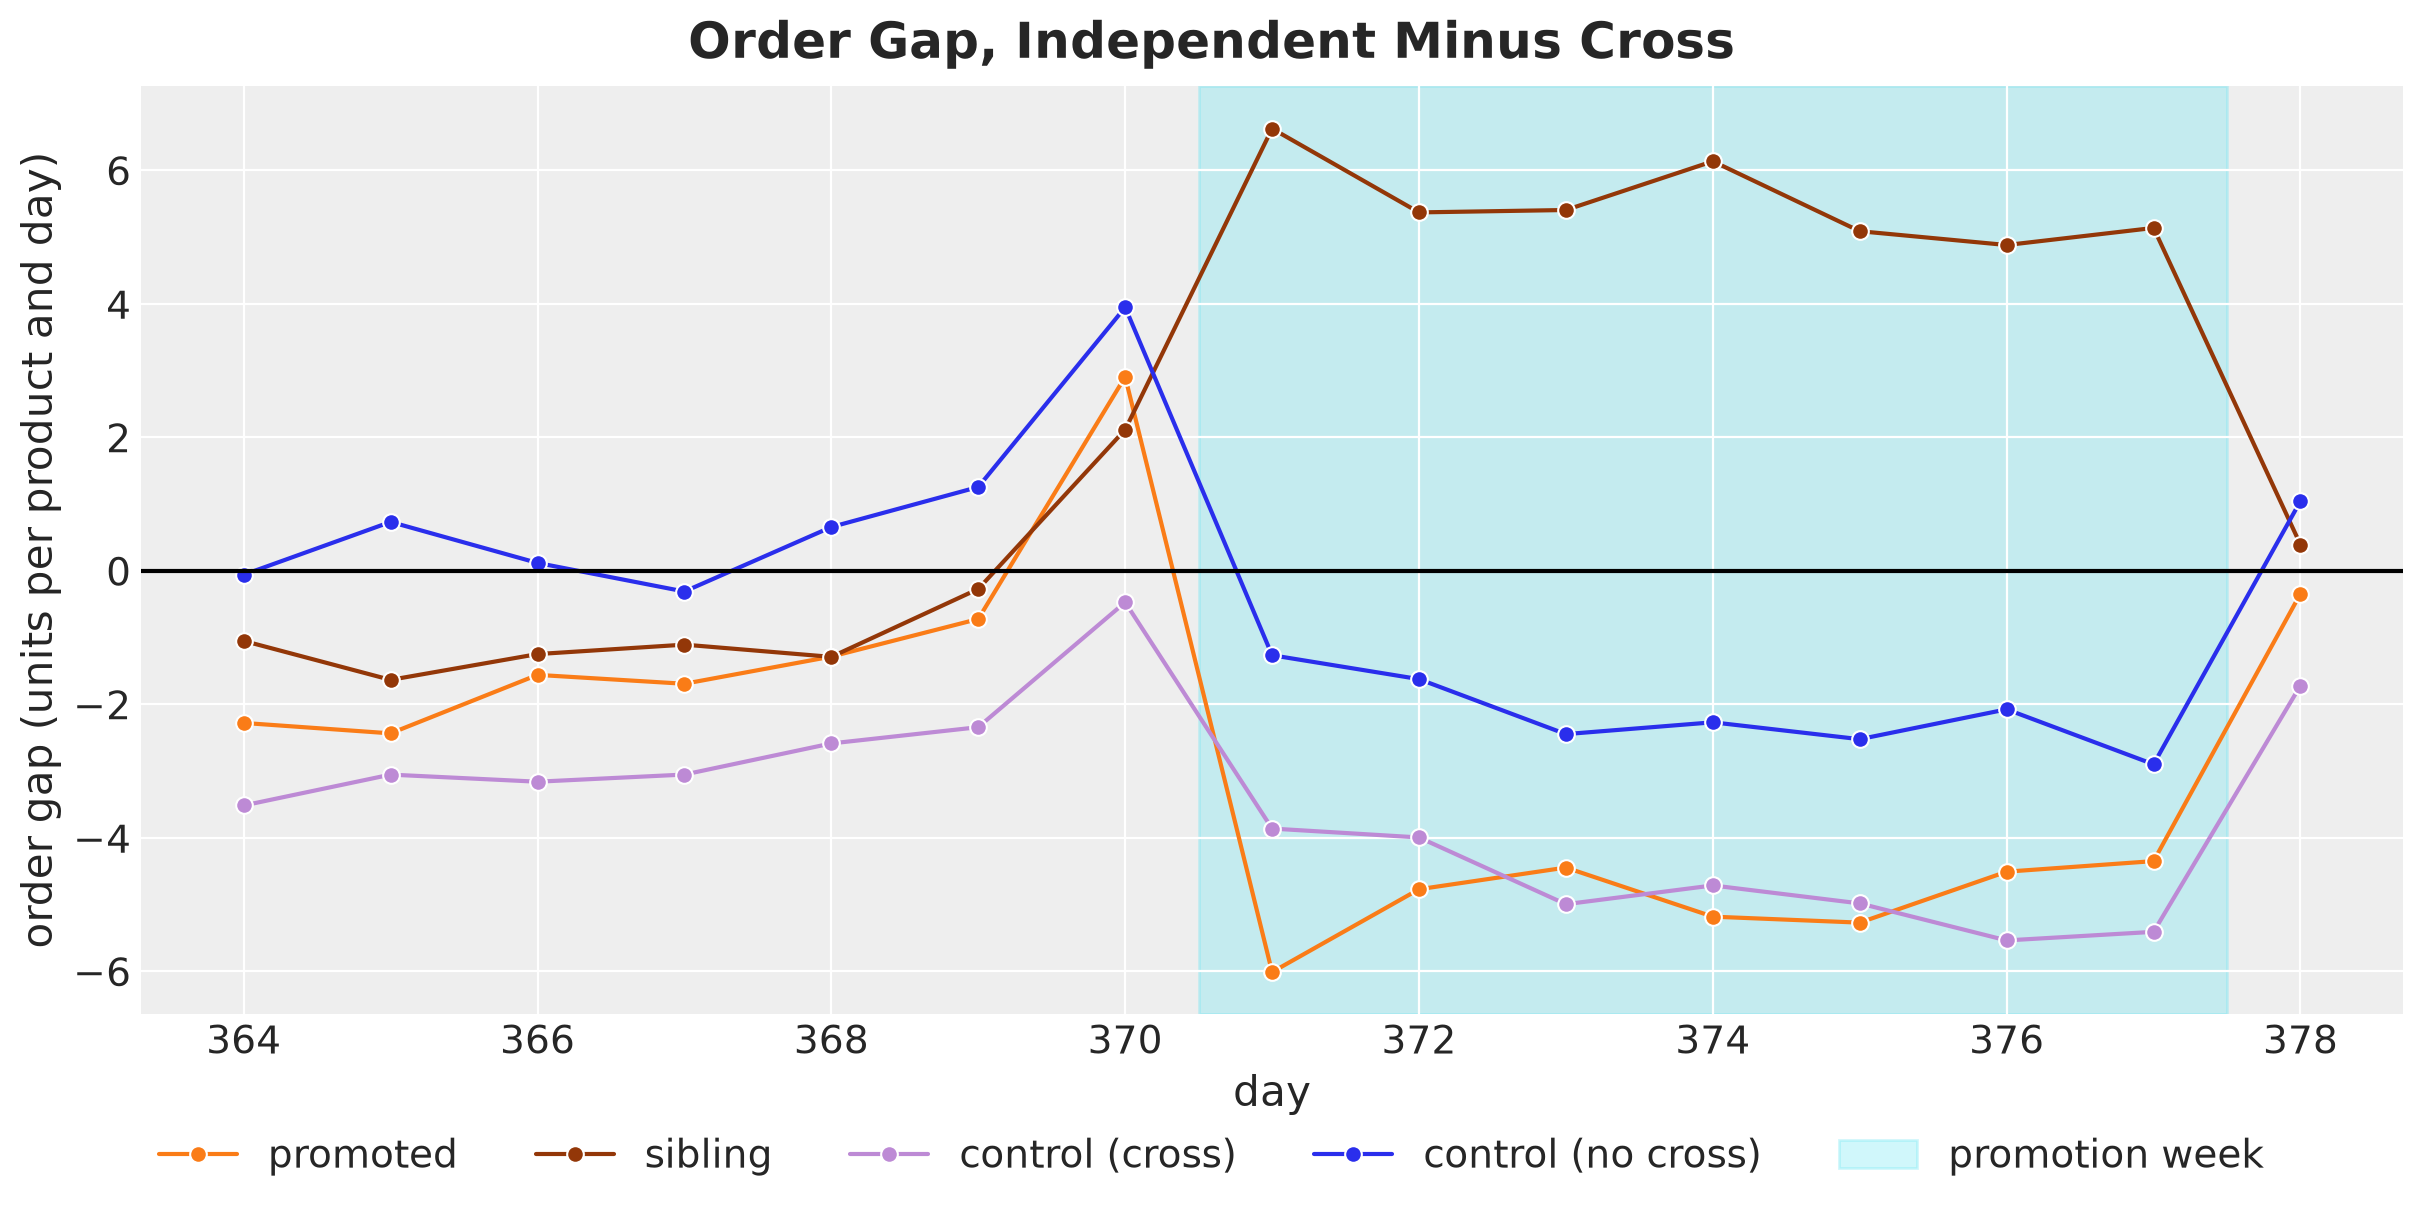

In [57]:
ROLE_COLORS = {
    Role.PROMOTED: "C1",
    Role.SIBLING: "C4",
    Role.CONTROL_CROSS: "C8",
    Role.CONTROL_NO_CROSS: "C0",
}
order_difference = orders_expected[Model.INDEPENDENT] - orders_expected[Model.CROSS]
order_gap = pl.DataFrame(
    [
        {"role": role.value, "day": day, "order gap": gap}
        for role in Role
        for day, gap in zip(
            days_future.tolist(),
            order_difference[:, :, role_mask[role]].mean(axis=(1, 2)).tolist(),
            strict=True,
        )
    ]
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=order_gap,
    x="day",
    y="order gap",
    hue="role",
    hue_order=[role.value for role in Role],
    palette=ROLE_COLORS,
    marker="o",
    ax=ax,
)
ax.axhline(0.0, color="black")
shade_promotion_week(ax)
ax.get_legend().remove()
ax.set(xlabel="day", ylabel="order gap (units per product and day)")
fig.legend(loc="outside lower center", ncol=5)
fig.suptitle("Order Gap, Independent Minus Cross", fontsize=18, fontweight="bold");

We read the order difference in three periods.

- **Days $1$ to $6$.** The independent plan orders less than the cross plan on the `promoted`, `sibling` and `control (cross)` roles, by up to $3.5$ units per product and day. On `control (no cross)` the difference is at most about one unit. This matches the low start of the independent forecast.
- **Day $7$.** The difference turns positive on `promoted`, `sibling` and `control (no cross)`. The independent model does not expect the siblings to dip, so it forecasts more demand in the promotion week. The pattern is consistent with a plan that expects a higher load in that week and moves orders to the day before it.
- **Promotion week.** The independent plan orders $5$ to $7$ units more per sibling and day, and $4$ to $6$ units less per promoted product and day. It is at capacity in almost every store, so the units that it gives to the siblings come out of the other three roles.

## Out of Sample Evaluation

We score every plan with four metrics on the $1{,}000$ evaluation scenarios and with one metric on the realized future.

- **Expected loss.** The mean over the evaluation scenarios of the loss summed over the series.
- **CVaR of the loss.** The mean of the worst $5\%$ of the scenario losses, the tail average.
- **Stockout probability per series-day.** The fraction of scenario, series and day triples with a lost sale.
- **Probability of a stockout in the horizon per series.** The fraction of scenario and series pairs with at least one lost sale in the $15$ days.
- **Loss on the realized future.** The loss of the plan against the one path we held out when we generated the data.

For every plan we also record the expected loss and the CVaR on the optimization scenarios of its own model, the values the solver sees.

In [58]:
class Metric(StrEnum):
    """Names of the scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {solver.alpha:.0%})"
    STOCKOUT = "stockout probability per series-day"
    HORIZON = "probability of a stockout in the horizon per series"
    REALIZED = "loss on the realized future"
    OWN_EXPECTED_LOSS = "expected loss on own scenarios"
    OWN_CVAR = "CVaR of loss on own scenarios"


LOSS_METRICS = [
    Metric.EXPECTED_LOSS,
    Metric.CVAR,
    Metric.REALIZED,
    Metric.OWN_EXPECTED_LOSS,
    Metric.OWN_CVAR,
]


def is_stockout(sim: Simulation, tol: float) -> Bool[Array, "*batch horizon"]:
    """Days with lost sales above the tolerance."""
    return sim.lost_sales > tol


def evaluate(plan: Plan) -> Simulation:
    """Simulate a plan on the evaluation scenarios."""
    return simulate_scenarios(flat(plan.orders), demand_eval, initial_inventory, config)


def summarize(plan: Plan, sim: Simulation) -> dict[str, str | float]:
    """Scores of one plan on the evaluation scenarios, the realized future, its own."""
    losses = sim.loss.sum(axis=-1)
    stockout = is_stockout(sim, solver.tol)
    realized = simulate_series(
        flat(plan.orders), demand_future_true, initial_inventory, config
    ).loss.sum()
    own_losses = simulate_scenarios(
        flat(plan.orders), draws[plan.model].scenarios, initial_inventory, config
    ).loss.sum(axis=-1)
    return {
        "plan": plan.name,
        "rule": plan.rule.value,
        "model": plan.model.value,
        Metric.EXPECTED_LOSS: float(losses.mean()),
        Metric.CVAR: float(cvar(losses, solver.alpha)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.HORIZON: float(stockout.any(axis=-1).mean()),
        Metric.REALIZED: float(realized),
        Metric.OWN_EXPECTED_LOSS: float(own_losses.mean()),
        Metric.OWN_CVAR: float(cvar(own_losses, solver.alpha)),
    }


def round_losses(frame: pl.DataFrame, columns: list[str]) -> pl.DataFrame:
    """Copy of a frame with some columns rounded to integers, for display."""
    return frame.with_columns(pl.col(columns).round(0).cast(pl.Int64))


scores = {key: evaluate(plan) for key, plan in plans.items()}
results = pl.DataFrame([summarize(plan, scores[key]) for key, plan in plans.items()])
round_losses(results, LOSS_METRICS).drop("rule", "model")

plan,expected loss,CVaR of loss (worst 5%),stockout probability per series-day,probability of a stockout in the horizon per series,loss on the realized future,expected loss on own scenarios,CVaR of loss on own scenarios
str,i64,i64,f64,f64,i64,i64,i64
"""Mean forecast (independent)""",38005,41364,0.263,0.821,38334,33390,37126
"""Mean forecast (cross)""",34788,38042,0.238,0.783,35195,31862,35308
"""Expected cost (independent)""",31660,34407,0.136,0.520,31458,27337,30094
"""Expected cost (cross)""",29813,32483,0.118,0.470,29373,26157,28664


Let's look at the four scores of each plan in one figure.

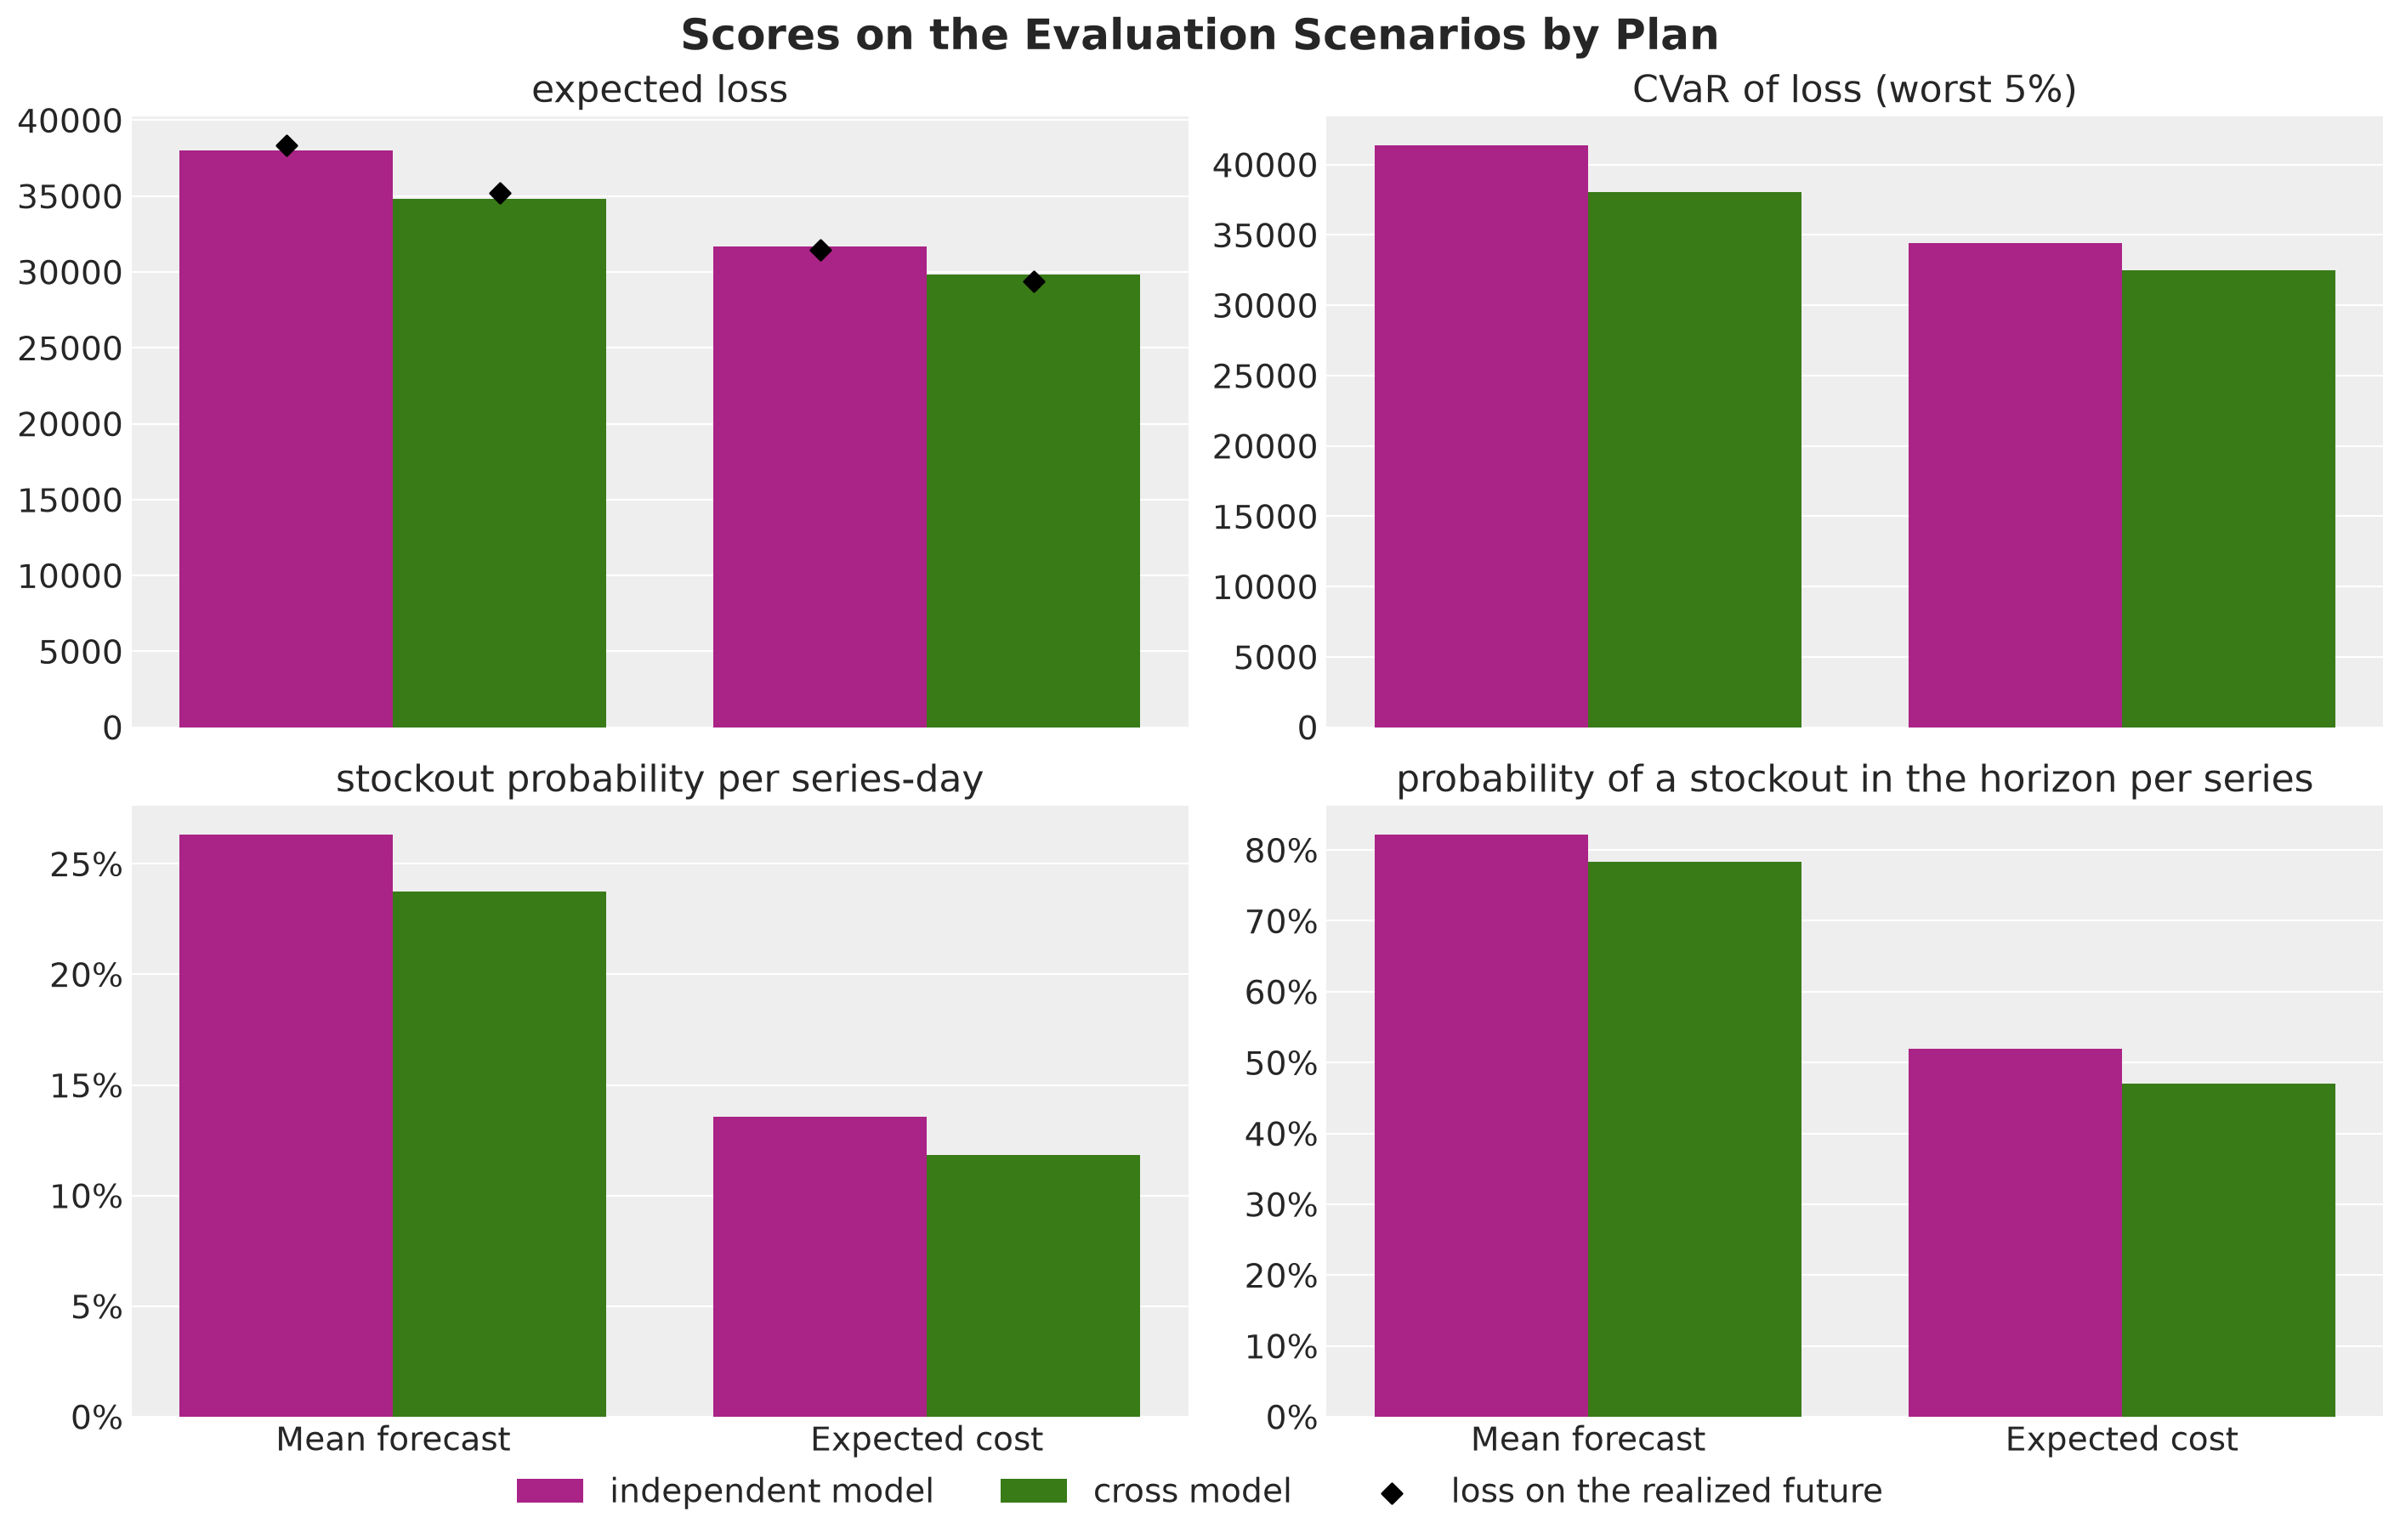

In [59]:
metrics = [Metric.EXPECTED_LOSS, Metric.CVAR, Metric.STOCKOUT, Metric.HORIZON]

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 9), sharex=True, layout="constrained"
)

for ax, metric in zip(axes.flat, metrics, strict=True):
    sns.barplot(
        data=results,
        x="rule",
        y=metric,
        hue="model",
        hue_order=[model.value for model in models],
        palette=MODEL_COLORS,
        ax=ax,
    )
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

    if metric in {Metric.STOCKOUT, Metric.HORIZON}:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

    ax.set(title=metric, xlabel="", ylabel="")

# the bars of a rule sit at -0.2 and +0.2 around its tick, in the order of `results`
realized = axes[0, 0].scatter(
    [tick + offset for tick in range(2) for offset in (-0.2, 0.2)],
    results[Metric.REALIZED],
    color="black",
    marker="D",
    zorder=3,
)
fig.legend(
    [*handles, realized],
    [*[f"{label} model" for label in labels], Metric.REALIZED],
    loc="outside lower center",
    ncol=3,
)
fig.suptitle(
    "Scores on the Evaluation Scenarios by Plan", fontsize=18, fontweight="bold"
);

The four plans are ordered the same way on every metric.

- **Point forecast against distribution.** Within a model, the mean forecast plan costs $20\%$ more than the expected cost plan under the independent model ($38{,}005$ against $31{,}660$) and $17\%$ more under the cross model ($34{,}788$ against $29{,}813$). The first post found the same order on one series.
- **Independent against cross.** Within a rule, the plan of the independent model costs $9\%$ more than the plan of the cross model under the mean forecast rule and $6\%$ more under the expected cost rule ($31{,}660$ against $29{,}813$). The second number is the cost of ignoring cannibalization on this panel.
- **Rule and model.** The mean forecast plan of the cross model costs $10\%$ more than the expected cost plan of the independent model. On this panel the decision rule matters more than the model.
- **Service.** The stockout probability per series-day falls from $26\%$ and $24\%$ under the mean forecast plans to $14\%$ and $12\%$ under the expected cost plans. The probability of at least one stockout per series in the horizon falls from $82\%$ and $78\%$ to $52\%$ and $47\%$.
- **Realized future.** The losses on the realized future are within $1.5\%$ of the expected losses and keep the same order.

The two expected cost plans also cost more on the evaluation scenarios than on the scenarios of their own model, by $14\%$ for the cross plan ($29{,}813$ against $26{,}157$) and by $16\%$ for the independent plan. The order of the four plans is the same on both.

In the first post the two numbers agreed to within $1\%$, because the held-out scenarios came from the same posterior. Here the evaluation scenarios come from the true process, and the increase is consistent with a forecast that is wrong about the level of each series.

Recall from the *Parameter Recovery* section that the $94\%$ intervals of the level cover the truth for only about $60\%$ of the series. The scenarios of a model are centered on its own estimate of the level, so they do not contain this error, and the evaluation scenarios do.

Each of these scores is an average over the evaluation scenarios. The next figure shows the distribution behind the averages, with the mean and the central $50\%$ and $94\%$ of the loss of each plan.

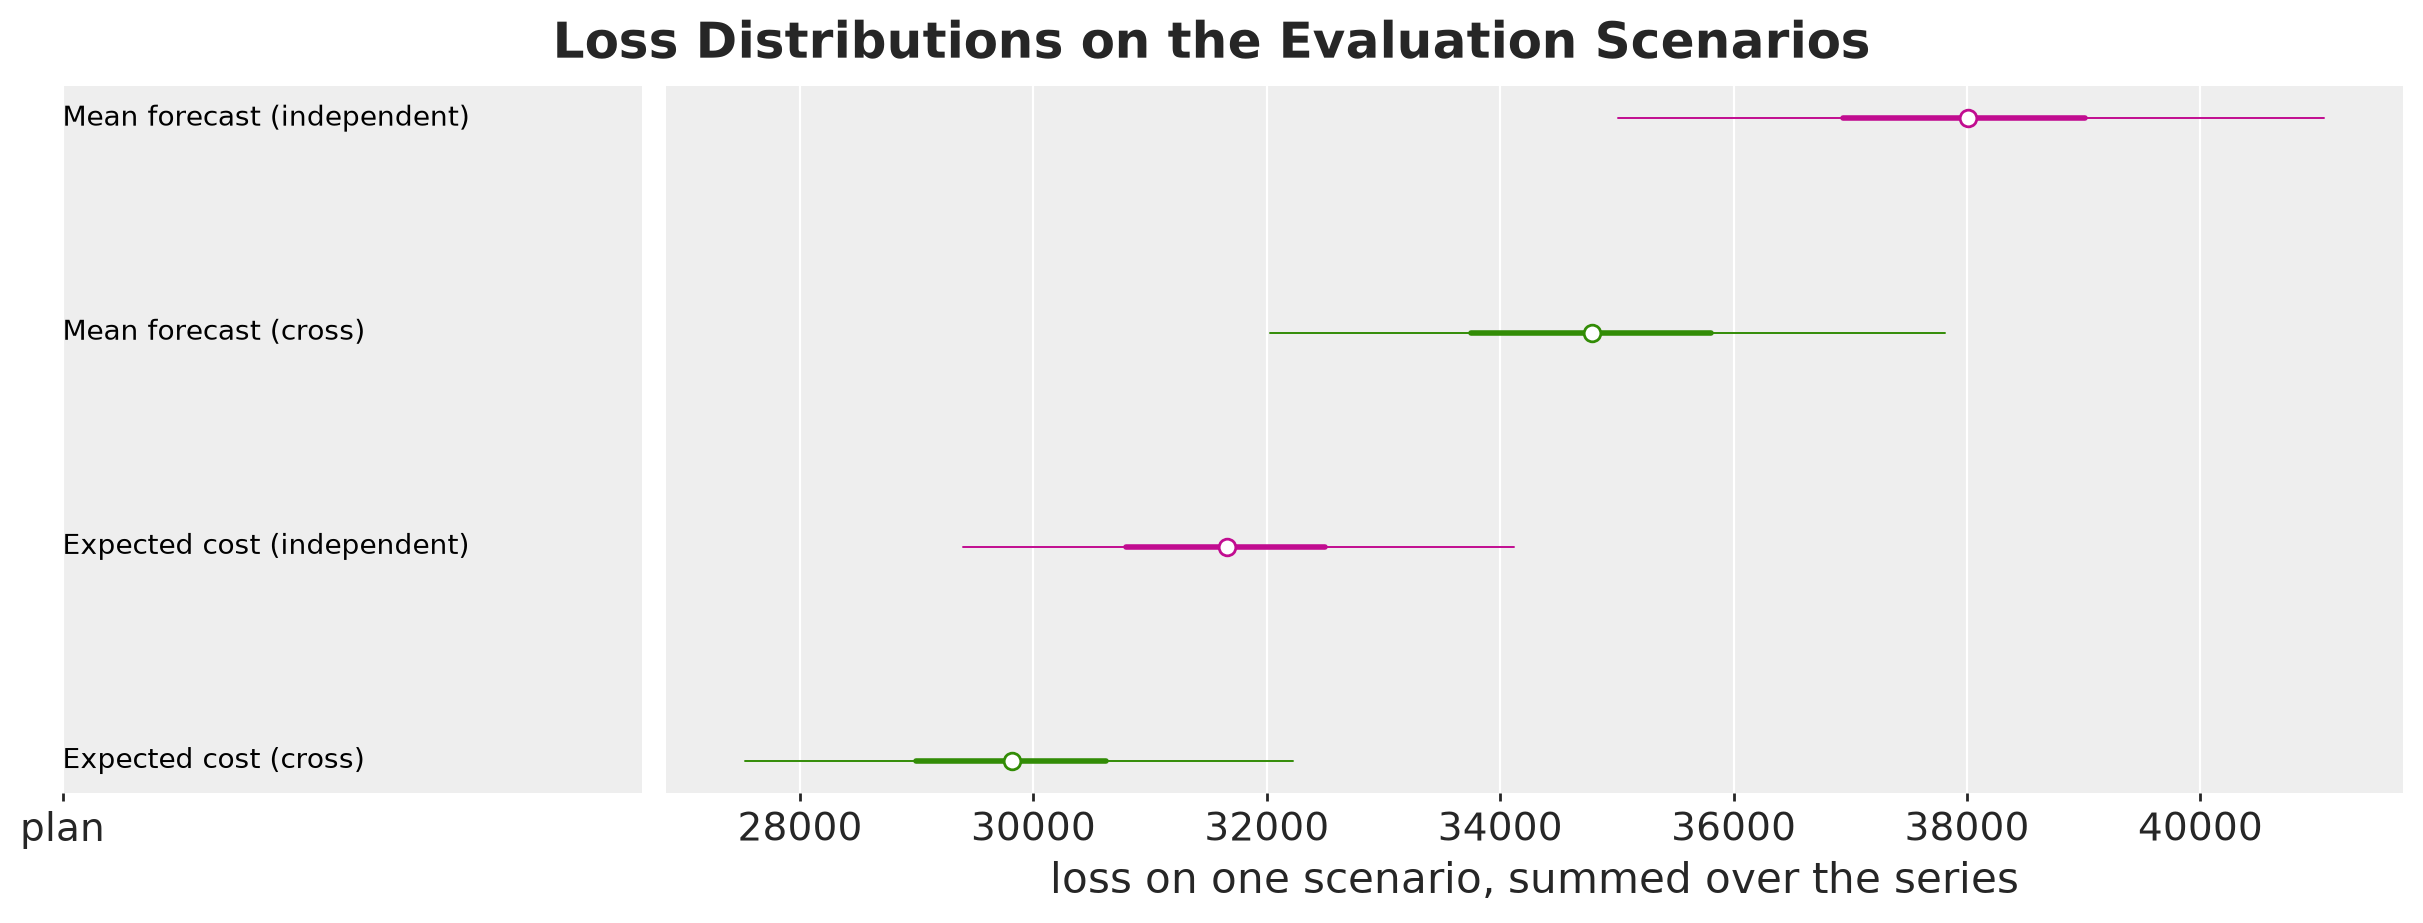

In [60]:
losses_by_plan = xr.Dataset(
    {
        "loss": (
            ("sample", "plan"),
            jnp.stack([sim.loss.sum(axis=-1) for sim in scores.values()], axis=-1),
        )
    },
    coords={"plan": [plan.name for plan in plans.values()]},
)

pc = az.plot_forest(
    losses_by_plan,
    sample_dims=["sample"],
    labels=["plan"],
    aes={"color": ["plan"]},
    color=[MODEL_COLORS[plan.model] for plan in plans.values()],
    figure_kwargs={"figsize": (12, 4.5)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.set(xlabel="loss on one scenario, summed over the series")
pc.viz["figure"].item().suptitle(
    "Loss Distributions on the Evaluation Scenarios", fontsize=18, fontweight="bold"
);

The four distributions are ordered as their means, and the $50\%$ intervals of the two expected cost plans do not overlap. The intervals are narrow relative to the means.

We score the plans on the same scenarios, so we can also compare the two expected cost plans scenario by scenario. The following table summarizes the **gap**, the loss of the independent plan minus the loss of the cross plan, over the evaluation scenarios.

In [61]:
loss_difference = (
    scores[Rule.EXPECTED_COST, Model.INDEPENDENT].loss
    - scores[Rule.EXPECTED_COST, Model.CROSS].loss
).sum(axis=-1)
tail = (1 - CI_PROB) / 2
lower, upper = f"{tail:.0%} quantile", f"{1 - tail:.0%} quantile"
round_losses(
    pl.DataFrame(
        {
            "share of scenarios with a cheaper cross plan": [
                float((loss_difference > 0).mean())
            ],
            "mean difference": [float(loss_difference.mean())],
            lower: [float(jnp.quantile(loss_difference, tail))],
            upper: [float(jnp.quantile(loss_difference, 1 - tail))],
        }
    ),
    ["mean difference", lower, upper],
)

share of scenarios with a cheaper cross plan,mean difference,3% quantile,97% quantile
f64,i64,i64,i64
1.000,1847,861,2730


The cross plan is cheaper in every one of the $1{,}000$ evaluation scenarios of this history. The gap has a mean of $1{,}847$, and its central $94\%$ runs from $861$ to $2{,}730$.

The tails of the loss are thin. The tail average is $1.09$ times the expected loss for every plan, against about $3$ for the mean forecast plan of the first post. The next two sections look at what that means for the tail weight and for the dependence across series.

### Tail Weight

In the first post the CVaR plan, which minimizes the objective with $\lambda = 1$, had a visibly lower tail loss than the expected cost plan. Here we solve it on the scenarios of the cross model and score it twice, on those scenarios and on the evaluation scenarios.

In [62]:
orders_cvar, _ = solve_jit(
    draws[Model.CROSS].scenarios,
    1.0,
    orders_mean[Model.CROSS],
    capacity,
    initial_inventory,
    config,
    solver,
)
tail_metrics = [
    Metric.OWN_EXPECTED_LOSS,
    Metric.OWN_CVAR,
    Metric.EXPECTED_LOSS,
    Metric.CVAR,
]
round_losses(
    pl.DataFrame(
        [
            summarize(plan, evaluate(plan))
            for plan in [
                plans[Rule.EXPECTED_COST, Model.CROSS],
                Plan(Rule.CVAR, Model.CROSS, orders_cvar),
            ]
        ]
    ).select("plan", *tail_metrics),
    tail_metrics,
)

plan,expected loss on own scenarios,CVaR of loss on own scenarios,expected loss,CVaR of loss (worst 5%)
str,i64,i64,i64,i64
"""Expected cost (cross)""",26157,28664,29813,32483
"""CVaR (cross)""",26326,28076,29966,32579


On the scenarios of the cross model the tail weight lowers the tail. The CVaR plan has a tail loss of $28{,}076$ against $28{,}664$ for the expected cost plan, about $2\%$ lower, at an expected loss $0.6\%$ higher.

The lower tail does not carry over to the evaluation scenarios, where the CVaR plan has a tail of $32{,}579$ against $32{,}483$. The level error is not in the scenarios of the model, so the tail weight did not lower the tail here.

We keep the expected cost plans from here on.

### Dependence Across Series

In the first post we shuffled the days of the scenarios to show that the carried stock needs joint draws over time. Here we check whether the expected cost plan also needs joint draws across series. We shuffle the scenario index of every series independently, which keeps every single-series path and removes the dependence across series, and evaluate the objective of the expected cost plan on both sets.

We also measure how much dependence there is to lose. For each set of scenarios we take the total demand of every series over the horizon, and we divide the variance of the sum of these totals over the series by the sum of their variances. A ratio of one means uncorrelated series.

In [63]:
def variance_ratio(demand: Float[Array, "scenarios horizon n_series"]) -> float:
    """Variance of the chain total over the sum of the variances of the series."""
    per_series = demand.sum(axis=1)
    return float(per_series.sum(axis=1).var() / per_series.var(axis=0).sum())


rng_key, key_shuffle = random.split(rng_key)
shuffle_each_series = jax.vmap(random.permutation, in_axes=(0, 2), out_axes=2)
demand_shuffled = shuffle_each_series(
    random.split(key_shuffle, setup.n_series), draws[Model.CROSS].scenarios
)
objective_joint, objective_shuffled = (
    objective(
        orders_expected[Model.CROSS],
        demand,
        0.0,
        initial_inventory,
        config,
        solver.alpha,
    )
    for demand in (draws[Model.CROSS].scenarios, demand_shuffled)
)
assert jnp.allclose(objective_joint, objective_shuffled, rtol=1e-6)

pl.DataFrame(
    {
        "scenarios": [
            "evaluation (true process)",
            *[f"optimization ({model})" for model in models],
        ],
        "variance ratio": [
            variance_ratio(demand_eval),
            *[variance_ratio(draws[model].scenarios) for model in models],
        ],
    }
)

scenarios,variance ratio
str,f64
"""evaluation (true process)""",0.977
"""optimization (independent)""",1.025
"""optimization (cross)""",1.044


The assertion passes, so the objective is equal on the joint and on the shuffled scenarios, up to floating point. Under the expected cost rule the objective is a sum over the series of per-series expected losses, and the capacity constrains the orders, which are the same in every scenario. The plan depends on the marginal distribution of each series alone.

The table shows that there is little dependence to lose. The three ratios are $0.977$, $1.025$ and $1.044$, all close to one. The series are independent in the generator, which has no shock common to the series.

With independent series the high and the low series of a scenario cancel in the sum, which explains the thin tail of the total loss. On data with common shocks the dependence would matter for a rule on the total loss, such as a tail weight.

The joint draws over time remain necessary, since the stock carries over within a series.

### Cost Decomposition

To see which products and days are behind the cost of ignoring cannibalization, we split the expected loss of the two expected cost plans on the evaluation scenarios by series, period and cost part (holding and lost sales). From here on the gap is the expected gap, the difference of these expected losses.

First, we sum the gap over the products of each group, for each period. The last two columns give the share of each group in the total gap and the gap of a group over the expected loss of the cross plan on that group.

In [64]:
class Cost(StrEnum):
    """Parts of the loss."""

    HOLDING = "holding"
    LOST_SALES = "lost sales"


def loss_parts(
    sim: Simulation, days_slice: slice
) -> dict[Cost, Float[Array, " n_series"]]:
    """Expected holding cost and lost sales cost per series over some days."""
    holding = sim.inventory[:, :, days_slice].sum(axis=-1).mean(axis=0)
    lost_sales = sim.lost_sales[:, :, days_slice].sum(axis=-1).mean(axis=0)
    return {
        Cost.HOLDING: config.holding_cost * holding,
        Cost.LOST_SALES: config.lost_sales_cost * lost_sales,
    }


def gap_frame(sim_independent: Simulation, sim_cross: Simulation) -> pl.DataFrame:
    """Loss of the cross plan and gap to it, per series, period and cost part."""
    frames = []

    for period, days_slice in PERIODS.items():
        parts_independent = loss_parts(sim_independent, days_slice)
        parts_cross = loss_parts(sim_cross, days_slice)
        frames += [
            pl.DataFrame(
                {
                    "product": panel.series_to_product.tolist(),
                    "period": period.value,
                    "part": part.value,
                    "loss_cross": parts_cross[part].tolist(),
                    "gap": (parts_independent[part] - parts_cross[part]).tolist(),
                }
            )
            for part in parts_independent
        ]

    return pl.concat(frames).join(
        products.select("product", "group", "role", "cross_elasticity"), on="product"
    )


gap_long = gap_frame(
    scores[Rule.EXPECTED_COST, Model.INDEPENDENT],
    scores[Rule.EXPECTED_COST, Model.CROSS],
)
period_names = [period.value for period in Period]
gap_by_group = (
    gap_long.group_by("group", "cross_elasticity", "period")
    .agg(pl.col("gap").sum())
    .pivot(on="period", index=["group", "cross_elasticity"], values="gap")
    .join(
        gap_long.group_by("group").agg(
            pl.col("loss_cross").sum(), total=pl.col("gap").sum()
        ),
        on="group",
    )
    .sort("group")
    .select(
        pl.format("group {} ({})", "group", "cross_elasticity").alias("group"),
        *period_names,
        "total",
        "loss_cross",
    )
)
gap_by_group = pl.concat(
    [
        gap_by_group,
        gap_by_group.select(pl.lit("all").alias("group"), pl.exclude("group").sum()),
    ]
)
round_losses(gap_by_group, [*period_names, "total"]).select(
    pl.exclude("loss_cross"),
    (gap_by_group["total"] / gap_by_group["total"][-1]).alias("share of the gap"),
    (gap_by_group["total"] / gap_by_group["loss_cross"]).alias(
        "gap / loss of the cross plan"
    ),
)

group,first week,promotion week,last day,total,share of the gap,gap / loss of the cross plan
str,i64,i64,i64,i64,f64,f64
"""group 1 (0.6)""",486,679,138,1303,0.705,0.248
"""group 2 (0.3)""",82,13,56,152,0.082,0.019
"""group 3 (0.0)""",-38,64,-3,23,0.012,0.006
"""group 4 (0.3)""",196,204,-83,318,0.172,0.055
"""group 5 (0.0)""",-57,129,-20,52,0.028,0.007
"""all""",669,1088,89,1847,1.000,0.062


The gap is the largest in group $1$, which has the largest cross elasticity and a sibling promotion in the last week of the history.

- **Group $1$.** It accounts for $1{,}303$ of the gap of $1{,}847$, or $71\%$, which is $25\%$ of the loss of the cross plan on this group.
- **Groups $2$ and $4$.** They account for $152$ and $318$, or $8\%$ and $17\%$ of the gap. Both have a cross elasticity of $0.3$. Group $2$ has a promoted product in the horizon. Group $4$ has none, but it saw sibling promotions in two of the last four weeks of the history, and its gap is twice as large.
- **Groups $3$ and $5$.** They account for $23$ and $52$, or $1\%$ and $3\%$ of the gap. These groups have no cannibalization. Their gap comes from the promotion week ($64$ and $129$), where they share the capacity with the other groups.

By period the gap is $669$ in the first week, $1{,}088$ in the promotion week and $89$ on the last day. A forecast that starts low stays low, so the promotion week also contains cost from the low start.

Next, we split the gap by product, for the first week and for the promotion week.

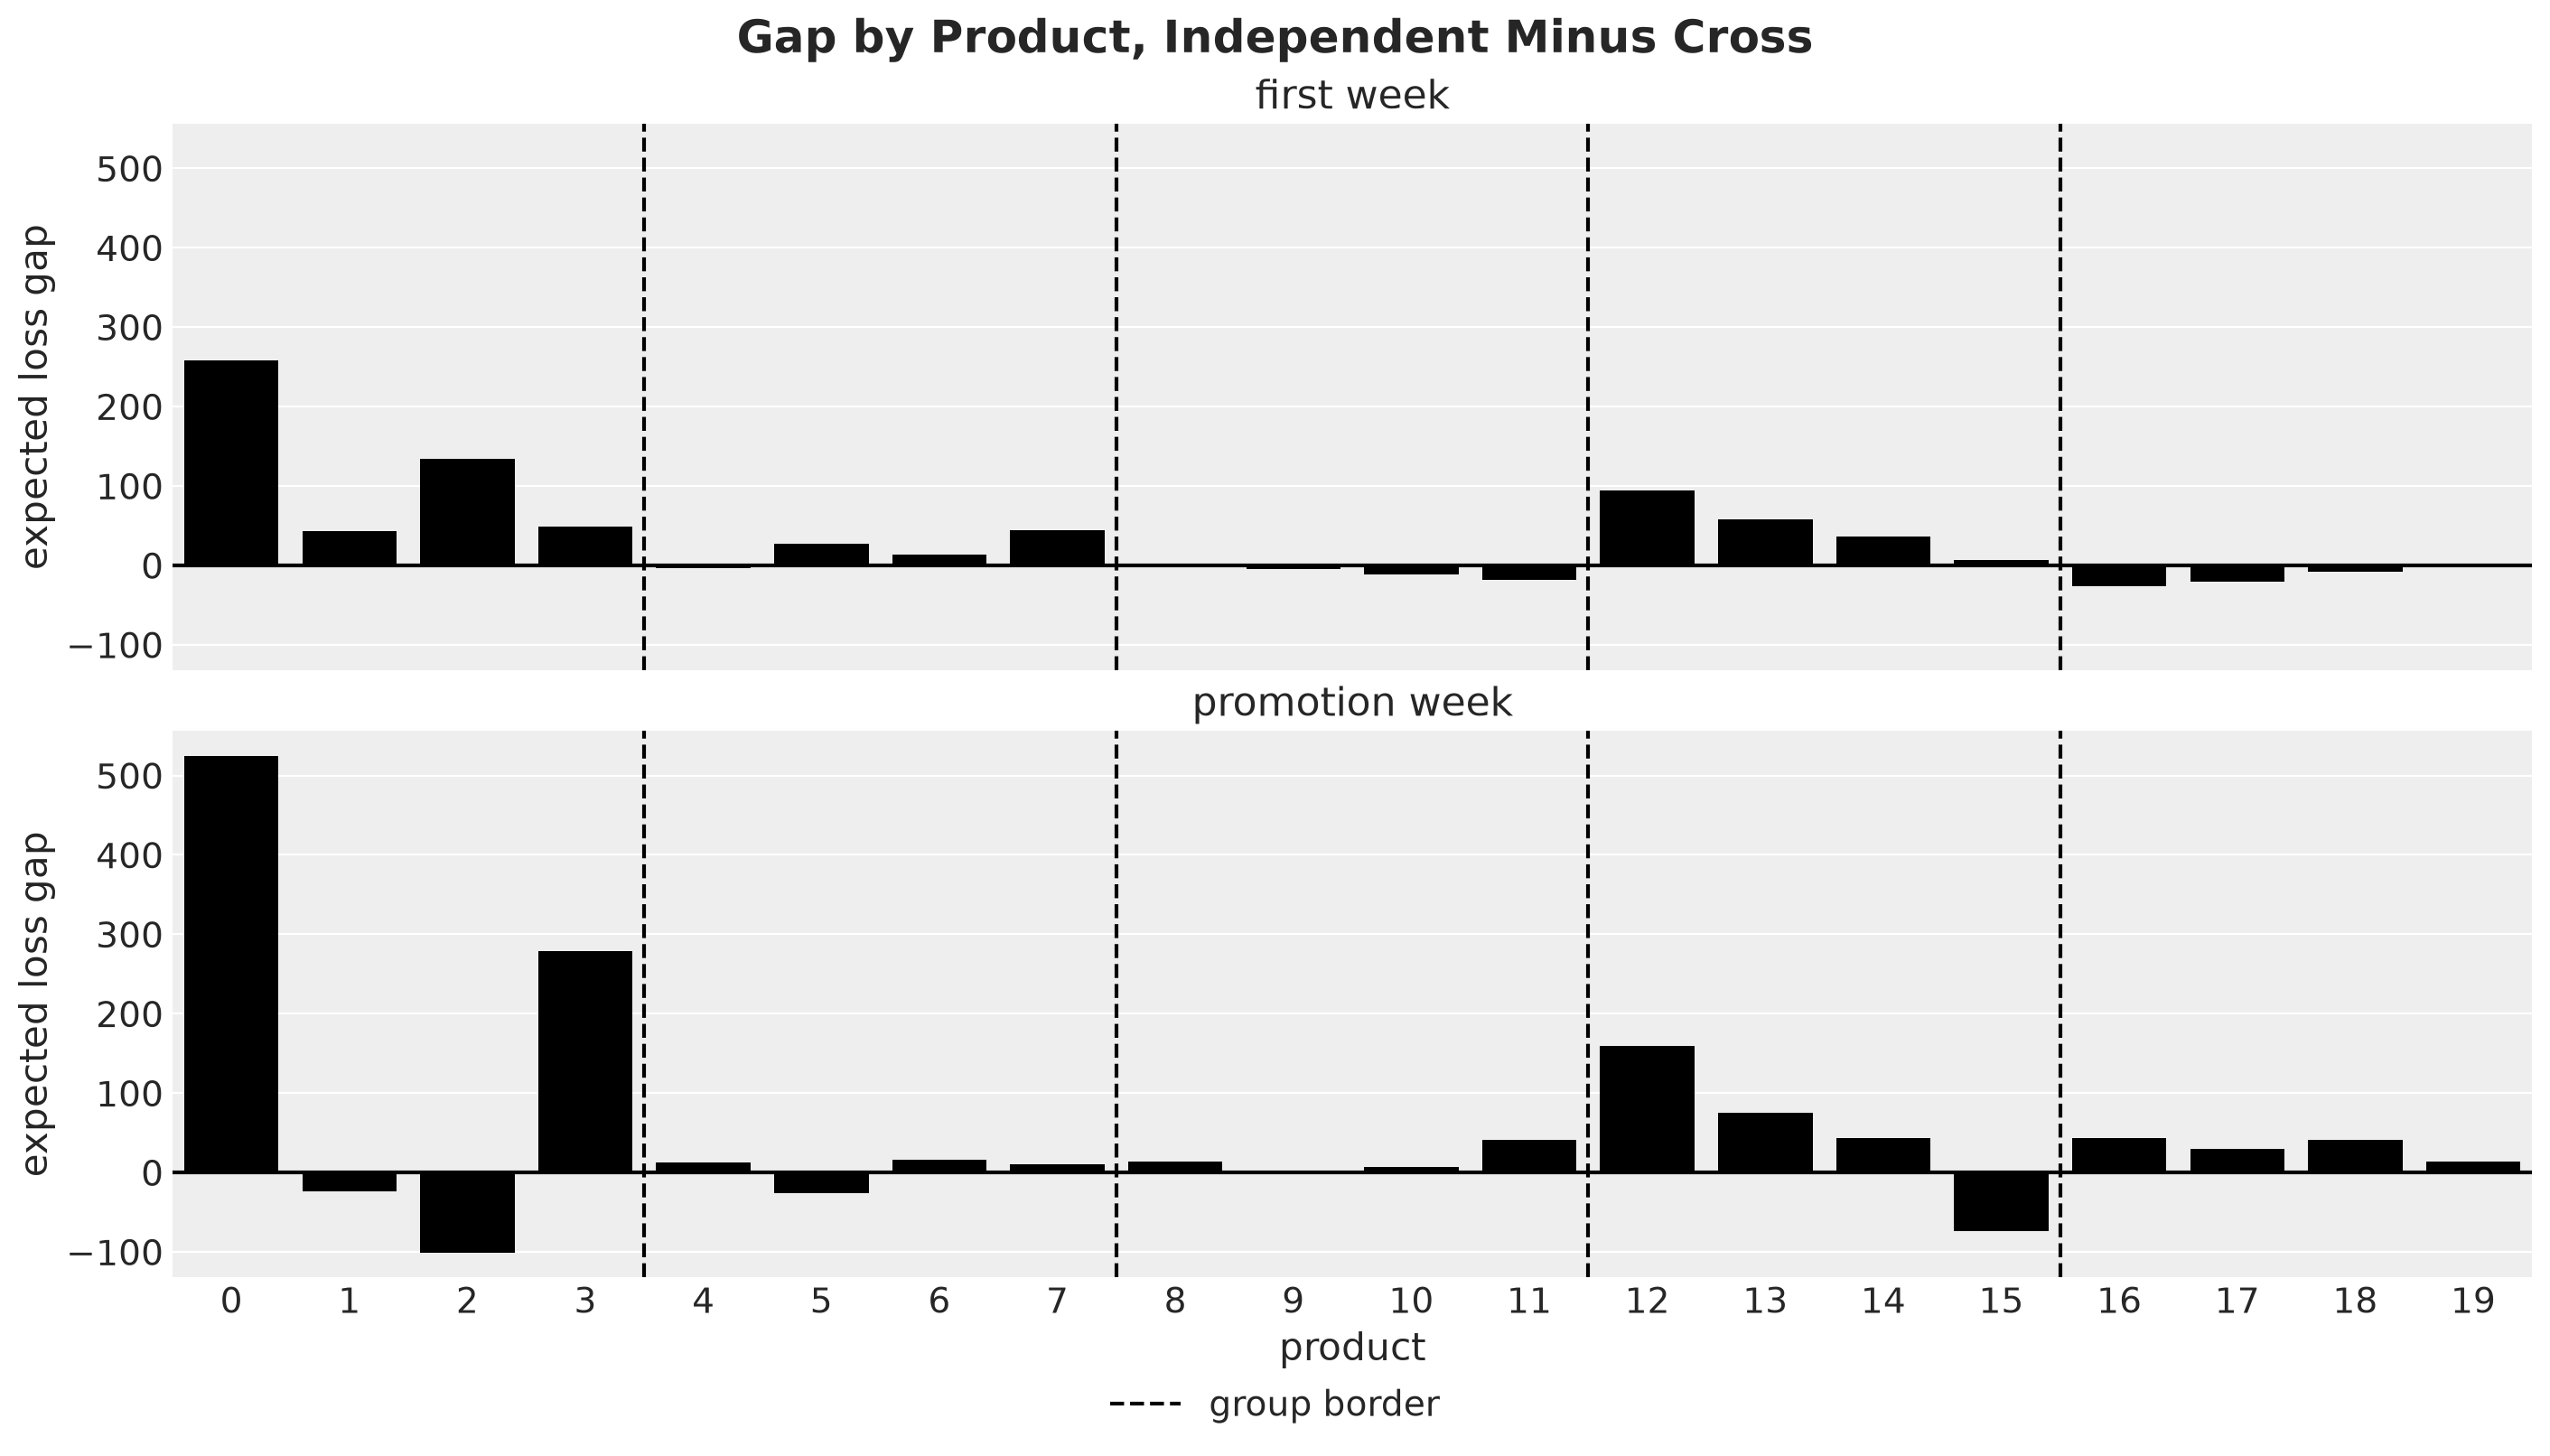

In [65]:
gap_by_product = (
    gap_long.group_by("product", "period").agg(pl.col("gap").sum()).sort("product")
)

fig, axes = plt.subplots(
    nrows=2, figsize=(14, 8), sharex=True, sharey=True, layout="constrained"
)

for ax, period in zip(axes, [Period.FIRST_WEEK, Period.PROMOTION_WEEK], strict=True):
    sns.barplot(
        data=gap_by_product.filter(pl.col("period") == period.value),
        x="product",
        y="gap",
        color="black",
        ax=ax,
    )
    ax.axhline(0.0, color="black")

    for group in range(1, setup.n_groups):
        ax.axvline(
            group * setup.n_per_group - 0.5,
            color="black",
            linestyle="--",
            label="group border" if group == 1 else None,
        )

    ax.set(title=period, xlabel="", ylabel="expected loss gap")

axes[-1].set(xlabel="product")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center")
fig.suptitle("Gap by Product, Independent Minus Cross", fontsize=18, fontweight="bold");

The two periods single out different products.

- **First week.** Products $0$, $1$ and $2$ account for $437$ of the $669$, with about $260$, $45$ and $135$. These are the three products whose forecast starts low after the promotion of product $3$ in the last week of the history. Products $12$ and $13$ of group $4$ add about $95$ and $60$, and the products of groups $3$ and $5$ have small negative gaps.
- **Promotion week.** The promoted product $0$ has the largest gap, about $525$, and the sibling product $3$ the second largest, about $280$. The forecast of product $3$ started at the right level, so the independent plan stocks it for a demand that then dips by $19\%$. On products $1$ and $2$ the gap is negative. Their forecast started low, which offsets the dip that the independent model does not expect, so the two errors cancel.

The next figure splits the gap by role, cost part and period. The roles have $3$, $9$, $4$ and $4$ products, so we divide the gap of a role by its number of products.

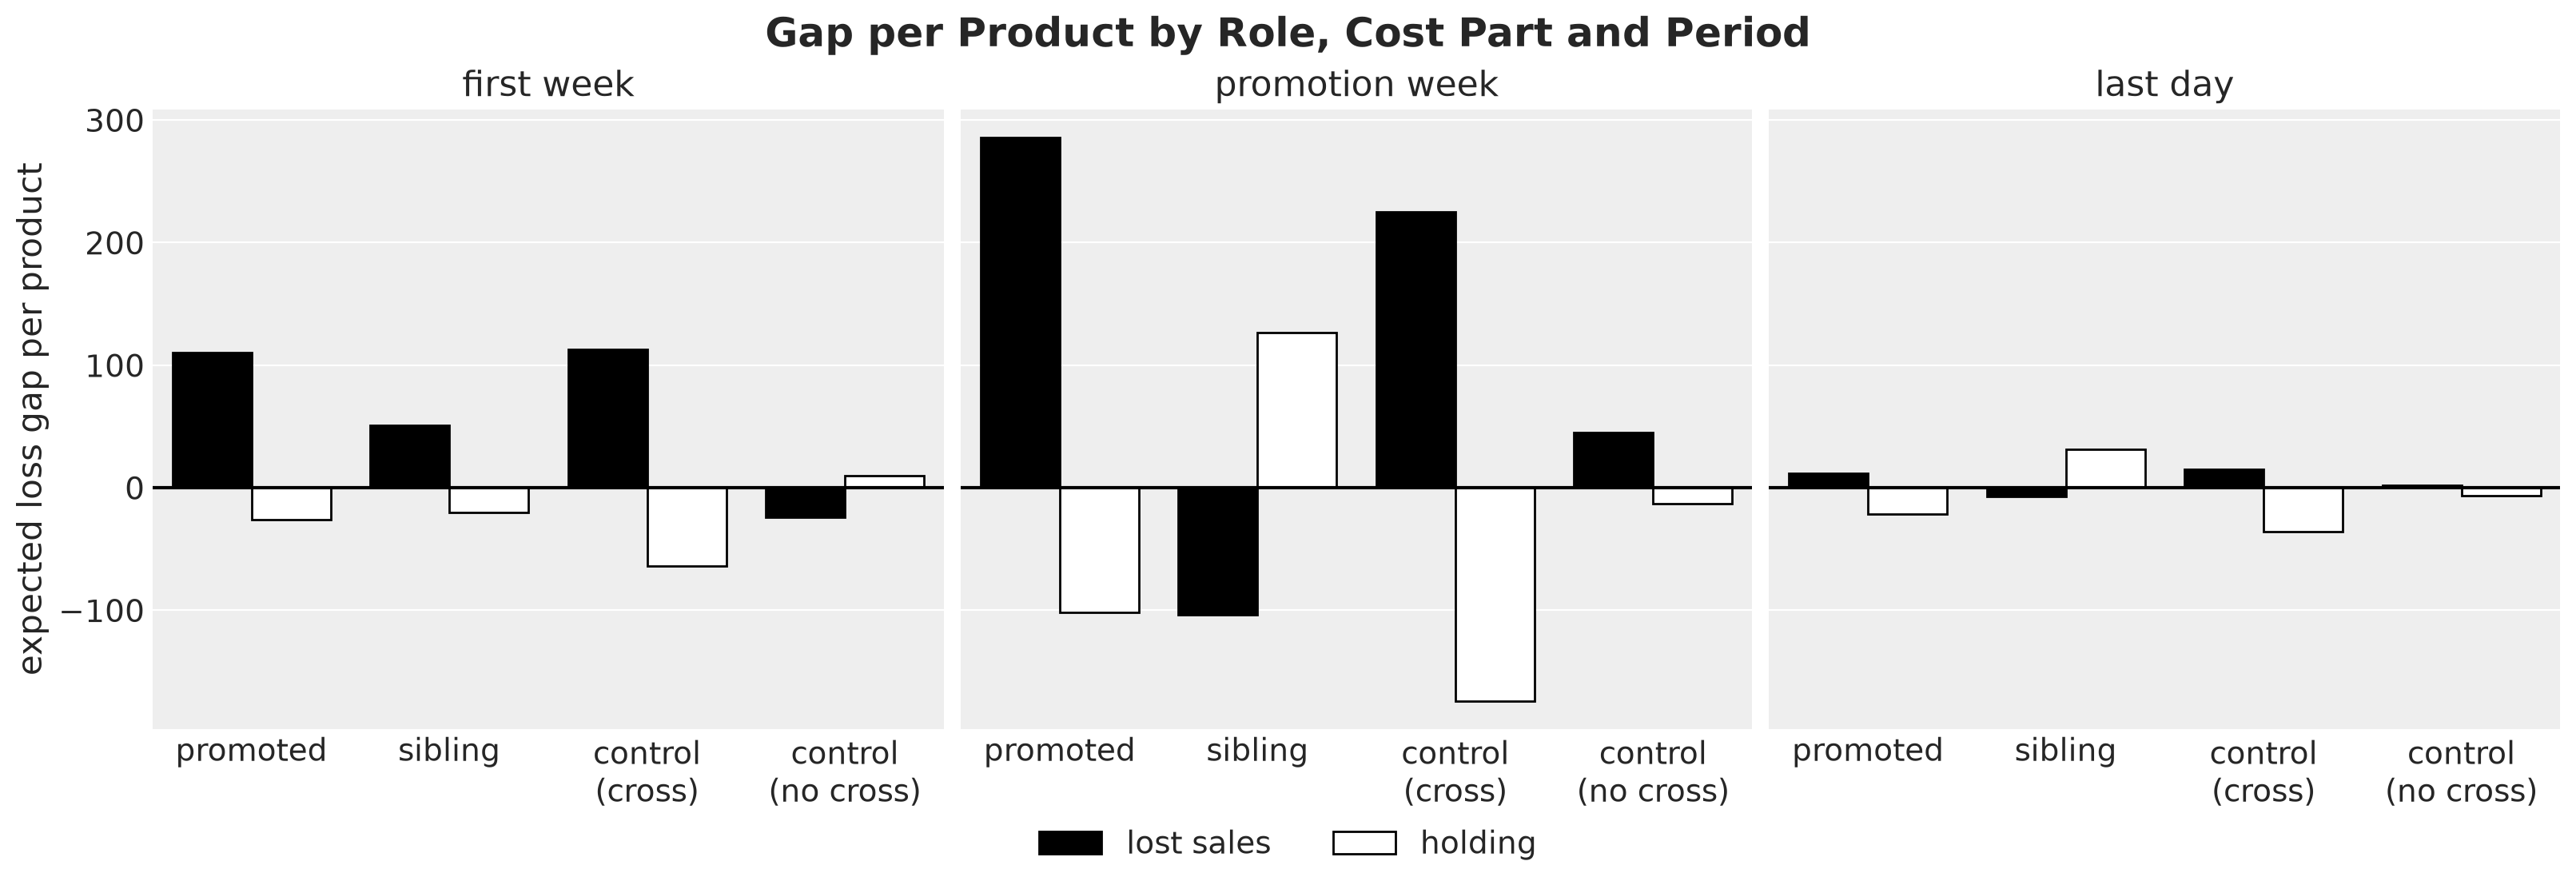

In [66]:
products_per_role = products.group_by("role").agg(n_products=pl.len())
gap_by_role = (
    gap_long.group_by("role", "period", "part")
    .agg(pl.col("gap").sum())
    .join(products_per_role, on="role")
    .with_columns(gap_per_product=pl.col("gap") / pl.col("n_products"))
)

fig, axes = plt.subplots(ncols=3, figsize=(16, 5.5), sharey=True, layout="constrained")

for ax, period in zip(axes, Period, strict=True):
    sns.barplot(
        data=gap_by_role.filter(pl.col("period") == period.value),
        x="role",
        y="gap_per_product",
        hue="part",
        order=[role.value for role in Role],
        hue_order=[Cost.LOST_SALES, Cost.HOLDING],
        palette={Cost.LOST_SALES: "black", Cost.HOLDING: "white"},
        edgecolor="black",
        ax=ax,
    )
    ax.axhline(0.0, color="black")
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
    ax.set_xticks(range(len(Role)), [role.replace(" (", "\n(") for role in Role])
    ax.set(title=period, xlabel="", ylabel="expected loss gap per product")

fig.legend(handles, labels, loc="outside lower center", ncol=2)
fig.suptitle(
    "Gap per Product by Role, Cost Part and Period", fontsize=18, fontweight="bold"
);

The sign of each part tells us what the independent plan does wrong in each period.

- **First week.** On the `promoted`, `sibling` and `control (cross)` roles the independent plan has more lost sales and less holding. With lost sales at $20$ times the holding cost, the lost sales cost more than the lower stock saves.
- **Promotion week.** On the siblings the signs flip, since the independent plan overstocks them. The promoted products have about $285$ more in lost sales per product, and the products of `control (cross)` about $225$.
- **Last day.** The parts are small and of both signs.

The control group with cross effects has no promotion in the horizon, but its forecast starts low, so it loses sales in the first week. It loses more in the promotion week, where the low start carries over and the capacity binds. We separate these two effects in the *Capacity Sensitivity* section.

Next, we look at the stockout probability per day under the two expected cost plans, averaged over the series of each role.

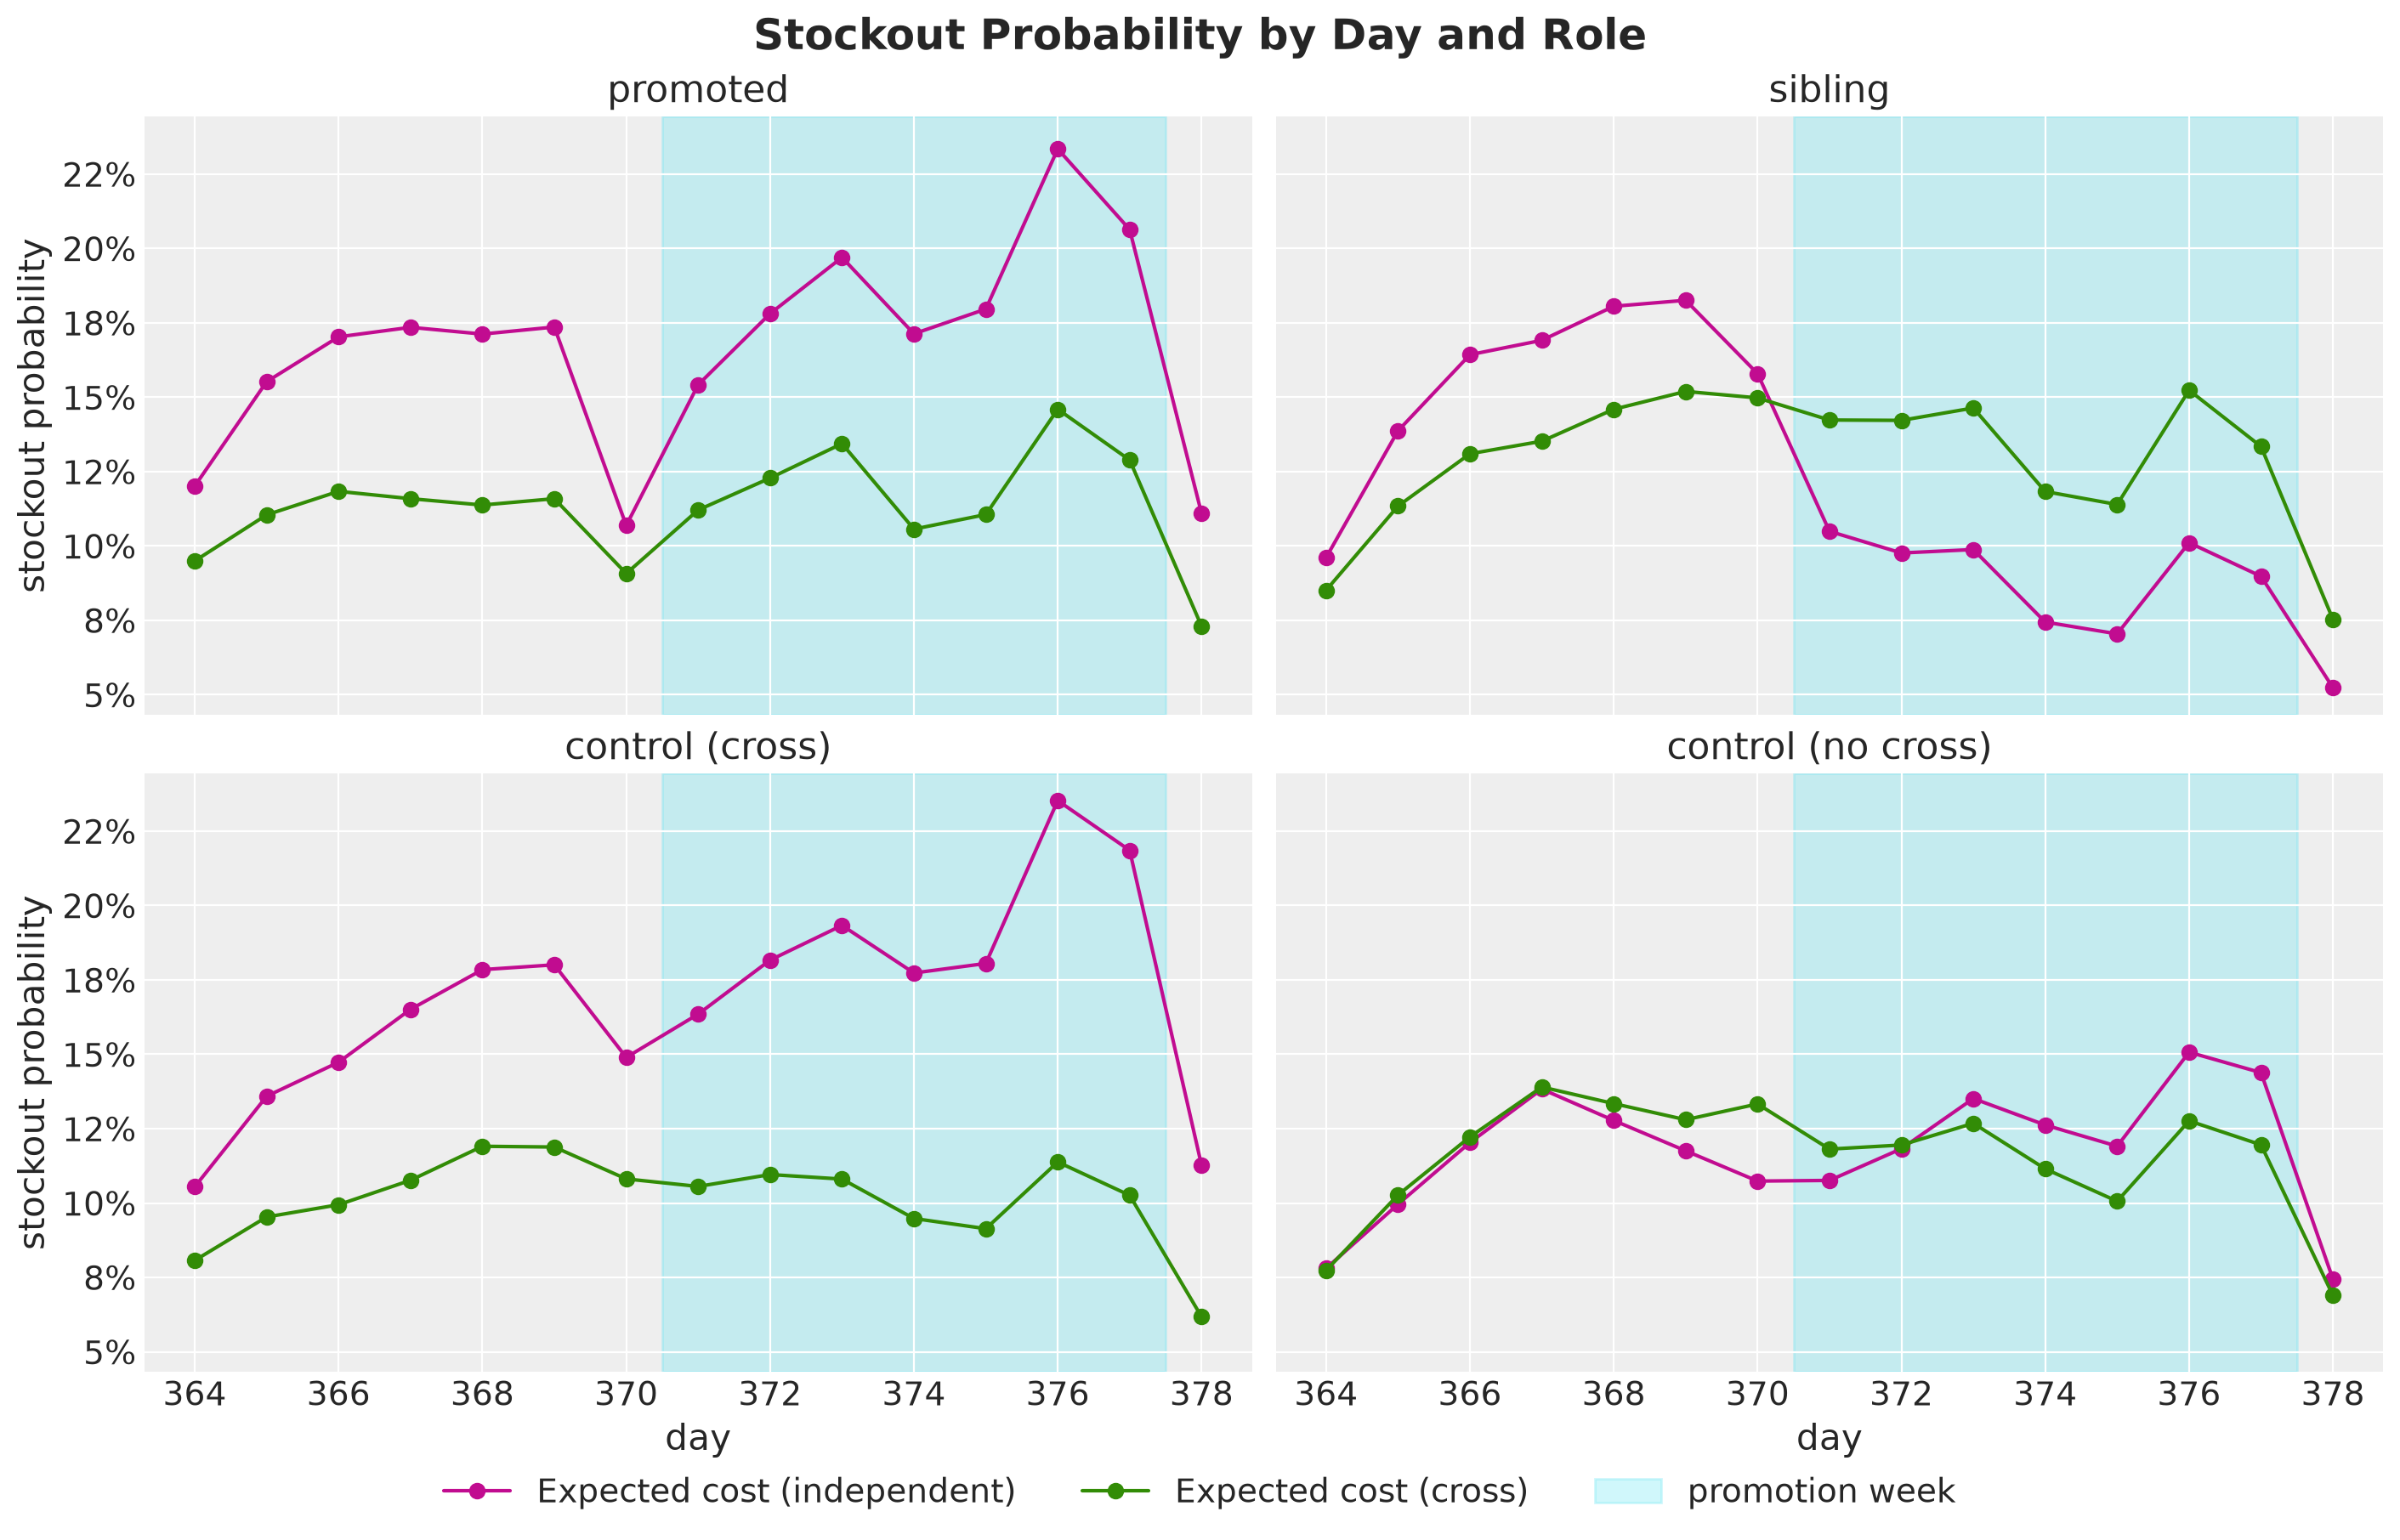

In [67]:
fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 9), sharex=True, sharey=True, layout="constrained"
)

for k, (ax, role) in enumerate(zip(axes.flat, Role, strict=True)):
    is_role_series = role_mask[role][panel.series_to_product]

    for model in models:
        key = (Rule.EXPECTED_COST, model)
        stockout_by_series = is_stockout(scores[key], solver.tol).mean(axis=0)
        ax.plot(
            days_future,
            stockout_by_series[is_role_series].mean(axis=0),
            "o-",
            color=MODEL_COLORS[model],
            label=plans[key].name,
        )

    shade_promotion_week(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(
        title=role,
        xlabel="day" if k >= 2 else "",
        ylabel="stockout probability" if k % 2 == 0 else "",
    )

fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Stockout Probability by Day and Role", fontsize=18, fontweight="bold");

The two plans differ on three roles and agree on `control (no cross)`.

- **`promoted`.** The independent plan runs out more often than the cross plan on every day, with the largest difference in the promotion week.
- **`sibling`.** The independent plan runs out more in the first week and less in the promotion week, where it is overstocked.
- **`control (cross)`.** The independent plan runs out more on every day, up to about $24\%$ of the series in the promotion week against about $11\%$ for the cross plan.
- **`control (no cross)`.** The two plans agree within a few points on every day.

Both plans run out less on the day before the promotion week, where they build stock.

So on this panel the cost of ignoring cannibalization comes from the forecast in two ways. The independent model starts the horizon too low on the products whose siblings were just on promotion, and its plan loses sales from the first day. In the promotion week its plan overstocks the siblings, and under a capacity that binds the promoted products get fewer units.

## Capacity Sensitivity

We have seen the gap between the two expected cost plans at one capacity multiple. Here we check whether the capacity creates the gap or only changes it.

Recall that the capacity of store $s$ is $C_s = \kappa \, R_s$. We sweep the capacity multiple $\kappa$ from $0.9$, where the capacity binds on a regular day, to no capacity at all, and solve the expected cost plan of both models at every value. Every value of $\kappa$ scales the whole capacity vector, so the stores keep their proportions.

In the code, `capacity_grid` holds one capacity vector per value of $\kappa$.

We score every plan on the evaluation scenarios and split the gap as in the previous section.

In [68]:
%%time

kappas = [0.9, 1.0, 1.05, 1.1, 1.25, 1.5, float("inf")]
capacity_grid = jnp.array(kappas)[:, None] * regular_throughput[None, :]
# the mean forecast plan depends on the capacity through the projection, so the
# sweep rebuilds it at every capacity and starts each solve from it
mean_plan_sweep = jax.vmap(forward_pass_capacity, in_axes=(None, 0, None))
solve_sweep = jax.jit(
    jax.vmap(
        partial(solve, config=config, solver=solver), in_axes=(None, None, 0, 0, None)
    )
)

orders_sweep = {}

for model in models:
    orders_sweep[model], _ = solve_sweep(
        draws[model].scenarios,
        0.0,
        mean_plan_sweep(
            unflat(mean_demand[model]), capacity_grid, initial_inventory_by_store
        ),
        capacity_grid,
        initial_inventory,
    )
    # at the largest finite multiple the capacity no longer binds
    assert jnp.allclose(orders_sweep[model][-2], orders_sweep[model][-1], atol=1e-3)

sweep_loss, gap_frames = [], []

for k, kappa in enumerate(kappas):
    sims = {
        model: simulate_scenarios(
            flat(orders_sweep[model][k]), demand_eval, initial_inventory, config
        )
        for model in models
    }
    sweep_loss.append(
        {
            "kappa": kappa,
            **{
                f"expected loss ({model})": float(sims[model].loss.sum(axis=-1).mean())
                for model in models
            },
        }
    )
    gap_frames.append(
        gap_frame(sims[Model.INDEPENDENT], sims[Model.CROSS])
        .group_by("role", "period", "part")
        .agg(pl.col("gap").sum())
        .with_columns(kappa=pl.lit(kappa))
    )

sweep_gap = pl.concat(gap_frames)
sweep = (
    pl.DataFrame(sweep_loss)
    .join(
        sweep_gap.group_by("kappa", "part")
        .agg(pl.col("gap").sum())
        .pivot(on="part", index="kappa", values="gap")
        .select("kappa", pl.col([cost.value for cost in Cost]).name.suffix(" gap")),
        on="kappa",
    )
    .with_columns(gap=pl.col(f"{Cost.HOLDING} gap") + pl.col(f"{Cost.LOST_SALES} gap"))
    .sort("kappa")
)
round_losses(sweep, sweep.columns[1:]).with_columns(
    (sweep["gap"] / sweep[f"expected loss ({Model.CROSS})"]).alias("relative gap")
)

CPU times: user 2min 15s, sys: 5.86 s, total: 2min 21s
Wall time: 39.6 s


kappa,expected loss (independent),expected loss (cross),holding gap,lost sales gap,gap,relative gap
f64,i64,i64,i64,i64,i64,f64
0.900,44940,42491,394,2055,2449,0.058
1.000,33118,31094,-216,2240,2024,0.065
1.050,31660,29813,-339,2186,1847,0.062
1.100,31361,29606,-125,1881,1755,0.059
1.250,31327,29580,-30,1777,1746,0.059
1.500,31327,29580,-30,1777,1746,0.059
inf,31327,29580,-30,1777,1746,0.059


We plot the expected loss of both plans and the gap, split into its two parts, against $\kappa$. The figure shows the finite values of $\kappa$, and the plans at $\kappa = 1.5$ are the plans without a capacity.

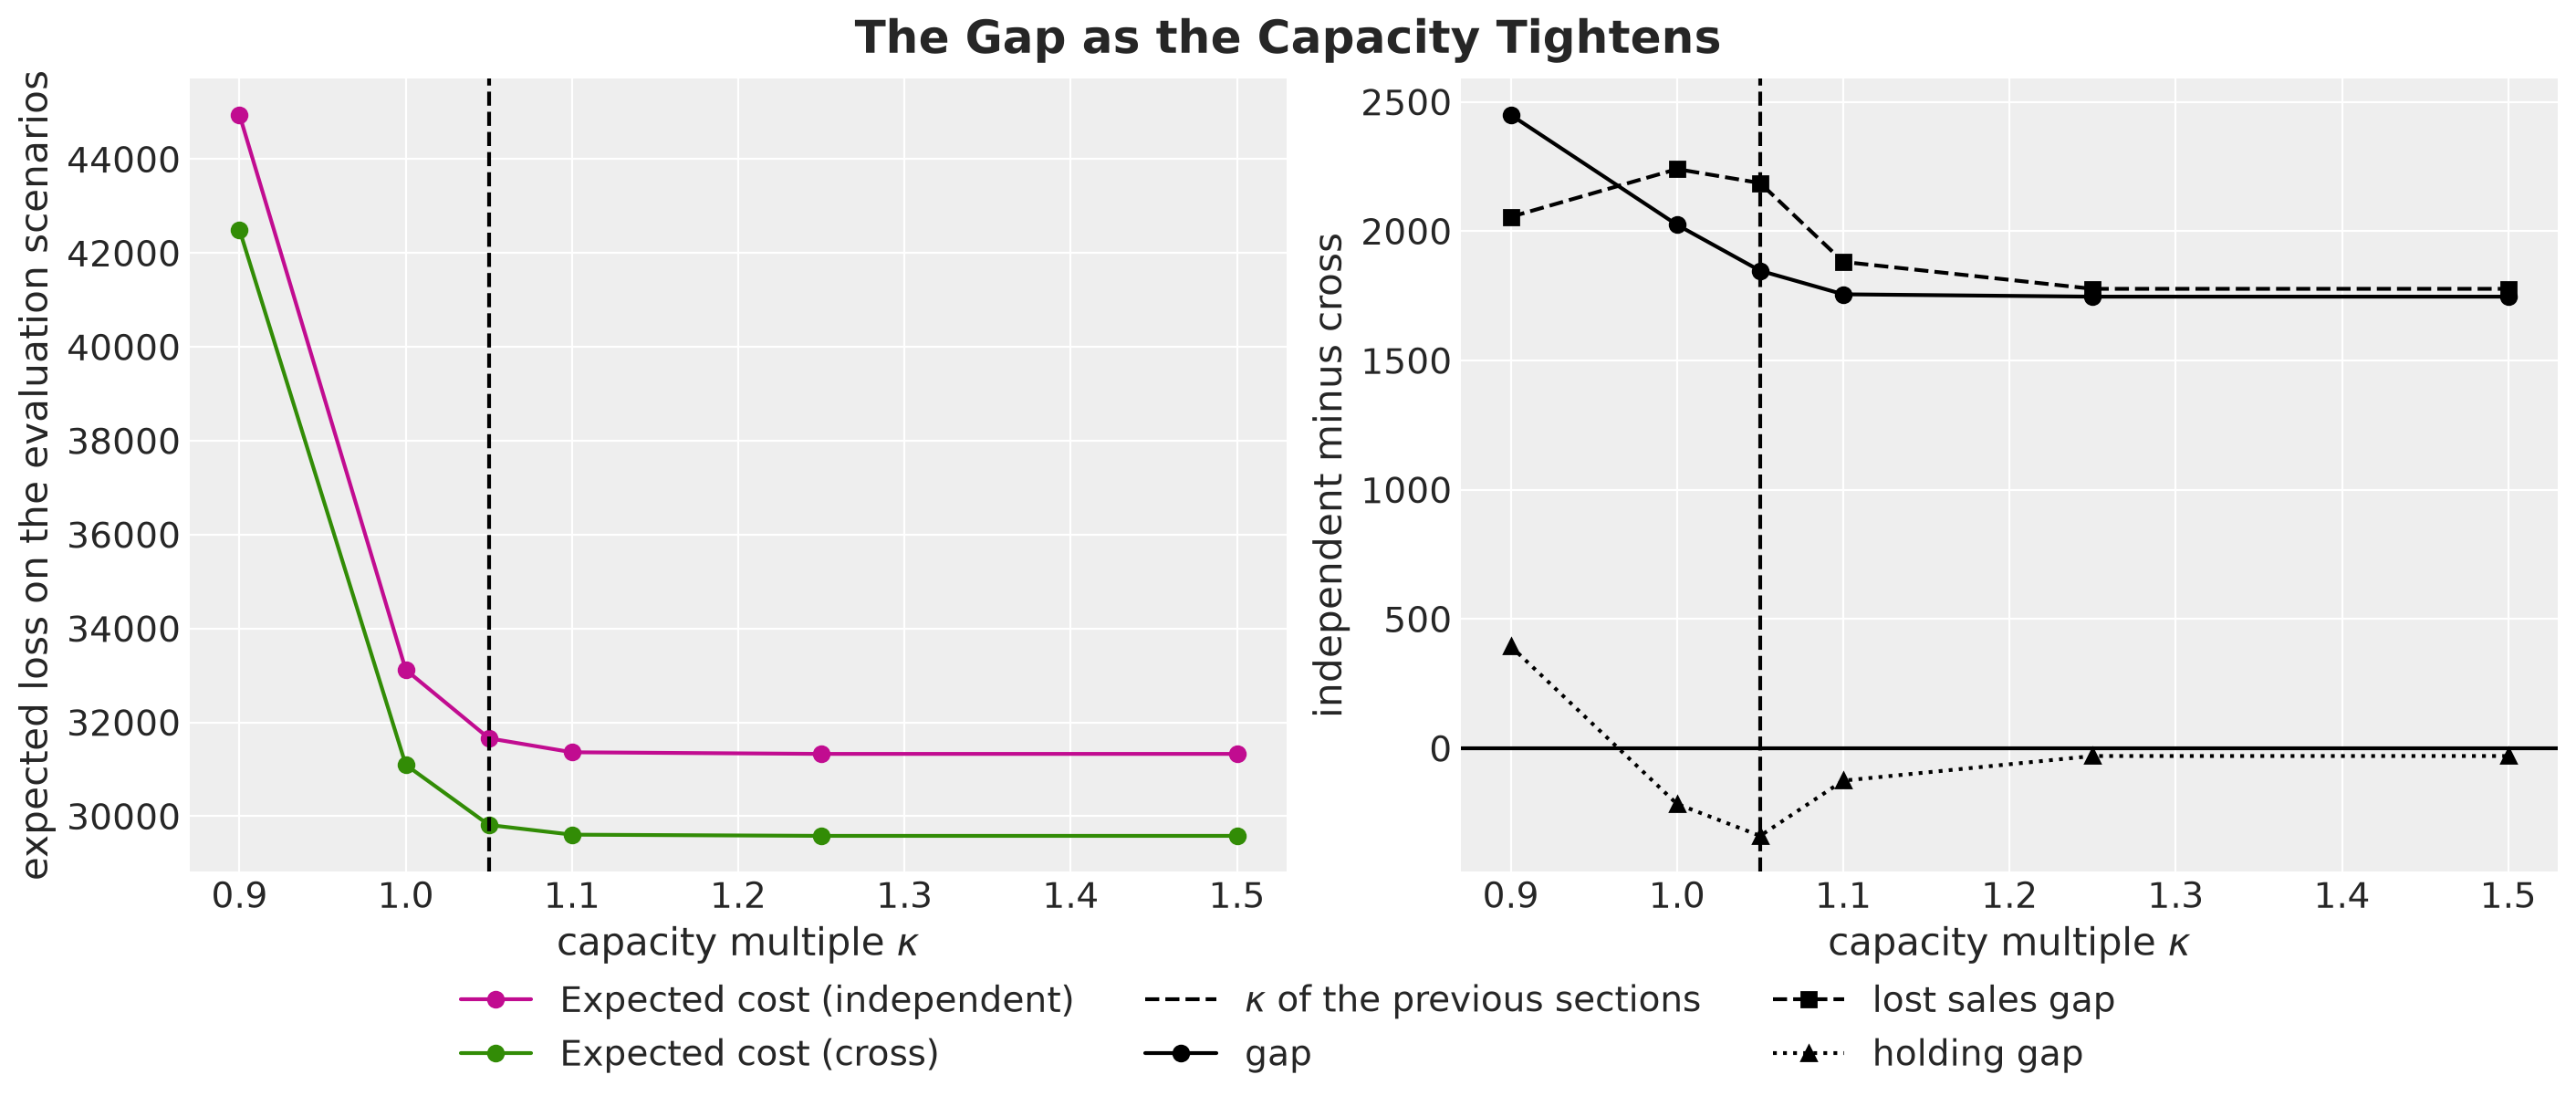

In [69]:
finite = sweep.filter(pl.col("kappa").is_finite())

fig, axes = plt.subplots(ncols=2, figsize=(14, 6), layout="constrained")
ax = axes[0]

for model in models:
    ax.plot(
        finite["kappa"],
        finite[f"expected loss ({model})"],
        "o-",
        color=MODEL_COLORS[model],
        label=plans[Rule.EXPECTED_COST, model].name,
    )

ax.axvline(
    planning.capacity_multiple,
    color="black",
    linestyle="--",
    label=r"$\kappa$ of the previous sections",
)
ax.set(ylabel="expected loss on the evaluation scenarios")
ax = axes[1]

for column, style in [("gap", "o-"), ("lost sales gap", "s--"), ("holding gap", "^:")]:
    ax.plot(finite["kappa"], finite[column], style, color="black", label=column)

ax.axhline(0.0, color="black")
ax.axvline(planning.capacity_multiple, color="black", linestyle="--")
ax.set(ylabel="independent minus cross")

for ax in axes:
    ax.set(xlabel=r"capacity multiple $\kappa$")

fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("The Gap as the Capacity Tightens", fontsize=18, fontweight="bold");

The gap is there at every capacity multiple.

- **Without a capacity.** The gap is $1{,}746$, or $5.9\%$ of the cross plan's loss, with $1{,}777$ more in lost sales under the independent plan and $30$ less in holding.
- **At $\kappa = 1.05$.** The gap is $1{,}847$, or $6.2\%$, with $2{,}186$ more in lost sales and $339$ less in holding.
- **At $\kappa = 0.9$.** Both plans lose sales on a regular day and both losses rise by about $42\%$. The gap is $2{,}449$, or $5.8\%$ of the cross plan's loss.

To separate the low start from the capacity in the promotion week, the next table compares the lost sales part of the gap in that week, by role, at $\kappa = 1.05$ and without a capacity.

In [70]:
capacity_labels = {
    planning.capacity_multiple: f"at kappa = {planning.capacity_multiple:g}",
    float("inf"): "without a capacity",
}
round_losses(
    sweep_gap.filter(
        (pl.col("period") == Period.PROMOTION_WEEK.value)
        & (pl.col("part") == Cost.LOST_SALES.value)
        & pl.col("kappa").is_in(list(capacity_labels))
    )
    .with_columns(
        capacity=pl.col("kappa").replace_strict(capacity_labels, return_dtype=pl.String)
    )
    .sort("kappa")
    .pivot(on="capacity", index="role", values="gap")
    .sort(pl.col("role").cast(pl.Enum([role.value for role in Role]))),
    list(capacity_labels.values()),
)

role,at kappa = 1.05,without a capacity
str,i64,i64
"""promoted""",857,527
"""sibling""",-935,-1014
"""control (cross)""",901,661
"""control (no cross)""",181,-13


Without a capacity the promoted products still have $527$ of the $857$ in extra lost sales, and `control (cross)` has $661$ of the $901$. The larger part of the lost sales gap of these two roles comes from the forecast, and the capacity adds the rest.

On `control (no cross)` the gap falls from $181$ to $-13$. The two models agree on this group, so its gap at $\kappa = 1.05$ comes from the shared capacity.

So on this panel the capacity changes the composition of the gap more than its size. Most of the gap is there without a capacity, and the capacity moves part of it between products.

## Integer Orders

So far every order is a real number, so the plans contain fractions of a unit. A store orders whole units. Here we round the four plans and check what the rounding costs.

We round one block at a time, so that the rounded orders of a store still fit its capacity:

1. **Round down.** Take the integer part of every order of the block.
2. **Fix the total.** Round the sum of the orders of the block to the nearest integer. If the result is above the capacity $C_s$, lower it to the integer part of $C_s$.
3. **Hand out the rest.** Give one more unit to the products with the largest fractional parts, until the block reaches that total.

Every order moves by less than one unit, and a block never exceeds the capacity of its store. The function `round_block` does these steps for one block, and `round_orders` applies it to every store and day. The assertions check the four rounded plans.

In [71]:
def round_block(
    a: Float[Array, " n_products"], capacity: ScalarLike
) -> Float[Array, " n_products"]:
    """Whole units for one block: round down, then hand out the units left."""
    whole = jnp.floor(a)
    # the total of the block in whole units, never above the capacity
    total = jnp.minimum(jnp.round(a.sum()), jnp.floor(capacity))
    # rank of the fractional parts, zero for the largest
    rank = jnp.argsort(jnp.argsort(whole - a))
    return whole + (rank < total - whole.sum())


# one day: the blocks of all stores, each with the capacity of its store
round_day = jax.vmap(round_block, in_axes=(0, 0))
# the whole horizon: the capacities are the same on every day
round_orders = jax.vmap(round_day, in_axes=(0, None))

plans_integer = {
    key: Plan(plan.rule, plan.model, round_orders(plan.orders, capacity))
    for key, plan in plans.items()
}

for key, plan in plans_integer.items():
    # whole units, non-negative and within the capacity of every store
    assert bool((plan.orders == jnp.round(plan.orders)).all())
    assert bool((plan.orders >= 0).all())
    assert bool((plan.orders.sum(axis=-1) <= capacity).all())
    # no order moves by a full unit
    assert bool((jnp.abs(plan.orders - plans[key].orders) < 1).all())

Next, we score the rounded plans on the evaluation scenarios and compare them with the plans of the previous sections.

In [72]:
def expected_loss(sim: Simulation) -> float:
    """Mean over the scenarios of the loss summed over the series."""
    return float(sim.loss.sum(axis=-1).mean())


scores_integer = {key: evaluate(plan) for key, plan in plans_integer.items()}
rounding = pl.DataFrame(
    [
        {
            "plan": plan.name,
            "expected loss": expected_loss(scores[key]),
            "expected loss (integer orders)": expected_loss(scores_integer[key]),
            "largest change of an order": float(
                jnp.abs(plans_integer[key].orders - plan.orders).max()
            ),
        }
        for key, plan in plans.items()
    ]
).with_columns(
    change=pl.col("expected loss (integer orders)") - pl.col("expected loss")
)
round_losses(rounding, ["expected loss", "expected loss (integer orders)"]).select(
    "plan",
    "expected loss",
    "expected loss (integer orders)",
    "change",
    (100 * rounding["change"] / rounding["expected loss"]).alias("change (%)"),
    "largest change of an order",
)

plan,expected loss,expected loss (integer orders),change,change (%),largest change of an order
str,i64,i64,f64,f64,f64
"""Mean forecast (independent)""",38005,38003,-2.598,-0.007,0.644
"""Mean forecast (cross)""",34788,34781,-7.359,-0.021,0.655
"""Expected cost (independent)""",31660,31672,12.785,0.040,0.923
"""Expected cost (cross)""",29813,29820,7.105,0.024,0.972


The rounding moves no order by a full unit. The largest change is $0.97$ units, in the expected cost plan of the cross model.

The expected loss of the two mean forecast plans falls by about $3$ and $7$, and the expected loss of the two expected cost plans rises by about $13$ and $7$. The largest relative change is $0.04\%$.

Finally, let's compare the gap between the two expected cost plans with continuous and with integer orders.

In [73]:
gap_rounding = []

for label, sims in [("continuous", scores), ("integer", scores_integer)]:
    loss_independent = expected_loss(sims[Rule.EXPECTED_COST, Model.INDEPENDENT])
    loss_cross = expected_loss(sims[Rule.EXPECTED_COST, Model.CROSS])
    gap = loss_independent - loss_cross
    gap_rounding.append(
        {"orders": label, "gap": gap, "gap / loss of the cross plan": gap / loss_cross}
    )

round_losses(pl.DataFrame(gap_rounding), ["gap"])

orders,gap,gap / loss of the cross plan
str,i64,f64
"""continuous""",1847,0.062
"""integer""",1852,0.062


The gap is $1{,}852$ with integer orders against $1{,}847$ with continuous orders, and it is $6.2\%$ of the loss of the cross plan in both cases. So on this panel the results do not depend on the fractions.

Here are two important remarks. First, we round after the solve, so the rounded plan is close to the continuous plan but it is not necessarily the best plan in whole units. Second, the products of this panel sell tens of units per day, so one unit is a small part of an order. With products that sell a few units per day the rounding would cost more, and it would be better to solve the plan in whole units.

## Conclusion

### Key Findings

These findings come from one panel and one seed.

- **Cost of ignoring cannibalization.** On the evaluation scenarios the independent plan costs $6\%$ more than the cross plan. The cross plan is cheaper in every scenario of this history.
- **Decision rule.** The mean forecast plans cost $20\%$ and $17\%$ more than the expected cost plans of the same model. On this panel the decision rule matters more than the model.
- **Groups.** Group $1$, with the largest cross elasticity and a sibling promotion in the last week of the history, accounts for $71\%$ of the gap. The two groups with a cross elasticity of $0.3$ account for $8\%$ and $17\%$, and the two groups without cannibalization for $1\%$ and $3\%$.
- **Start of the forecast.** The level of the independent model is lower on the products whose siblings were on promotion in the last weeks of the history, more so where the cross elasticity is larger. On the other products the two models start at about the same level. Three products with a low start account for $65\%$ of the gap of the first week.
- **Promotion week.** The independent plan overstocks the siblings, whose demand dips by $10\%$ to $19\%$, and the promoted products lose more sales. Among the siblings the gap is the largest on the one whose forecast started at the right level, and the two errors cancel on the siblings that started low.
- **Capacity.** The gap is $5.9\%$ without a capacity and $6.2\%$ at $\kappa = 1.05$. The capacity moves part of the gap between products more than it changes its size.
- **Integer orders.** Rounding the orders to whole units changes the expected loss of every plan by at most $0.04\%$, and the gap between the two expected cost plans stays at $6.2\%$.
- **Calibration metrics.** The CRPS of the two models differ by $3\%$ and both cover the realized future at $93\%$, while their plans differ by $6\%$ in cost.
- **Groups without cannibalization.** Their gap is $23$ and $52$ of a total of $1{,}847$. It arises in the promotion week, where these groups share the capacity with the others.
- **Variational inference.** The full-rank part of the guide gives `cross_scale` an interval that covers the truth. The mean-field part covers the true level at the end of the history for only about $60\%$ of the series, and the expected cost plans cost $14\%$ to $16\%$ more on the evaluation scenarios than on their own scenarios.

### Model Limitations

- **Mean-field level.** The guide is mean-field on the level and on the drift scale. Its intervals cover the true level at the end of the history for about $60\%$ of the series and the drift scale for about half of the series. The plans keep their order, but they cost more on the evaluation scenarios than on their own scenarios. On real data we would compare the guide with NUTS on a subset of the series.
- **Independent series.** The levels and the noise of the series are independent in the generator, with no shock common to a store or to the chain. The tail of the total loss is thin for that reason. A tail weight lowers the tail by about $2\%$ on the scenarios of the model and not at all on the evaluation scenarios. Real demand has common shocks, such as weather and holidays.
- **No cross-period effects.** A promotion in the generator lifts the demand of its own week and leaves the following weeks untouched. [van Heerde, Leeflang and Wittink (2004)](https://doi.org/10.1287/mksc.1040.0061) attribute about a third of the promotion bump to demand borrowed from other periods. A dip after a promotion would matter for a plan that starts right after a promotion week.
- **Synthetic truth.** The checks against the true parameters, the true level and the evaluation scenarios exist only because we simulated the data. On real data we would rely on backtests that start the forecast on several days.
- **One promotion pattern.** The promotions are chain-wide (a product is on promotion in every store at once), and the cross elasticities are constant within a group and over time. Store-specific promotions and elasticities that change with the depth of the cut or the display support would need their own terms.
- **No recourse, no lead time.** All orders are fixed today and arrive on the day we planned them for. A rolling horizon that re-forecasts and re-solves every day would see the low start and the dip of the siblings after a few days of sales. A lead time would move the decision to the stock projected at the delivery date.
- **Unconstrained demand history.** The models see the demand itself. In a real lost-sales setting the history is sales, which are censored on the days the shelf was empty, and the dips of a sibling promotion would mix with the dips of an empty shelf.
- **Cost assumptions.** A lost sale costs the same margin on every product and day, and leftovers keep their value.
- **Continuous orders.** The solver works with real orders, and we round them only after the solve. The rounded plan is not necessarily the best plan in whole units, and on products that sell a few units per day the difference could matter.
- **One panel.** The numbers come from one panel, one promotion calendar and one seed. The size of the gap depends on where the last promotions of the history fall, and how tight $\kappa = 1.05$ is depends on which products are promoted.
- **One capacity multiple.** Every store has its own capacity, but all capacities are the same multiple of the regular throughput of their store. So no store is much tighter than the others, with a load between $94\%$ and $100\%$ in the promotion week. The projection and the solver take any positive capacity vector, but we did not study a chain with a few much tighter stores.

### Recommendations

1. **Model the siblings when you plan a promotion.** The cross-price term is one matrix of shrunk coefficients, and the data identify it from the weeks in which a sibling was on promotion. Without it the plan loses sales before the promotion, on the products whose siblings were just promoted. During the promotion it overstocks the siblings.
2. **Look at the promotion calendar of the last weeks.** If a sibling of a product was on promotion just before the last day of the history, a model without cross effects can start that product low. A backtest that starts right after a sibling promotion shows whether it does.
3. **Keep a control group.** A group that the model change should not affect is a check of the comparison. Compare its forecasts under the two models, and compare its plans without the shared capacity, since the capacity links it to the other groups.
4. **Report how tight the capacity is.** The same forecast error costs holding when the capacity is slack and lost sales on other products when it binds. Report, for every store, the mean demand as a share of its capacity in the promotion week.

## Next Steps

1. **Promotion choice.** Make the discount, the week and the products of the promotion decisions, with the cannibalization in the objective.
2. **Store-specific elasticities.** Let the own and cross elasticities vary by store around a product-level mean, with partial pooling, so that stores with a different mix of customers get their own promotion response.
3. **Lead time and rolling horizon.** Add a pipeline of in-transit orders to the carry of the simulator and wrap the solve in `numpyro_forecast.backtest`, so that each window re-forecasts, re-solves and commits one order. Several starting days would also average over the promotion calendar of the last weeks.
4. **Censored sales.** Replace the demand history by a sales history with a censored likelihood on the days with an empty shelf, as in the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast`.
5. **A full-rank guide on the level.** Keep the mean-field guide on the $72{,}800$ increments and extend the full-rank block from the price effects to the level of every series at the end of the history. Then measure how much of the difference between the loss on the own scenarios and the loss on the evaluation scenarios goes away.
6. **Common shocks.** Add a shock common to the series of a store to the generator and to the model, and check whether the tail weight and the joint draws across series start to matter.
7. **Costs per product.** Give every product its own lost margin and its own holding cost in the loss. The projection does not change, because the capacity counts units. Then check which products the plan favors when the capacity binds.

## References

- Orduz, J. (2026). [From Forecasts to Decisions: Inventory Planning with Probabilistic Programming](https://juanitorduz.github.io/forecast_to_decision/). Personal blog.
- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- van Heerde, H. J., Leeflang, P. S. H. and Wittink, D. R. (2004). [Decomposing the Sales Promotion Bump with Store Data](https://doi.org/10.1287/mksc.1040.0061). *Marketing Science*, 23(3), 317-334.
- Duchi, J., Shalev-Shwartz, S., Singer, Y. and Chandra, T. (2008). [Efficient Projections onto the $\ell_1$-Ball for Learning in High Dimensions](https://doi.org/10.1145/1390156.1390191). *Proceedings of the 25th International Conference on Machine Learning*, 272-279.
- Blei, D. M., Kucukelbir, A. and McAuliffe, J. D. (2017). [Variational Inference: A Review for Statisticians](https://doi.org/10.1080/01621459.2017.1285773). *Journal of the American Statistical Association*, 112(518), 859-877.
- Kingma, D. P. and Ba, J. (2015). [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980). *International Conference on Learning Representations*.
- Shapiro, A., Dentcheva, D. and Ruszczyński, A. (2021). [Lectures on Stochastic Programming: Modeling and Theory](https://doi.org/10.1137/1.9781611976595), third edition. SIAM.
- Pyro developers. [Forecasting with `pyro.contrib.forecast`](https://docs.pyro.ai/en/stable/contrib.forecast.html), the module whose `time_reparam` option `numpyro_forecast` ports.
- NumPyro developers. [Automatic Guide Generation](https://num.pyro.ai/en/stable/autoguide.html), the documentation of `AutoGuideList` and the other automatic guides.
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- Orduz, J. [PyData Berlin 2025: Introduction to Stochastic Variational Inference with NumPyro](https://juanitorduz.github.io/intro_svi/). Personal blog.
- PreliZ developers. [PreliZ documentation](https://preliz.readthedocs.io/).
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).